# Multi-task brain-tumour classification and segmentation on BRISC 2025: a contamination-controlled evaluation

**Objective.** Measure how well one multi-task network (ResNet-50 encoder, U-Net decoder, classification head) classifies four classes and segments tumours on BRISC 2025 when no test image, and no copy or same-patient slice of it, is seen during training; measure how much such contamination inflates the scores; and test, under this protocol, whether conditioning the network on the MRI plane (FiLM) helps and whether doing both tasks in one network helps.

*Version 2 (10 Oct 2026). Version 1 answered Q1-Q3 with 24 finished runs. This version keeps those runs unchanged (same configuration signatures: Cell 11 restores them, it does not retrain them), adds the round-2 questions and analyses below, and ends with a cell that packs every number the manuscript needs into one zip.*

*Version 2.1 (11 Oct 2026). The first full run of version 2 finished on 10 Oct 2026 (all 43 runs, every cell clean). Version 2.1 corrects the count of round-2 runs in the text (19, not 22) and adds Cell 26, a follow-up check of two findings of that run (twins missed by the brain-cropped search; BRISC masks that disagree with the figshare masks). Running it again trains nothing.*

*Version 3 (12 Oct 2026). Rounds 1-2 and the follow-up cells are unchanged (Cell 11 restores every finished run; nothing is retrained). Cell 27 (every Dice result against the figshare annotation, run on 11 Oct 2026) is now part of the notebook. Section H adds round 3, fixed before any round-3 run: the official manifest against the files (Cell 28); the earlier multi-task design re-implemented from its code and three standard baselines, trained on the contaminated and the decontaminated set (Cells 29-31, questions Q6-Q7); and tests of the explanations instead of displays (Cells 32-37, hypotheses H1-H4, descriptive H5-H7). Cell 38 prints the round-3 results table. Send back only this notebook with its outputs.*

## Pre-specified questions

### Round 1 (fixed 8 Oct 2026, before any training run of this notebook)

| | Question | Arms (Cell 11) | Cell |
|---|---|---|---|
| **Q1** | Performance of the usual recipe (all official training images) vs a decontaminated model (no training image linked to any test image), on the official 1,000-image test set | `full_flip`, `B_flip` | 14 |
| **Q2** | Within-image effect of having a test image's relatives in training, by kind of relative (near-identical copy, mirrored copy, same patient, near-duplicate). Randomised crossover: every contaminated group is assigned at random to one of two training sets, so each test image is exposed in one model and unexposed in the other. Negative control: test images with no relative in training | `X1_flip`, `X2_flip` | 15 |
| **Q2b** | Does horizontal-flip augmentation amplify the effect of **mirrored** copies (and not of plain copies)? | `X1_noflip`, `X2_noflip` | 15 |
| **Q3** | FiLM with the true plane vs no FiLM vs FiLM with a shuffled plane (a placebo with the same parameters), all on the decontaminated set | `B_flip`, `B_flip_film`, `B_flip_placebo` | 16 |

**Primary endpoints of round 1** (no correction for multiplicity; everything else is exploratory and labelled so): Q1, the difference in macro-F1 and in mean Dice; Q2, the exposure effect on Dice and on the log-probability of the true class for `copy_plain` and `copy_mirror`; Q2b, the flip x mirror interaction on Dice, i.e. (flip minus no-flip exposure effect for mirrored copies) minus (the same for plain copies); Q3, FiLM (true plane) minus placebo on macro-F1 and on Dice.

### Round 2 (fixed 10 Oct 2026, after the round-1 results and before any round-2 run)

| | Question | Arms (Cell 11) | Cell |
|---|---|---|---|
| **Q4** | Does training both tasks in one network help either task once contamination is removed? Multi-task vs segmentation-only (classification loss switched off) on Dice, and multi-task vs classification-only (segmentation loss switched off) on macro-F1, on the decontaminated set B. The same comparison on the Full set shows whether contamination changes the answer | `B_flip`, `B_flip_seg`, `B_flip_cls`; `full_flip`, `full_flip_seg`, `full_flip_cls` | 19 |
| **Q5** | Does contamination inflate the scores at a FIXED quantity of training data? Set `Fm` has the size and the class counts of set B but is drawn at random from the Full set, so it holds contaminated images in their natural share. `Fm_flip` vs `B_flip` | `Fm_flip`, `B_flip` | 20 |

**Primary endpoints of round 2:** Q4, `B_flip` minus `B_flip_seg` on mean Dice and `B_flip` minus `B_flip_cls` on macro-F1; Q5, `Fm_flip` minus `B_flip` on macro-F1 and on mean Dice; all on the official test set. Single-task arms choose their epoch on their own task (validation Dice, or validation macro-F1); multi-task arms keep the round-1 rule (the mean of the two). Every arm of one seed starts from the same weights.

**Robustness checks (round 2, fixed in advance, descriptive because each has one seed).** A replicate of `full_flip`, `B_flip`, `X1_flip` and `X2_flip` with seed 1337 (`*_rep`) that keeps the predictions of its last epoch as well as of its best epoch. It re-estimates Q1 and Q2 without validation-based model selection (the validation fold has 233 images, only 6 of them pituitary) and measures how much a retrained run differs from the round-1 run of the same seed (Cell 21). Every round-2 run keeps its last-epoch predictions.

**Not pre-specified, labelled exploratory in every output** (Cells 18 and 21-23): replication of two published duplicate screens on BRISC; threshold sensitivity of the contamination strata and the minimal detectable effect of the negative control; calibration, temperature scaling, 3-seed ensemble uncertainty, patient-level and cross-plane consistency, tumour-area error; a table of dataset errata for expert review.

**Decision rule** (all questions). An effect is *supported* when its 95% group-bootstrap interval excludes 0 **and** all three seeds agree in sign; otherwise *not supported*. Estimates and intervals are reported either way. Test images are not independent (copies, patients), so every interval resamples whole groups (Cell 6), never single images.

**Pilot runs.** Before round 1, pilot runs in an earlier notebook (validation fold only) shaped design choices such as the segmentation loss on tumour-free images and the training budget. They never used the official test set, and none of their numbers is reported.

## Background (sources checked on 8-10 Oct 2026)

- **BRISC 2025** ([Fateh et al., *Sci Data* 13:361, 2026](https://doi.org/10.1038/s41597-026-06753-y)): 6,000 contrast-enhanced T1 slices, 4 classes, 3 planes, expert masks for the 4,793 tumour images. It derives from Nickparvar's Kaggle collection (7,023 images), which aggregates figshare (Cheng et al.), SARTAJ and Br35H. The descriptor states that exact and near-duplicates were removed before the split, and that subject-level independence cannot be guaranteed.
- **The figshare source** ([Cheng, doi:10.6084/m9.figshare.1512427](https://figshare.com/articles/dataset/brain_tumor_dataset/1512427)): 3,064 slices of 233 patients (708 meningioma, 1,426 glioma, 930 pituitary), with a patient ID and a tumour mask for every slice.
- **Audit of the parent collection** ([Vangala et al., arXiv 2610.00421, 2026](https://arxiv.org/abs/2610.00421)): cross-split near-duplicates found with a whole-image NCC at 64x64 (no mirrored search described); removing them barely changed classification accuracy. Not BRISC, no segmentation.
- **Concurrent study on BRISC** ([Huang et al., *Front. Med.* 13, 2026](https://doi.org/10.3389/fmed.2026.1955863)): near-duplicate screen with SHA-256 and a 64-bit perceptual hash (same label and plane), and a size-matched replacement design on a multi-task network; no search for mirrored copies is described, and the authors state that patient-level independence could not be verified.
- **What this notebook adds**, as far as our searches found: flip-aware, pixel-verified duplicate detection on BRISC; tracing of BRISC images to source patients; a randomised crossover that measures the effect of contamination on segmentation and classification of the same test images, by kind of relative; a placebo-controlled test of plane conditioning; and (round 2) a contamination-controlled test of the multi-task design itself.

## How to run (Google Colab, GPU runtime, ideally a T4 or better)

1. **Cells 1-10**: download, audit, cache, figshare tracing (~880 MB download), splits, checks, model and loss tests. About 40-60 min the first time; much less when the pixel searches are found on Drive (`MyDrive/brisc_reuse`) or inside `results_bundle.zip`. Each cell ends with `CELL N CLEAN.`; stop and report any FAIL.
2. **Cell 11** restores the 24 finished round-1 runs (from `MyDrive/brisc_runs` when Drive is mounted, or from `results_bundle.zip` uploaded into `/content/brisc_work/`), checks that their signatures are unchanged, and trains the 19 round-2 runs: about 5 h on a T4 (it prints an estimate for your GPU). It stops *starting* runs before the session limit; in a new session run Cells 1-10 again, then Cell 11, until it prints `ALL RUNS DONE`. `MAX_PRIORITY` sets the scope: 4 = round 1 only, 5 = + Q5, 6 = + Q4, 7 = + the fixed-epoch replicate (default).
3. **Cells 12-23** analyse whatever has finished and name what is missing. **Cell 24 writes `paper_results.csv/json`: the only source of numbers for the manuscript. Cell 25 packs the manuscript package (zip) and downloads it.** **Cell 26** (follow-up, exploratory) adds its checks to that package and downloads it again.
4. Send back the executed notebook (File > Download > .ipynb) and the zip. Every result is printed in the cell outputs; nothing needs to be read from files to check it.

## Conventions

- One cell, one job. A markdown header before each code cell states its purpose, inputs, outputs and pass criteria.
- Each code cell asserts its prerequisites and ends with `[PASS]/[FAIL]` lines and `CELL N CLEAN.` Checks test the code and data integrity. `[NOTE]` lines are findings about the data and are never pass/fail.
- Constants sit at the top of each cell. Files carry the number of the cell that wrote them. No number in the text of this notebook is a result: results exist only in outputs (published numbers of other studies are quoted as background only).
- `SMOKE` (Cell 1) is a test mode that runs the whole notebook on synthetic data on a CPU to check the code. It is switched on only by an environment variable and is never used for results (Cell 24 refuses it).

**Sections.** A Setup (1) · B Data audit (2-7) · C Learning (8-11) · D Evaluation, round 1 (12-17) · E Round 2 and exploratory analyses (18-23) · F Conclusions and package (24-25) · G Follow-up checks (26-27) · H Round 3: explanations, baselines and the earlier design (28-38).

## Known limits, stated before the results

- Patient overlap is measurable only for images traced to the figshare source. Untraced images (for example the tumour-free Br35H images) carry no patient information.
- "Near-identical" means NCC >= 0.95 after the same crop and resize; a "near-duplicate" is a pair within perceptual-hash distance 2 whose NCC is at least 0.80. Both are conventions, checked against null distributions in Cells 5 and 7 and varied in Cell 21.
- Image size and padding differ by class (a shortcut). Results are also reported by size family and against a geometry-only baseline (Cell 13).
- The decontaminated set B is smaller where contamination is heavy; Q2's crossover and Q5's size-matched set separate memorisation from data quantity.
- BRISC gives no pixel spacing, so HD95 is in pixels of the 256 x 256 grid, and tumour areas are in pixels.

*Data licences: BRISC 2025 (CC BY 4.0, Kaggle `briscdataset/brisc2025`, version 6); figshare brain tumor dataset (CC BY 4.0). Cite both.*

# A. Setup

## Cell 1 | Constants, helpers, environment, reproducibility

**Purpose.** Define every constant and helper the notebook shares (`SEED`, `SIZE`, class and plane codes, `banner`, `seed_all`, `ids_md5`, `save_json`, `finish`, `reuse`), create the work folder, mount Google Drive if possible, and record the software and hardware.

**Inputs.** None. **Outputs.** `WORK/env.json`; globals used by every later cell.

**Pass criteria.** (1) The work folder is writable. (2) `seed_all()` reproduces the same random numbers.

*Drive not mounting is a NOTE, not a failure: Cell 11 then keeps a downloadable `results_bundle.zip` up to date. `reuse(name, key, compute)` saves the result of a long search under a key made of its inputs and settings (cache fingerprint, thresholds, split); a later run with the same key reads it back instead of searching again, from `WORK/reuse` or, with Drive, `MyDrive/brisc_reuse`. Any change of input or setting gives a new key and a new search.*

In [ ]:
# =============================================================================
#  CELL 1  |  Setup: constants, helpers, environment, reproducibility
# =============================================================================

# ----- constants used by every later cell -------------------------------------
SEED        = 1337                      # base seed for every random operation
SIZE        = 256                       # side of the square network input (pixels)
WORK_DIR    = "/content/brisc_work"     # fast local working folder on Colab
MOUNT_DRIVE = True                      # mirror trained runs to Google Drive when it mounts

CLASSES   = ["glioma", "meningioma", "pituitary", "no_tumor"]
TUMOUR    = ["glioma", "meningioma", "pituitary"]
LABEL_IDX = {"no_tumor": 0, "glioma": 1, "meningioma": 2, "pituitary": 3}
IDX_LABEL = {v: k for k, v in LABEL_IDX.items()}
TCODE     = {"gl": "glioma", "me": "meningioma", "pi": "pituitary", "no": "no_tumor"}  # tumour code in BRISC file names
PCODE     = {"ax": "axial", "co": "coronal", "sa": "sagittal"}                          # plane code in BRISC file names
PLANES    = ["axial", "coronal", "sagittal"]
PLANE_IDX = {p: i for i, p in enumerate(PLANES)}

# ----- imports used across the notebook ---------------------------------------
import os, sys, json, time, random, platform, shutil, hashlib, math, zipfile, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch

# Test mode: runs the whole notebook on a small synthetic copy on a CPU to check the CODE.
# It is switched on only from outside (environment variable) and is never used for results.
SMOKE = os.environ.get("BRISC_SMOKE") == "1"
if SMOKE:
    SIZE = int(os.environ.get("BRISC_SIZE", SIZE))

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

def banner(title):
    """Section line, so long outputs can be scanned."""
    print("\n" + "=" * 78 + f"\n  {title}\n" + "=" * 78)

def seed_all(s=SEED):
    """Seed Python, NumPy and PyTorch (CPU and every GPU)."""
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def ids_md5(ids):
    """12-character fingerprint of an ordered list of image ids."""
    return hashlib.md5("|".join(map(str, ids)).encode()).hexdigest()[:12]

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

def finish(cell, checks, notes=()):
    """Print the pass/fail block every cell ends with. Checks test the CODE and the data integrity;
    findings about the dataset are NOTES and never pass/fail."""
    print("\n" + "-" * 78)
    for name, ok in checks.items():
        print(f"  [{'PASS' if ok else 'FAIL'}]  {name}")
    for n in notes:
        print(f"  [NOTE]  {n}")
    print("-" * 78)
    print(f"CELL {cell} CLEAN." if all(checks.values()) else f"CELL {cell} HAS FAILURES - report them before going on.")

def code_fp(*funcs):
    """Fingerprint of the code of functions (bytecode, names, constants, defaults): part of every reuse key, so an
    edited search function is never answered by a result saved before the edit."""
    h = hashlib.md5()
    def add(co):
        h.update(co.co_code); h.update(repr(co.co_names).encode())
        for c in co.co_consts:
            add(c) if hasattr(c, "co_code") else h.update(repr(c).encode())
    for f in funcs:
        add(f.__code__); h.update(repr(f.__defaults__).encode())
    return h.hexdigest()[:12]

def reuse(name, key, compute):
    """Return compute(), or the copy saved by an earlier run made from the SAME inputs, settings and code (`key`).
    The pixel searches of Cells 6 and 7 take many minutes on a CPU. Their results outlive the Colab session on Drive
    (when mounted) and inside results_bundle.zip (Cell 11), so a new session reloads them instead of repeating the
    search. Any change of input, setting or code changes the key, and the search runs again."""
    k_ = hashlib.md5(json.dumps(key, sort_keys=True, default=str).encode()).hexdigest()[:16]
    homes = [WORK / "reuse"] + ([DRIVE_RUNS.parent / "brisc_reuse"] if DRIVE_RUNS is not None else [])
    fname = f"{name}_{k_}.pkl"; obj, bad = None, set()
    for h_ in homes:
        if obj is None and (h_ / fname).exists():
            try:
                obj = pd.read_pickle(h_ / fname)
                print(f"[reused] {name}: made earlier from the same inputs, settings and code (key {k_}), read from {h_}")
            except Exception as e:
                bad.add(h_); print(f"[reuse] {name}: {h_ / fname} is unreadable ({type(e).__name__})")
    bundle = WORK / "results_bundle.zip"                  # uploaded from an earlier session (no Drive)
    if obj is None and bundle.exists():
        try:
            with zipfile.ZipFile(bundle) as z_:
                if f"reuse/{fname}" in z_.namelist():
                    obj = pickle.loads(z_.read(f"reuse/{fname}"))
                    print(f"[reused] {name}: made earlier from the same inputs, settings and code (key {k_}), read from {bundle.name}")
        except Exception as e:
            print(f"[reuse] {name}: could not read it from {bundle.name} ({type(e).__name__})")
    if obj is None:
        obj = compute()
    for h_ in homes:                                      # save where it is missing or unreadable; never half-written
        if h_ in bad or not (h_ / fname).exists():
            try:
                h_.mkdir(parents=True, exist_ok=True); tmp = h_ / (fname + ".tmp")
                pd.to_pickle(obj, tmp); os.replace(tmp, h_ / fname)
            except Exception as e:
                print(f"[reuse] {name}: not saved in {h_} ({type(e).__name__})")
    return obj

checks, notes = {}, []

# ----- 1.1 folders and Drive -----------------------------------------------------
banner("1.1  FOLDERS")
WORK = Path(os.environ.get("BRISC_WORK", WORK_DIR))
WORK.mkdir(parents=True, exist_ok=True)
probe = WORK / ".write_test"
probe.write_text("ok"); checks["the work folder is writable"] = probe.read_text() == "ok"; probe.unlink()
print(f"work folder : {WORK}   (free disk {shutil.disk_usage(WORK).free / 1e9:.1f} GB)")

DRIVE_RUNS = None
if MOUNT_DRIVE and not SMOKE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_RUNS = Path("/content/drive/MyDrive/brisc_runs"); DRIVE_RUNS.mkdir(parents=True, exist_ok=True)
        print(f"Drive mirror : {DRIVE_RUNS}")
    except Exception as e:
        print(f"Drive not mounted ({type(e).__name__}: {str(e)[:80]}).")
        notes.append("Drive is not mounted: trained runs live only on this Colab disk. Cell 11 writes a "
                     "small results bundle (results_bundle.zip) after every run; download it before the VM recycles.")

# ----- 1.2 software and hardware ----------------------------------------------------
banner("1.2  ENVIRONMENT")
import scipy, sklearn, PIL
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "opencv": cv2.__version__, "scipy": scipy.__version__, "scikit_learn": sklearn.__version__,
       "pillow": PIL.__version__, "torch": torch.__version__, "cuda_build": torch.version.cuda,
       "gpu": gpu, "seed": SEED, "size": SIZE, "smoke_test": SMOKE}
for k, v in env.items():
    print(f"{k:13s}: {v}")
if (WORK / "env.json").exists():                       # keep what later cells added (data version, scikit-learn)
    env = {**json.loads((WORK / "env.json").read_text()), **env}
save_json(WORK / "env.json", env)
if gpu is None:
    notes.append("No GPU in this runtime. Cells 2-7 run on a CPU; Cells 11 and 13 need a GPU.")
if SMOKE:
    notes.append(f"SMOKE TEST MODE (SIZE={SIZE}): checks the code on synthetic data. Nothing it prints is a result.")

# ----- 1.3 seeding test --------------------------------------------------------------
banner("1.3  SEEDING TEST")
seed_all(); a = (random.random(), float(np.random.rand()), float(torch.rand(1)))
seed_all(); b = (random.random(), float(np.random.rand()), float(torch.rand(1)))
checks["seed_all() repeats exactly"] = a == b
print("same seed -> same numbers :", a == b)
print("Identical seeds do not make GPU training bit-exact (cuDNN); this is why every arm runs with 3 seeds.")

finish(1, checks, notes)


  1.1  FOLDERS
work folder : /content/brisc_work   (free disk 207.6 GB)
Mounted at /content/drive
Drive mirror : /content/drive/MyDrive/brisc_runs

  1.2  ENVIRONMENT
python       : 3.13.15
numpy        : 2.1.3
pandas       : 2.2.3
opencv       : 4.14.0
scipy        : 1.16.3
scikit_learn : 1.6.1
pillow       : 11.3.0
torch        : 2.11.0+cu130
cuda_build   : 13.0
gpu          : Tesla T4
seed         : 1337
size         : 256
smoke_test   : False

  1.3  SEEDING TEST
same seed -> same numbers : True
Identical seeds do not make GPU training bit-exact (cuDNN); this is why every arm runs with 3 seeds.

------------------------------------------------------------------------------
  [PASS]  the work folder is writable
  [PASS]  seed_all() repeats exactly
------------------------------------------------------------------------------
CELL 1 CLEAN.


# B. Data audit

## Cell 2 | Download, inventory, duplication test, manifest

**Purpose.** Download BRISC 2025 (Kaggle version 6, pinned), check that the segmentation folder is a byte-identical copy of the tumour classes (so masks attach to the classification images by file name and no image is counted twice), build one manifest row per unique image, compare the counts with the data descriptor, and audit the masks.

**Inputs.** Kaggle `briscdataset/brisc2025`. **Outputs.** `df` (the manifest carried through the notebook), `manifest_cell02.csv`, `cell02_file_hashes.csv` (SHA-256 of every image and mask file) with one data fingerprint, `cell02_summary.json`.

**Pass criteria.** (1) `segmentation_task` duplicates the tumour classes byte for byte. (2) Every segmentation image has a mask and vice versa. (3) 6,000 images, 4,793 masks, 1,000 test images. (4) Folder label equals file-name label. (5) Every plane code is known. (6) Class counts equal Table 1 of the descriptor. (7) Sampled masks are readable and match their image size.

*Reported, not judged: plane counts against Table 2 of the descriptor, image sizes, and the grey levels of the masks. The Kaggle cache path does not always show the dataset version (version 1 of this notebook recorded `None`), so 2.8 fingerprints the files themselves; Cells 3 and 4 also check two counts against the 8 Oct 2026 measurement.*

In [ ]:
# =============================================================================
#  CELL 2  |  Data: download, file inventory, duplication test, manifest, audit
# =============================================================================
assert "finish" in globals(), "Run Cell 1 first."

KAGGLE_HANDLE = "briscdataset/brisc2025/versions/6"   # the release this study was built on (Kaggle version 6)
MASK_SAMPLE   = 1200      # masks read in full for the pixel-value audit
RGB_SAMPLE    = 200       # RGB files tested for "all three channels identical"

import re
from collections import Counter
from PIL import Image
try:
    import kagglehub
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub

checks, notes = {}, []

# ----- 2.1 locate the dataset ---------------------------------------------------
banner("2.1  LOCATING THE DATASET")
t0 = time.time()
try:
    base = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
except Exception as e:
    print(f"version-pinned download failed ({type(e).__name__}); trying the latest version")
    base = Path(kagglehub.dataset_download(KAGGLE_HANDLE.split("/versions/")[0]))
def find_root(b):
    if (b / "classification_task").is_dir() and (b / "segmentation_task").is_dir():
        return b
    for d in sorted(b.rglob("classification_task")):
        if d.is_dir() and (d.parent / "segmentation_task").is_dir():
            return d.parent
    return None
ROOT = find_root(base)
assert ROOT is not None, f"classification_task/ and segmentation_task/ not found under {base}"
m = re.search(r"versions/(\d+)", str(ROOT)) or re.search(r"versions/(\d+)", str(base))
DATA_VERSION = int(m.group(1)) if m else None
print(f"dataset root : {ROOT}\nKaggle version: {DATA_VERSION}   ({time.time()-t0:.1f}s)")
if DATA_VERSION not in (None, 6):
    notes.append(f"Kaggle version {DATA_VERSION}, not 6: counts may differ from the version this notebook was built on.")
if DATA_VERSION is None:
    print("the path does not show the Kaggle version (Colab may mount datasets under /kaggle/input): the data fingerprint\n"
          "of 2.8 identifies the files, and Cells 3-4 compare two counts with the 8 Oct 2026 measurement")
env = json.loads((WORK / "env.json").read_text()); env["kaggle_version"] = DATA_VERSION; save_json(WORK / "env.json", env)

# ----- 2.2 inventory of both trees ----------------------------------------------
banner("2.2  FILE INVENTORY")
cls_files, seg_files, mask_files = {}, {}, {}
for split in ["train", "test"]:
    for c in CLASSES:
        for p in sorted((ROOT / "classification_task" / split / c).glob("*.jpg")):
            cls_files[p.name] = (p, split, c)
    for p in sorted((ROOT / "segmentation_task" / split / "images").glob("*.jpg")):
        seg_files[p.name] = (p, split)
    for p in sorted((ROOT / "segmentation_task" / split / "masks").glob("*.png")):
        mask_files[p.stem] = (p, split)            # masks are .png, images .jpg: match on the stem
inv = pd.DataFrame([{"split": s,
                     **{c: sum(1 for v in cls_files.values() if v[1] == s and v[2] == c) for c in CLASSES},
                     "seg_images": sum(1 for v in seg_files.values() if v[1] == s),
                     "seg_masks": sum(1 for v in mask_files.values() if v[1] == s)} for s in ["train", "test"]])
print(f"classification images {len(cls_files)}   segmentation images {len(seg_files)}   masks {len(mask_files)}\n")
print(inv.to_string(index=False))

# ----- 2.3 is segmentation_task a copy of the tumour classes? --------------------
banner("2.3  DUPLICATION TEST  (segmentation_task vs tumour classes)")
seg_names, cls_names = set(seg_files), set(cls_files)
tum_names = {n for n, v in cls_files.items() if v[2] in TUMOUR}
nt_names = {n for n, v in cls_files.items() if v[2] == "no_tumor"}
seg_stems = {Path(n).stem for n in seg_names}
n_only_seg, n_only_tum = len(seg_names - cls_names), len(tum_names - seg_names)
n_nt_in_seg = len(nt_names & seg_names)
n_no_mask, n_no_img = len(seg_stems - set(mask_files)), len(set(mask_files) - seg_stems)
print(f"segmentation names not in classification : {n_only_seg}   (expect 0)")
print(f"tumour-class names not in segmentation   : {n_only_tum}   (expect 0)")
print(f"no_tumor names present in segmentation   : {n_nt_in_seg}   (expect 0)")
print(f"segmentation images without a mask       : {n_no_mask}   (expect 0)")
print(f"masks without an image                   : {n_no_img}   (expect 0)")
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
shared = sorted(seg_names & cls_names)
t0 = time.time()
n_identical = sum(sha256(seg_files[n][0]) == sha256(cls_files[n][0]) for n in shared)   # all pairs, no sampling
print(f"byte-identical pairs : {n_identical}/{len(shared)}   ({time.time()-t0:.1f}s)")
DUPLICATED = (n_only_seg == 0 and n_only_tum == 0 and n_identical == len(shared) and len(shared) > 0)
print("VERDICT :", "segmentation_task is an exact copy of the tumour classes; masks attach by file name."
      if DUPLICATED else "the two trees hold different files.")
checks["segmentation_task duplicates the tumour classes byte for byte"] = DUPLICATED
checks["every segmentation image has a mask, and vice versa"] = (n_no_mask == 0 and n_no_img == 0)

# ----- 2.4 manifest: one row per unique image ------------------------------------------
banner("2.4  MANIFEST  (one row per unique image)")
rows = []
for name, (p, split, cls) in cls_files.items():
    parts = p.stem.split("_")          # brisc2025 _ split _ number _ tumour _ plane _ sequence
    mp = mask_files.get(p.stem, (None,))[0]
    with Image.open(p) as im:
        w, h = im.size; mode = im.mode
    rows.append({"image_id": p.stem, "image_path": str(p), "mask_path": str(mp) if mp else None,
                 "label": cls, "label_idx": LABEL_IDX[cls],
                 "label_from_filename": TCODE.get(parts[3], "unknown") if len(parts) == 6 else "unknown",
                 "plane": PCODE.get(parts[4], "unknown") if len(parts) == 6 else "unknown",
                 "sequence": parts[5] if len(parts) == 6 else "unknown",
                 "split": split, "has_mask": mp is not None, "w": w, "h": h, "mode": mode})
df = pd.DataFrame(rows).sort_values("image_id").reset_index(drop=True)
df["aspect"] = df.w / df.h
n_label_mismatch = int((df.label != df.label_from_filename).sum())
print(f"rows {len(df)}   unique ids {df.image_id.nunique()}   with mask {int(df.has_mask.sum())}")
print(f"folder label != label in file name : {n_label_mismatch}   (expect 0)")
print(f"unknown plane codes : {int((df.plane == 'unknown').sum())}   sequence codes : {dict(Counter(df.sequence))}")
checks["6,000 unique images, 4,793 masks, 1,000 test images"] = (
    len(df) == 6000 and df.image_id.nunique() == 6000 and int(df.has_mask.sum()) == 4793
    and int((df.split == "test").sum()) == 1000)
checks["folder label equals file-name label for every image"] = n_label_mismatch == 0
checks["every image has a known plane code"] = int((df.plane == "unknown").sum()) == 0

# ----- 2.5 comparison with the published tables -----------------------------------------
banner("2.5  COMPARISON WITH THE DATA DESCRIPTOR (Fateh et al., Sci Data 13:361, 2026)")
pub_class = {("train", "glioma"): 1147, ("train", "meningioma"): 1329, ("train", "pituitary"): 1457, ("train", "no_tumor"): 1067,
             ("test", "glioma"): 254, ("test", "meningioma"): 306, ("test", "pituitary"): 300, ("test", "no_tumor"): 140}
cc = pd.DataFrame([{"split": s, "class": c, "published": w, "found": int(((df.split == s) & (df.label == c)).sum())}
                   for (s, c), w in pub_class.items()])
print("class counts (Table 1):\n" + cc.to_string(index=False))
checks["class counts per split equal Table 1 of the descriptor"] = bool((cc.published == cc.found).all())
pub_plane = {("train", "glioma"): (347, 428, 372), ("train", "meningioma"): (423, 426, 480),
             ("train", "pituitary"): (428, 496, 533), ("train", "no_tumor"): (352, 310, 405),
             ("test", "glioma"): (85, 81, 88), ("test", "meningioma"): (134, 89, 83),
             ("test", "pituitary"): (116, 98, 86), ("test", "no_tumor"): (52, 48, 40)}
pl = pd.DataFrame([{"split": s, "class": c, "plane": p, "published": w,
                    "found": int(((df.split == s) & (df.label == c) & (df.plane == p)).sum())}
                   for (s, c), trip in pub_plane.items() for p, w in zip(PLANES, trip)])
pl["diff"] = pl.found - pl.published
print("\nplane counts (Table 2), file names minus table:")
print(pl.pivot_table(index=["split", "class"], columns="plane", values="diff", aggfunc="sum").to_string())
n_cells, n_absdiff = int((pl["diff"] != 0).sum()), int(pl["diff"].abs().sum())
print(f"cells that differ : {n_cells} / {len(pl)}    sum of |diff| : {n_absdiff}  "
      f"(class totals agree, so at least {n_absdiff // 2} images carry a plane that disagrees with Table 2)")
if n_cells:
    notes.append(f"plane codes in file names disagree with Table 2 of the descriptor in {n_cells} of 24 cells "
                 f"(at least {n_absdiff // 2} images). Plane is the FiLM input; Cell 13 checks the plane labels against the images.")

# ----- 2.6 image geometry ------------------------------------------------------------------
banner("2.6  IMAGE GEOMETRY")
sz = df.groupby(["w", "h"]).size().sort_values(ascending=False)
print(f"distinct sizes : {len(sz)}      square images : {int((df.w == df.h).sum())} / {len(df)}")
print(sz.head(8).to_string())
print("channel mode :", dict(Counter(df["mode"])))
rgb = df[df["mode"] == "RGB"]
if len(rgb):
    s = rgb.sample(min(RGB_SAMPLE, len(rgb)), random_state=SEED); grey = 0
    for p in s.image_path:
        a = cv2.imread(p, cv2.IMREAD_UNCHANGED)
        grey += int(a is not None and a.ndim == 3 and np.array_equal(a[..., 0], a[..., 1]) and np.array_equal(a[..., 1], a[..., 2]))
    print(f"RGB files whose three channels are identical : {grey}/{len(s)}")

# ----- 2.7 mask audit ------------------------------------------------------------------------
banner("2.7  MASK AUDIT")
msk = df[df.has_mask].sample(min(MASK_SAMPLE, int(df.has_mask.sum())), random_state=SEED)
hist = np.zeros(256, dtype=np.int64); unreadable = shape_bad = 0
for mp, w, h in zip(msk.mask_path, msk.w, msk.h):
    mm = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    if mm is None:
        unreadable += 1; continue
    shape_bad += int(mm.shape != (h, w))
    hist += np.bincount(mm.ravel(), minlength=256)
tot = hist.sum()
print(f"masks read {len(msk) - unreadable}   unreadable {unreadable}   shape differs from image {shape_bad}   (expect 0 and 0)")
print(f"pixel values: 0 -> {hist[0]/tot:.3%}   1-254 -> {hist[1:255].sum()/tot:.3%}   255 -> {hist[255]/tot:.3%}   "
      f"distinct values {int((hist > 0).sum())}")
BINARY = int((hist > 0).sum()) <= 2
print("VERDICT :", "masks are binary." if BINARY else
      "masks are NOT binary (anti-aliased edges). The threshold changes the target; Cell 4 measures by how much.")
checks["all sampled masks readable and the same shape as their image"] = (unreadable == 0 and shape_bad == 0)

# ----- 2.8 data fingerprint: the files themselves (the Kaggle path does not always show the version) ----------------
banner("2.8  DATA FINGERPRINT  (SHA-256 of every image and mask file)")
t0 = time.time()
fh = pd.DataFrame({"image_id": df.image_id, "image_sha256": [sha256(p_) for p_ in df.image_path],
                   "mask_sha256": [sha256(p_) if isinstance(p_, str) else "" for p_ in df.mask_path]})
DATA_FP = hashlib.sha256("".join(fh.image_id + fh.image_sha256 + fh.mask_sha256).encode()).hexdigest()[:16]
n_exact = int(fh.image_sha256.duplicated(keep=False).sum())
print(f"{len(fh)} images and {int((fh.mask_sha256 != '').sum())} masks hashed in {time.time()-t0:.0f}s")
print(f"data fingerprint (identifies these exact files): {DATA_FP}")
print(f"images whose bytes equal another image's: {n_exact}")
env = json.loads((WORK / "env.json").read_text()); env["data_fingerprint"] = DATA_FP; save_json(WORK / "env.json", env)
checks["every image file hashed"] = bool((fh.image_sha256.str.len() == 64).all())

# ----- 2.9 save --------------------------------------------------------------------------------
banner("2.9  SAVE")
df.to_csv(WORK / "manifest_cell02.csv", index=False)
fh.to_csv(WORK / "cell02_file_hashes.csv", index=False)
save_json(WORK / "cell02_summary.json", {
    "dataset_root": str(ROOT), "kaggle_version": DATA_VERSION, "unique_images": int(len(df)),
    "with_mask": int(df.has_mask.sum()), "duplicated_seg_tree": bool(DUPLICATED), "distinct_sizes": int(len(sz)),
    "masks_binary": bool(BINARY), "plane_cells_differing": n_cells, "plane_abs_diff": n_absdiff,
    "data_fingerprint": DATA_FP, "byte_identical_images": n_exact})
print(f"saved manifest_cell02.csv ({len(df)} rows, {df.shape[1]} columns), cell02_file_hashes.csv, cell02_summary.json")
finish(2, checks, notes)


  2.1  LOCATING THE DATASET
Using Colab cache for faster access to the 'brisc2025' dataset.
dataset root : /kaggle/input/brisc2025/brisc2025
Kaggle version: None   (19.1s)
the path does not show the Kaggle version (Colab may mount datasets under /kaggle/input): the data fingerprint
of 2.8 identifies the files, and Cells 3-4 compare two counts with the 8 Oct 2026 measurement

  2.2  FILE INVENTORY
classification images 6000   segmentation images 4793   masks 4793

split  glioma  meningioma  pituitary  no_tumor  seg_images  seg_masks
train    1147        1329       1457      1067        3933       3933
 test     254         306        300       140         860        860

  2.3  DUPLICATION TEST  (segmentation_task vs tumour classes)
segmentation names not in classification : 0   (expect 0)
tumour-class names not in segmentation   : 0   (expect 0)
no_tumor names present in segmentation   : 0   (expect 0)
segmentation images without a mask       : 0   (expect 0)
masks without an image   

## Cell 3 | Size shortcut and near-duplicates (flip-aware perceptual hash)

**Purpose.** (a) Measure how well image size alone predicts the class. (b) Hash every image **and its left-right mirror** (63-bit DCT hash), and list all pairs within Hamming distance 8 as candidate copies. A plain perceptual hash is not mirror-invariant, so mirrored copies need the mirrored hash.

**Inputs.** `df`. **Outputs.** `size`, `size_family` columns; hash pairs `R, C, Dd, Dplain, Mir`; `groups_at()`; `cell03_phash.npz`, `manifest_cell03.csv`, `cell03_summary.json`, `cell03_pairs.png`.

**Decisions.** `HASH_MAX = 8`: candidates only; Cell 6 keeps a candidate as a copy only if its pixels confirm it (NCC >= 0.95). `NEAR_H = 2`: near-duplicate candidates (likely adjacent slices or edited copies); Cell 6 links them when their pixels also agree (NCC >= 0.80), because two different brains can share a coarse hash.

**Pass criteria.** (1) Every image hashed. (2) Real data only: the plain-hash part reproduces the 8 Oct 2026 measurement (223/500/1312 pairs, 106/159/320 test images at distance 0/2/4). *How far the hash alone would chain at `NEAR_H` is a NOTE: Cell 6 checks chaining on the groups actually used.*


  3.1  IMAGE SIZE AS A SHORTCUT
class composition inside each size family (row %):
label        glioma  meningioma  no_tumor  pituitary
size_family                                         
216x369         0.0         0.0     100.0        0.0
369x369         0.0         0.0     100.0        0.0
512x512        28.7        28.5       7.7       35.1
other           0.0        61.2      28.1       10.7

accuracy of predicting the class from the size family alone : 44.617%
accuracy of always predicting the largest class              : 29.283%

  3.2  PERCEPTUAL HASH  (all images, each also mirrored left-right)
hashed 6000/6000 images (plain and mirrored) in 19s, 63 bits each
set bits per hash (value: count): {31: 12000}
Each hash marks the coefficients above the median of 63 values, so (without ties) 31 bits are set and two
hashes always differ in an even number of bits: only even thresholds are meaningful.

  3.3  PAIRWISE DISTANCES  (smallest of: plain, image vs mirrored partner, mirrored

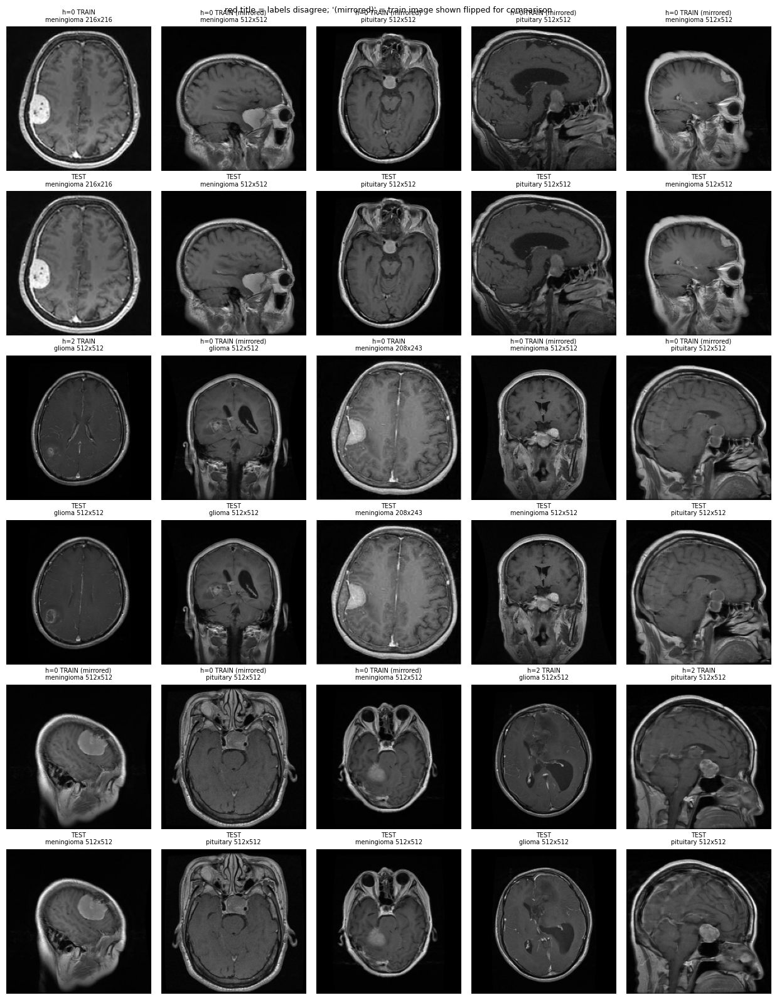


  3.6  DECISION
HASH_MAX = 8: 18536 candidate pairs. A hash is a proxy: Cell 6 keeps a candidate as a COPY only
if its pixels confirm it (NCC >= 0.95), and Cell 7 searches again without any hash.
NEAR_H = 2: near-duplicate candidates (likely adjacent slices or edited copies); Cell 6 links them only when
their pixels agree too (NCC >= NEAR_NCC), because two different brains can share a coarse hash.
Hash alone at NEAR_H: largest group 13; 596 test images share a group with a training image (159 when mirrors are ignored).

  3.7  SAVE
saved manifest_cell03.csv (adds size, size_family), cell03_phash.npz, cell03_summary.json

------------------------------------------------------------------------------
  [PASS]  every image hashed
  [PASS]  plain-hash part reproduces the 8 Oct 2026 measurement (pairs 223/500/1312, test 106/159/320)
  [NOTE]  image size alone predicts the class 44.6% of the time vs 29.3% for the majority class: a shortcut. Cell 13 measures what a geometry-only classifier r

In [ ]:
# =============================================================================
#  CELL 3  |  Data: size shortcut and near-duplicates (flip-aware perceptual hash)
# =============================================================================
assert "df" in globals() and len(df) == 6000 and "image_path" in df.columns, "Run Cell 2 first."

HASH_SIZE  = 8                  # 8x8 low-frequency DCT block -> 63 bits (DC term dropped)
DCT_SIZE   = 32                 # image reduced to 32x32 before the DCT
THRESHOLDS = [0, 2, 4, 6, 8]    # Hamming distances swept (only even values occur, see 3.2)
SHOW_AT    = [0, 2, 4]          # thresholds with example pairs drawn
N_SHOW     = 5                  # cross-split pairs drawn per threshold
HASH_MAX   = 8                  # pairs up to this distance are CANDIDATE copies; Cell 6 confirms them with pixels
NEAR_H     = 2                  # decision: near-duplicate candidates; Cell 6 links them when their pixels agree (NEAR_NCC)
MAX_GROUP  = 50                 # a larger copy group means chaining (Cell 6 checks its groups against it)
REF_PLAIN  = {0: (223, 106), 2: (500, 159), 4: (1312, 320)}   # plain-hash pairs / test twins, measured 8 Oct 2026 (Kaggle v6)

import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

N = len(df)
split_a, label_a = df.split.to_numpy(), df.label.to_numpy()
checks, notes = {}, []

# ----- 3.1 is image size a shortcut to the class? ---------------------------------
banner("3.1  IMAGE SIZE AS A SHORTCUT")
df["size"] = df.w.astype(str) + "x" + df.h.astype(str)
cnt = df["size"].value_counts()
df["size_family"] = np.where(df["size"].isin(set(cnt[cnt >= 100].index)), df["size"], "other")
print("class composition inside each size family (row %):")
print((pd.crosstab(df.size_family, df.label, normalize="index") * 100).round(1).to_string())
acc_size = df.groupby("size_family")["label"].agg(lambda s: s.value_counts().iat[0]).sum() / N
acc_major = df.label.value_counts().iat[0] / N
print(f"\naccuracy of predicting the class from the size family alone : {acc_size:.3%}")
print(f"accuracy of always predicting the largest class              : {acc_major:.3%}")
if acc_size > acc_major + 0.02:
    notes.append(f"image size alone predicts the class {acc_size:.1%} of the time vs {acc_major:.1%} for the majority class: "
                 "a shortcut. Cell 13 measures what a geometry-only classifier reaches on the test set.")

# ----- 3.2 perceptual hash of every image and of its mirror -------------------------
banner("3.2  PERCEPTUAL HASH  (all images, each also mirrored left-right)")
def dct_bits(im):
    im = cv2.resize(im, (DCT_SIZE, DCT_SIZE), interpolation=cv2.INTER_AREA).astype(np.float32)
    flat = cv2.dct(im)[:HASH_SIZE, :HASH_SIZE].flatten()[1:]
    return (flat > np.median(flat)).astype(np.uint8)
def phash_pair(path):
    """(hash of the image, hash of its left-right mirror). A perceptual hash is NOT mirror-invariant."""
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return (None, None) if im is None else (dct_bits(im), dct_bits(cv2.flip(im, 1)))
t0 = time.time(); bits, bits_f = [], []; n_fail = 0; nb = HASH_SIZE * HASH_SIZE - 1
for p in df.image_path:
    a, b = phash_pair(p)
    if a is None:
        n_fail += 1; a = b = np.zeros(nb, np.uint8)
    bits.append(a); bits_f.append(b)
bits, bits_f = np.stack(bits), np.stack(bits_f)
print(f"hashed {N - n_fail}/{N} images (plain and mirrored) in {time.time()-t0:.0f}s, {bits.shape[1]} bits each")
checks["every image hashed"] = n_fail == 0
w = np.concatenate([bits.sum(1), bits_f.sum(1)])
print("set bits per hash (value: count):", {int(k): int(v) for k, v in pd.Series(w).value_counts().head(3).items()})
print("Each hash marks the coefficients above the median of 63 values, so (without ties) 31 bits are set and two\n"
      "hashes always differ in an even number of bits: only even thresholds are meaningful.")

# ----- 3.3 every pair up to the loosest threshold --------------------------------------
banner("3.3  PAIRWISE DISTANCES  (smallest of: plain, image vs mirrored partner, mirrored image vs partner)")
packed, packed_f = np.packbits(bits, axis=1), np.packbits(bits_f, axis=1)
POP = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(1).astype(np.uint8)
ham = lambda a, b: POP[np.bitwise_xor(a[:, None, :], b[None, :, :])].sum(2)
maxt = max(THRESHOLDS); R_, C_, D_, DP_ = [], [], [], []
t0 = time.time()
for i in range(0, N, 512):
    blk, blk_f = packed[i:i + 512], packed_f[i:i + 512]
    Dp = ham(blk, packed)                                             # plain vs plain
    Dm = np.minimum(ham(blk, packed_f), ham(blk_f, packed))           # one of the two mirrored
    Dmin = np.minimum(Dp, Dm)
    r0 = np.arange(i, min(i + 512, N))
    rr, cc_ = np.nonzero(Dmin <= maxt)
    keep = r0[rr] < cc_
    R_.append(r0[rr][keep]); C_.append(cc_[keep]); D_.append(Dmin[rr, cc_][keep]); DP_.append(Dp[rr, cc_][keep])
R, C, Dd, Dplain = (np.concatenate(x) for x in (R_, C_, D_, DP_))
Mir = Dd < Dplain                                                     # closer once one image is mirrored
print(f"pairs with distance <= {maxt}: {len(R)}   closer when mirrored: {int(Mir.sum())}   ({time.time()-t0:.0f}s)")

def groups_at(t, plain_only=False):
    """Connected components of the graph 'hash distance <= t' (one group id per row of df).
    plain_only=True ignores mirrored matches (what a plain perceptual hash would see)."""
    m = (Dplain if plain_only else Dd) <= t
    if not m.any():
        return np.arange(N)
    g = coo_matrix((np.ones(int(m.sum())), (R[m], C[m])), shape=(N, N))
    return connected_components(g, directed=False)[1]

def n_test_with_train_twin(lab_):
    per = pd.DataFrame({"g": lab_, "split": split_a}).groupby("g")["split"].nunique()
    return int((pd.Series(lab_).isin(per.index[per > 1]).to_numpy() & (split_a == "test")).sum())

# ----- 3.4 leakage, chaining and label consistency at every threshold -------------------
banner("3.4  LEAKAGE, CHAINING AND LABEL CONSISTENCY vs THRESHOLD")
rows = []
for t in THRESHOLDS:
    lab = groups_at(t); sz_ = pd.Series(lab).value_counts()
    per = pd.DataFrame({"g": lab, "label": label_a}).groupby("g").agg(n=("g", "size"), nl=("label", "nunique"))
    multi = per.index[per.nl > 1]; m = Dd <= t
    leaked = n_test_with_train_twin(lab)
    rows.append({"hamming": t, "pairs": int(m.sum()), "pairs_mirrored": int((m & Mir).sum()),
                 "groups>1": int((sz_ > 1).sum()), "largest": int(sz_.max()),
                 "test_leaked_plain": n_test_with_train_twin(groups_at(t, plain_only=True)),
                 "test_leaked": leaked, "test_leak_%": round(100 * leaked / int((split_a == "test").sum()), 1),
                 "mixed_class_groups": int(len(multi)),
                 "same_label_%": round(100 * float((label_a[R[m]] == label_a[C[m]]).mean()), 1) if m.any() else np.nan})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))
print("\npairs_mirrored    = pairs that are closer once one image is mirrored (invisible to a plain hash)")
print("test_leaked_plain = test images with a train image in their group when mirrored matches are ignored")
print("test_leaked       = the same with mirrored matches included")
print("largest           = biggest group; a jump means chaining (A~B and B~C pull A~C in)")

# ----- 3.5 look at cross-split pairs ----------------------------------------------------
banner("3.5  EXAMPLE CROSS-SPLIT PAIRS  (top: train image; bottom: its test twin)")
rng = np.random.default_rng(SEED)
def load_small(p, s=200, flip=False):
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if im is None:
        return np.zeros((s, s), np.uint8)
    im = cv2.resize(im, (s, s))
    return im[:, ::-1] if flip else im
fig, ax = plt.subplots(2 * len(SHOW_AT), N_SHOW, figsize=(2.5 * N_SHOW, 2.7 * 2 * len(SHOW_AT)), squeeze=False)
for bi, t in enumerate(SHOW_AT):
    ii = np.nonzero((Dd <= t) & (split_a[R] != split_a[C]))[0]
    pick = rng.choice(ii, size=min(N_SHOW, len(ii)), replace=False) if len(ii) else []
    print(f"distance <= {t}: {len(ii)} cross-split pairs ({int(Mir[ii].sum())} mirrored), drawing {len(pick)}")
    for j in range(N_SHOW):
        for a_ in (ax[2 * bi, j], ax[2 * bi + 1, j]):
            a_.axis("off")
        if j >= len(pick):
            continue
        k = pick[j]; i1, i2 = R[k], C[k]
        if split_a[i1] == "test":
            i1, i2 = i2, i1
        mir = bool(Mir[k])
        ax[2 * bi, j].imshow(load_small(df.image_path[i1], flip=mir), cmap="gray")
        ax[2 * bi, j].set_title(f"h={Dd[k]} TRAIN{' (mirrored)' if mir else ''}\n{df.label[i1][:10]} {df['size'][i1]}", fontsize=7)
        ax[2 * bi + 1, j].imshow(load_small(df.image_path[i2]), cmap="gray")
        ax[2 * bi + 1, j].set_title(f"TEST\n{df.label[i2][:10]} {df['size'][i2]}", fontsize=7,
                                    color="red" if df.label[i1] != df.label[i2] else "black")
plt.suptitle("red title = labels disagree; '(mirrored)' = train image shown flipped for comparison", fontsize=9)
plt.tight_layout(); plt.savefig(WORK / "cell03_pairs.png", dpi=110, bbox_inches="tight"); plt.show()

# ----- 3.6 decision -------------------------------------------------------------------------
banner("3.6  DECISION")
g_row = sweep[sweep.hamming == NEAR_H].iloc[0]; h_row = sweep[sweep.hamming == HASH_MAX].iloc[0]
print(f"HASH_MAX = {HASH_MAX}: {int(h_row.pairs)} candidate pairs. A hash is a proxy: Cell 6 keeps a candidate as a COPY only\n"
      f"if its pixels confirm it (NCC >= 0.95), and Cell 7 searches again without any hash.")
print(f"NEAR_H = {NEAR_H}: near-duplicate candidates (likely adjacent slices or edited copies); Cell 6 links them only when\n"
      f"their pixels agree too (NCC >= NEAR_NCC), because two different brains can share a coarse hash.\n"
      f"Hash alone at NEAR_H: largest group {int(g_row.largest)}; {int(g_row.test_leaked)} test images share a group with a "
      f"training image ({int(g_row.test_leaked_plain)} when mirrors are ignored).")
if int(g_row.largest) > MAX_GROUP:
    notes.append(f"the hash alone chains at NEAR_H (largest group {int(g_row.largest)} > {MAX_GROUP}): hash-only grouping would "
                 "merge unrelated images. Cell 6 links near-duplicates only with pixel support.")
if not SMOKE:
    ok_ref = all((int((Dplain <= t).sum()), int(sweep[sweep.hamming == t].test_leaked_plain.iloc[0])) == v
                 for t, v in REF_PLAIN.items())
    checks["plain-hash part reproduces the 8 Oct 2026 measurement (pairs 223/500/1312, test 106/159/320)"] = ok_ref
if int(g_row.test_leaked) > int(g_row.test_leaked_plain):
    notes.append(f"mirrored near-copies: {int(g_row.test_leaked) - int(g_row.test_leaked_plain)} more test images are within "
                 f"hash distance {NEAR_H} of a training image once mirrors are hashed. A plain perceptual hash misses them.")

# ----- 3.7 save -------------------------------------------------------------------------------
banner("3.7  SAVE")
np.savez_compressed(WORK / "cell03_phash.npz", bits=bits, bits_f=bits_f, r=R, c=C, d=Dd, dp=Dplain, mir=Mir)
df.to_csv(WORK / "manifest_cell03.csv", index=False)
save_json(WORK / "cell03_summary.json", {"hash_max": HASH_MAX, "near_h": NEAR_H, "sweep": sweep.to_dict("records"),
                                         "acc_class_from_size": float(acc_size), "acc_majority": float(acc_major)})
print("saved manifest_cell03.csv (adds size, size_family), cell03_phash.npz, cell03_summary.json")
finish(3, checks, notes)

## Cell 4 | Preprocessing: the transform, its proofs, the cache

**Purpose.** One transform for every image: grey, crop to the brain, scale the longer side to 256 px, black padding (no stretching). The mask goes through the same crop and the same resampling kernel, keeping pixels with >= 50% tumour coverage. Every property is proven before the cache is trusted. The cell also defines the image utilities used later (`get_img`, `ncc_best`, `align`, `unit_vec`), times one full-resolution comparison (`NCC_SEC`, used for the time estimates of Cells 5-7) and fingerprints the cache (`CACHE_MD5`, the key of the saved searches).

**Inputs.** `df`, source files. **Outputs.** `images.npy`, `masks.npy` (6,000 x 256 x 256, uint8), `manifest_cell04.csv` (adds geometry and `pad_share`), `cell04_cache.json` (`gates_passed`).

**Pass criteria.** (1) The crop loses no tumour pixel. (2) The crop keeps >= 99.9% of the brain. (3) No preprocessing failure. (4) The cache equals fresh preprocessing, byte for byte. (5) Masks are co-registered with the image (median offset < 0.1 px). (6) No blank image, no emptied mask. (7) `ncc_best` returns 1 on identical images and recovers a known shift. (8) Real data at 256 px only: reproduces the 8 Oct 2026 cache (mean tumour fraction 0.01999, 28 masks under 100 px).

*`MASK_THR = 127` is a convention; 4.2 reports how much the target changes with the threshold.*


  4.1  THE TRANSFORM
image : grey -> crop to the brain (pixels > 10, +2% margin) -> longer side to 256 (INTER_AREA) -> black padding
mask  : value > 127 -> same crop -> same kernel as the image -> keep pixels with >= 50% tumour coverage
No stretching. Intensity normalisation happens in the data pipeline (Cell 8), not in the cache.

  4.2  PROOFS ON THE SOURCE FILES
masked images checked 4793 (34s): shape mismatch/unreadable 0, masks losing a tumour pixel to the crop 0   (both must be 0)
Otsu-brain pixels kept by the crop (600 images): mean 1.0000  min 1.0000

mask threshold sensitivity (500 masks): area >127 is -10.4% vs >0, =255 is -19.9%;  Dice(>0, >127) mean 0.9300  min 0.7396
MASK_THR = 127 is a convention. Every Dice in this notebook is against this target.

  4.3  BUILDING THE CACHE
  2000/6000  (16s)
  4000/6000  (31s)
  6000/6000  (46s)
wrote 6000 rows in 46s   failures 0   (must be 0)

  4.4  VERIFY  (random rows re-made from the source files, compared byte for byte)
image mi

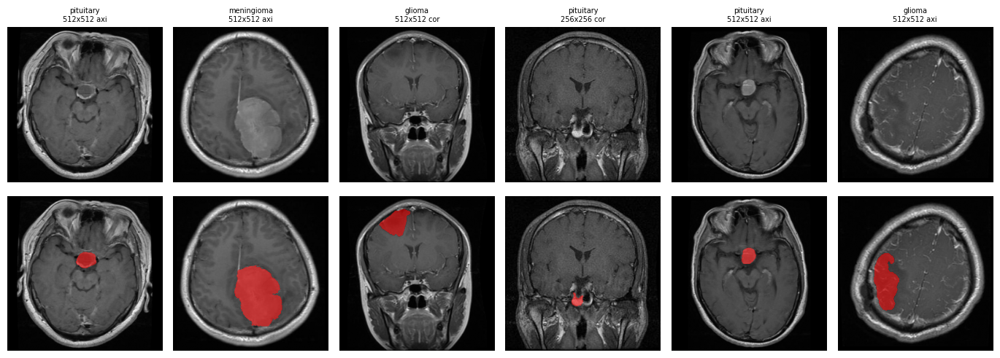


  4.7  CACHE STATISTICS
blank images 0 (must be 0);  tumour area fraction: mean 0.01999  median 0.01428;  masks under 100 px 28  (small-lesion fallback used 0)

black padding (% of the square), by size family and class:
label        glioma  meningioma  no_tumor  pituitary
size_family                                         
216x369         NaN         NaN      41.0        NaN
369x369         NaN         NaN       6.7        NaN
512x512        10.1         7.7       8.5        3.1
other           NaN        10.3      23.1        2.1
Padding differs by size family, and size family tracks the class: the size shortcut survives preprocessing.
Cell 13 measures it with a geometry-only classifier; Cells 14-16 report results by size family.

utilities: get_img, ncc_best (shift 16 px), align, unit_vec.  self-NCC 1.0000, vs own mirror 0.593
one full-resolution pixel comparison: 1.5 ms on this machine;  cache fingerprint 9ef81a22edc5cb52

  4.9  SAVE
saved images.npy, masks.npy, manifest_cell04.c

In [ ]:
# =============================================================================
#  CELL 4  |  Preprocessing: the transform, its proofs, the cache, image utilities
# =============================================================================
assert "size_family" in df.columns, "Run Cell 3 first."

MASK_THR = 127      # decision: a mask pixel is tumour if its value is above this (sensitivity in 4.2)
BG_THR   = 10       # decision: pixels above this are "not background" for the brain crop
CROP_PAD = 0.02     # margin added around the brain bounding box
CROP_N, THR_N, VERIFY_N, COREG_N, N_SHOW = 600, 500, 60, 800, 6
REF_CACHE = {"mean_mask_frac": 0.01999, "masks_under_100px": 28}   # measured 8 Oct 2026 at SIZE 256 (Kaggle v6)

import matplotlib.pyplot as plt
N = len(df)
rng = np.random.default_rng(SEED)
checks, notes = {}, []

# ----- 4.1 the transform (defined once; everything below uses these functions) ------
def brain_bbox(img, bg=BG_THR, pad=CROP_PAD):
    """Bounding box (x0, y0, x1, y1) of pixels brighter than bg, plus a small margin."""
    m = img > bg
    if not m.any():
        return 0, 0, img.shape[1], img.shape[0]
    ys, xs = np.where(m)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    dy, dx = int((y1 - y0) * pad), int((x1 - x0) * pad)
    return max(0, x0 - dx), max(0, y0 - dy), min(img.shape[1], x1 + dx), min(img.shape[0], y1 + dy)

def letterbox_geom(h, w, size=SIZE):
    """Height/width after scaling the longer side to `size`, and the top/left padding."""
    s = size / max(h, w)
    nh, nw = max(1, int(round(h * s))), max(1, int(round(w * s)))
    return nh, nw, (size - nh) // 2, (size - nw) // 2

def letterbox(img, size=SIZE, pad_value=0, interp=cv2.INTER_AREA):
    """Scale to fit a size x size square without changing the aspect ratio; pad with pad_value."""
    nh, nw, t, l = letterbox_geom(*img.shape[:2], size)
    r = cv2.resize(img, (nw, nh), interpolation=interp)
    return cv2.copyMakeBorder(r, t, size - nh - t, l, size - nw - l, cv2.BORDER_CONSTANT, value=pad_value)

def resample_mask(m01):
    """Binary mask -> SIZE x SIZE with the SAME kernel as the image (INTER_AREA on a float copy), keeping
    pixels with >= 50% tumour coverage; a lesion too small for that keeps its best-covered pixels."""
    cov = letterbox(m01.astype(np.float32), SIZE, 0.0, cv2.INTER_AREA)
    out = cov >= 0.5
    if m01.any() and not out.any():
        return (cov >= 0.5 * cov.max()).astype(np.uint8), True
    return out.astype(np.uint8), False

def preprocess_arrays(img, msk01=None):
    """The one definitive transform on arrays: crop to the brain, letterbox to SIZE. Returns image, mask, geometry, flag."""
    H, W = img.shape
    x0, y0, x1, y1 = brain_bbox(img)
    nh, nw, t, l = letterbox_geom(y1 - y0, x1 - x0)
    out_i = letterbox(img[y0:y1, x0:x1], SIZE, 0, cv2.INTER_AREA)
    out_m, fb = np.zeros((SIZE, SIZE), np.uint8), False
    if msk01 is not None:
        out_m, fb = resample_mask(msk01[y0:y1, x0:x1])
    return out_i, out_m, (H, W, x0, y0, x1, y1, nh, nw, t, l), fb

def preprocess(image_path, mask_path):
    """File version of preprocess_arrays: grey image, mask thresholded at MASK_THR."""
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f"unreadable: {image_path}")
    msk = None
    if isinstance(mask_path, str) and mask_path and mask_path.lower() != "nan":
        raw = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if raw is not None:
            if raw.shape != img.shape:
                raise ValueError(f"mask {raw.shape} != image {img.shape}: {mask_path}")
            msk = (raw > MASK_THR).astype(np.uint8)
    return preprocess_arrays(img, msk)

GEOM_COLS = ["orig_h", "orig_w", "crop_x0", "crop_y0", "crop_x1", "crop_y1", "lb_h", "lb_w", "lb_top", "lb_left"]
banner("4.1  THE TRANSFORM")
print(f"image : grey -> crop to the brain (pixels > {BG_THR}, +{CROP_PAD:.0%} margin) -> longer side to {SIZE} (INTER_AREA) -> black padding")
print(f"mask  : value > {MASK_THR} -> same crop -> same kernel as the image -> keep pixels with >= 50% tumour coverage")
print("No stretching. Intensity normalisation happens in the data pipeline (Cell 8), not in the cache.")

# ----- 4.2 proofs on the source files ---------------------------------------------------
banner("4.2  PROOFS ON THE SOURCE FILES")
masked = df[df.has_mask]
bad_shape = lost_any = 0; t0 = time.time()
for ip, mp in zip(masked.image_path, masked.mask_path):
    img = cv2.imread(ip, cv2.IMREAD_GRAYSCALE); raw = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    if img is None or raw is None or img.shape != raw.shape:
        bad_shape += 1; continue
    x0, y0, x1, y1 = brain_bbox(img)
    lost_any += int((raw > MASK_THR).sum() != (raw[y0:y1, x0:x1] > MASK_THR).sum())
print(f"masked images checked {len(masked)} ({time.time()-t0:.0f}s): shape mismatch/unreadable {bad_shape}, "
      f"masks losing a tumour pixel to the crop {lost_any}   (both must be 0)")
checks["every mask matches its image and the crop loses no tumour pixel"] = (bad_shape == 0 and lost_any == 0)

samp = df.sample(min(CROP_N, N), random_state=SEED); kept_brain = []
for ip in samp.image_path:
    img = cv2.imread(ip, cv2.IMREAD_GRAYSCALE)
    x0, y0, x1, y1 = brain_bbox(img)
    otsu, _ = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    brain = img > otsu
    kept_brain.append(brain[y0:y1, x0:x1].sum() / max(brain.sum(), 1))
kept_brain = np.array(kept_brain)
print(f"Otsu-brain pixels kept by the crop ({len(samp)} images): mean {kept_brain.mean():.4f}  min {kept_brain.min():.4f}")
checks["the crop keeps >= 99.9% of the brain in every sampled image"] = bool((kept_brain >= 0.999).all())

sub = masked.sample(min(THR_N, len(masked)), random_state=SEED); trows = []
for mp in sub.mask_path:
    raw = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    a0, a127, a255 = raw > 0, raw > 127, raw >= 255
    trows.append({"f0": a0.mean(), "f127": a127.mean(), "f255": a255.mean(),
                  "dice_0_127": 2 * (a0 & a127).sum() / max(1, a0.sum() + a127.sum())})
th = pd.DataFrame(trows)
print(f"\nmask threshold sensitivity ({len(th)} masks): area >127 is {th.f127.mean()/th.f0.mean()-1:+.1%} vs >0, "
      f"=255 is {th.f255.mean()/th.f0.mean()-1:+.1%};  Dice(>0, >127) mean {th.dice_0_127.mean():.4f}  min {th.dice_0_127.min():.4f}")
print(f"MASK_THR = {MASK_THR} is a convention. Every Dice in this notebook is against this target.")

# ----- 4.3 build the cache -----------------------------------------------------------------
banner("4.3  BUILDING THE CACHE")
img_path, msk_path, meta_path = WORK / "images.npy", WORK / "masks.npy", WORK / "cell04_cache.json"
save_json(meta_path, {"gates_passed": False})            # stays failed until every gate below passes
IM = np.lib.format.open_memmap(img_path, mode="w+", dtype=np.uint8, shape=(N, SIZE, SIZE))
MK = np.lib.format.open_memmap(msk_path, mode="w+", dtype=np.uint8, shape=(N, SIZE, SIZE))
stats = np.zeros((N, 3), np.float32); geom = np.zeros((N, len(GEOM_COLS)), np.int32)
fallback = np.zeros(N, bool); fails = []; t0 = time.time()
for i, r in enumerate(df.itertuples()):
    try:
        im, mk, gm, fb = preprocess(r.image_path, r.mask_path)
    except Exception as e:
        fails.append((r.image_id, str(e)[:70])); continue
    IM[i], MK[i] = im, mk
    stats[i] = (im.mean(), im.std(), mk.mean()); geom[i] = gm; fallback[i] = fb
    if (i + 1) % 2000 == 0:
        print(f"  {i+1}/{N}  ({time.time()-t0:.0f}s)")
IM.flush(); MK.flush(); del IM, MK
print(f"wrote {N} rows in {time.time()-t0:.0f}s   failures {len(fails)}   (must be 0)")
checks["every image preprocessed without failure"] = len(fails) == 0

# ----- 4.4 verify the cache -------------------------------------------------------------------
banner("4.4  VERIFY  (random rows re-made from the source files, compared byte for byte)")
IMc, MKc = np.load(img_path, mmap_mode="r"), np.load(msk_path, mmap_mode="r")
bad_i = bad_m = 0
for i in rng.choice(N, size=min(VERIFY_N, N), replace=False):
    r = df.iloc[int(i)]; im, mk, _, _ = preprocess(r.image_path, r.mask_path)
    bad_i += int(not np.array_equal(im, IMc[i])); bad_m += int(not np.array_equal(mk, MKc[i]))
nonempty = np.asarray(MKc).reshape(N, -1).max(1) > 0
mism = int((df.has_mask.values != nonempty).sum())
print(f"image mismatches {bad_i}   mask mismatches {bad_m}   rows where 'has a mask' disagrees {mism}   (all must be 0)")
checks["cache equals fresh preprocessing; mask rows agree with the manifest"] = (bad_i == 0 and bad_m == 0 and mism == 0)

# ----- 4.5 co-registration ------------------------------------------------------------------------
banner("4.5  CO-REGISTRATION  (nearest-neighbour masks vs the method used here)")
def centroid(b):
    ys, xs = np.nonzero(b)
    return np.array([xs.mean(), ys.mean()]) if len(xs) else None
pool = df.index[df.has_mask].to_numpy(); off_new, off_old = [], []
for i in rng.choice(pool, size=min(COREG_N, len(pool)), replace=False):
    r = df.iloc[int(i)]
    img = cv2.imread(r.image_path, cv2.IMREAD_GRAYSCALE)
    raw = (cv2.imread(r.mask_path, cv2.IMREAD_GRAYSCALE) > MASK_THR).astype(np.uint8)
    x0, y0, x1, y1 = brain_bbox(img)
    marked = np.minimum(img, 200).astype(np.uint8); marked[raw > 0] = 255     # tumour painted into the image
    bright = letterbox(marked[y0:y1, x0:x1], SIZE, 0, cv2.INTER_AREA) >= 225
    if bright.sum() < 5:
        continue
    cb, cn = centroid(bright), centroid(MKc[i] > 0)
    co = centroid(letterbox(raw[y0:y1, x0:x1], SIZE, 0, cv2.INTER_NEAREST) > 0)
    if cn is not None: off_new.append(cn - cb)
    if co is not None: off_old.append(co - cb)
def coreg_row(name, o):
    o = np.array(o); d = np.hypot(o[:, 0], o[:, 1])
    return {"method": name, "n": len(o), "dx_median": np.median(o[:, 0]), "dy_median": np.median(o[:, 1]),
            "dist_median": np.median(d), "dist_p95": np.percentile(d, 95)}
co_tab = pd.DataFrame([coreg_row("nearest-neighbour", off_old), coreg_row("area >= 0.5 (used)", off_new)]).set_index("method")
print(co_tab.round(3).to_string())
dxn, dyn, dmed = co_tab.iloc[1][["dx_median", "dy_median", "dist_median"]]
checks["cached masks are co-registered with the image (|median offset| < 0.1 px, median distance < 0.3 px)"] = bool(
    abs(dxn) < 0.1 and abs(dyn) < 0.1 and dmed < 0.3)

# ----- 4.6 look at it ---------------------------------------------------------------------------------
banner("4.6  EXAMPLES  (top: cached image; bottom: with the cached mask)")
sm = df[df.has_mask].sample(N_SHOW, random_state=SEED)
fig, ax = plt.subplots(2, N_SHOW, figsize=(2.3 * N_SHOW, 5.2), squeeze=False)
for j, (i, r) in enumerate(sm.iterrows()):
    ax[0, j].imshow(IMc[i], cmap="gray"); ax[0, j].axis("off"); ax[0, j].set_title(f"{r.label}\n{r['size']} {r.plane[:3]}", fontsize=7)
    ax[1, j].imshow(IMc[i], cmap="gray"); ax[1, j].imshow(np.ma.masked_where(MKc[i] == 0, MKc[i]), cmap="autumn", alpha=0.55)
    ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(WORK / "cell04_examples.png", dpi=110, bbox_inches="tight"); plt.show()

# ----- 4.7 statistics ---------------------------------------------------------------------------------
banner("4.7  CACHE STATISTICS")
df["px_mean"], df["px_std"], df["mask_frac"] = stats[:, 0], stats[:, 1], stats[:, 2]
for j, c in enumerate(GEOM_COLS):
    df[c] = geom[:, j]
df["mask_fallback"] = fallback
df["pad_share"] = 1 - (df.lb_h * df.lb_w) / (SIZE * SIZE)          # share of the square that is black padding
m = df[df.has_mask]
n_small = int((m.mask_frac * SIZE * SIZE < 100).sum())
print(f"blank images {int((df.px_std == 0).sum())} (must be 0);  tumour area fraction: mean {m.mask_frac.mean():.5f}  "
      f"median {m.mask_frac.median():.5f};  masks under 100 px {n_small}  (small-lesion fallback used {int(df.mask_fallback.sum())})")
print("\nblack padding (% of the square), by size family and class:")
print((pd.pivot_table(df, index="size_family", columns="label", values="pad_share", aggfunc="mean") * 100).round(1).to_string())
print("Padding differs by size family, and size family tracks the class: the size shortcut survives preprocessing.\n"
      "Cell 13 measures it with a geometry-only classifier; Cells 14-16 report results by size family.")
checks["no blank image, no emptied mask"] = int((df.px_std == 0).sum()) == 0 and int((m.mask_frac == 0).sum()) == 0
if SIZE == 256 and not SMOKE:
    checks["reproduces the 8 Oct 2026 cache (mean tumour fraction 0.01999, 28 masks under 100 px)"] = (
        round(float(m.mask_frac.mean()), 5) == REF_CACHE["mean_mask_frac"] and n_small == REF_CACHE["masks_under_100px"])

# ----- 4.8 image utilities used by Cells 5, 7 and 12 -----------------------------------------------
NCC_SHIFT = max(2, SIZE // 16)            # +-16 px at 256: the template is the central (SIZE - 2*shift) window
def get_img(i, flip=False):
    a = np.asarray(IMc[i], dtype=np.float32)
    return np.ascontiguousarray(a[:, ::-1]) if flip else a

def ncc_best(a, b, shift=NCC_SHIFT):
    """Best normalised cross-correlation of a's central window inside b, over shifts up to `shift` px.
    1.0 = the same picture up to brightness and contrast. Returns (ncc, dx, dy)."""
    S_ = a.shape[0]
    t = np.ascontiguousarray(a[shift:S_ - shift, shift:S_ - shift], dtype=np.float32)
    b = np.ascontiguousarray(b, dtype=np.float32)
    if t.std() < 1e-3 or b.std() < 1e-3:
        return 0.0, 0, 0
    _, mx, _, loc = cv2.minMaxLoc(cv2.matchTemplate(b, t, cv2.TM_CCOEFF_NORMED))
    return float(mx), int(loc[0]) - shift, int(loc[1]) - shift

def align(b, dx, dy):
    """Move array b into a's frame, given ncc_best(a, b) -> (ncc, dx, dy): out[y, x] = b[y + dy, x + dx] (zero fill)."""
    out = np.zeros_like(b); S_ = b.shape[0]
    ys, yd = (slice(dy, None), slice(0, S_ - dy)) if dy >= 0 else (slice(0, S_ + dy), slice(-dy, None))
    xs, xd = (slice(dx, None), slice(0, S_ - dx)) if dx >= 0 else (slice(0, S_ + dx), slice(-dx, None))
    out[yd, xd] = b[ys, xs]
    return out

def unit_vec(a, n=24):
    """Coarse, mean-free, unit-length version of an image, for fast candidate ranking."""
    v = cv2.resize(np.asarray(a, dtype=np.float32), (n, n), interpolation=cv2.INTER_AREA).ravel()
    v = v - v.mean(); s_ = np.linalg.norm(v)
    return v / s_ if s_ > 1e-6 else v * 0
a0 = get_img(0); n_self = ncc_best(a0, a0)[0]; n_flip = ncc_best(a0, get_img(0, flip=True))[0]
checks["ncc_best(x, x) == 1"] = abs(n_self - 1.0) < 1e-4
b_sh = np.zeros_like(a0); b_sh[2:, 3:] = a0[:-2, :-3]                      # content moved right 3, down 2
_, dx_, dy_ = ncc_best(a0, b_sh)
checks["ncc_best finds a known shift and align() undoes it"] = (dx_, dy_) == (3, 2) and np.allclose(
    align(b_sh, dx_, dy_)[NCC_SHIFT:-NCC_SHIFT, NCC_SHIFT:-NCC_SHIFT], a0[NCC_SHIFT:-NCC_SHIFT, NCC_SHIFT:-NCC_SHIFT])
print(f"\nutilities: get_img, ncc_best (shift {NCC_SHIFT} px), align, unit_vec.  self-NCC {n_self:.4f}, vs own mirror {n_flip:.3f}")
t_ = time.time()
for _ in range(20):
    ncc_best(a0, get_img(min(1, N - 1)))
NCC_SEC = (time.time() - t_) / 20                     # seconds per full-resolution comparison: Cells 5-7 print estimates
h_ = hashlib.md5()
for k in range(0, N, 500):
    h_.update(np.ascontiguousarray(IMc[k:k + 500]).tobytes()); h_.update(np.ascontiguousarray(MKc[k:k + 500]).tobytes())
CACHE_MD5 = h_.hexdigest()[:16]                       # fingerprint of the cache: the key of every reused search
print(f"one full-resolution pixel comparison: {1000 * NCC_SEC:.1f} ms on this machine;  cache fingerprint {CACHE_MD5}")

# ----- 4.9 save ------------------------------------------------------------------------------------
banner("4.9  SAVE")
df.to_csv(WORK / "manifest_cell04.csv", index=False)
gates_ok = all(checks.values())
save_json(meta_path, {"gates_passed": bool(gates_ok), "gates": {k: bool(v) for k, v in checks.items()},
                      "size": SIZE, "bg_thr": BG_THR, "mask_thr": MASK_THR, "crop_pad": CROP_PAD, "n": int(N),
                      "cache_md5": CACHE_MD5,
                      "mean_mask_frac": float(m.mask_frac.mean()), "masks_under_100px": n_small,
                      "coregistration": co_tab.round(4).reset_index().to_dict(orient="records")})
print("saved images.npy, masks.npy, manifest_cell04.csv (adds pixel stats, geometry, pad_share), cell04_cache.json")
finish(4, checks, notes)

## Cell 5 | Provenance: trace every image to the figshare source (patients)

**Purpose.** BRISC has no patient IDs, but its tumour images largely come from the figshare dataset of Cheng et al., which stores a patient ID and a tumour mask for every slice. Every BRISC image is matched against all 3,064 source slices in all 8 orientations (rotations and mirrors): a coarse pass on all pairs, then full-resolution NCC on the best candidates. A match (NCC >= 0.95) gives the image its source patient, its source label, its orientation relative to the source, and a second, independent annotation of the same slice.

**Inputs.** The cache (Cell 4); the four figshare archives (downloaded and checked against their published MD5). **Outputs.** Columns `fig_file, fig_pid, fig_label, fig_variant, fig_ncc, traced`; `cell05_trace.csv`, `cell05_mask_agreement.csv`, `cell05_summary.json`, figures.

**Pass criteria.** (1) The archives match their MD5. (2) The source holds 3,064 slices of 233 patients with labels 1-3. (3) Every image was compared with every slice. (4) Method check: source slices, transformed, are recovered with their orientation (>= 95%).

*Findings, reported as NOTES: images stored mirrored relative to their source, label disagreements, patient overlap across the official split, and agreement between BRISC masks and source masks. If the download fails, the cell says so, and Cell 6 groups by copies only.*


  5.1  FIGSHARE SOURCE FILES
downloading brainTumorDataPublic_1-766.zip ... 214 MB in 3s
  brainTumorDataPublic_1-766.zip: MD5 matches the figshare record
downloading brainTumorDataPublic_767-1532.zip ... 218 MB in 2s
  brainTumorDataPublic_767-1532.zip: MD5 matches the figshare record
downloading brainTumorDataPublic_1533-2298.zip ... 216 MB in 2s
  brainTumorDataPublic_1533-2298.zip: MD5 matches the figshare record
downloading brainTumorDataPublic_2299-3064.zip ... 232 MB in 3s
  brainTumorDataPublic_2299-3064.zip: MD5 matches the figshare record
.mat files available: 3064   (source has 3064)

  5.2  READ THE SOURCE  (cjdata.image, label, PID, tumorMask)
read 3064 slices in 29s   patients 233   classes {'glioma': 1426, 'pituitary': 930, 'meningioma': 708}   sizes {(256, 256): 15, (512, 512): 3049}

  5.3  MATCHING  (coarse pass on all pairs, then full-resolution NCC on the best candidates)
coarse pass: 6000 x 3064 x 8 orientations in 6s
full-resolution checks to run: 14011, about 0 

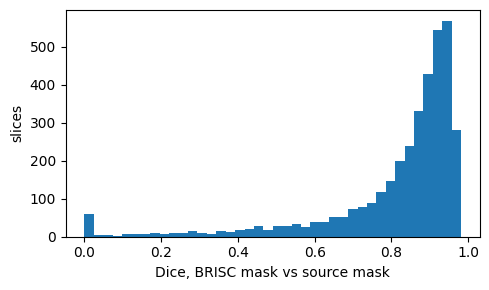


  5.6  EXAMPLES  (BRISC image | matched source slice, oriented as found)


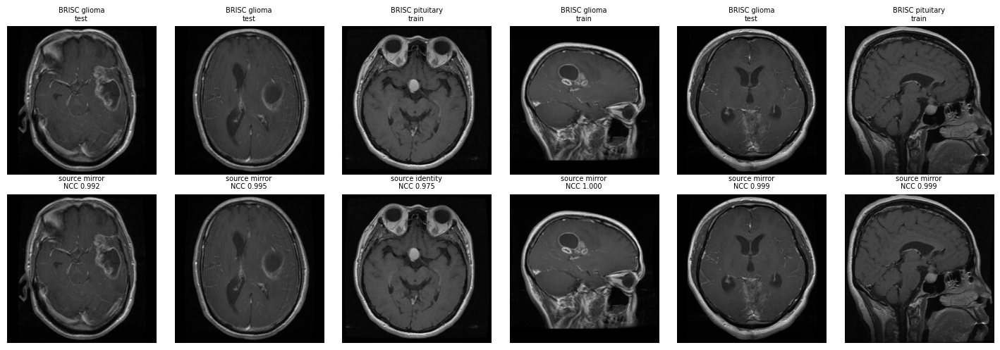


  5.7  SAVE
saved manifest_cell05.csv (adds fig_*, traced), cell05_trace.csv, cell05_mask_agreement.csv, cell05_summary.json

------------------------------------------------------------------------------
  [PASS]  the figshare archives match their published MD5
  [PASS]  the source holds 3064 slices of 233 patients, labels 1-3, masks the size of their image
  [PASS]  every image was compared with every source slice
  [PASS]  method check: source slices are recovered with their orientation (>= 95%)
  [NOTE]  2503 traced images are stored MIRRORED relative to their source slice.
  [NOTE]  3 traced images carry a BRISC label different from their source label (list in cell05_trace.csv; no_tumor rows are tumour slices labelled tumour-free).
  [NOTE]  patient overlap: 654 of 656 traced test images share a patient with the official training set. Untraced images (no source slice) cannot be checked for patient overlap.
  [NOTE]  BRISC masks vs the source masks of the same slices: median Dice 

In [ ]:
# =============================================================================
#  CELL 5  |  Data: provenance. Trace every image to the figshare source (patients)
# =============================================================================
assert "IMc" in globals() and "preprocess_arrays" in globals() and "ncc_best" in globals(), "Run Cell 4 first."

# Cheng J. "brain tumor dataset", figshare, doi 10.6084/m9.figshare.1512427 (v8, CC BY 4.0).
# File ids, names and MD5s as listed by the figshare API on 8 Oct 2026.
FIG_FILES = {3381290: ("brainTumorDataPublic_1-766.zip", "74b949ad33f042e6e103523091cd1428"),
             3381296: ("brainTumorDataPublic_767-1532.zip", "7e8a875500d2c8a346f270538e29890e"),
             3381293: ("brainTumorDataPublic_1533-2298.zip", "8227bf6080cb71f15a88be8d25c79ae7"),
             3381302: ("brainTumorDataPublic_2299-3064.zip", "b378a80d6174e5317d59eb28430c6652")}
FIG_URL      = "https://ndownloader.figshare.com/files/{fid}"
FIG_N        = 3064            # slices in the source (README)
FIG_PATIENTS = 233             # patients in the source (README)
FIG_LABEL    = {1: "meningioma", 2: "glioma", 3: "pituitary"}          # cjdata.label coding (README)
FIG_DIR      = Path(os.environ.get("BRISC_FIGSHARE_DIR", WORK / "figshare"))
VEC          = 32              # side of the vectors of the first, coarse pass
PRE_MIN      = 0.80            # coarse similarity a candidate needs before the full-resolution check
TOPK         = 3               # candidates checked at full resolution per image
CONFIRM      = 0.95            # "the same picture" (same convention as Cell 7)
MASK_NCC     = 0.98            # masks are compared only for near-exact matches

import zipfile, urllib.request
import matplotlib.pyplot as plt
try:
    import h5py
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "h5py"], check=True)
    import h5py
checks, notes = {}, []
N = len(df)

# ----- 5.1 get the source files -------------------------------------------------------
banner("5.1  FIGSHARE SOURCE FILES")
def md5_file(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
FIG_DIR.mkdir(parents=True, exist_ok=True)
mats = sorted(FIG_DIR.rglob("*.mat"))
TRACE_OK, md5_ok = True, True
if len(mats) < FIG_N:
    try:
        for fid, (name, md5) in FIG_FILES.items():
            zp = FIG_DIR / name
            if not zp.exists():
                t0 = time.time(); print(f"downloading {name} ...", end=" ", flush=True)
                urllib.request.urlretrieve(FIG_URL.format(fid=fid), zp)
                print(f"{zp.stat().st_size / 1e6:.0f} MB in {time.time()-t0:.0f}s")
            ok = md5_file(zp) == md5; md5_ok &= ok
            print(f"  {name}: MD5 {'matches' if ok else 'DOES NOT MATCH'} the figshare record")
            with zipfile.ZipFile(zp) as z:
                z.extractall(FIG_DIR)
            zp.unlink()
        mats = sorted(FIG_DIR.rglob("*.mat"))
    except Exception as e:
        TRACE_OK = False
        print(f"download failed: {type(e).__name__}: {str(e)[:120]}")
print(f".mat files available: {len(mats)}   (source has {FIG_N})")
checks["the figshare archives match their published MD5"] = md5_ok

# ----- 5.2 read the source -------------------------------------------------------------
banner("5.2  READ THE SOURCE  (cjdata.image, label, PID, tumorMask)")
def read_mat(p):
    try:
        with h5py.File(p, "r") as f:                      # MATLAB v7.3 = HDF5, stored column-major
            c = f["cjdata"]
            img = np.array(c["image"], dtype=np.float32).T
            msk = np.array(c["tumorMask"]).T.astype(bool)
            lab = int(np.array(c["label"]).ravel()[0])
            pid = "".join(chr(int(x)) for x in np.array(c["PID"]).ravel())
    except OSError:                                        # older MATLAB format
        from scipy.io import loadmat
        c = loadmat(p, squeeze_me=True, struct_as_record=False)["cjdata"]
        img, msk = np.asarray(c.image, np.float32), np.asarray(c.tumorMask).astype(bool)
        lab, pid = int(c.label), str(c.PID)
    return img, msk, lab, pid
fig_rows = []
if TRACE_OK and len(mats) >= FIG_N:
    FIG_IMG = np.zeros((len(mats), SIZE, SIZE), np.uint8); FIG_MSK = np.zeros((len(mats), SIZE, SIZE), np.uint8)
    bad_shape = 0; t0 = time.time()
    for j, p in enumerate(mats):
        img, msk, lab, pid = read_mat(p)
        bad_shape += int(img.shape != msk.shape)
        u8 = np.clip((img - img.min()) / max(float(img.max() - img.min()), 1e-6) * 255.0 + 0.5, 0, 255).astype(np.uint8)
        im_c, mk_c, _, _ = preprocess_arrays(u8, msk.astype(np.uint8) if msk.shape == img.shape else None)
        FIG_IMG[j], FIG_MSK[j] = im_c, mk_c
        fig_rows.append({"fig_file": p.stem, "fig_label": FIG_LABEL.get(lab, f"?{lab}"), "fig_pid": pid,
                         "fig_h": img.shape[0], "fig_w": img.shape[1]})
    FIG = pd.DataFrame(fig_rows)
    print(f"read {len(FIG)} slices in {time.time()-t0:.0f}s   patients {FIG.fig_pid.nunique()}   "
          f"classes {FIG.fig_label.value_counts().to_dict()}   sizes {FIG.groupby(['fig_h','fig_w']).size().to_dict()}")
    checks[f"the source holds {FIG_N} slices of {FIG_PATIENTS} patients, labels 1-3, masks the size of their image"] = (
        len(FIG) == FIG_N and FIG.fig_pid.nunique() == FIG_PATIENTS and not FIG.fig_label.str.startswith("?").any()
        and bad_shape == 0)
else:
    TRACE_OK = False
    checks["the figshare source is available"] = False

# ----- 5.3 match every BRISC image against every source slice, in 8 orientations -------------
D4 = ["identity", "mirror", "rot90", "rot90+mirror", "rot180", "rot180+mirror", "rot270", "rot270+mirror"]
def d4(a, v):
    r = np.rot90(a, k=v // 2)
    return np.ascontiguousarray(r[:, ::-1] if v % 2 else r)
for c_ in ["fig_file", "fig_pid", "fig_label", "fig_variant"]:
    df[c_] = None
df["fig_ncc"], df["fig_dx"], df["fig_dy"], df["traced"] = np.nan, 0, 0, False
if TRACE_OK:
    banner("5.3  MATCHING  (coarse pass on all pairs, then full-resolution NCC on the best candidates)")
    t0 = time.time()
    Q = np.stack([unit_vec(get_img(i), VEC) for i in range(N)])                    # BRISC, cached space
    best_s = np.full((N, TOPK), -2.0, np.float32); best_j = np.zeros((N, TOPK), np.int64); best_v = np.zeros((N, TOPK), np.int64)
    for v in range(8):
        Fv = np.stack([unit_vec(d4(FIG_IMG[j], v), VEC) for j in range(len(FIG))])
        Sm = Q @ Fv.T                                                                   # N x 3064 coarse NCC
        top = np.argpartition(-Sm, TOPK - 1, axis=1)[:, :TOPK]
        cand_s = np.concatenate([best_s, np.take_along_axis(Sm, top, 1)], 1)
        cand_j = np.concatenate([best_j, top], 1); cand_v = np.concatenate([best_v, np.full_like(top, v)], 1)
        o = np.argsort(-cand_s, 1)[:, :TOPK]
        best_s, best_j, best_v = (np.take_along_axis(x, o, 1) for x in (cand_s, cand_j, cand_v))
    print(f"coarse pass: {N} x {len(FIG)} x 8 orientations in {time.time()-t0:.0f}s")
    n_todo = int((best_s >= PRE_MIN).sum())
    print(f"full-resolution checks to run: {n_todo}, about {n_todo * NCC_SEC / 60:.0f} min on this machine")
    t0 = time.time(); n_checked = 0
    res = np.zeros((N, 5)); res[:, 0] = -1                                       # ncc, j, v, dx, dy
    for i in range(N):
        a = get_img(i)
        for k in range(TOPK):
            if best_s[i, k] < PRE_MIN:
                break
            j, v = int(best_j[i, k]), int(best_v[i, k])
            ncc, dx, dy = ncc_best(a, d4(FIG_IMG[j], v).astype(np.float32)); n_checked += 1
            if ncc > res[i, 0]:
                res[i] = (ncc, j, v, dx, dy)
    print(f"full-resolution checks: {n_checked} in {time.time()-t0:.0f}s")
    hit = res[:, 0] >= CONFIRM
    jj = res[:, 1].astype(int)
    df["fig_ncc"] = np.where(res[:, 0] >= 0, res[:, 0], np.nan)
    df["traced"] = hit
    df.loc[hit, "fig_file"] = FIG.fig_file.to_numpy()[jj[hit]]
    df.loc[hit, "fig_pid"] = FIG.fig_pid.to_numpy()[jj[hit]]
    df.loc[hit, "fig_label"] = FIG.fig_label.to_numpy()[jj[hit]]
    df.loc[hit, "fig_variant"] = np.array(D4)[res[hit, 2].astype(int)]
    df.loc[hit, "fig_dx"], df.loc[hit, "fig_dy"] = res[hit, 3].astype(int), res[hit, 4].astype(int)
    checks["every image was compared with every source slice"] = int((best_s[:, 0] > -2).sum()) == N

    # method check: source slices, transformed, must find themselves (index and orientation)
    rs = np.random.default_rng(SEED); probe = rs.choice(len(FIG), size=min(40, len(FIG)), replace=False)
    Fall = {v: np.stack([unit_vec(d4(FIG_IMG[j], v), VEC) for j in range(len(FIG))]) for v in (0, 1)}
    rec = 0
    for n_, j in enumerate(probe):
        v_true = n_ % 2                                                             # half plain, half mirrored
        q = unit_vec(d4(FIG_IMG[j], v_true), VEC)
        sc = np.stack([Fall[v] @ q for v in (0, 1)])                                # 2 x 3064
        v_hat, j_hat = np.unravel_index(np.argmax(sc), sc.shape)
        rec += int(j_hat == j and v_hat == v_true)
    checks["method check: source slices are recovered with their orientation (>= 95%)"] = rec >= 0.95 * len(probe)
    print(f"method check: {rec}/{len(probe)} source slices recovered with the right orientation")

    # ----- 5.4 what the tracing shows ------------------------------------------------------
    banner("5.4  WHAT TRACES TO THE SOURCE")
    tr_ = df[df.traced]
    print(f"BRISC images traced to a source slice (NCC >= {CONFIRM}): {len(tr_)} of {N}")
    print(pd.crosstab(df.label, df.traced.map({True: "traced", False: "not traced"})).to_string())
    print("\norientation relative to the source, traced images:")
    print(tr_.fig_variant.value_counts().to_string())
    n_mir = int(tr_.fig_variant.astype(str).str.contains("mirror").sum())
    if n_mir:
        notes.append(f"{n_mir} traced images are stored MIRRORED relative to their source slice.")
    lab_cmp = pd.crosstab(tr_.label, tr_.fig_label)
    print("\nBRISC label (rows) vs source label (columns):\n" + lab_cmp.to_string())
    n_lab_bad = int((tr_.label != tr_.fig_label).sum())
    if n_lab_bad:
        notes.append(f"{n_lab_bad} traced images carry a BRISC label different from their source label "
                     "(list in cell05_trace.csv; no_tumor rows are tumour slices labelled tumour-free).")
    per_slice = tr_.groupby("fig_file").size()
    print(f"\nsource slices used once: {int((per_slice == 1).sum())}   used 2+ times: {int((per_slice > 1).sum())} "
          f"(these are copies inside BRISC)")
    # patients across the official split
    pid_split = tr_.groupby("fig_pid").split.agg(lambda s: set(s))
    both = pid_split[pid_split.apply(lambda s: s == {"train", "test"})].index
    te_tr = tr_[tr_.split == "test"]
    n_pat_leak = int(te_tr.fig_pid.isin(both).sum())
    nt_best = df.fig_ncc[df.label == "no_tumor"].fillna(-1)               # tumour-free images cannot be source slices
    print(f"\nnull (tumour-free images, best NCC over all {len(FIG)} x 8 candidates): "
          f"p99 {np.percentile(nt_best, 99):.3f}  max {nt_best.max():.3f}   (confirmation threshold {CONFIRM})")
    if (nt_best >= CONFIRM).any():
        notes.append(f"{int((nt_best >= CONFIRM).sum())} tumour-free images reach NCC {CONFIRM} with a tumour slice: "
                     "label errors or false matches; inspect them in cell05_trace.csv before trusting the threshold.")
    print(f"patients seen: {tr_.fig_pid.nunique()}   with images in BOTH official train and test: {len(both)}")
    print(f"traced TEST images whose patient also has a TRAIN image: {n_pat_leak} of {len(te_tr)} traced test images")
    notes.append(f"patient overlap: {n_pat_leak} of {len(te_tr)} traced test images share a patient with the official "
                 "training set. Untraced images (no source slice) cannot be checked for patient overlap.")

    # ----- 5.5 the masks: BRISC annotation vs the source annotation ------------------------------
    banner("5.5  MASKS: BRISC annotation vs the source's tumorMask (same slice)")
    md = []
    for i in df.index[df.traced & df.has_mask & (df.fig_ncc >= MASK_NCC)]:
        j = int(res[i, 1]); v = int(res[i, 2]); dx, dy = int(res[i, 3]), int(res[i, 4])
        al = align(d4(FIG_MSK[j], v), dx, dy)                          # the source mask, moved into the BRISC frame
        a_, b_ = MKc[i] > 0, al > 0
        if a_.any() and b_.any():
            md.append({"row": int(i), "label": df.label[i], "mask_dice": 2 * (a_ & b_).sum() / (a_.sum() + b_.sum()),
                       "area_ratio": a_.sum() / b_.sum()})
    MD = pd.DataFrame(md)
    if len(MD):
        print(MD.groupby("label").agg(pairs=("mask_dice", "size"), median_dice=("mask_dice", "median"),
                                      share_ge_0_9=("mask_dice", lambda x: (x >= 0.9).mean()),
                                      share_lt_0_5=("mask_dice", lambda x: (x < 0.5).mean()),
                                      median_area_ratio=("area_ratio", "median")).round(3).to_string())
        notes.append(f"BRISC masks vs the source masks of the same slices: median Dice {MD.mask_dice.median():.3f} "
                     f"over {len(MD)} slices. Two annotations of one slice agree only this well; read every Dice against it.")
        fig_, ax_ = plt.subplots(1, 1, figsize=(5, 3))
        ax_.hist(MD.mask_dice, bins=40); ax_.set_xlabel("Dice, BRISC mask vs source mask"); ax_.set_ylabel("slices")
        plt.tight_layout(); plt.savefig(WORK / "cell05_mask_agreement.png", dpi=110); plt.show()
    else:
        MD = pd.DataFrame(columns=["row", "label", "mask_dice", "area_ratio"])

    # ----- 5.6 look at matches ----------------------------------------------------------------------
    banner("5.6  EXAMPLES  (BRISC image | matched source slice, oriented as found)")
    ex = list(tr_.sample(min(4, len(tr_)), random_state=SEED).index)
    mir_ex = list(tr_[tr_.fig_variant.astype(str).str.contains("mirror")].index[:2])
    ex = (mir_ex + ex)[:6]
    fig_, ax_ = plt.subplots(2, max(1, len(ex)), figsize=(2.4 * max(1, len(ex)), 5), squeeze=False)
    for k, i in enumerate(ex):
        ax_[0, k].imshow(IMc[i], cmap="gray"); ax_[0, k].set_title(f"BRISC {df.label[i][:10]}\n{df.split[i]}", fontsize=7)
        ax_[1, k].imshow(d4(FIG_IMG[int(res[i, 1])], int(res[i, 2])), cmap="gray")
        ax_[1, k].set_title(f"source {df.fig_variant[i]}\nNCC {df.fig_ncc[i]:.3f}", fontsize=7)
        ax_[0, k].axis("off"); ax_[1, k].axis("off")
    plt.tight_layout(); plt.savefig(WORK / "cell05_examples.png", dpi=110, bbox_inches="tight"); plt.show()
else:
    MD = pd.DataFrame(columns=["row", "label", "mask_dice", "area_ratio"])
    notes.append("the figshare source could not be read: patient-level leakage is NOT measured and Cell 6 groups by copies only.")

# ----- 5.7 save -------------------------------------------------------------------------------------
banner("5.7  SAVE")
df.to_csv(WORK / "manifest_cell05.csv", index=False)
df.loc[df.traced, ["image_id", "split", "label", "fig_file", "fig_pid", "fig_label", "fig_variant", "fig_ncc"]].to_csv(
    WORK / "cell05_trace.csv", index=False)
MD.to_csv(WORK / "cell05_mask_agreement.csv", index=False)
save_json(WORK / "cell05_summary.json", {
    "trace_ok": TRACE_OK, "traced": int(df.traced.sum()),
    "traced_by_class": df[df.traced].label.value_counts().to_dict(),
    "mirrored_vs_source": int(df[df.traced].fig_variant.astype(str).str.contains("mirror").sum()) if TRACE_OK else None,
    "patients_seen": int(df[df.traced].fig_pid.nunique()) if TRACE_OK else None,
    "mask_dice_median": float(MD.mask_dice.median()) if len(MD) else None, "mask_pairs": int(len(MD))})
print("saved manifest_cell05.csv (adds fig_*, traced), cell05_trace.csv, cell05_mask_agreement.csv, cell05_summary.json")
finish(5, checks, notes)

## Cell 6 | Groups, contamination of the official test set, and the training sets

**Purpose.** (a) Find copies twice: every hash candidate is checked with pixels in both orientations, and every image is searched again WITHOUT a hash against every other image (any class, any plane, both orientations). Link images into groups by these copies (mirrors included), near-duplicates (hash distance <= `NEAR_H` = 2 with NCC >= `NEAR_NCC` = 0.80) and same source patient, so every test image's twins sit in its own group. (b) Mark which official test images are linked to the official training set. (c) Build a validation fold from the clean pool only, in whole groups. (d) Assign every contaminated group at random (balanced by class) to half 1 or half 2. (e) Define the training sets of the experiments:

| Set | Content | Used for |
|---|---|---|
| `Full` | all official training images except validation | the usual recipe (Q1) |
| `B` | only images linked to no test image | decontaminated model (Q1, Q3) |
| `X1` / `X2` | `B` plus the contaminated groups of half 1 / half 2 | randomised crossover (Q2) |

**Inputs.** Hash pairs (Cell 3), cache (Cell 4), provenance (Cell 5). **Outputs.** Columns `grp_copy, grp, test_linked, link_copy, link_patient, half, role, in_full, in_B, in_X1, in_X2`; `PAIRS`, `TWA` (all twin links), `TWT` (test-to-train twins), `twin_search()`; `cell06_pairs.csv`, `cell06_twins.csv`, `manifest_cell06.csv`, `cell06_summary.json`; `SPLIT_SIG`.

**Pass criteria.** (1) Copy groups do not chain (largest <= 50). (2) No group is shared between validation and any training set. (3) Set B shares no group with any test image. (4) X1 and X2 are linked only to the test images of their own half. (5) X1 and X2 differ in size by <= 5% in every class. (6) Roles cover all 6,000 rows; 1,000 test images. (7) The sets equal the fingerprints recorded by the first clean run (`EXPECTED_SIG`, 8 Oct 2026): this proves that the 24 round-1 runs restored in Cell 11 were trained on these exact sets.

*The two pixel searches print a time estimate first and are saved with `reuse` (Cell 1): a later session with the same cache reads them back.*

In [ ]:
# =============================================================================
#  CELL 6  |  Data: groups, contamination of the official test set, validation fold,
#             and the training sets of the experiments (Full, B, X1, X2)
# =============================================================================
assert "traced" in df.columns and "Dd" in globals() and "ncc_best" in globals(), "Run Cells 3 to 5 first."

VAL_FRACTION = 0.15         # share of the clean training pool held out for validation
EXPECTED_SIG = None if SMOKE else {"val": "b8c063df11ba", "K": "ea1b3e7efe07",   # recorded by the first clean run
                                   "C1": "27c9e599ee3e", "C2": "da60c0f4ba70"}  # (8 Oct 2026); a rerun must rebuild them

import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
checks, notes = {}, []
SK_REF = "1.6.1"            # the scikit-learn version that built the recorded split (8 Oct 2026)
if not SMOKE and sklearn.__version__ != SK_REF:
    print(f"WARNING: scikit-learn {sklearn.__version__} is installed; the recorded split was built with {SK_REF}. If the "
          f"fingerprint check of 6.10 fails, run  !pip install -q scikit-learn=={SK_REF}  in a new cell, then Runtime > "
          "Restart session, and start again from Cell 1.")
N = len(df)
rng6 = np.random.default_rng(SEED)
is_test, is_train = (df.split == "test").to_numpy(), (df.split == "train").to_numpy()

# ----- 6.1 copies: hash candidates checked with pixels (both orientations), then a hash-free search -------
banner("6.1  COPIES  (hash candidates confirmed with pixels; every image searched again without a hash)")
COPY_NCC    = 0.95       # "near-identical pixels" (same convention as Cells 5 and 7)
NEAR_NCC    = 0.80       # a near-duplicate hash pair (distance <= NEAR_H) is linked when its pixels agree this much
PREFILTER_K = 10         # hash-free search: coarse candidates refined with full NCC per query
t0 = time.time()
cand = Dd <= HASH_MAX
PAIRS = pd.DataFrame({"a": R[cand], "b": C[cand], "d": Dd[cand]})
def ncc_both(a, b):
    """Best NCC of image a against b and against b mirrored. Returns (ncc, mirrored?)."""
    n0, n1 = ncc_best(get_img(a), get_img(b))[0], ncc_best(get_img(a), get_img(b, flip=True))[0]
    return (n1, True) if n1 > n0 else (n0, False)
def pair_ncc():
    print(f"pixel check of {len(PAIRS)} hash candidates in both orientations: about "
          f"{2 * len(PAIRS) * NCC_SEC / 60:.0f} min on this machine")
    out, t_ = [], time.time()
    for n_, (a, b) in enumerate(zip(PAIRS.a.to_numpy(), PAIRS.b.to_numpy())):
        out.append(ncc_both(int(a), int(b)))
        if (n_ + 1) % 20000 == 0:
            print(f"  {n_ + 1}/{len(PAIRS)} pairs ({time.time() - t_:.0f}s)")
    return out
key_pairs = {"what": "cell 6 hash candidates, NCC in both orientations", "cache": CACHE_MD5, "shift": NCC_SHIFT,
             "pairs": hashlib.md5(np.stack([PAIRS.a.to_numpy(), PAIRS.b.to_numpy()]).astype(np.int64).tobytes()).hexdigest(),
             "code": code_fp(pair_ncc, ncc_both, ncc_best, get_img)}
res_ = reuse("cell06_pair_ncc", key_pairs, pair_ncc)
PAIRS["ncc"], PAIRS["mir"] = [r_[0] for r_ in res_], [r_[1] for r_ in res_]
PAIRS["is_copy"] = PAIRS.ncc >= COPY_NCC
PAIRS["is_near"] = (PAIRS.d <= NEAR_H) & (PAIRS.ncc >= NEAR_NCC)
print(f"{len(PAIRS)} hash candidates (distance <= {HASH_MAX}) checked in both orientations, {time.time()-t0:.0f}s: "
      f"{int(PAIRS.is_copy.sum())} confirmed copies ({int((PAIRS.is_copy & PAIRS.mir).sum())} mirrored); "
      f"{int((PAIRS.is_near & ~PAIRS.is_copy).sum())} near-duplicates (distance <= {NEAR_H}, {NEAR_NCC} <= NCC < {COPY_NCC}) linked")
nd_ = PAIRS[PAIRS.d <= NEAR_H]
print(f"NCC of the {len(nd_)} pairs within hash distance {NEAR_H} (links need NCC >= {NEAR_NCC}):")
print(pd.cut(nd_.ncc, [-1, 0.6, 0.7, NEAR_NCC, 0.9, COPY_NCC, 1.01], right=False).value_counts(sort=False).to_string())
print(PAIRS.groupby("d").agg(pairs=("ncc", "size"), confirmed_share=("is_copy", "mean"), median_ncc=("ncc", "median"))
      .round(3).to_string())

VEC = np.stack([unit_vec(get_img(j)) for j in range(N)])            # coarse vectors of every image
lab6, pla6 = df.label.to_numpy(), df.plane.to_numpy()
def twin_search(i, pool):
    """Pixel twins of image i among the rows in `pool` (array of row indices), any orientation, no hash. The pool is
    ranked coarsely in both orientations; the best PREFILTER_K are refined with full NCC.
    Returns (best ncc, [(row, ncc, mirrored, dx, dy) for every candidate >= COPY_NCC])."""
    pool = np.asarray(pool)
    pool = pool[pool != i]
    if len(pool) == 0:
        return -1.0, []
    a, af = get_img(i), get_img(i, flip=True)
    s1, s2 = VEC[pool] @ unit_vec(a), VEC[pool] @ unit_vec(af)
    best, tw = -1.0, []
    for o in np.argsort(-np.maximum(s1, s2))[:PREFILTER_K]:
        j, fl = int(pool[o]), bool(s2[o] > s1[o])
        v, dx, dy = ncc_best(af if fl else a, get_img(j))
        best = max(best, v)
        if v >= COPY_NCC:
            tw.append((j, v, fl, dx, dy))
    return best, tw
all_rows = np.arange(N)
def all_twins():
    """Every image against every other image: any class, any plane, both orientations."""
    print(f"hash-free search of {N} images ({PREFILTER_K} full-resolution checks each): about "
          f"{N * PREFILTER_K * NCC_SEC / 60:.0f} min on this machine")
    out, t_ = [], time.time()
    for i in range(N):
        _, tw = twin_search(i, all_rows)
        out += [{"row": i, "twin_row": j, "ncc": v, "mirrored": fl, "dx": dx, "dy": dy} for j, v, fl, dx, dy in tw]
        if (i + 1) % 1000 == 0:
            print(f"  {i + 1}/{N} images ({time.time() - t_:.0f}s)")
    return pd.DataFrame(out, columns=["row", "twin_row", "ncc", "mirrored", "dx", "dy"])
t0 = time.time()
key_twins = {"what": "cell 6 hash-free twin search", "cache": CACHE_MD5, "shift": NCC_SHIFT, "k": PREFILTER_K,
             "copy_ncc": COPY_NCC, "code": code_fp(all_twins, twin_search, unit_vec, ncc_best, get_img)}
TWA = reuse("cell06_twins", key_twins, all_twins)
TWT = TWA[is_test[TWA.row.to_numpy()] & is_train[TWA.twin_row.to_numpy()]].reset_index(drop=True) if len(TWA) else TWA
print(f"hash-free search: all {N} images against each other (both orientations), {time.time()-t0:.0f}s: "
      f"{len(TWA)} twin links; {TWT.row.nunique()} test images have a training twin")
xcls = TWA[lab6[TWA.row.to_numpy()] != lab6[TWA.twin_row.to_numpy()]] if len(TWA) else TWA
if len(xcls):
    notes.append(f"{len(xcls)} near-identical pairs carry DIFFERENT class labels (label inconsistencies, kept in one group).")

# ----- 6.2 groups: copies (both searches) + near-duplicates + same source patient ---------------------------
banner("6.2  GROUPS")
def components(ea, eb):
    g = coo_matrix((np.ones(len(ea)), (ea, eb)), shape=(N, N))
    return connected_components(g, directed=False)[1]
lk = PAIRS[PAIRS.is_copy | PAIRS.is_near]
ca = np.concatenate([lk.a.to_numpy(), TWA.row.to_numpy()]).astype(int)
cb = np.concatenate([lk.b.to_numpy(), TWA.twin_row.to_numpy()]).astype(int)
df["grp_copy"] = components(ca, cb)
pid = df.fig_pid.where(df.traced, None)
pa, pb = [], []
for _, idx in df[pid.notna()].groupby(pid[pid.notna()]).groups.items():
    idx = np.asarray(list(idx))
    if len(idx) > 1:
        pa.append(idx[:-1]); pb.append(idx[1:])                   # a chain joins all images of one patient
pa = np.concatenate(pa) if pa else np.array([], int); pb = np.concatenate(pb) if pb else np.array([], int)
df["grp"] = components(np.concatenate([ca, pa]), np.concatenate([cb, pb]))
gc, gs = df.grp_copy.value_counts(), df.grp.value_counts()
big = gs.index[0]
print(f"copy groups: {int((gc > 1).sum())} with 2+ images (largest {gc.max()})   copy + patient groups: "
      f"{int((gs > 1).sum())} with 2+ images (largest {gs.max()}, holding {int(((df.grp == big) & is_test).sum())} test images)")
checks[f"copy groups do not chain (largest <= {MAX_GROUP})"] = int(gc.max()) <= MAX_GROUP
if int(((df.grp == big) & is_test).sum()) > 0.05 * int(is_test.sum()):
    notes.append(f"the largest copy+patient group holds more than 5% of the test set: the group bootstrap will be wide.")

# ----- 6.3 which official test images are linked to the official training set? ------------
banner("6.3  CONTAMINATION OF THE OFFICIAL TEST SET")
g_train = set(df.grp[is_train]); g_test = set(df.grp[is_test])
df["test_linked"] = is_test & df.grp.isin(g_train).to_numpy()
copy_train = set(df.grp_copy[is_train])
pid_train = set(pid[is_train].dropna())
df["link_copy"] = is_test & df.grp_copy.isin(copy_train).to_numpy()
df["link_patient"] = is_test & pid.isin(pid_train).to_numpy()
t = df[is_test]
tab = pd.DataFrame({"test images": t.groupby("label").size(),
                    "linked (any)": t.groupby("label").test_linked.sum(),
                    "by copy": t.groupby("label").link_copy.sum(),
                    "by patient": t.groupby("label").link_patient.sum()})
tab.loc["all"] = tab.sum()
tab["linked %"] = (100 * tab["linked (any)"] / tab["test images"]).round(1)
print(tab.to_string())

# ----- 6.4 pools -----------------------------------------------------------------------------------
banner("6.4  POOLS OF THE OFFICIAL TRAINING SET")
contaminated = is_train & df.grp.isin(g_test).to_numpy()      # shares a group with a test image
clean_pool = is_train & ~contaminated
print(f"official train {int(is_train.sum())}:  contaminated (linked to a test image) {int(contaminated.sum())}   "
      f"clean {int(clean_pool.sum())}")
print(pd.DataFrame({"contaminated": df[contaminated].label.value_counts(),
                    "clean": df[clean_pool].label.value_counts()}).fillna(0).astype(int).to_string())

# ----- 6.5 validation fold, from the clean pool only -------------------------------------------------
banner("6.5  VALIDATION FOLD  (whole groups from the clean pool, stratified by class x size family)")
cp = df[clean_pool].copy(); cp["stratum"] = cp.label + "|" + cp.size_family
n_splits = max(2, int(round(1 / VAL_FRACTION)))
_, va_i = next(StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED).split(cp, cp.stratum, groups=cp.grp))
val = np.zeros(N, bool); val[cp.index[va_i]] = True
print(f"scikit-learn {sklearn.__version__}: n_splits={n_splits}, validation {int(val.sum())} images in {df.grp[val].nunique()} groups")

# ----- 6.6 split the contaminated groups into two halves (randomised exposure) ----------------------
banner("6.6  CONTAMINATED GROUPS -> TWO HALVES  (C1, C2), balanced by class")
cg = df[contaminated].groupby("grp").agg(n=("label", "size"), cls=("label", lambda s: s.value_counts().index[0]))
cg = cg.sample(frac=1.0, random_state=SEED).sort_values("n", ascending=False, kind="stable")
load = {(c, h): 0 for c in CLASSES for h in (1, 2)}; half_of = {}
for g, r in cg.iterrows():
    a1, a2 = load[(r.cls, 1)], load[(r.cls, 2)]
    h = 1 if a1 < a2 else 2 if a2 < a1 else int(rng6.integers(1, 3))
    half_of[g] = h; load[(r.cls, h)] += int(r.n)
df["half"] = df.grp.map(half_of).fillna(0).astype(int)      # 1 or 2 for contaminated groups (train AND test rows), else 0
role = np.full(N, "", object)
role[is_test] = "test"; role[val] = "val"
role[clean_pool & ~val] = "K"
role[contaminated & (df.half == 1).to_numpy()] = "C1"; role[contaminated & (df.half == 2).to_numpy()] = "C2"
df["role"] = role
bal = pd.crosstab(df.label, df.role)[["K", "C1", "C2", "val", "test"]]
print(bal.to_string())

# ----- 6.7 the four training sets --------------------------------------------------------------------
banner("6.7  TRAINING SETS")
df["in_full"] = df.role.isin(["K", "C1", "C2"])        # the usual recipe: all official training images but validation
df["in_B"] = df.role.eq("K")                           # decontaminated: nothing linked to any test image
df["in_X1"] = df.role.isin(["K", "C1"])                # crossover: test images of half 1 are exposed, half 2 are not
df["in_X2"] = df.role.isin(["K", "C2"])                # ... and the reverse
sets = {"Full": "in_full", "B": "in_B", "X1": "in_X1", "X2": "in_X2"}
size_tab = pd.DataFrame({k: df[df[v]].label.value_counts() for k, v in sets.items()}).loc[CLASSES]
size_tab.loc["all"] = size_tab.sum()
print(size_tab.to_string())
print("\nexposure of the official test images in each set (test images whose group has a training image in the set):")
expo = {"Full": df.test_linked, "B": pd.Series(False, index=df.index), "X1": df.test_linked & (df.half == 1),
        "X2": df.test_linked & (df.half == 2)}
print(pd.DataFrame({k: v[is_test].groupby(df.label[is_test]).sum() for k, v in expo.items()}).to_string())

# ----- 6.8 assertions ------------------------------------------------------------------------------------
banner("6.8  ASSERTIONS")
def groups_of(mask_):
    return set(df.grp[mask_])
gv = groups_of(val)
bad = {k: len(groups_of(df[v].to_numpy()) & gv) for k, v in sets.items()}
print(f"groups shared between validation and each training set: {bad}   (all must be 0)")
checks["no group is shared between validation and any training set"] = all(v == 0 for v in bad.values())
b_test = len(groups_of(df.in_B.to_numpy()) & g_test)
print(f"groups shared between set B and the test set: {b_test}   (must be 0)")
checks["training set B shares no group with any test image"] = b_test == 0
x_ok = True
for k, h in (("X1", 1), ("X2", 2)):
    shared_g = groups_of(df[sets[k]].to_numpy()) & g_test
    test_half = set(df.half[is_test & df.grp.isin(shared_g).to_numpy()])
    x_ok &= test_half <= {h}
    print(f"{k}: test images it is linked to all belong to half {h}: {test_half <= {h}}")
checks["X1 / X2 are linked only to the test images of their own half"] = bool(x_ok)
d12 = (size_tab.loc[CLASSES, "X1"] - size_tab.loc[CLASSES, "X2"]).abs()
rel = (d12 / size_tab.loc[CLASSES, "X1"].clip(lower=1)).max()
print(f"largest per-class size difference X1 vs X2: {int(d12.max())} images ({rel:.1%})")
checks["X1 and X2 differ in size by <= 5% in every class"] = bool(rel <= 0.05)
checks["6,000 rows; roles cover every row exactly once; test = 1,000"] = (
    len(df) == 6000 and (df.role != "").all() and int((df.role == "test").sum()) == 1000)
for c in CLASSES:
    share = size_tab.loc[c, "B"] / max(1, int(((df.split == "train") & (df.label == c)).sum()))
    if share < 0.5:
        notes.append(f"{c}: set B keeps only {share:.0%} of the official training images of this class "
                     "(the rest are linked to test images). The honest model learns this class from less data.")

# ----- 6.9 distributions ------------------------------------------------------------------------------------
banner("6.9  DISTRIBUTIONS  (% of each set)")
parts_ = {k: df[df[v]] for k, v in sets.items()}
parts_["val"], parts_["test"] = df[val], df[is_test]
for col in ["plane", "size_family"]:
    print(f"{col}:")
    print(pd.DataFrame({k: d_[col].value_counts(normalize=True) * 100 for k, d_ in parts_.items()})
          .round(1).fillna(0).to_string(), "\n")

# ----- 6.10 fingerprints ------------------------------------------------------------------------------------------
banner("6.10  FINGERPRINTS")
SPLIT_SIG = {r_: ids_md5(sorted(df.image_id[df.role == r_])) for r_ in ["val", "K", "C1", "C2"]}
print(SPLIT_SIG)
if EXPECTED_SIG is None:
    print("EXPECTED_SIG is not set. After this first clean run copy the dictionary above into EXPECTED_SIG, so a rerun\n"
          "(for example with another scikit-learn version) proves it rebuilt the same sets.")
else:
    checks["the sets equal the recorded ones (EXPECTED_SIG)"] = SPLIT_SIG == EXPECTED_SIG
env = json.loads((WORK / "env.json").read_text()); env["scikit_learn"] = sklearn.__version__; save_json(WORK / "env.json", env)

# ----- 6.11 save -----------------------------------------------------------------------------------------------
banner("6.11  SAVE")
df.to_csv(WORK / "manifest_cell06.csv", index=False)
PAIRS.to_csv(WORK / "cell06_pairs.csv", index=False); TWA.to_csv(WORK / "cell06_twins.csv", index=False)
save_json(WORK / "cell06_summary.json", {
    "split_sig": SPLIT_SIG, "sklearn": sklearn.__version__, "hash_max": HASH_MAX, "near_h": NEAR_H, "near_ncc": NEAR_NCC,
    "copy_ncc": COPY_NCC, "near_pairs_linked": int((PAIRS.is_near & ~PAIRS.is_copy).sum()),
    "near_pairs_not_linked": int(((PAIRS.d <= NEAR_H) & ~PAIRS.is_near & ~PAIRS.is_copy).sum()),
    "confirmed_copy_pairs": int(PAIRS.is_copy.sum()), "mirrored_copy_pairs": int((PAIRS.is_copy & PAIRS.mir).sum()),
    "test_images_with_hashfree_twin": int(TWT.row.nunique()), "hashfree_twin_links": int(len(TWA)),
    "test_linked": int(df.test_linked.sum()), "test_linked_copy": int(df.link_copy.sum()),
    "test_linked_patient": int(df.link_patient.sum()), "contaminated_train": int(contaminated.sum()),
    "set_sizes": {k: int(df[v].sum()) for k, v in sets.items()}, "val": int(val.sum())})
print("saved manifest_cell06.csv (adds grp_copy, grp, test_linked, link_copy, link_patient, half, role, in_full/in_B/in_X1/in_X2),")
print("      cell06_pairs.csv (hash candidates with their pixel NCC), cell06_twins.csv (hash-free twin links of all images)")
finish(6, checks, notes)


  6.1  COPIES  (hash candidates confirmed with pixels; every image searched again without a hash)
[reused] cell06_pair_ncc: made earlier from the same inputs, settings and code (key 05f57aeebbceddb7), read from /content/drive/MyDrive/brisc_reuse
18536 hash candidates (distance <= 8) checked in both orientations, 1s: 1781 confirmed copies (1561 mirrored); 441 near-duplicates (distance <= 2, 0.8 <= NCC < 0.95) linked
NCC of the 2470 pairs within hash distance 2 (links need NCC >= 0.8):
ncc
[-1.0, 0.6)       49
[0.6, 0.7)        67
[0.7, 0.8)       138
[0.8, 0.9)       371
[0.9, 0.95)       70
[0.95, 1.01)    1775
   pairs  confirmed_share  median_ncc
d                                    
0   1811            0.921       1.000
2    659            0.162       0.841
4   1677            0.001       0.802
6   3944            0.001       0.710
8  10445            0.000       0.564
[reused] cell06_twins: made earlier from the same inputs, settings and code (key 2466b8bf365aa563), read from /con

## Cell 7 | Pixel-level verification without any hash, and contamination strata

**Purpose.** An independent check of Cell 6 and the strata of the analysis. (a) Two nulls: random pairs of different classes, and the best match among slices of the same class and plane from a DIFFERENT source patient (no copy can exist there). (b) Every test image is searched again against ALL official training images, and every validation image against the training sets, with a candidate generator independent of Cell 6 (gradient descriptors, 20 candidates). (c) Every test image gets its **stratum** from all twin evidence (Cell 6, searched from both the test and the training side, this cell, and confirmed hash pairs), every twin pair scored again in both orientations: `copy_plain` (the same-orientation NCC reaches 0.95 for some twin), `copy_mirror` (twins reach it only mirrored), `patient_only`, `related`, `unlinked`. (d) The masks of twins are compared.

**Inputs.** Cache, `PAIRS`, `TWT`, `twin_search` and sets (Cell 6). **Outputs.** Columns `stratum, pixel_ncc`; `cell07_twins.csv`, `cell07_val_twins.csv`, `manifest_cell07.csv`, `cell07_summary.json`, `cell07_pairs.png`.

**Pass criteria.** (1) Null 1 and (2) null 2 never reach NCC 0.95. (3) **No** training set, and not the validation fold, holds a pixel twin of a test image it must not see (exactly 0). (4) Validation images have <= 1% pixel twins in the training sets.

*Counts of copies, cross-class twins and twin-mask agreement are results (NOTES), not pass/fail. The nulls and searches are saved with `reuse` (Cell 1).*


  7.1  HASH CANDIDATES ACROSS THE OFFICIAL SPLIT, AND THE NULLS
4972 hash candidates cross the official split
 hash distance  pairs  median NCC  >=0.8  >=0.9  >=0.95  >=0.98
             0    587       1.000  0.974  0.947   0.928   0.874
             2    198       0.850  0.687  0.217   0.192   0.172
             4    457       0.807  0.527  0.037   0.002   0.002
             6   1044       0.717  0.328  0.016   0.001   0.001
             8   2686       0.569  0.100  0.005   0.000   0.000
[reused] cell07_null1: made earlier from the same inputs, settings and code (key 987059abf133c1d2), read from /content/drive/MyDrive/brisc_reuse
null 1 (random pairs, same plane, different class): p99 0.647  max 0.786   share >= NEAR_NCC (0.8): 0.0000
[reused] cell07_null2: made earlier from the same inputs, settings and code (key 91e3c918233f4de1), read from /content/drive/MyDrive/brisc_reuse
null 2 (best match, same class and plane, different source patient; 656 traced test images): p99 0.881  max 

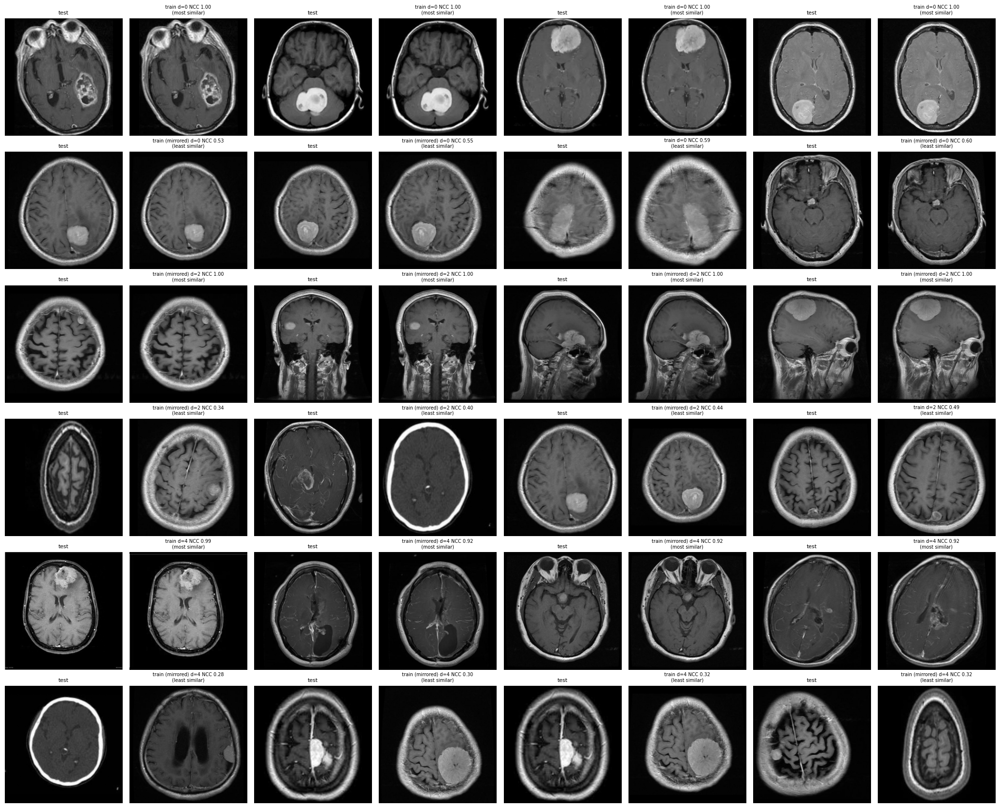


  7.7  SAVE
saved manifest_cell07.csv (adds stratum, pixel_ncc), cell07_twins.csv, cell07_val_twins.csv, cell07_summary.json

------------------------------------------------------------------------------
  [PASS]  null 1 never reaches NCC 0.95
  [PASS]  null 2 never reaches NCC 0.95
  [PASS]  no training set (nor validation) holds a pixel twin of a test image it must not see
  [PASS]  validation: pixel twins in the training sets <= 1%
  [NOTE]  537 of 1000 official test images have a near-identical training image (432 only mirrored); 247 more share a patient.
  [NOTE]  masks of pixel twins: median Dice 0.946 (534 pairs); near 1 means the test answer itself is in the training set.
------------------------------------------------------------------------------
CELL 7 CLEAN.


In [ ]:
# =============================================================================
#  CELL 7  |  Data: independent pixel verification, nulls, and contamination strata
# =============================================================================
assert "role" in df.columns and "TWA" in globals() and "TWT" in globals() and "twin_search" in globals(), "Run Cell 6 first."
assert json.loads((WORK / "cell04_cache.json").read_text()).get("gates_passed"), "The cache of Cell 4 did not pass its gates."

N_NULL = 3000       # random different-class pairs for the first null
THETA  = (0.80, 0.90, 0.95, 0.98)
N_SHOW = 4

import matplotlib.pyplot as plt
checks, notes = {}, []
N = len(df)
rng7 = np.random.default_rng(SEED)
role_a = df.role.to_numpy()
is_test = (df.split == "test").to_numpy(); n_test = int(is_test.sum())
official_train = df.split.eq("train").to_numpy()
test_idx, train_idx = np.where(is_test)[0], np.where(official_train)[0]
training_rows = np.where(np.isin(role_a, ["K", "C1", "C2"]))[0]

# A second candidate generator, independent of Cell 6's: gradient-magnitude descriptors and twice the candidates.
K2 = 20
def grad_vec(a, n=24):
    a = np.asarray(a, np.float32)
    return unit_vec(np.hypot(cv2.Sobel(a, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(a, cv2.CV_32F, 0, 1, ksize=3)), n)
VEC2 = np.stack([grad_vec(get_img(j)) for j in range(N)])
def twin_search2(i, pool):
    """Like Cell 6's twin_search, with the gradient descriptor and K2 candidates. Returns (best ncc, twins)."""
    pool = np.asarray(pool); pool = pool[pool != i]
    if len(pool) == 0:
        return -1.0, []
    a, af = get_img(i), get_img(i, flip=True)
    s1, s2 = VEC2[pool] @ grad_vec(a), VEC2[pool] @ grad_vec(af)
    best, tw = -1.0, []
    for o in np.argsort(-np.maximum(s1, s2))[:K2]:
        j, fl = int(pool[o]), bool(s2[o] > s1[o])
        v, dx, dy = ncc_best(af if fl else a, get_img(j))
        best = max(best, v)
        if v >= COPY_NCC:
            tw.append((j, v, fl, dx, dy))
    return best, tw

# ----- 7.1 hash candidates across the split, and two nulls ------------------------------------------------
banner("7.1  HASH CANDIDATES ACROSS THE OFFICIAL SPLIT, AND THE NULLS")
a_te, b_te = is_test[PAIRS.a.to_numpy()], is_test[PAIRS.b.to_numpy()]
cross = (a_te & official_train[PAIRS.b.to_numpy()]) | (official_train[PAIRS.a.to_numpy()] & b_te)
P = pd.DataFrame({"test": np.where(a_te, PAIRS.a, PAIRS.b)[cross], "train": np.where(a_te, PAIRS.b, PAIRS.a)[cross],
                  "d": PAIRS.d.to_numpy()[cross], "mir": PAIRS.mir.to_numpy()[cross], "ncc": PAIRS.ncc.to_numpy()[cross]})
print(f"{len(P)} hash candidates cross the official split")
print(pd.DataFrame([{"hash distance": int(t), "pairs": int((P.d == t).sum()), "median NCC": P.ncc[P.d == t].median(),
                     **{f">={th}": float((P.ncc[P.d == t] >= th).mean()) for th in THETA}} for t in sorted(P.d.unique())]).round(3).to_string(index=False))
IDS7 = ids_md5(df.image_id)
def null_random():
    out = []
    while len(out) < N_NULL:                    # random test-train pairs of the same plane and a different class
        i, j = int(rng7.choice(test_idx)), int(rng7.choice(train_idx))
        if pla6[j] == pla6[i] and lab6[j] != lab6[i]:
            out.append(ncc_best(get_img(i), get_img(j))[0])
    return np.array(out)
null = reuse("cell07_null1", {"what": "cell 7 null 1", "cache": CACHE_MD5, "ids": IDS7, "shift": NCC_SHIFT, "n": N_NULL,
                              "seed": SEED, "code": code_fp(null_random, ncc_best, get_img)}, null_random)
print(f"null 1 (random pairs, same plane, different class): p99 {np.percentile(null, 99):.3f}  max {null.max():.3f}   "
      f"share >= NEAR_NCC ({NEAR_NCC}): {(null >= NEAR_NCC).mean():.4f}")
if (null >= NEAR_NCC).mean() > 0.01:
    notes.append(f"more than 1% of random different-class pairs reach NEAR_NCC = {NEAR_NCC}: near-duplicate links (Cell 6) are "
                 "close to chance level on these data; read the 'related' stratum with care.")
checks[f"null 1 never reaches NCC {COPY_NCC}"] = float(null.max()) < COPY_NCC
# null 2: best match among traced training images of the SAME class and plane but a DIFFERENT source patient
pid_a = df.fig_pid.where(df.traced, None).to_numpy()
def null_patient():
    q_ = test_idx[pd.notna(pid_a[test_idx])]
    print(f"null 2: {len(q_)} traced test images, about {len(q_) * K2 * NCC_SEC / 60:.0f} min on this machine")
    out = []
    for i in q_:
        pool_ = train_idx[(lab6[train_idx] == lab6[i]) & (pla6[train_idx] == pla6[i]) & pd.notna(pid_a[train_idx])
                          & (pid_a[train_idx] != pid_a[i])]
        if len(pool_):
            out.append(twin_search2(int(i), pool_)[0])
    return np.array(out)
null2 = reuse("cell07_null2", {"what": "cell 7 null 2", "cache": CACHE_MD5, "ids": IDS7, "shift": NCC_SHIFT, "k2": K2,
                               "pid": ids_md5(df.fig_pid.where(df.traced, "").astype(str)),
                               "code": code_fp(null_patient, twin_search2, grad_vec, unit_vec, ncc_best, get_img)}, null_patient)
if len(null2):
    print(f"null 2 (best match, same class and plane, different source patient; {len(null2)} traced test images): "
          f"p99 {np.percentile(null2, 99):.3f}  max {null2.max():.3f}")
    checks[f"null 2 never reaches NCC {COPY_NCC}"] = float(null2.max()) < COPY_NCC
else:
    notes.append("null 2 (same class, different patient) could not be formed: no traced images.")

# ----- 7.2 an independent search: every class, every plane ------------------------------------------------
banner("7.2  INDEPENDENT SEARCH  (other descriptor: each test image against ALL official training images; validation too)")
cols_ = ["row", "twin_row", "ncc", "mirrored", "dx", "dy"]
def search_rows(queries, pool, what):
    print(f"{what}: {len(queries)} images x {K2} full-resolution checks, about {len(queries) * K2 * NCC_SEC / 60:.0f} min")
    out, t_ = [], time.time()
    for n_, i in enumerate(queries):
        _, tw = twin_search2(int(i), pool)
        out += [{"row": int(i), "twin_row": j, "ncc": v, "mirrored": fl, "dx": dx, "dy": dy} for j, v, fl, dx, dy in tw]
        if (n_ + 1) % 500 == 0:
            print(f"  {n_ + 1}/{len(queries)} ({time.time() - t_:.0f}s)")
    return pd.DataFrame(out, columns=cols_)
t0 = time.time()
key7 = {"cache": CACHE_MD5, "ids": IDS7, "shift": NCC_SHIFT, "k2": K2, "copy_ncc": COPY_NCC,
        "code": code_fp(search_rows, twin_search2, grad_vec, unit_vec, ncc_best, get_img)}
ALLTW = reuse("cell07_test_twins", {**key7, "what": "cell 7 test vs all official training images"},
              lambda: search_rows(test_idx, train_idx, "test images vs all official training images"))
VALTW = reuse("cell07_val_twins", {**key7, "what": "cell 7 validation vs training sets", "split": SPLIT_SIG},
              lambda: search_rows(np.where(role_a == "val")[0], training_rows, "validation images vs the training sets"))
VALTW = VALTW[cols_[:4]]
print(f"{time.time()-t0:.0f}s: {ALLTW.row.nunique()} test images and {VALTW.row.nunique()} validation images have a twin")
xc = ALLTW[lab6[ALLTW.row.to_numpy()] != lab6[ALLTW.twin_row.to_numpy()]] if len(ALLTW) else ALLTW
if len(xc):
    notes.append(f"{xc.row.nunique()} test images have a near-identical training image with a DIFFERENT class label "
                 "(label inconsistency; listed in cell07_twins.csv).")

# ----- 7.3 contamination stratum of every test image ----------------------------------------------------------
banner("7.3  CONTAMINATION STRATA OF THE OFFICIAL TEST SET")
# all twin evidence: Cell 6 from the test side AND from the training side, Cell 7, confirmed hash pairs
c4_ = ["row", "twin_row"]
rev6 = (TWA[official_train[TWA.row.to_numpy()] & is_test[TWA.twin_row.to_numpy()]]
        .rename(columns={"row": "twin_row", "twin_row": "row"}) if len(TWA) else TWA)
ev = pd.concat([TWT[c4_].assign(src="cell6"), rev6[c4_].assign(src="cell6-from-train"), ALLTW[c4_].assign(src="cell7"),
                P[P.ncc >= COPY_NCC].rename(columns={"test": "row", "train": "twin_row"})[c4_].assign(src="hash")],
               ignore_index=True)
ev = ev.groupby(c4_, as_index=False).agg(src=("src", lambda s_: "+".join(sorted(set(s_)))))
def orient_ncc():
    """Every (test, training) twin pair scored again in BOTH orientations and both directions, so 'plain' and
    'mirrored' do not depend on which orientation a search happened to prefer."""
    print(f"re-scoring {len(ev)} twin pairs in both orientations: about {4 * len(ev) * NCC_SEC / 60:.0f} min")
    out = []
    for t_, r_ in zip(ev.row.to_numpy(), ev.twin_row.to_numpy()):
        a, af, b = get_img(int(t_)), get_img(int(t_), flip=True), get_img(int(r_))
        out.append((max(ncc_best(a, b)[0], ncc_best(b, a)[0]), max(ncc_best(af, b)[0], ncc_best(b, af)[0])))
    return np.array(out, dtype=np.float64).reshape(-1, 2)
sc_ = reuse("cell07_orientation", {"what": "cell 7 twin pairs in both orientations", "cache": CACHE_MD5, "shift": NCC_SHIFT,
                                   "pairs": hashlib.md5(ev[c4_].to_numpy().astype(np.int64).tobytes()).hexdigest(),
                                   "code": code_fp(orient_ncc, ncc_best, get_img)}, orient_ncc)
ev["ncc_plain"], ev["ncc_mirror"] = sc_[:, 0], sc_[:, 1]
ev["ncc"] = ev[["ncc_plain", "ncc_mirror"]].max(axis=1)
ev["mirrored"] = (ev.ncc_plain < COPY_NCC) & (ev.ncc_mirror >= ev.ncc_plain)      # a twin ONLY in mirrored orientation
print(f"{len(ev)} (test, training) twin pairs, {ev.row.nunique()} test images; pairs near-identical in BOTH orientations "
      f"(near-symmetric slices): {int(((ev.ncc_plain >= COPY_NCC) & (ev.ncc_mirror >= COPY_NCC)).sum())}")
plain_rows = set(ev.row[~ev.mirrored]); any_rows = set(ev.row)
stratum = np.full(N, "", object)
stratum[is_test] = "unlinked"
stratum[is_test & df.test_linked.to_numpy()] = "related"
stratum[is_test & df.link_patient.to_numpy()] = "patient_only"
for r_ in any_rows:
    stratum[r_] = "copy_plain" if r_ in plain_rows else "copy_mirror"   # mirror only when no plain twin exists
df["stratum"] = stratum
df["pixel_ncc"] = np.nan
best_ev = ev.sort_values("ncc", ascending=False).drop_duplicates("row").set_index("row")
df.loc[best_ev.index, "pixel_ncc"] = best_ev.ncc
ST = ["copy_plain", "copy_mirror", "patient_only", "related", "unlinked"]
t = df[is_test]
print(pd.crosstab(t.label, t.stratum).reindex(columns=ST, fill_value=0).assign(all=lambda x: x.sum(axis=1)).to_string())
print("\ncopy_plain   : a training image with near-identical pixels (NCC >= 0.95) in the same orientation (maybe also mirrored)")
print("copy_mirror  : near-identical training images exist only MIRRORED (same-orientation NCC < 0.95 for every twin)")
print("patient_only : no pixel twin, same source patient (Cell 5) in the training set")
print(f"related      : linked only through near-duplicates (hash distance <= {NEAR_H}, NCC >= {NEAR_NCC}; likely an adjacent slice)")
print("unlinked     : no link of any kind to the official training set")
n_copy = int(np.isin(stratum, ["copy_plain", "copy_mirror"]).sum())
notes.append(f"{n_copy} of {n_test} official test images have a near-identical training image "
             f"({int((stratum == 'copy_mirror').sum())} only mirrored); {int((stratum == 'patient_only').sum())} more share a patient.")

# ----- 7.4 are the training sets of Cell 6 blind where they must be? -------------------------------------------
banner("7.4  VALIDITY OF THE TRAINING SETS  (pixel twins the groups did not catch; must be 0)")
exposure = {"Full": df.test_linked.to_numpy(), "B": np.zeros(N, bool),
            "X1": (df.test_linked & (df.half == 1)).to_numpy(), "X2": (df.test_linked & (df.half == 2)).to_numpy(),
            "val": np.zeros(N, bool)}
member = {"Full": df.in_full.to_numpy(), "B": df.in_B.to_numpy(), "X1": df.in_X1.to_numpy(), "X2": df.in_X2.to_numpy(),
          "val": (df.role == "val").to_numpy()}
vrows = []
for k in exposure:
    m_ = member[k][ev.twin_row.to_numpy().astype(int)]
    rows_with = set(ev.row[m_])
    missed = [r_ for r_ in rows_with if not exposure[k][int(r_)]]
    vrows.append({"set": k, "test images with a pixel twin in the set": len(rows_with), "of which the set should be blind to": len(missed)})
VT = pd.DataFrame(vrows); print(VT.to_string(index=False))
checks["no training set (nor validation) holds a pixel twin of a test image it must not see"] = int(VT.iloc[:, 2].max()) == 0
nv = VALTW.row.nunique(); n_val = int((role_a == "val").sum())
print(f"validation images with a pixel twin in the training sets: {nv} of {n_val}")
checks["validation: pixel twins in the training sets <= 1%"] = nv <= 0.01 * max(n_val, 1)

# ----- 7.5 twins by class and plane; masks of twins ----------------------------------------------------------
banner("7.5  TWINS BY CLASS AND PLANE; MASKS OF TWINS")
t = df[is_test].copy(); t["twin"] = t.stratum.isin(["copy_plain", "copy_mirror"]); t["mirror_only"] = t.stratum.eq("copy_mirror")
print(t.groupby("label").agg(images=("twin", "size"), twin=("twin", "mean"), mirror_only=("mirror_only", "mean")).round(3).to_string())
print(t.groupby("plane").agg(images=("twin", "size"), twin=("twin", "mean"), mirror_only=("mirror_only", "mean")).round(3).to_string())
mk_ev = pd.concat([TWT, ALLTW]).sort_values(["row", "mirrored", "ncc"], ascending=[True, True, False]).drop_duplicates("row")
dsc = []
for _, w_ in mk_ev.iterrows():
    al = align(np.asarray(MKc[int(w_.twin_row)]), int(w_.dx), int(w_.dy))          # into the (mirrored) query frame
    al = al[:, ::-1] if w_.mirrored else al                                         # back into the test image's frame
    a_, b_ = MKc[int(w_.row)] > 0, al > 0
    if a_.any() and b_.any():
        dsc.append({"mirrored": bool(w_.mirrored), "dice": 2 * (a_ & b_).sum() / (a_.sum() + b_.sum())})
dsc = pd.DataFrame(dsc, columns=["mirrored", "dice"])
if len(dsc):
    print("\nDice between a test mask and its training twin's mask (aligned; mirrored back when the twin is mirrored):")
    print(dsc.groupby("mirrored").dice.agg(pairs="size", median="median", share_ge_0_9=lambda x: (x >= 0.9).mean()).round(3).to_string())
    notes.append(f"masks of pixel twins: median Dice {dsc.dice.median():.3f} ({len(dsc)} pairs); near 1 means the test answer "
                 "itself is in the training set.")

# ----- 7.6 figure --------------------------------------------------------------------------------------------------
dists = [d_ for d_ in (0, 2, 4) if (P.d == d_).any()]
fig, axes = plt.subplots(max(1, 2 * len(dists)), 2 * N_SHOW, figsize=(2.6 * 2 * N_SHOW, 2.8 * max(1, 2 * len(dists))), squeeze=False)
for ax_ in axes.ravel():
    ax_.axis("off")
for n_, d_ in enumerate(dists):
    sub = P[P.d == d_].sort_values("ncc", ascending=False)
    for r_off, grp_, tag in ((0, sub.head(N_SHOW), "most similar"), (1, sub.tail(N_SHOW).iloc[::-1], "least similar")):
        for k, (_, row) in enumerate(grp_.iterrows()):
            axes[2 * n_ + r_off, 2 * k].imshow(get_img(int(row.test)), cmap="gray"); axes[2 * n_ + r_off, 2 * k].set_title("test", fontsize=8)
            axes[2 * n_ + r_off, 2 * k + 1].imshow(get_img(int(row.train), flip=bool(row.mir)), cmap="gray")
            axes[2 * n_ + r_off, 2 * k + 1].set_title(f"train{' (mirrored)' if row.mir else ''} d={d_} NCC {row.ncc:.2f}\n({tag})", fontsize=7)
plt.tight_layout(); plt.savefig(WORK / "cell07_pairs.png", dpi=90, bbox_inches="tight"); plt.show()

# ----- 7.7 save ------------------------------------------------------------------------------------------------------
banner("7.7  SAVE")
df.to_csv(WORK / "manifest_cell07.csv", index=False)
ev.to_csv(WORK / "cell07_twins.csv", index=False); VALTW.to_csv(WORK / "cell07_val_twins.csv", index=False)
save_json(WORK / "cell07_summary.json", {
    "confirm_ncc": COPY_NCC, "null1_max": float(null.max()), "null2_max": float(null2.max()) if len(null2) else None,
    "strata": df[is_test].stratum.value_counts().to_dict(), "validity": VT.to_dict("records"), "val_twins": int(nv),
    "cross_class_twins": int(xc.row.nunique()) if len(xc) else 0,
    "twin_mask_dice_median": float(dsc.dice.median()) if len(dsc) else None})
print("saved manifest_cell07.csv (adds stratum, pixel_ncc), cell07_twins.csv, cell07_val_twins.csv, cell07_summary.json")
finish(7, checks, notes)

# C. Learning

## Cell 8 | Augmentation, normalisation, Dataset and DataLoader

**Purpose.** The data pipeline of every run: one affine transform for image and mask (rotation +-15 deg, scale +-10%, shift +-5%), horizontal flip as a **per-run switch** (Q2b), gamma 0.7-1.5, and a z-score computed on tissue pixels only (so padding cannot shift tissue intensities). A fresh augmentation on every call, reproducible from (seed, epoch). `make_planes` provides the true plane or the placebo (a fixed permutation of the plane labels, Q3).

**Inputs.** Cache, manifest. **Outputs.** `augment, fg_znorm, BriscDataset, make_loader, make_planes, PLANE_TRUE`; `cell08_batch.png`.

**Pass criteria.** (1) The mask follows the image (p95 centroid drift < 2 px). (2) `flip=False` never mirrors; `flip=True` mirrors 35-65% of the time. (3) Gamma changes the normalised input. (4) Every image gets a new augmentation every epoch, through a real loader. (5) Placebo planes keep the plane counts and agree with the true plane near chance. (6) Batch contract: shapes, binary masks, label and plane ranges, no NaN.


  8.1  AUGMENTATION + NORMALISATION
flip p=0.5 (per-run switch) | rotate +-15 deg | scale +-10% | shift +-5% | gamma 0.7-1.5 p=0.3 | tissue z-score

  8.3  PROOF: the mask stays on the tumour through augmentation
image/mask centroid drift over 400 samples: median 0.116 px  p95 0.442 px

  8.4  PROOF: flip=False never mirrors; flip=True mirrors about half the time
mirrored outputs: flip=False 0.000   flip=True 0.413

  8.5  PROOF: gamma survives the tissue z-score
mean |change| of the normalised tissue after gamma: median 0.0435 z

  8.6  PROOF: each image gets a NEW augmentation every epoch
fewest distinct views of one image over 3 epochs: {0: 3, 2: 3}  (3 = new every epoch)

  8.7  PLACEBO PLANES  (Question 3)
shuffled vs true plane: same counts [1993, 1981, 2026] vs [1993, 1981, 2026]; agreement 0.323 (chance 0.333)

  8.8  BATCH CONTRACT
  ok   image (B,3,S,S) float32
  ok   mask (B,1,S,S) binary
  ok   labels 0..3, planes 0..2
  ok   no NaN


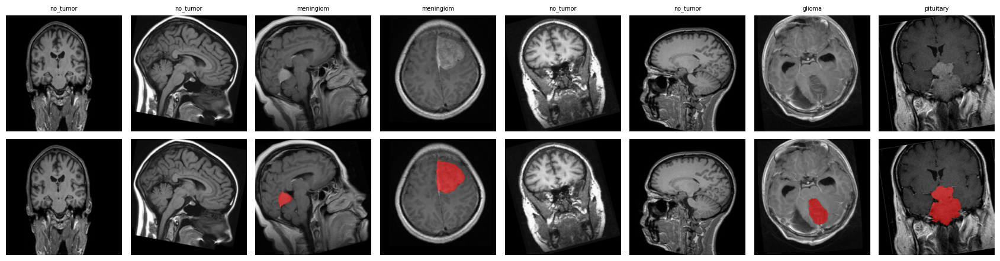


------------------------------------------------------------------------------
  [PASS]  mask follows image through augmentation (p95 drift < 2 px)
  [PASS]  flip switch: 0% mirrored when off, 35-65% when on
  [PASS]  gamma changes the normalised input (median > 0.01 z)
  [PASS]  fresh augmentation every epoch
  [PASS]  placebo planes keep the plane counts and are near chance agreement
  [PASS]  batch contract
------------------------------------------------------------------------------
CELL 8 CLEAN.


In [ ]:
# =============================================================================
#  CELL 8  |  Learning: augmentation, normalisation, Dataset and DataLoader
# =============================================================================
assert "stratum" in df.columns and "IMc" in globals(), "Run Cells 4-7 first."

BATCH     = 32
WORKERS   = 2
MAX_ROT   = 15        # degrees
MAX_SCALE = 0.10      # +-10%
MAX_SHIFT = 0.05      # +-5% of the frame
P_FLIP    = 0.5       # used only when a run has flip=True (Cell 11 switches it per arm)
P_GAMMA   = 0.3       # nnU-Net's default probability
GAMMA     = (0.7, 1.5)
FG_THR    = 10        # tissue threshold, the same as the brain crop of Cell 4
MIN_FG    = 64        # below this many tissue pixels the whole frame gives the statistics

import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
checks, notes = {}, []
rng8 = np.random.default_rng(SEED)

# ----- 8.1 augmentation and normalisation ------------------------------------------
banner("8.1  AUGMENTATION + NORMALISATION")
def affine_matrix(ang, sc, tx, ty, size=SIZE):
    M = cv2.getRotationMatrix2D((size / 2.0, size / 2.0), ang, sc)
    M[0, 2] += tx; M[1, 2] += ty
    return M

def gamma_lut(g):
    return np.clip(255.0 * (np.arange(256) / 255.0) ** g + 0.5, 0, 255).astype(np.uint8)

def augment(img, msk, rng, flip=True, photometric=True):
    """One geometry for image and mask. Returns (img, msk, tissue mask taken before gamma)."""
    coin = rng.random()                    # always drawn, so flip-on and flip-off runs share every other random draw
    if flip and coin < P_FLIP:
        img, msk = img[:, ::-1], msk[:, ::-1]
    img, msk = np.ascontiguousarray(img), np.ascontiguousarray(msk)
    M = affine_matrix(float(rng.uniform(-MAX_ROT, MAX_ROT)), float(1.0 + rng.uniform(-MAX_SCALE, MAX_SCALE)),
                      float(rng.uniform(-MAX_SHIFT, MAX_SHIFT) * SIZE), float(rng.uniform(-MAX_SHIFT, MAX_SHIFT) * SIZE))
    img = cv2.warpAffine(img, M, (SIZE, SIZE), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    msk = cv2.warpAffine(msk, M, (SIZE, SIZE), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    fg = img > FG_THR
    if photometric and rng.random() < P_GAMMA:
        img = gamma_lut(float(np.exp(rng.uniform(np.log(GAMMA[0]), np.log(GAMMA[1])))))[img]
    return img, msk, fg

def fg_znorm(u8, fg=None):
    """z-score with TISSUE statistics, applied to the whole frame (padding cannot shift tissue intensities)."""
    x = u8.astype(np.float32)
    fg = u8 > FG_THR if fg is None else fg
    v = x[fg] if int(fg.sum()) >= MIN_FG else x.ravel()
    return (x - v.mean()) / (v.std() + 1e-6)

PLANE_TRUE = df.plane.map(PLANE_IDX).to_numpy()
def make_planes(mode, seed):
    """Plane index fed to FiLM for every row of df. 'true' = the file-name plane; 'shuffled' = a fixed random
    permutation of those labels (same marginal distribution, no link to the image): the placebo of Question 3."""
    if mode == "shuffled":
        return np.random.default_rng(seed + 99991).permutation(PLANE_TRUE)
    return PLANE_TRUE.copy()

print(f"flip p={P_FLIP} (per-run switch) | rotate +-{MAX_ROT} deg | scale +-{MAX_SCALE:.0%} | shift +-{MAX_SHIFT:.0%} | "
      f"gamma {GAMMA[0]}-{GAMMA[1]} p={P_GAMMA} | tissue z-score")

# ----- 8.2 dataset and loaders ------------------------------------------------------------------
class BriscDataset(Dataset):
    """Serves the memmapped cache. Training samples get a NEW augmentation on every call: the seed comes from the
    worker's torch stream, which the runner reseeds from (run seed, epoch), so a resumed run repeats exactly."""
    def __init__(self, rows, train=False, flip=True, planes=None):
        self.rows, self.train, self.flip = np.asarray(rows), train, flip
        self.planes = PLANE_TRUE if planes is None else np.asarray(planes)
        self.label, self.hasm = df.label_idx.to_numpy(), df.has_mask.to_numpy().astype(bool)
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, k):
        r = int(self.rows[k])
        img, msk = np.asarray(IMc[r]), np.asarray(MKc[r])
        if self.train:
            img, msk, fg = augment(img, msk, np.random.default_rng(int(torch.randint(0, 2 ** 62, (1,)).item())), flip=self.flip)
        else:
            fg = img > FG_THR
        x = fg_znorm(img, fg)[None]
        return {"image": torch.from_numpy(np.repeat(x, 3, 0)).float(), "mask": torch.from_numpy(msk[None].astype(np.float32)),
                "label": torch.tensor(int(self.label[r])), "plane": torch.tensor(int(self.planes[r])),
                "has_mask": torch.tensor(bool(self.hasm[r])), "row": torch.tensor(r)}

def seed_worker(_):
    np.random.seed(torch.initial_seed() % (2 ** 32))

def make_loader(ds, shuffle, generator=None, workers=WORKERS, persistent=False, drop_last=False):
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=workers, pin_memory=torch.cuda.is_available(),
                      drop_last=drop_last, worker_init_fn=seed_worker, generator=generator,
                      persistent_workers=persistent and workers > 0)

# ----- 8.3 PROOF: the mask follows the image -----------------------------------------------------
banner("8.3  PROOF: the mask stays on the tumour through augmentation")
pool = df.index[df.has_mask].to_numpy(); drift = []
for i in rng8.choice(pool, size=min(400, len(pool)), replace=False):
    img, msk = np.asarray(IMc[i]), np.asarray(MKc[i])
    marked = np.minimum(img, 200).astype(np.uint8); marked[msk > 0] = 255
    a_img, a_msk, _ = augment(marked, msk, np.random.default_rng(int(i)), photometric=False)
    bright = a_img >= 225
    if a_msk.sum() == 0 or bright.sum() < 5:
        continue
    by, bx = np.nonzero(bright); my, mx = np.nonzero(a_msk > 0)
    drift.append(float(np.hypot(bx.mean() - mx.mean(), by.mean() - my.mean())))
drift = np.array(drift)
print(f"image/mask centroid drift over {len(drift)} samples: median {np.median(drift):.3f} px  p95 {np.percentile(drift, 95):.3f} px")
checks["mask follows image through augmentation (p95 drift < 2 px)"] = bool(np.percentile(drift, 95) < 2.0)

# ----- 8.4 PROOF: the flip switch works ------------------------------------------------------------
banner("8.4  PROOF: flip=False never mirrors; flip=True mirrors about half the time")
probe_img = np.zeros((SIZE, SIZE), np.uint8); probe_img[:, : SIZE // 3] = 200; probe_img[:, SIZE // 3:] = 30
def flipped_share(flag, n=300):
    k = 0
    for s in range(n):
        out, _, _ = augment(probe_img, np.zeros_like(probe_img), np.random.default_rng(s), flip=flag, photometric=False)
        k += int(out[:, SIZE // 2:].mean() > out[:, : SIZE // 2].mean())
    return k / n
f_off, f_on = flipped_share(False), flipped_share(True)
print(f"mirrored outputs: flip=False {f_off:.3f}   flip=True {f_on:.3f}")
checks["flip switch: 0% mirrored when off, 35-65% when on"] = (f_off == 0.0 and 0.35 <= f_on <= 0.65)

# ----- 8.5 PROOF: the intensity augmentation reaches the normalised input --------------------------
banner("8.5  PROOF: gamma survives the tissue z-score")
d_new = []
for i in rng8.choice(len(df), size=200, replace=False):
    img = np.asarray(IMc[i]); fg = img > FG_THR
    if fg.sum() < MIN_FG:
        continue
    g = float(np.exp(rng8.uniform(np.log(GAMMA[0]), np.log(GAMMA[1]))))
    d_new.append(np.abs(fg_znorm(gamma_lut(g)[img], fg) - fg_znorm(img, fg))[fg].mean())
print(f"mean |change| of the normalised tissue after gamma: median {np.median(d_new):.4f} z")
checks["gamma changes the normalised input (median > 0.01 z)"] = bool(np.median(d_new) > 0.01)

# ----- 8.6 PROOF: fresh augmentation every epoch, through a real loader ---------------------------
banner("8.6  PROOF: each image gets a NEW augmentation every epoch")
probe = BriscDataset(df.index[df.in_B][:48], train=True)
def distinct_views(workers, epochs=3):
    gp = torch.Generator(); gp.manual_seed(SEED); seen = {}
    dl = DataLoader(probe, batch_size=16, shuffle=True, num_workers=workers, worker_init_fn=seed_worker, generator=gp)
    for _ in range(epochs):
        for b in dl:
            for r, im in zip(b["row"].tolist(), b["image"]):
                seen.setdefault(r, set()).add(hashlib.md5(im.numpy().tobytes()).hexdigest())
    return np.array([len(v) for v in seen.values()])
fresh = {w: int(distinct_views(w).min()) for w in sorted({0, WORKERS})}
print(f"fewest distinct views of one image over 3 epochs: {fresh}  (3 = new every epoch)")
checks["fresh augmentation every epoch"] = all(v == 3 for v in fresh.values())

# ----- 8.7 the placebo planes ----------------------------------------------------------------------------
banner("8.7  PLACEBO PLANES  (Question 3)")
shuf = make_planes("shuffled", SEED)
agree = float((shuf == PLANE_TRUE).mean())
print(f"shuffled vs true plane: same counts {np.bincount(shuf).tolist()} vs {np.bincount(PLANE_TRUE).tolist()}; "
      f"agreement {agree:.3f} (chance {float(sum((np.bincount(PLANE_TRUE) / len(PLANE_TRUE)) ** 2)):.3f})")
checks["placebo planes keep the plane counts and are near chance agreement"] = (
    np.array_equal(np.bincount(shuf), np.bincount(PLANE_TRUE)) and agree < 0.45)

# ----- 8.8 batch contract and a look ------------------------------------------------------------------------
banner("8.8  BATCH CONTRACT")
b = next(iter(make_loader(BriscDataset(df.index[df.in_B], train=True), shuffle=True, workers=0)))
ok = {"image (B,3,S,S) float32": b["image"].shape[1:] == (3, SIZE, SIZE) and b["image"].dtype == torch.float32,
      "mask (B,1,S,S) binary": b["mask"].shape[1:] == (1, SIZE, SIZE) and bool(torch.isin(b["mask"], torch.tensor([0.0, 1.0])).all()),
      "labels 0..3, planes 0..2": bool((b["label"] >= 0).all() and (b["label"] <= 3).all() and (b["plane"] >= 0).all() and (b["plane"] <= 2).all()),
      "no NaN": bool(torch.isfinite(b["image"]).all())}
for k, v in ok.items():
    print(f"  {'ok ' if v else 'BAD'}  {k}")
checks["batch contract"] = all(ok.values())
fig, ax = plt.subplots(2, 8, figsize=(17, 4.6))
for j in range(min(8, len(b["label"]))):
    im, mk = b["image"][j, 0].numpy(), b["mask"][j, 0].numpy()
    ax[0, j].imshow(im, cmap="gray"); ax[0, j].set_title(IDX_LABEL[int(b["label"][j])][:9], fontsize=7)
    ax[1, j].imshow(im, cmap="gray")
    if mk.sum() > 0:
        ax[1, j].imshow(np.ma.masked_where(mk == 0, mk), cmap="autumn", alpha=0.55)
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.savefig(WORK / "cell08_batch.png", dpi=100, bbox_inches="tight"); plt.show()
finish(8, checks, notes)

## Cell 9 | The network

**Purpose.** One multi-task network: ImageNet-pretrained ResNet-50 encoder; U-Net decoder with attention gates on the skip connections; a classification head on the pooled deepest feature. Optional plane FiLM: a per-plane scale and shift of the deepest feature, zero-initialised, feeding **both** the decoder and the classifier. The segmentation bias starts at -4 (sigmoid ~ 1.8%, the tumour prior).

**Inputs.** None (weights from torchvision). **Outputs.** `build_model(film_mode)`, `SEC_PER_STEP` (speed, used by Cell 11).

**Pass criteria.** (1) Wiring: with FiLM the plane changes both outputs; without FiLM it changes neither. (2) Output shapes. (3) Every parameter receives a finite gradient.

In [ ]:
# =============================================================================
#  CELL 9  |  Learning: the multi-task network (ResNet-50 encoder, U-Net decoder,
#             classification head, optional plane FiLM)
# =============================================================================
assert "BriscDataset" in globals(), "Run Cell 8 first."

BACKBONE   = "resnet50"
PRETRAINED = not SMOKE          # ImageNet weights (torchvision IMAGENET1K_V2); the smoke test runs offline
DEC_CH     = (256, 128, 64, 32, 16)
DEC_DROP   = 0.10
CLS_DROP   = 0.50
NUM_CLASSES, NUM_PLANES = 4, 3

import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
DEV = "cuda" if torch.cuda.is_available() else "cpu"
checks, notes = {}, []

# ----- 9.1 blocks ----------------------------------------------------------------------
class PlaneFiLM(nn.Module):
    """gamma/beta per plane. The condition takes 3 values, so a lookup table IS the complete function space
    (an MLP would only spend parameters). Zero-initialised: identity at step 0."""
    def __init__(self, num_planes=NUM_PLANES, channels=2048):
        super().__init__()
        self.table = nn.Embedding(num_planes, 2 * channels); nn.init.zeros_(self.table.weight)
    def forward(self, plane, feat):
        g, b = self.table(plane).chunk(2, dim=1)
        return feat * (1.0 + g[:, :, None, None]) + b[:, :, None, None]

class AttentionGate(nn.Module):
    def __init__(self, gate_ch, skip_ch, inter_ch):
        super().__init__()
        self.wg = nn.Conv2d(gate_ch, inter_ch, 1, bias=False); self.wx = nn.Conv2d(skip_ch, inter_ch, 1, bias=False)
        self.psi = nn.Conv2d(inter_ch, 1, 1); nn.init.zeros_(self.psi.weight); nn.init.zeros_(self.psi.bias)
    def forward(self, gate, skip):
        return skip * torch.sigmoid(self.psi(F.relu(self.wg(gate) + self.wx(skip))))

class DecBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch, p_drop=DEC_DROP):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.att = AttentionGate(out_ch, skip_ch, max(out_ch // 2, 8)) if skip_ch > 0 else None
        self.conv = nn.Sequential(nn.Conv2d(out_ch + skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch),
                                  nn.ReLU(inplace=True), nn.Dropout2d(p_drop),
                                  nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x, skip=None):
        x = self.up(x)
        if skip is not None:
            x = torch.cat([x, self.att(x, skip)], 1)
        return self.conv(x)

# ----- 9.2 the network -------------------------------------------------------------------
class BriscNet(nn.Module):
    """film_mode 'off': no conditioning. 'both': FiLM modulates the deepest feature, and that ONE tensor feeds the
    decoder AND the classifier (an earlier model applied it to the classifier only; 9.3 makes that impossible)."""
    def __init__(self, film_mode="off", pretrained=PRETRAINED):
        super().__init__()
        assert film_mode in ("off", "both"), film_mode
        self.film_mode = film_mode
        net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu); self.pool = net.maxpool
        self.l1, self.l2, self.l3, self.l4 = net.layer1, net.layer2, net.layer3, net.layer4
        self.film = PlaneFiLM(NUM_PLANES, 2048) if film_mode == "both" else None
        d0, d1, d2, d3, d4 = DEC_CH
        self.dec4, self.dec3 = DecBlock(2048, 1024, d0), DecBlock(d0, 512, d1)
        self.dec2, self.dec1, self.dec0 = DecBlock(d1, 256, d2), DecBlock(d2, 64, d3), DecBlock(d3, 0, d4)
        self.seg_head = nn.Conv2d(d4, 1, 1)
        nn.init.constant_(self.seg_head.bias, -4.0)       # sigmoid(-4) ~ 1.8%, the tumour prior; weight left at default
        self.cls_head = nn.Sequential(nn.Dropout(CLS_DROP), nn.Linear(2048, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True),
                                      nn.Dropout(CLS_DROP), nn.Linear(256, NUM_CLASSES))
    def forward(self, x, plane):
        s0 = self.stem(x); s1 = self.l1(self.pool(s0)); s2 = self.l2(s1); s3 = self.l3(s2); f4 = self.l4(s3)
        if self.film is not None:
            f4 = self.film(plane, f4)
        d = self.dec0(self.dec1(self.dec2(self.dec3(self.dec4(f4, s3), s2), s1), s0), None)
        return self.seg_head(d), self.cls_head(F.adaptive_avg_pool2d(f4, 1).flatten(1))

def build_model(film_mode="off", pretrained=PRETRAINED):
    return BriscNet(film_mode, pretrained)

banner("9.1  BUILD")
try:
    model = build_model("both").to(DEV)
except Exception as e:
    raise RuntimeError(f"could not build the network ({type(e).__name__}: {e}). If the ImageNet weights failed to "
                       "download, check the internet connection of the runtime; do NOT train from scratch silently.")
n_par = sum(p.numel() for p in model.parameters())
groups_ = {"encoder": sum(p.numel() for m_ in (model.stem, model.l1, model.l2, model.l3, model.l4) for p in m_.parameters()),
           "film": sum(p.numel() for p in model.film.parameters()),
           "decoder": sum(p.numel() for m_ in (model.dec4, model.dec3, model.dec2, model.dec1, model.dec0, model.seg_head) for p in m_.parameters()),
           "classifier": sum(p.numel() for p in model.cls_head.parameters())}
print(f"backbone {BACKBONE} (ImageNet weights: {PRETRAINED}), device {DEV}, parameters {n_par:,}")
for k, v in groups_.items():
    print(f"  {k:10s} {v:12,}  {v / n_par:6.2%}")

# ----- 9.3 wiring test: does the plane reach both heads? --------------------------------------------
banner("9.3  WIRING TEST  (same image, two plane indices)")
def plane_effect(mode):
    torch.manual_seed(0)
    m_ = build_model(mode, pretrained=False).to(DEV).eval()
    with torch.no_grad():
        m_.seg_head.weight.normal_(0, 0.1)                       # make the near-constant head visible to the test
        if m_.film is not None:
            m_.film.table.weight.normal_(0, 0.5)                 # break the identity initialisation
    x = torch.randn(2, 3, SIZE, SIZE, device=DEV)
    with torch.no_grad():
        s0, c0 = m_(x, torch.zeros(2, dtype=torch.long, device=DEV))
        s1, c1 = m_(x, torch.ones(2, dtype=torch.long, device=DEV))
    return float((s1 - s0).abs().max()), float((c1 - c0).abs().max())
w_off, w_both = plane_effect("off"), plane_effect("both")
print(f"off : seg change {w_off[0]:.2e}  cls change {w_off[1]:.2e}   (both must be exactly 0)")
print(f"both: seg change {w_both[0]:.2e}  cls change {w_both[1]:.2e}   (both must be > 0)")
checks["FiLM 'both' reaches the decoder and the classifier; 'off' ignores the plane"] = (
    w_off == (0.0, 0.0) and w_both[0] > 0 and w_both[1] > 0)

# ----- 9.4 shapes, gradients, initial prior ------------------------------------------------------------------
banner("9.4  SHAPES, GRADIENTS, INITIAL OUTPUT")
model.train()
x = torch.randn(2, 3, SIZE, SIZE, device=DEV); p = torch.tensor([0, 2], device=DEV)
seg, cls = model(x, p)
(seg.mean() + cls.mean()).backward()
no_grad = [n for n, q in model.named_parameters() if q.requires_grad and (q.grad is None or not torch.isfinite(q.grad).all())]
with torch.no_grad():
    model.eval(); prior = float(torch.sigmoid(model(x, p)[0]).mean())
model.zero_grad(set_to_none=True)
print(f"seg {tuple(seg.shape)}  cls {tuple(cls.shape)}   parameters without a finite gradient: {len(no_grad)}   "
      f"mean sigmoid(seg) at init {prior:.4f} (bias -4 -> 0.018)")
checks["output shapes are right"] = seg.shape == (2, 1, SIZE, SIZE) and cls.shape == (2, NUM_CLASSES)
checks["every parameter receives a finite gradient"] = len(no_grad) == 0

# ----- 9.5 speed --------------------------------------------------------------------------------------------
banner("9.5  SPEED")
SEC_PER_STEP = None
if DEV == "cuda":
    model.train(); xb = torch.randn(BATCH, 3, SIZE, SIZE, device=DEV); pb = torch.randint(0, 3, (BATCH,), device=DEV)
    sc_ = torch.amp.GradScaler("cuda"); opt_ = torch.optim.AdamW(model.parameters(), lr=1e-5)
    for k in range(7):
        if k == 2:
            torch.cuda.synchronize(); t0 = time.time()
        with torch.amp.autocast("cuda"):
            s_, c_ = model(xb, pb); l_ = s_.float().mean() + c_.float().mean()
        opt_.zero_grad(); sc_.scale(l_).backward(); sc_.step(opt_); sc_.update()
    torch.cuda.synchronize(); SEC_PER_STEP = (time.time() - t0) / 5
    print(f"batch {BATCH} with mixed precision: {SEC_PER_STEP * 1000:.0f} ms per training step; "
          f"peak memory {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
    del opt_, sc_
else:
    print("no GPU: speed not measured")
del model
if DEV == "cuda":
    torch.cuda.empty_cache()
finish(9, checks, notes)


  9.1  BUILD
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 242MB/s]


backbone resnet50 (ImageNet weights: True), device cuda, parameters 31,223,289
  encoder      23,508,032  75.29%
  film             12,288   0.04%
  decoder       7,176,885  22.99%
  classifier      526,084   1.68%

  9.3  WIRING TEST  (same image, two plane indices)
off : seg change 0.00e+00  cls change 0.00e+00   (both must be exactly 0)
both: seg change 2.05e-05  cls change 1.70e+01   (both must be > 0)

  9.4  SHAPES, GRADIENTS, INITIAL OUTPUT
seg (2, 1, 256, 256)  cls (2, 4)   parameters without a finite gradient: 0   mean sigmoid(seg) at init 0.0183 (bias -4 -> 0.018)

  9.5  SPEED
batch 32 with mixed precision: 273 ms per training step; peak memory 3.65 GB

------------------------------------------------------------------------------
  [PASS]  FiLM 'both' reaches the decoder and the classifier; 'off' ignores the plane
  [PASS]  output shapes are right
  [PASS]  every parameter receives a finite gradient
---------------------------------------------------------------------------

## Cell 10 | Loss, metrics, training and prediction functions

**Purpose.** L = L_seg + L_cls. L_seg = per-sample soft Dice + BCE on tumour images, plus BCE against an empty target on tumour-free images (`SEG_ON_EMPTY`: the head must learn that "no tumour" is an answer; Dice is never computed on an empty target). L_cls = cross-entropy. No hidden terms. Selection rule, fixed before any run: the epoch with the best 0.5 macro-F1 + 0.5 Dice on validation.

**Inputs.** Cells 8-9. **Outputs.** `total_loss, seg_metrics, macro_f1, run_epoch, WarmupCosine, score_of, predict`.

**Pass criteria.** (1) Loss and metric unit tests with known answers. (2) Real runs only: the whole chain memorises one batch (accuracy > 0.95, Dice > 0.80, tumour-free images nearly empty).

In [ ]:
# =============================================================================
#  CELL 10  |  Learning: loss, metrics, training and prediction functions (tested)
# =============================================================================
assert "build_model" in globals(), "Run Cell 9 first."

W_SEG, W_CLS   = 1.0, 1.0      # task weights
W_DICE, W_BCE  = 1.0, 1.0      # BCE carries the early signal: Dice's gradient is tiny at the cold start
W_EMPTY        = 1.0           # BCE on tumour-free images (all-zero target)
SEG_ON_EMPTY   = True          # decision: the segmentation head is also taught that "no tumour" is an answer
AMP            = True
GRAD_CLIP      = 1.0
OVERFIT_STEPS  = 60 if SMOKE else 150

checks, notes = {}, []
def amp_ctx():
    return torch.amp.autocast("cuda", enabled=(AMP and DEV == "cuda")) if DEV == "cuda" else torch.autocast("cpu", enabled=False)

# ----- 10.1 losses -------------------------------------------------------------------------
banner("10.1  LOSSES")
def dice_loss_per_sample(logits, target, eps=1.0):
    """Soft Dice per sample, then averaged (matches the per-image Dice that is reported)."""
    p, t = torch.sigmoid(logits).flatten(1), target.flatten(1)
    return 1.0 - (2.0 * (p * t).sum(1) + eps) / (p.sum(1) + t.sum(1) + eps)

def seg_loss_fn(logits, target, has_mask):
    """Tumour images: Dice + BCE. Tumour-free images: W_EMPTY * BCE against an all-zero target when SEG_ON_EMPTY
    (Dice is never computed on an empty target: its gradient is almost flat on a large false mask)."""
    loss, parts = None, {"dloss": 0.0, "bce": 0.0, "bce_neg": 0.0, "seg_masked": 0.0}
    if has_mask.any():
        l, t = logits[has_mask], target[has_mask]
        d, b = dice_loss_per_sample(l, t).mean(), F.binary_cross_entropy_with_logits(l, t)
        loss = W_DICE * d + W_BCE * b
        parts.update(dloss=float(d.detach()), bce=float(b.detach()), seg_masked=float(loss.detach()))
    if (~has_mask).any():
        ln = logits[~has_mask]
        bn = F.binary_cross_entropy_with_logits(ln, torch.zeros_like(ln))
        parts["bce_neg"] = float(bn.detach())
        if SEG_ON_EMPTY:
            loss = W_EMPTY * bn if loss is None else loss + W_EMPTY * bn
    return (logits.sum() * 0.0 if loss is None else loss), parts

def total_loss(seg_logits, mask, cls_logits, label, has_mask):
    ls, parts = seg_loss_fn(seg_logits, mask, has_mask)
    lc = F.cross_entropy(cls_logits, label)
    tot = W_SEG * ls + W_CLS * lc
    return tot, {"total": float(tot.detach()), "seg": float(ls.detach()), "cls": float(lc.detach()), **parts}

print(f"L = {W_SEG} L_seg + {W_CLS} L_cls;  L_seg = {W_DICE} Dice + {W_BCE} BCE on tumour images"
      f"{f' + {W_EMPTY} BCE on tumour-free images' if SEG_ON_EMPTY else ''};  L_cls = cross-entropy. No hidden terms.")

# ----- 10.2 metrics ----------------------------------------------------------------------------
@torch.no_grad()
def seg_metrics(logits, target, thr=0.5):
    """Per-sample Dice and IoU at a fixed threshold."""
    p, t = (torch.sigmoid(logits) > thr).float().flatten(1), target.flatten(1)
    inter = (p * t).sum(1)
    return 2 * inter / (p.sum(1) + t.sum(1)).clamp(min=1e-6), inter / (p.sum(1) + t.sum(1) - inter).clamp(min=1e-6)

def macro_f1(pred, true, n=4):
    pred, true = np.asarray(pred), np.asarray(true); f = []
    for c in range(n):
        tp = int(((pred == c) & (true == c)).sum()); fp = int(((pred == c) & (true != c)).sum()); fn = int(((pred != c) & (true == c)).sum())
        f.append(0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f))

# ----- 10.3 unit tests with known answers --------------------------------------------------------
banner("10.3  UNIT TESTS")
t_ = torch.zeros(4, 1, 32, 32); t_[:, :, 8:24, 8:24] = 1.0
perfect = torch.where(t_ > 0, 12.0, -12.0); empty = torch.full_like(t_, -12.0)
H8 = torch.tensor([True, True, False, False]); g_ = torch.Generator().manual_seed(0)
L8 = torch.randn(4, 1, 32, 32, generator=g_) * 3; T8 = t_.clone(); T8[2:] = 0
def _seg(flag, logits, target, hm):
    global SEG_ON_EMPTY
    old = SEG_ON_EMPTY; SEG_ON_EMPTY = flag
    try:
        return seg_loss_fn(logits, target, hm)
    finally:
        SEG_ON_EMPTY = old
tests = [("perfect prediction -> Dice loss ~0", float(dice_loss_per_sample(perfect, t_).mean()) < 0.01),
         ("inverted prediction -> Dice loss ~1", float(dice_loss_per_sample(-perfect, t_).mean()) > 0.95),
         ("empty target and empty prediction -> loss ~0", float(dice_loss_per_sample(empty, torch.zeros_like(t_)).mean()) < 0.05),
         ("metric Dice of a perfect prediction = 1", float(seg_metrics(perfect, t_)[0].mean()) > 0.999),
         ("macro-F1: all right = 1, one class only < 0.3", macro_f1([0, 1, 2, 3], [0, 1, 2, 3]) == 1.0 and macro_f1([0] * 4, [0, 1, 2, 3]) < 0.3)]
off, _ = _seg(False, L8, T8, H8); on, _ = _seg(True, L8, T8, H8)
add = W_EMPTY * float(F.binary_cross_entropy_with_logits(L8[~H8], torch.zeros_like(L8[~H8])))
tests.append(("SEG_ON_EMPTY adds exactly W_EMPTY * BCE(tumour-free, zeros)", abs(float(on) - float(off) - add) < 1e-6))
lg = L8.clone().requires_grad_(True); _seg(False, lg, T8, H8)[0].backward(); g_off = lg.grad[~H8].abs().max().item()
lg = L8.clone().requires_grad_(True); _seg(True, lg, T8, H8)[0].backward(); g_on = lg.grad[~H8].abs().max().item()
tests.append(("gradient reaches tumour-free images only when SEG_ON_EMPTY", g_off == 0.0 and g_on > 0.0))
l2 = perfect.clone(); l2[~H8] = torch.randn_like(l2[~H8]) * 10
tests.append(("tumour-free logits never enter the Dice term", abs(float(_seg(False, perfect, t_, H8)[0]) - float(_seg(False, l2, t_, H8)[0])) < 1e-6))
for name, ok_ in tests:
    print(f"  {'PASS' if ok_ else 'FAIL'}  {name}")
checks["loss and metric unit tests"] = all(o for _, o in tests)

# ----- 10.4 training, validation, prediction ------------------------------------------------------------
class WarmupCosine:
    def __init__(self, opt, warmup, total, base_lr, min_lr=1e-6):
        self.o, self.w, self.t, self.b, self.m, self.e = opt, warmup, total, base_lr, min_lr, 0
    def step(self):
        q = (self.e - self.w) / max(1, self.t - self.w)
        lr = self.b * (self.e + 1) / self.w if self.e < self.w else self.m + 0.5 * (self.b - self.m) * (1 + math.cos(math.pi * q))
        for g in self.o.param_groups:
            g["lr"] = lr
        self.e += 1
        return lr

def run_epoch(model, loader, optimizer=None, scaler=None, max_batches=None):
    """optimizer=None -> evaluation pass. Returns losses and metrics averaged over the pass."""
    train = optimizer is not None; model.train(train)
    acc_ = {"cls": 0.0, "seg": 0.0, "bce_neg": 0.0}; n_all = n_msk = n_neg = nb_ = 0
    dices, preds, trues, negpx = [], [], [], []
    for b in loader:
        if max_batches is not None and nb_ >= max_batches:
            break
        x, m = b["image"].to(DEV, non_blocking=True), b["mask"].to(DEV, non_blocking=True)
        y, p, h = b["label"].to(DEV), b["plane"].to(DEV), b["has_mask"].to(DEV)
        with torch.set_grad_enabled(train), amp_ctx():
            s, c = model(x, p)
            loss, parts = total_loss(s.float(), m, c.float(), y, h)
        if train:
            optimizer.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP); scaler.step(optimizer); scaler.update()
        k, km = len(y), int(h.sum()); kn = k - km
        acc_["cls"] += parts["cls"] * k; acc_["seg"] += parts["seg_masked"] * km; acc_["bce_neg"] += parts["bce_neg"] * kn
        n_all += k; n_msk += km; n_neg += kn; nb_ += 1
        with torch.no_grad():
            d, _ = seg_metrics(s.float(), m)
            if h.any():
                dices.append(d[h].cpu())
            if (~h).any():
                negpx.append((torch.sigmoid(s.float()[~h]) > 0.5).flatten(1).sum(1).cpu())
            preds.append(c.argmax(1).cpu()); trues.append(y.cpu())
    pr, tr = torch.cat(preds).numpy(), torch.cat(trues).numpy()
    neg = torch.cat(negpx).numpy() if negpx else np.array([])
    return {"cls": acc_["cls"] / max(n_all, 1), "seg": acc_["seg"] / n_msk if n_msk else float("nan"),
            "bce_neg": acc_["bce_neg"] / n_neg if n_neg else float("nan"), "acc": float((pr == tr).mean()),
            "f1": macro_f1(pr, tr), "dice": float(torch.cat(dices).mean()) if dices else float("nan"),
            "neg_fp": float((neg > 0).mean()) if len(neg) else float("nan")}

def score_of(m):
    """Model selection on validation: macro-F1 and Dice weighted equally (fixed before any run)."""
    return 0.5 * m["f1"] + 0.5 * (0.0 if math.isnan(m["dice"]) else m["dice"])

@torch.no_grad()
def predict(model, loader):
    """Per-image outputs: class probabilities, predicted mask (bool), Dice/IoU against the cached mask."""
    model.eval(); out = {"row": [], "prob": [], "mask": [], "dice": [], "iou": [], "pred_px": [], "gt_px": []}
    for b in loader:
        with amp_ctx():
            s, c = model(b["image"].to(DEV), b["plane"].to(DEV))
        s, c = s.float(), c.float(); m = b["mask"].to(DEV)
        d, i = seg_metrics(s, m); pm = torch.sigmoid(s) > 0.5
        out["row"].append(b["row"].numpy()); out["prob"].append(torch.softmax(c, 1).cpu().numpy())
        out["mask"].append(pm[:, 0].cpu().numpy()); out["dice"].append(d.cpu().numpy()); out["iou"].append(i.cpu().numpy())
        out["pred_px"].append(pm.flatten(1).sum(1).cpu().numpy()); out["gt_px"].append(m.flatten(1).sum(1).cpu().numpy())
    return {k: np.concatenate(v) for k, v in out.items()}

# ----- 10.5 overfit test: can the whole chain memorise one batch? ---------------------------------------------
banner("10.5  OVERFIT TEST  (one batch of 16: 4 per class, fresh model)")
seed_all(SEED)
pick = np.concatenate([np.random.default_rng(SEED).choice(df.index[df.in_B & (df.label_idx == c)], 4, replace=False) for c in range(4)])
ob = next(iter(make_loader(BriscDataset(pick, train=False), shuffle=False, workers=0)))   # 4 images of each class
sel = list(range(len(ob["label"])))
xb, mb, yb, pb, hb = (ob[k][sel].to(DEV) for k in ("image", "mask", "label", "plane", "has_mask"))
om = build_model("both", pretrained=PRETRAINED).to(DEV)
opt = torch.optim.AdamW(om.parameters(), lr=1e-3, weight_decay=0.0)
scaler = torch.amp.GradScaler("cuda", enabled=(AMP and DEV == "cuda")); t0 = time.time()
for step in range(OVERFIT_STEPS):
    om.train(); opt.zero_grad(set_to_none=True)
    with amp_ctx():
        s, c = om(xb, pb); loss, parts = total_loss(s.float(), mb, c.float(), yb, hb)
    scaler.scale(loss).backward(); scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(om.parameters(), GRAD_CLIP)
    scaler.step(opt); scaler.update()
om.eval()
with torch.no_grad(), amp_ctx():
    s, c = om(xb, pb)
d_, _ = seg_metrics(s.float(), mb); acc_o = float((c.argmax(1) == yb).float().mean())
dice_o = float(d_[hb].mean()) if hb.any() else float("nan")
neg_o = float((torch.sigmoid(s.float()[~hb]) > 0.5).flatten(1).sum(1).float().mean()) if (~hb).any() else float("nan")
print(f"{OVERFIT_STEPS} steps in {time.time()-t0:.0f}s: accuracy {acc_o:.3f}, Dice {dice_o:.3f}, "
      f"mean predicted px on the batch's tumour-free images {neg_o:.0f}")
ovf = acc_o > 0.95 and (math.isnan(dice_o) or dice_o > 0.80) and (math.isnan(neg_o) or neg_o <= 50 * (SIZE / 256) ** 2)
if SMOKE:
    notes.append(f"overfit test (smoke settings, not judged): accuracy {acc_o:.2f}, Dice {dice_o:.2f}")
else:
    checks["the chain memorises one batch (accuracy > 0.95, Dice > 0.80, tumour-free images nearly empty)"] = ovf
del om, opt, scaler
if DEV == "cuda":
    torch.cuda.empty_cache()
finish(10, checks, notes)


  10.1  LOSSES
L = 1.0 L_seg + 1.0 L_cls;  L_seg = 1.0 Dice + 1.0 BCE on tumour images + 1.0 BCE on tumour-free images;  L_cls = cross-entropy. No hidden terms.

  10.3  UNIT TESTS
  PASS  perfect prediction -> Dice loss ~0
  PASS  inverted prediction -> Dice loss ~1
  PASS  empty target and empty prediction -> loss ~0
  PASS  metric Dice of a perfect prediction = 1
  PASS  macro-F1: all right = 1, one class only < 0.3
  PASS  SEG_ON_EMPTY adds exactly W_EMPTY * BCE(tumour-free, zeros)
  PASS  gradient reaches tumour-free images only when SEG_ON_EMPTY
  PASS  tumour-free logits never enter the Dice term

  10.5  OVERFIT TEST  (one batch of 16: 4 per class, fresh model)
150 steps in 24s: accuracy 1.000, Dice 0.985, mean predicted px on the batch's tumour-free images 0

------------------------------------------------------------------------------
  [PASS]  loss and metric unit tests
  [PASS]  the chain memorises one batch (accuracy > 0.95, Dice > 0.80, tumour-free images nearly empty)


## Cell 11 | The run grid

**Purpose.** Train every pending run of the grid, with resume, then save the validation and test predictions of the best epoch (round-2 runs: of the last epoch too). All arms of one seed start from identical weights and see data in a seed-fixed order; arms differ only in training set, flip switch, FiLM input and (round 2) which task losses are on.

| Arm | Training set | Flip | FiLM | Losses | Seeds | Priority | Question |
|---|---|---|---|---|---|---|---|
| `full_flip` | Full | yes | off | both | 3 | 1 | Q1 |
| `B_flip` | B | yes | off | both | 3 | 1 | Q1, Q3 and Q4 baseline |
| `X1_flip`, `X2_flip` | X1, X2 | yes | off | both | 3 | 2 | Q2 |
| `B_flip_film` | B | yes | true plane | both | 3 | 3 | Q3 |
| `B_flip_placebo` | B | yes | shuffled plane | both | 3 | 3 | Q3 |
| `X1_noflip`, `X2_noflip` | X1, X2 | no | off | both | 3 | 4 | Q2b |
| `Fm_flip` | Fm (size and class counts of B, drawn from Full) | yes | off | both | 3 | 5 | Q5 (round 2) |
| `B_flip_seg`, `full_flip_seg` | B, Full | yes | off | segmentation only | 3 | 6 | Q4 (round 2) |
| `B_flip_cls`, `full_flip_cls` | B, Full | yes | off | classification only | 3 | 6 | Q4 (round 2) |
| `full_flip_rep`, `B_flip_rep`, `X1_flip_rep`, `X2_flip_rep` | Full, B, X1, X2 | yes | off | both | 1 (1337) | 7 | robustness (round 2) |

Fixed budget for every arm: 30 epochs, AdamW (lr 3e-4, weight decay 1e-4), 2 warm-up epochs then cosine, batch 32, mixed precision. Epoch selection on the validation fold: the mean of macro-F1 and Dice for multi-task arms, Dice for segmentation-only arms, macro-F1 for classification-only arms. A single-task arm keeps the full network and switches the other task's loss off (weight 0) for its own run only.

**Round-1 runs are restored, not retrained.** Their signatures (configuration, split, recipe) are unchanged in this version; round-2 runs add an `ext` block to their signature (round, task, selection rule, the fingerprint of set Fm). With Drive mounted the 24 round-1 runs come back from `MyDrive/brisc_runs`; without Drive, upload `results_bundle.zip` into `/content/brisc_work/` before running this cell. The plan (11.2) says how many round-1 runs were found; if fewer than 24, the cell stops with instructions instead of retraining them (`ALLOW_ROUND1_RETRAIN = False`).

**Inputs.** Cells 6-10. **Outputs.** Column `in_Fm`, `exposed_Fm`; `cell11_sets.csv`; `runs/<tag>/` with `history.csv`, `best.pt`, `pred_val.npz`, `pred_test.npz` (probabilities, per-image Dice, packed masks), round 2 also `pred_val_last.npz`, `pred_test_last.npz`, and `done.json`; `runs/index.csv`; `results_bundle.zip`.

**Pass criteria.** (1) Fm has exactly the class counts of B and lies inside Full. (2) Every finished run matches the current configuration, training recipe (augmentation, model, loss constants of Cells 8-10) and split: its signature is stored in `done.json`, with the cache fingerprint. (3) Every finished round-2 run saved its last-epoch predictions. Re-run until `ALL RUNS DONE` (about 5 h on a T4 for the 19 round-2 runs).

In [ ]:
# =============================================================================
#  CELL 11  |  Experiments: the run grid. Trains every pending run (resumable),
#              then saves validation and test predictions of its best epoch
#              (round-2 runs: of their last epoch too).
#              Re-run this cell in new sessions until it prints ALL RUNS DONE.
# =============================================================================
assert "predict" in globals() and "SPLIT_SIG" in globals(), "Run Cells 6-10 first."

SEEDS         = (1337, 2024, 7) if not SMOKE else (1337, 2024)
EPOCHS        = 30 if not SMOKE else 2       # fixed budget for every arm; the best validation epoch is kept
WARMUP        = 2 if not SMOKE else 1
LR, WD, MIN_LR = 3e-4, 1e-4, 1e-6
MAX_TRAIN_BATCHES = None if not SMOKE else 3
MAX_PRIORITY  = 7          # 1: Q1 ... 4: round 1 complete; 5: + Q5; 6: + Q4; 7: + fixed-epoch replicate
TIME_BUDGET_H = 11.0       # stop STARTING new runs when the session is expected to run out
SYNC_EVERY    = 5          # epochs between checkpoint copies to Drive (when mounted)
COPY_BEST_TO_DRIVE = False # best.pt is ~125 MB per run; predictions (small) are always copied
RESTORE_BUNDLE = WORK / "results_bundle.zip"   # upload a bundle saved by an earlier session here to restore it
REP_SEED      = SEEDS[0]   # round 2: the fixed-epoch replicate repeats seed 1337
FM_SEED       = SEED + 5   # round 2: salt of the fixed random draw of set Fm (the same set in every session)
ALLOW_ROUND1_RETRAIN = False   # round-1 runs are RESTORED (Drive or results_bundle.zip); True only to rebuild them

import zipfile
from contextlib import contextmanager
ARMS = [  # round 1 (8 Oct 2026). name, set, flip, film, priority, question
    ("full_flip",       "Full", True,  "off",      1, "Q1: the usual recipe"),
    ("B_flip",          "B",    True,  "off",      1, "Q1: decontaminated; baseline of Q3"),
    ("X1_flip",         "X1",   True,  "off",      2, "Q2: crossover, half 1 exposed"),
    ("X2_flip",         "X2",   True,  "off",      2, "Q2: crossover, half 2 exposed"),
    ("B_flip_film",     "B",    True,  "true",     3, "Q3: FiLM with the true plane"),
    ("B_flip_placebo",  "B",    True,  "shuffled", 3, "Q3: FiLM with a shuffled plane (placebo)"),
    ("X1_noflip",       "X1",   False, "off",      4, "Q2b: crossover without flip augmentation"),
    ("X2_noflip",       "X2",   False, "off",      4, "Q2b: crossover without flip augmentation"),
]
ARMS2 = [  # round 2 (10 Oct 2026). name, set, flip, film, priority, question, task, seeds
    ("Fm_flip",       "Fm",   True, "off", 5, "Q5: size and class counts of B, drawn from Full", "both", SEEDS),
    ("B_flip_seg",    "B",    True, "off", 6, "Q4: segmentation only (classification loss off)", "seg",  SEEDS),
    ("B_flip_cls",    "B",    True, "off", 6, "Q4: classification only (segmentation loss off)", "cls",  SEEDS),
    ("full_flip_seg", "Full", True, "off", 6, "Q4 on Full: segmentation only",                    "seg",  SEEDS),
    ("full_flip_cls", "Full", True, "off", 6, "Q4 on Full: classification only",                  "cls",  SEEDS),
    ("full_flip_rep", "Full", True, "off", 7, "replicate of full_flip (best and last epoch)",     "both", (REP_SEED,)),
    ("B_flip_rep",    "B",    True, "off", 7, "replicate of B_flip (best and last epoch)",        "both", (REP_SEED,)),
    ("X1_flip_rep",   "X1",   True, "off", 7, "replicate of X1_flip (best and last epoch)",       "both", (REP_SEED,)),
    ("X2_flip_rep",   "X2",   True, "off", 7, "replicate of X2_flip (best and last epoch)",       "both", (REP_SEED,)),
]
SET_COL = {"Full": "in_full", "B": "in_B", "X1": "in_X1", "X2": "in_X2", "Fm": "in_Fm"}
RUNS = WORK / "runs"; RUNS.mkdir(exist_ok=True)
checks, notes = {}, []

# ----- 11.0 set Fm (round 2, Q5): the size and class counts of set B, drawn at random from the Full set ---------------
banner("11.0  SET Fm  (Q5: as many images of each class as set B, drawn at random from the Full set)")
def hash_rank(ids, salt):
    """A random order that never changes with library versions: rank by the MD5 of (salt, image id)."""
    return np.array([int(hashlib.md5(f"{salt}|{i}".encode()).hexdigest()[:12], 16) for i in ids])
in_fm = np.zeros(len(df), bool)
for c in CLASSES:
    pool_c = df.index[df.in_full & (df.label == c)].to_numpy()
    pool_c = pool_c[np.argsort(hash_rank(df.image_id.to_numpy()[pool_c], FM_SEED), kind="stable")]
    in_fm[pool_c[:int((df.in_B & (df.label == c)).sum())]] = True
df["in_Fm"] = in_fm
FM_SIG = ids_md5(sorted(df.image_id[df.in_Fm]))
contam_ = df.role.isin(["C1", "C2"])
fm_tab = pd.DataFrame({"B": df[df.in_B].label.value_counts(), "Fm": df[df.in_Fm].label.value_counts(),
                       "Fm contaminated": df[df.in_Fm & contam_].label.value_counts(),
                       "Full": df[df.in_full].label.value_counts()}).reindex(CLASSES).fillna(0).astype(int)
fm_tab.loc["all"] = fm_tab.sum()
fm_tab["Fm contaminated %"] = (100 * fm_tab["Fm contaminated"] / fm_tab["Fm"].clip(lower=1)).round(1)
print(fm_tab.to_string())
is_test_ = (df.split == "test").to_numpy()
df["exposed_Fm"] = is_test_ & df.grp.isin(set(df.grp[df.in_Fm])).to_numpy()
print("\nofficial test images whose group has a training image in Fm, by stratum (exposed / all):")
print(df[is_test_].groupby("stratum").exposed_Fm.agg(["sum", "size"]).rename(columns={"sum": "exposed", "size": "images"}).to_string())
print(f"Fm fingerprint {FM_SIG}")
checks["Fm has exactly the class counts of set B"] = bool((fm_tab.loc[CLASSES, "Fm"] == fm_tab.loc[CLASSES, "B"]).all())
checks["Fm lies inside the Full set and shares no group with validation"] = bool(
    df.in_full[df.in_Fm].all() and not (set(df.grp[df.in_Fm]) & set(df.grp[df.role == "val"])))
df[["image_id", "split", "label", "role", "grp", "half", "in_full", "in_B", "in_X1", "in_X2", "in_Fm", "exposed_Fm"]].to_csv(
    WORK / "cell11_sets.csv", index=False)

# ----- the grid -------------------------------------------------------------------------------------------------------
def grid_entry(name, set_, flip, film, prio, q, seed, task="both", ext=None):
    return {"tag": f"{name}_s{seed}", "arm": name, "set": set_, "flip": flip, "film": film, "priority": prio,
            "question": q, "seed": seed, "task": task, "ext": ext}
GRID = [grid_entry(*a, s) for a in ARMS for s in SEEDS]                   # round 1: signatures unchanged (no "ext")
for name, set_, flip, film, prio, q, task, seeds_ in ARMS2:
    for s in seeds_:
        GRID.append(grid_entry(name, set_, flip, film, prio, q, s, task,
                               {"round": 2, "task": task, "select_on": {"both": "score", "seg": "dice", "cls": "f1"}[task],
                                "save_last": True, "set_sig": FM_SIG if set_ == "Fm" else None}))
ARM_ORDER = [a[0] for a in ARMS] + [a[0] for a in ARMS2]
GRID.sort(key=lambda g: (g["priority"], SEEDS.index(g["seed"]), ARM_ORDER.index(g["arm"])))

def run_dir(tag):
    return RUNS / tag
def is_done(tag):
    return (run_dir(tag) / "done.json").exists() and (run_dir(tag) / "pred_test.npz").exists()

# ----- 11.1 restore finished runs from Drive or from an uploaded bundle ---------------------------
banner("11.1  RESTORE")
restored = []
if RESTORE_BUNDLE.exists():
    with zipfile.ZipFile(RESTORE_BUNDLE) as z:
        for n in z.namelist():
            if n.startswith("runs/") and not n.endswith("/") and not (WORK / n).exists():
                z.extract(n, WORK); restored.append(n)
if DRIVE_RUNS is not None:
    for g in GRID:
        src = DRIVE_RUNS / g["tag"]
        if src.exists():
            run_dir(g["tag"]).mkdir(exist_ok=True)
            for f in src.iterdir():
                if not (run_dir(g["tag"]) / f.name).exists():
                    shutil.copy2(f, run_dir(g["tag"]) / f.name); restored.append(f"{g['tag']}/{f.name}")
print(f"restored {len(restored)} files" if restored else "nothing to restore")

RECIPE = {"augment": [MAX_ROT, MAX_SCALE, MAX_SHIFT, P_FLIP, P_GAMMA, list(GAMMA), FG_THR, MIN_FG],
          "model": [list(DEC_CH), DEC_DROP, CLS_DROP],
          "loss": [W_SEG, W_CLS, W_DICE, W_BCE, W_EMPTY, GRAD_CLIP, AMP]}     # Cells 8-10: part of every run's signature
def run_cfg(g):
    cfg = {"arm": g["arm"], "set": g["set"], "flip": g["flip"], "film": g["film"], "seed": g["seed"], "epochs": EPOCHS,
           "warmup": WARMUP, "lr": LR, "wd": WD, "batch": BATCH, "size": SIZE, "seg_on_empty": SEG_ON_EMPTY,
           "split_sig": SPLIT_SIG, "max_train_batches": MAX_TRAIN_BATCHES, "backbone": BACKBONE, "pretrained": PRETRAINED,
           "recipe": RECIPE}
    if g.get("ext"):                     # round-2 runs only: the 24 round-1 signatures stay exactly as they were
        cfg["ext"] = g["ext"]
    return cfg
def cfg_sig(cfg):
    return hashlib.md5(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:12]

@contextmanager
def task_weights(task):
    """Round 2: a single-task run switches the OTHER task's loss off (weight 0) for its own duration only; Cell 10's
    constants are restored afterwards, so the recipe and every other run are unchanged."""
    global W_SEG, W_CLS
    old = (W_SEG, W_CLS)
    W_SEG, W_CLS = {"both": old, "seg": (old[0], 0.0), "cls": (0.0, old[1])}[task]
    try:
        yield
    finally:
        W_SEG, W_CLS = old

def select_score(g, m):
    """The validation score that picks the epoch: multi-task arms use score_of (Cell 10: mean of macro-F1 and Dice);
    a segmentation-only run uses Dice, a classification-only run macro-F1 (fixed 10 Oct 2026)."""
    t = g.get("task", "both")
    if t == "seg":
        return 0.0 if math.isnan(m["dice"]) else m["dice"]
    if t == "cls":
        return m["f1"]
    return score_of(m)

# ----- 11.2 the plan -------------------------------------------------------------------------------------
banner("11.2  THE RUN GRID")
bad_sig = [g["tag"] for g in GRID if is_done(g["tag"])
           and json.loads((run_dir(g["tag"]) / "done.json").read_text()).get("cfg_sig") != cfg_sig(run_cfg(g))]
if bad_sig:
    raise RuntimeError(f"{len(bad_sig)} finished runs were trained with another configuration or split, e.g. {bad_sig[:3]}. "
                       "The usual cause is a different split (compare SPLIT_SIG with EXPECTED_SIG in Cell 6; check the "
                       "scikit-learn version). Never mix them: restore the original split, or move those run folders away.")
n_tr = {k: int(df[v].sum()) for k, v in SET_COL.items()}
est_min = None
if SEC_PER_STEP:
    est_min = {k: EPOCHS * (v // BATCH * SEC_PER_STEP * 1.25) / 60 for k, v in n_tr.items()}   # +25% for validation and I/O
plan = pd.DataFrame([{**{k: g[k] for k in ("tag", "set", "flip", "film", "task", "priority")},
                      "status": "done" if is_done(g["tag"]) else ("pending" if g["priority"] <= MAX_PRIORITY else "skipped"),
                      "est_min": round(est_min[g["set"]], 0) if est_min else None} for g in GRID])
print(plan.to_string(index=False))
print("\nrounds: priority 1-4 = round 1 (24 runs, 8 Oct 2026); 5-7 = round 2 (19 runs, 10 Oct 2026)")
todo = [g for g in GRID if g["priority"] <= MAX_PRIORITY and not is_done(g["tag"])]
if est_min:
    print(f"pending: {len(todo)} runs, about {sum(est_min[g['set']] for g in todo) / 60:.1f} h on this GPU")
r1_done = sum(is_done(g["tag"]) for g in GRID if g["ext"] is None)
r1_all = sum(g["ext"] is None for g in GRID)
print(f"round-1 runs found with an unchanged signature: {r1_done} of {r1_all}")
if not SMOKE and r1_done < r1_all and not ALLOW_ROUND1_RETRAIN:
    raise RuntimeError(f"only {r1_done} of the {r1_all} round-1 runs were found. They must be restored, not retrained: mount "
                       "Google Drive (Cell 1; the runs are in MyDrive/brisc_runs) or upload results_bundle.zip into "
                       f"{WORK}, then run Cell 11 again. (Set ALLOW_ROUND1_RETRAIN = True only to rebuild them from scratch.)")

# ----- 11.3 one run ------------------------------------------------------------------------------------------
RUN_FILES = ["history.csv", "pred_val.npz", "pred_test.npz", "pred_val_last.npz", "pred_test_last.npz", "done.json"]  # done.json last
def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp"); torch.save(obj, tmp); os.replace(tmp, path)

def save_pred(pv, pt, RUN, suffix=""):
    np.savez_compressed(RUN / f"pred_val{suffix}.npz", **{k: v for k, v in pv.items() if k != "mask"})
    np.savez_compressed(RUN / f"pred_test{suffix}.npz", **{k: v for k, v in pt.items() if k != "mask"},
                        mask_bits=np.packbits(pt["mask"].astype(bool), axis=-1))

def sync(g, final=False):
    if DRIVE_RUNS is None:
        return
    try:
        dst = DRIVE_RUNS / g["tag"]; dst.mkdir(parents=True, exist_ok=True)
        # while a run is in progress, best.pt travels with last.pt (a resumed run needs both)
        names = RUN_FILES + (["best.pt"] if (COPY_BEST_TO_DRIVE or not final) else []) + ([] if final else ["last.pt"])
        for n in names:
            if (run_dir(g["tag"]) / n).exists():
                shutil.copy2(run_dir(g["tag"]) / n, dst / (n + ".tmp")); os.replace(dst / (n + ".tmp"), dst / n)
        if final:
            for n in ["last.pt"] + ([] if COPY_BEST_TO_DRIVE else ["best.pt"]):
                if (dst / n).exists():
                    (dst / n).unlink()
    except OSError as e:
        print(f"  WARNING: Drive copy failed ({e}); local files are intact")

def write_bundle():
    """Small files only: every run's predictions, histories, done.json, the saved pixel searches of Cells 6-7
    (WORK/reuse), the manifests and summaries."""
    tmp = WORK / "results_bundle.zip.tmp"
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as z:
        for g in GRID:
            for n in RUN_FILES:
                p_ = run_dir(g["tag"]) / n
                if p_.exists():
                    z.write(p_, f"runs/{g['tag']}/{n}")
        for p_ in sorted(WORK.glob("cell*_summary.json")) + [WORK / "env.json", WORK / "manifest_cell07.csv", WORK / "cell11_sets.csv"]:
            if p_.exists():
                z.write(p_, p_.name)
        for p_ in sorted((WORK / "reuse").glob("*.pkl")):
            z.write(p_, f"reuse/{p_.name}")
    os.replace(tmp, WORK / "results_bundle.zip")
    if DRIVE_RUNS is not None:
        try:
            shutil.copy2(WORK / "results_bundle.zip", DRIVE_RUNS / "results_bundle.zip")
        except OSError:
            pass

def train_run(g):
    tag, RUN = g["tag"], run_dir(g["tag"]); RUN.mkdir(exist_ok=True)
    cfg = run_cfg(g); sig = cfg_sig(cfg); task = g.get("task", "both")
    save_last = bool((g.get("ext") or {}).get("save_last"))
    seed = g["seed"]; seed_all(seed)
    ref = build_model("both")                                  # identical initial weights for every arm of one seed
    if g["film"] == "off":
        model = build_model("off")
        miss, unexp = model.load_state_dict({k: v for k, v in ref.state_dict().items() if not k.startswith("film.")}, strict=False)
        assert not miss and not unexp, (miss, unexp)
        del ref
    else:
        model = ref
    model = model.to(DEV)
    planes = make_planes("shuffled" if g["film"] == "shuffled" else "true", seed)
    gen = torch.Generator()
    dl_tr = make_loader(BriscDataset(df.index[df[SET_COL[g["set"]]]], train=True, flip=g["flip"], planes=planes),
                        shuffle=True, generator=gen, drop_last=True)
    dl_va = make_loader(BriscDataset(df.index[df.role == "val"], planes=planes), shuffle=False, persistent=True)
    dl_te = make_loader(BriscDataset(df.index[df.split == "test"], planes=planes), shuffle=False)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP and DEV == "cuda"))
    sched = WarmupCosine(opt, WARMUP, EPOCHS, LR, MIN_LR)
    start, best, history = 0, -1.0, []
    last = RUN / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location=DEV, weights_only=False)
        if ck.get("cfg_sig") != sig:
            raise RuntimeError(f"{tag}: last.pt was made with a different configuration or split ({ck.get('cfg_sig')} vs {sig}). "
                               f"Delete {RUN} to start this run again.")
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        sched.e, start, best, history = ck["sched_e"], ck["epoch"] + 1, ck["best"], ck["history"]
        if not (RUN / "best.pt").exists():
            best = -1.0                                      # best.pt lost: the next epoch becomes the new best
            print("  NOTE: best.pt was missing; selection restarts from the next epoch")
        print(f"  resumed after epoch {ck['epoch']}")
    t_run = time.time()
    with task_weights(task):
        for ep in range(start, EPOCHS):
            ep_seed = seed * 1000 + ep; seed_all(ep_seed); gen.manual_seed(ep_seed)   # order, augmentation, dropout
            lr = sched.step(); t0 = time.time()
            tr = run_epoch(model, dl_tr, opt, scaler, MAX_TRAIN_BATCHES)
            va = run_epoch(model, dl_va)
            sc = select_score(g, va)
            history.append({"epoch": ep, "lr": lr, "secs": time.time() - t0, "score": sc,
                            **{f"tr_{k}": v for k, v in tr.items()}, **{f"va_{k}": v for k, v in va.items()}})
            pd.DataFrame(history).to_csv(RUN / "history.csv", index=False)
            star = sc > best + 1e-5
            if star:
                best = sc; save_atomic({"model": model.state_dict(), "epoch": ep, "cfg_sig": sig}, RUN / "best.pt")
            save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "sched_e": sched.e,
                         "epoch": ep, "best": best, "history": history, "cfg_sig": sig}, last)
            print(f"  ep {ep:2d}  lr {lr:.1e}  train loss seg {tr['seg']:.3f} cls {tr['cls']:.3f} | val Dice {va['dice']:.4f} "
                  f"F1 {va['f1']:.4f} acc {va['acc']:.4f} neg_fp {va['neg_fp']:.3f} | score {sc:.4f} {time.time()-t0:4.0f}s{'  *' if star else ''}")
            if (ep + 1) % SYNC_EVERY == 0:
                sync(g)
    if save_last and not (RUN / "pred_test_last.npz").exists():     # round 2: the last epoch, no selection
        save_pred(predict(model, dl_va), predict(model, dl_te), RUN, "_last")
        print(f"  saved last-epoch predictions (epoch {EPOCHS - 1})")
    if not (RUN / "best.pt").exists():                        # only after a resume that lost best.pt with no epoch left
        save_atomic({"model": model.state_dict(), "epoch": EPOCHS - 1, "cfg_sig": sig}, RUN / "best.pt")
        print("  NOTE: best.pt was missing at the end; the last epoch is used")
    ck = torch.load(RUN / "best.pt", map_location=DEV, weights_only=False)
    model.load_state_dict(ck["model"])
    save_pred(predict(model, dl_va), predict(model, dl_te), RUN)
    H = pd.DataFrame(history); bi = int(H.score.idxmax())
    extra = {}
    if save_last:
        extra = {"last_epoch": int(H.epoch.iloc[-1]), "last_val_dice": float(H.va_dice.iloc[-1]),
                 "last_val_f1": float(H.va_f1.iloc[-1]), "last_val_acc": float(H.va_acc.iloc[-1])}
    save_json(RUN / "done.json", {**cfg, "cfg_sig": sig, "tag": tag, "task": task, "best_epoch": int(H.epoch[bi]),
                                  "val_score": float(H.score[bi]), "val_dice": float(H.va_dice[bi]), "val_f1": float(H.va_f1[bi]),
                                  "val_acc": float(H.va_acc[bi]), **extra,
                                  "train_images": int(df[SET_COL[g["set"]]].sum()), "minutes": float(H.secs.sum() / 60),
                                  "cache_md5": CACHE_MD5,
                                  "gpu": torch.cuda.get_device_name(0) if DEV == "cuda" else "cpu", "torch": torch.__version__})
    if last.exists():
        last.unlink()
    sync(g, final=True)
    del model, opt, scaler
    if DEV == "cuda":
        torch.cuda.empty_cache()
    return (time.time() - t_run) / 60

# ----- 11.4 run what is pending ------------------------------------------------------------------------------
banner("11.4  TRAINING")
if todo and DEV != "cuda" and not SMOKE:
    raise RuntimeError("Cell 11 needs a GPU runtime (Runtime > Change runtime type > GPU).")
t_session, done_now, durations = time.time(), [], []
for g in todo:
    spent_h = (time.time() - t_session) / 3600
    need_h = (np.mean(durations) if durations else (est_min[g["set"]] if est_min else 0)) / 60
    if spent_h + need_h > TIME_BUDGET_H:
        print(f"time budget reached ({spent_h:.1f} h used): stopping before {g['tag']}"); break
    print(f"\n>>> {g['tag']}   ({g['question']}; set {g['set']}: {n_tr[g['set']]} images, flip {g['flip']}, film {g['film']}, "
          f"task {g['task']})")
    durations.append(train_run(g)); done_now.append(g["tag"])
    write_bundle()
    print(f"  finished in {durations[-1]:.1f} min; results_bundle.zip updated")
if not todo:
    print("nothing pending")

# ----- 11.5 status ---------------------------------------------------------------------------------------------
banner("11.5  STATUS")
rows = []
for g in GRID:
    d_ = json.loads((run_dir(g["tag"]) / "done.json").read_text()) if is_done(g["tag"]) else {}
    rows.append({"tag": g["tag"], "priority": g["priority"], "task": g["task"], "done": bool(d_),
                 "best_epoch": d_.get("best_epoch"), "val_dice": d_.get("val_dice"), "val_f1": d_.get("val_f1"),
                 "last_val_dice": d_.get("last_val_dice"), "last_val_f1": d_.get("last_val_f1"), "minutes": d_.get("minutes"),
                 "sig_ok": d_.get("cfg_sig") == cfg_sig(run_cfg(g)) if d_ else None})
STATUS = pd.DataFrame(rows); STATUS.to_csv(RUNS / "index.csv", index=False)
print(STATUS.round(4).to_string(index=False))
if len(done_now) or RESTORE_BUNDLE.exists():
    write_bundle()
mismatch = STATUS[(STATUS.done) & (STATUS.sig_ok == False)]
checks["every finished run matches the current configuration and split"] = len(mismatch) == 0
if len(mismatch):
    notes.append(f"{len(mismatch)} finished runs were made with another configuration or split: {list(mismatch.tag)}")
r2_last = [g["tag"] for g in GRID if g["ext"] and is_done(g["tag"]) and not (run_dir(g["tag"]) / "pred_test_last.npz").exists()]
checks["every finished round-2 run also saved its last-epoch predictions"] = not r2_last
left = [g["tag"] for g in GRID if g["priority"] <= MAX_PRIORITY and not is_done(g["tag"])]
print("\nALL RUNS DONE." if not left else f"\n{len(left)} runs still pending: run this cell again (in a new session if needed).")
if DRIVE_RUNS is None:
    notes.append("Drive is not mounted: download results_bundle.zip now (Files panel). In the next session run Cell 1, "
                 "upload the bundle into the work folder, then run Cells 2-11: it restores every finished run and the "
                 "pixel searches of Cells 6-7.")
finish(11, checks, notes)


  11.0  SET Fm  (Q5: as many images of each class as set B, drawn at random from the Full set)
               B    Fm  Fm contaminated  Full  Fm contaminated %
label                                                           
glioma       203   203              170  1090               83.7
meningioma   165   165              141  1309               85.5
pituitary     49    49               48  1451               98.0
no_tumor     915   915                2   917                0.2
all         1332  1332              361  4767               27.1

official test images whose group has a training image in Fm, by stratum (exposed / all):
              exposed  images
stratum                      
copy_mirror       305     432
copy_plain         11     105
patient_only      197     247
related             9      18
unlinked            0     198
Fm fingerprint 1072a0fca879

  11.1  RESTORE
restored 210 files

  11.2  THE RUN GRID
                 tag  set  flip     film task  priority status 

# D. Evaluation, round 1 (and the shared engine)

## Cell 12 | Collect every run; per-image metrics

**Purpose.** One table, one row per (run, test image): predicted class, probability of the true class, confidence (largest class probability), Brier score, entropy, Dice, IoU, HD95, and the **error anatomy** of each mask: detection errors (a tumour component missed entirely, or a predicted component touching no tumour; 8-connected components), edge errors (within 2 px of the true boundary, in overlapping components) and far errors, with the Dice that would follow if only one kind were corrected. Round-2 runs enter twice: at their best epoch (arm name as in Cell 11) and at their last epoch (arm name with the suffix `@last`, no model selection).

**Inputs.** `runs/*/pred_test.npz`, `runs/*/pred_test_last.npz`, cache. **Outputs.** `PI`, `per_image.csv.gz`, `cell12_summary.json`.

**Pass criteria.** (1) Every finished run predicted all 1,000 test images. (2) Probabilities sum to 1. (3) Dice recomputed from the stored masks equals the Dice stored at prediction time.

*HD95 = the larger of the two directed 95th percentiles of surface distances, in pixels of the 256 grid; a missed tumour scores the image diagonal.*

In [ ]:
# =============================================================================
#  CELL 12  |  Evaluation: collect every finished run; per-image metrics
#              (class, confidence, Brier, Dice, IoU, HD95, detection / edge / far errors)
# =============================================================================
assert "GRID" in globals() and "is_done" in globals(), "Run Cell 11 first (it can be re-run with nothing pending)."

BAND     = max(1, round(2 * SIZE / 256))     # boundary band half-width: 2 px at 256 px
HD_EMPTY = float(np.hypot(SIZE, SIZE))       # HD95 of a tumour missed entirely: the image diagonal (convention)

from scipy.ndimage import distance_transform_edt, binary_erosion, label as cc_label
EIGHT = np.ones((3, 3), bool)                # 8-connected components: a diagonal step does not split a tumour
checks, notes = {}, []
test_rows = df.index[df.split == "test"].to_numpy()

def surface(m):
    return m & ~binary_erosion(m, border_value=0)

def dice_of(a, b):
    s_ = a.sum() + b.sum()
    return 2.0 * (a & b).sum() / s_ if s_ else 1.0

def seg_extras(p, g):
    """HD95 (max of the two directed 95th percentiles of surface distances, pixels of the SIZE grid). Errors split into
    DETECTION errors (a tumour component missed entirely, or a predicted component touching no tumour), EDGE errors
    (within BAND of the true boundary, in components that overlap) and FAR errors (the rest), with the Dice reached if
    only one kind were corrected: a ceiling for detection fixes, for boundary refinement, and for region errors."""
    if not g.any():
        return (np.nan,) * 7
    sg = surface(g); dg = distance_transform_edt(~sg)
    if p.any():
        sp = surface(p); dp = distance_transform_edt(~sp)
        hd = float(max(np.percentile(dg[sp], 95), np.percentile(dp[sg], 95)))
    else:
        hd = HD_EMPTY
    lg, _ = cc_label(g, structure=EIGHT); lp, _ = cc_label(p, structure=EIGHT)
    missed = (lg > 0) & ~np.isin(lg, np.unique(lg[p & g]))
    fp = (lp > 0) & ~np.isin(lp, np.unique(lp[p & g]))
    det = missed | fp
    rest = (p ^ g) & ~det; band = dg <= BAND
    eb, ef = rest & band, rest & ~band
    return (hd, int(det.sum()), int(eb.sum()), int(ef.sum()),
            dice_of((p & ~fp) | missed, g), dice_of(np.where(eb, g, p), g), dice_of(np.where(ef, g, p), g))

# ----- 12.1 collect ------------------------------------------------------------------------------
banner("12.1  FINISHED RUNS")
done_g = [g for g in GRID if is_done(g["tag"])]
sig_bad = [g["tag"] for g in done_g if json.loads((run_dir(g["tag"]) / "done.json").read_text()).get("cfg_sig") != cfg_sig(run_cfg(g))]
done_g = [g for g in done_g if g["tag"] not in sig_bad]
print(f"{len(done_g)} of {len(GRID)} runs finished with the current configuration and split")
checks["no finished run was made with another configuration or split"] = not sig_bad
other_cache = [g["tag"] for g in done_g
               if json.loads((run_dir(g["tag"]) / "done.json").read_text()).get("cache_md5", CACHE_MD5) != CACHE_MD5]
if other_cache:
    notes.append(f"{len(other_cache)} runs were trained on a cache with another fingerprint (e.g. a library update changed "
                 f"the decoded pixels): {other_cache[:4]}... Their predictions are kept; compare Cell 4's output across sessions.")
assert done_g, "No finished run yet: run Cell 11."
meta_cols = ["image_id", "label", "label_idx", "plane", "size_family", "stratum", "grp", "half", "test_linked", "has_mask"]
# every finished run at its best epoch; round-2 runs also at their LAST epoch, as pseudo-arms named "<arm>@last"
entries = [(g, "pred_test.npz", g["arm"], g["tag"]) for g in done_g]
entries += [(g, "pred_test_last.npz", g["arm"] + "@last", g["tag"] + "@last") for g in done_g
            if (run_dir(g["tag"]) / "pred_test_last.npz").exists()]
print(f"prediction sets: {len(done_g)} best-epoch + {len(entries) - len(done_g)} last-epoch (round 2)")
recs, consist, t0 = [], [], time.time()
GT = {int(r): np.asarray(MKc[r]) > 0 for r in test_rows}
for g, fname, arm_name, tag_name in entries:
    z = np.load(run_dir(g["tag"]) / fname)
    rows_, prob = z["row"].astype(int), z["prob"]
    masks = np.unpackbits(z["mask_bits"], axis=-1)[..., :SIZE].astype(bool)
    assert np.array_equal(np.sort(rows_), np.sort(test_rows)), f"{tag_name}: test rows differ"
    lab_i = df.label_idx.to_numpy()[rows_]
    pt = prob[np.arange(len(rows_)), lab_i]
    p64 = prob.astype(np.float64)
    conf_v = p64.max(1); brier_v = ((p64 - np.eye(NUM_CLASSES)[lab_i]) ** 2).sum(1)
    ent_v = -(p64 * np.log(np.clip(p64, 1e-12, 1.0))).sum(1)
    for k, r in enumerate(rows_):
        gm = GT[int(r)]; pm = masks[k]
        d_re = dice_of(pm, gm) if gm.any() else np.nan
        if gm.any():
            consist.append(abs(d_re - float(z["dice"][k])))
        hd, edt_, eb, ef, ddf, dbf, dff = seg_extras(pm, gm)
        recs.append({"tag": tag_name, "arm": arm_name, "set": g["set"], "flip": g["flip"], "film": g["film"], "seed": g["seed"],
                     "task": g.get("task", "both"), "row": int(r), "pred": int(prob[k].argmax()), "p_true": float(pt[k]),
                     "logp_true": float(np.log(max(pt[k], 1e-12))), "prob_sum": float(prob[k].sum()),
                     "conf": float(conf_v[k]), "brier": float(brier_v[k]), "entropy": float(ent_v[k]),
                     "dice": d_re, "iou": float(z["iou"][k]) if gm.any() else np.nan, "pred_px": int(pm.sum()), "gt_px": int(gm.sum()),
                     "hd95": hd, "err_det": edt_, "err_band": eb, "err_far": ef,
                     "dice_detfix": ddf, "dice_edgefix": dbf, "dice_farfix": dff})
PI = pd.DataFrame(recs).merge(df[meta_cols], left_on="row", right_index=True, how="left")
PI["correct"] = (PI.pred == PI.label_idx).astype(int)
PI["fp_any"] = np.where(PI.has_mask, np.nan, (PI.pred_px > 0).astype(float))
PI["fp_big"] = np.where(PI.has_mask, np.nan, (PI.pred_px >= 100 * (SIZE / 256) ** 2).astype(float))
print(f"{len(PI)} image-run rows in {time.time()-t0:.0f}s")
checks["every finished run predicted all 1,000 official test images"] = bool((PI.groupby("tag").size() == len(test_rows)).all())
checks["class probabilities sum to 1"] = bool((PI.prob_sum - 1).abs().max() < 1e-3)
checks["Dice recomputed from the stored masks equals the Dice stored at prediction time"] = (max(consist) if consist else 0) < 1e-4

# ----- 12.2 per-run overview -------------------------------------------------------------------------------
banner("12.2  PER-RUN OVERVIEW  (official test set, all 1,000 images; inference with CIs in Cells 14-16)")
def overview(s_):
    tum = s_[s_.has_mask]; neg = s_[~s_.has_mask]
    return pd.Series({"acc": s_.correct.mean(), "macro_f1": macro_f1(s_.pred, s_.label_idx), "dice": tum.dice.mean(),
                      "hd95_median": tum.hd95.median(), "fp_any_no_tumor": neg.fp_any.mean()})
OV = PI.groupby(["arm", "seed"]).apply(overview, include_groups=False)
with pd.option_context("display.max_rows", 500):
    print(OV.round(4).to_string())
print("Single-task arms: '_seg' arms are judged on segmentation only and '_cls' arms on classification only; the other\n"
      "head of a single-task arm is untrained, so its numbers above are meaningless. '@last' = last epoch, no selection.")

# ----- 12.3 save ----------------------------------------------------------------------------------------------
banner("12.3  SAVE")
PI.to_csv(WORK / "per_image.csv.gz", index=False)
save_json(WORK / "cell12_summary.json", {"runs_done": [g["tag"] for g in done_g], "last_epoch_sets": [e[3] for e in entries[len(done_g):]],
                                         "band_px": BAND, "hd_empty": HD_EMPTY})
print("saved per_image.csv.gz (one row per image and run), cell12_summary.json")
finish(12, checks, notes)


  12.1  FINISHED RUNS
43 of 43 runs finished with the current configuration and split
prediction sets: 43 best-epoch + 19 last-epoch (round 2)
62000 image-run rows in 417s

  12.2  PER-RUN OVERVIEW  (official test set, all 1,000 images; inference with CIs in Cells 14-16)
                           acc  macro_f1    dice  hd95_median  fp_any_no_tumor
arm                seed                                                       
B_flip             7     0.922    0.9233  0.7868       5.0941           0.0000
                   1337  0.942    0.9443  0.7842       6.0820           0.0143
                   2024  0.933    0.9355  0.7855       6.2523           0.0000
B_flip_cls         7     0.930    0.9344  0.0000     362.0387           0.0000
                   1337  0.906    0.9090  0.0000     362.0387           0.0071
                   2024  0.906    0.9145  0.0000     362.0387           0.0000
B_flip_cls@last    7     0.920    0.9211  0.0000     362.0387           0.0000
                

## Cell 13 | Shortcut baselines and the plane label

**Purpose.** Floors for the results: (a) a classifier that sees only geometry (size, aspect, padding, crop, plane) and no pixels; (b) a linear probe on frozen ImageNet ResNet-50 features. (c) How predictable the plane is from the image (5-fold, grouped), and which images carry a file-name plane that a confident model disputes. This interprets Q3: a plane that the image already shows adds little information.

**Inputs.** Cache, manifest, set B. **Outputs.** `cell13_summary.json`, `cell13_plane_flags.csv`, `cell13_plane_flags.png`.

**Pass criteria.** Features are finite. Everything else is a result.


  13.1  GEOMETRY-ONLY CLASSIFIER  (image size, aspect, padding, crop, plane; no pixels)
official test: geometry-only accuracy 0.477, macro-F1 0.475   (always the majority class: accuracy 0.140)
recall by class: {'no_tumor': 0.986, 'glioma': 0.567, 'meningioma': 0.408, 'pituitary': 0.233}

  13.2  FROZEN IMAGENET RESNET-50 FEATURES  (no training on BRISC)
features of 6000 images in 14s (ImageNet weights: True)
linear probe for the CLASS (trained on set B): official-test accuracy 0.695, macro-F1 0.700

  13.3  THE PLANE LABEL: predictable from the image? (5-fold, grouped)
out-of-fold plane accuracy from frozen features: 0.992
predicted        axial  coronal  sagittal
file-name plane                          
axial             1986        7         0
coronal             26     1950         5
sagittal             4        5      2017
confident disagreements (p >= 0.9): 26 images -> cell13_plane_flags.csv


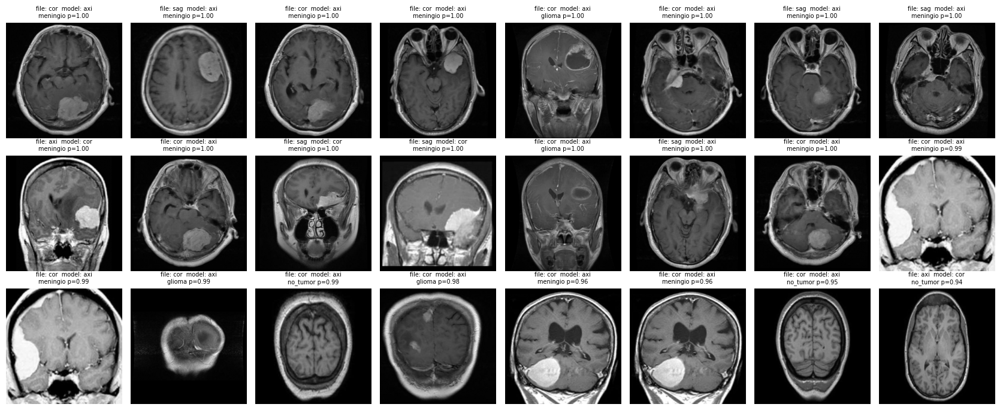


  13.4  SAVE
saved cell13_summary.json, cell13_plane_flags.csv

------------------------------------------------------------------------------
  [PASS]  features are finite
  [NOTE]  geometry alone (no pixels) reaches accuracy 0.477 on the official test set (majority class 0.140). This is the floor that pixel-based results must be read against.
  [NOTE]  the plane is predictable from generic image features (out-of-fold accuracy 0.992): the FiLM input repeats information the image already shows.
  [NOTE]  26 images carry a file-name plane that a confident model disputes: look at cell13_plane_flags.png before trusting those plane labels.
------------------------------------------------------------------------------
CELL 13 CLEAN.


In [ ]:
# =============================================================================
#  CELL 13  |  Evaluation: what shortcuts and generic features achieve; plane labels
# =============================================================================
assert "PI" in globals() and "fg_znorm" in globals(), "Run Cells 8-12 first."

PROBE_BATCH = 64
PLANE_FLAG_P = 0.90       # a plane prediction this confident that disagrees with the file name is flagged
N_FLAG_SHOW  = 24

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt
checks, notes = {}, []
trB, te = df.in_B.to_numpy(), (df.split == "test").to_numpy()
y = df.label_idx.to_numpy()
majority = df[trB].label_idx.value_counts().idxmax()
def cls_report(pred, true):
    rec = {IDX_LABEL[c]: float((pred[true == c] == c).mean()) for c in range(4)}
    return {"acc": float((pred == true).mean()), "macro_f1": macro_f1(pred, true), "recall": rec}

# ----- 13.1 geometry only ------------------------------------------------------------------------
banner("13.1  GEOMETRY-ONLY CLASSIFIER  (image size, aspect, padding, crop, plane; no pixels)")
Xg = np.column_stack([df.orig_w, df.orig_h, df.orig_w / df.orig_h, df.pad_share,
                      (df.crop_x1 - df.crop_x0) / df.orig_w, (df.crop_y1 - df.crop_y0) / df.orig_h,
                      pd.get_dummies(df.plane).reindex(columns=PLANES, fill_value=0).to_numpy(float)])
geo = HistGradientBoostingClassifier(max_iter=300, random_state=SEED).fit(Xg[trB], y[trB])
pg = geo.predict(Xg[te]); GEO = cls_report(pg, y[te])
maj = cls_report(np.full(int(te.sum()), majority), y[te])
print(f"official test: geometry-only accuracy {GEO['acc']:.3f}, macro-F1 {GEO['macro_f1']:.3f}   "
      f"(always the majority class: accuracy {maj['acc']:.3f})")
print("recall by class:", {k: round(v, 3) for k, v in GEO["recall"].items()})
notes.append(f"geometry alone (no pixels) reaches accuracy {GEO['acc']:.3f} on the official test set "
             f"(majority class {maj['acc']:.3f}). This is the floor that pixel-based results must be read against.")

# ----- 13.2 frozen generic features ---------------------------------------------------------------------
banner("13.2  FROZEN IMAGENET RESNET-50 FEATURES  (no training on BRISC)")
enc = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if PRETRAINED else None)
enc.fc = nn.Identity(); enc = enc.to(DEV).eval()
feats = np.zeros((len(df), 2048), np.float32); t0 = time.time()
with torch.no_grad():
    for s_ in range(0, len(df), PROBE_BATCH):
        idx = range(s_, min(s_ + PROBE_BATCH, len(df)))
        xb = torch.from_numpy(np.stack([np.repeat(fg_znorm(np.asarray(IMc[i]))[None], 3, 0) for i in idx])).float().to(DEV)
        with amp_ctx():
            feats[s_:s_ + len(idx)] = enc(xb).float().cpu().numpy()
del enc
print(f"features of {len(df)} images in {time.time()-t0:.0f}s (ImageNet weights: {PRETRAINED})")
checks["features are finite"] = bool(np.isfinite(feats).all())
probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(feats[trB], y[trB])
pp = probe.predict(feats[te]); PROBE = cls_report(pp, y[te])
print(f"linear probe for the CLASS (trained on set B): official-test accuracy {PROBE['acc']:.3f}, macro-F1 {PROBE['macro_f1']:.3f}")

# ----- 13.3 plane: predictable from the image? and are the labels right? -------------------------------------
banner("13.3  THE PLANE LABEL: predictable from the image? (5-fold, grouped)")
yp = PLANE_TRUE; oof = np.zeros((len(df), 3))
for tr_i, va_i in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(feats, yp, groups=df.grp):
    m_ = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(feats[tr_i], yp[tr_i])
    oof[va_i] = m_.predict_proba(feats[va_i])
plane_hat = oof.argmax(1); plane_acc = float((plane_hat == yp).mean())
print(f"out-of-fold plane accuracy from frozen features: {plane_acc:.3f}")
print(pd.crosstab(pd.Series(np.array(PLANES)[yp], name="file-name plane"), pd.Series(np.array(PLANES)[plane_hat], name="predicted")).to_string())
flag = (plane_hat != yp) & (oof.max(1) >= PLANE_FLAG_P)
FL = df.loc[flag, ["image_id", "split", "label", "plane"]].assign(predicted=np.array(PLANES)[plane_hat[flag]], p=oof.max(1)[flag])
FL.to_csv(WORK / "cell13_plane_flags.csv", index=False)
print(f"confident disagreements (p >= {PLANE_FLAG_P}): {len(FL)} images -> cell13_plane_flags.csv")
if plane_acc >= 0.95:
    notes.append(f"the plane is predictable from generic image features (out-of-fold accuracy {plane_acc:.3f}): the FiLM "
                 "input repeats information the image already shows.")
else:
    notes.append(f"the plane is only partly predictable from generic image features (out-of-fold accuracy {plane_acc:.3f}): "
                 "the FiLM input may add information the encoder does not extract on its own.")
if len(FL):
    notes.append(f"{len(FL)} images carry a file-name plane that a confident model disputes: look at cell13_plane_flags.png "
                 "before trusting those plane labels.")
if len(FL):
    show = FL.sort_values("p", ascending=False).head(N_FLAG_SHOW)
    cols = 8; rws = int(np.ceil(len(show) / cols))
    fig, ax = plt.subplots(rws, cols, figsize=(2.1 * cols, 2.3 * rws), squeeze=False)
    for a_ in ax.ravel():
        a_.axis("off")
    for k, (i, r) in enumerate(show.iterrows()):
        a_ = ax[k // cols, k % cols]; a_.imshow(IMc[i], cmap="gray")
        a_.set_title(f"file: {r.plane[:3]}  model: {r.predicted[:3]}\n{r.label[:8]} p={r.p:.2f}", fontsize=7)
    plt.tight_layout(); plt.savefig(WORK / "cell13_plane_flags.png", dpi=100, bbox_inches="tight"); plt.show()

# ----- 13.4 save ------------------------------------------------------------------------------------------------
banner("13.4  SAVE")
save_json(WORK / "cell13_summary.json", {"geometry_only": GEO, "majority": maj, "linear_probe": PROBE,
                                         "plane_oof_accuracy": plane_acc, "plane_flags": int(len(FL))})
print("saved cell13_summary.json, cell13_plane_flags.csv")
finish(13, checks, notes)

## Cell 14 | Question 1: the usual recipe vs the decontaminated model

**Purpose.** On the official test set: macro-F1, accuracy, balanced accuracy, recall by class, Dice, median HD95, false-positive rate on tumour-free images, and mean log-probability of the true class, for `full_flip` and `B_flip`, with 95% group-bootstrap intervals and per-seed values; their difference with a paired bootstrap; breakdowns by contamination stratum, class, plane and size family; a secondary honest estimate from the crossover runs. Defines the statistics engine used by Cells 15-17: every interval resamples whole groups (`grp`, Cell 6) with replacement, separately within each half of the randomisation (0 = not contaminated, 1, 2), 2,000 times; a replicate that draws no image of a subset leaves that quantity undefined (not zero).

**Inputs.** `PI` (Cell 12). **Outputs.** `cell14_summary.json`.

**Pass criteria.** Both priority-1 arms are evaluated.

In [32]:
# =============================================================================
#  CELL 14  |  Question 1: performance of the usual recipe vs the decontaminated model
#              (+ the statistics engine used by Cells 15-17)
# =============================================================================
assert "PI" in globals(), "Run Cell 12 first."

N_BOOT = 2000 if not SMOKE else 200       # group bootstrap replicates
ALPHA  = 0.05

checks, notes = {}, []
TEST = df[df.split == "test"]
test_rows = TEST.index.to_numpy(); n_test = len(test_rows); pos_of = {int(r): k for k, r in enumerate(test_rows)}
tum = TEST.has_mask.to_numpy(); neg = ~tum
lab_t = TEST.label_idx.to_numpy()

# ----- 14.1 the engine: group bootstrap over copy+patient groups ----------------------------------------
# Test images are not independent (copies, patients). Every interval resamples whole groups (grp of Cell 6) with
# replacement, separately within each half of the randomisation (0 = not contaminated, 1, 2; Cell 6), so every
# replicate keeps the design; seeds are averaged inside each replicate. Point estimates use all images once.
ug, ginv = np.unique(TEST.grp.to_numpy(), return_inverse=True)
half_g = pd.Series(TEST.half.to_numpy()).groupby(ginv).first().to_numpy()          # the half of each group
assert (pd.Series(TEST.half.to_numpy()).groupby(ginv).nunique() == 1).all(), "a group spans two halves"
rngb = np.random.default_rng(SEED)
Wg = np.zeros((N_BOOT, len(ug)), np.float32)
for h_ in np.unique(half_g):
    ix_ = np.where(half_g == h_)[0]
    Wg[:, ix_] = rngb.multinomial(len(ix_), np.full(len(ix_), 1.0 / len(ix_)), size=N_BOOT)
W = Wg[:, ginv]                                                                       # B x n_test
W1 = np.ones((1, n_test), np.float32)

def arm_field(arm, field):
    """seeds x n_test matrix of a per-image field for one arm (rows in test order), and the seeds found."""
    s_ = PI[PI.arm == arm]
    if s_.empty:
        return None, []
    seeds = [int(x) for x in sorted(s_.seed.unique())]; M = np.full((len(seeds), n_test), np.nan)
    for k, sd in enumerate(seeds):
        q_ = s_[s_.seed == sd]; M[k, [pos_of[int(r)] for r in q_.row]] = q_[field].to_numpy()
    return M, seeds

def wmean(x, Wm, mask=None):
    """Weighted mean of x (n,) under each row of Wm (B x n), ignoring NaN and rows outside mask. A replicate that
    drew no image of the subset gives NaN (undefined), never 0; intervals use np.nanpercentile."""
    ok = np.isfinite(x) & (np.ones_like(x, bool) if mask is None else mask)
    xs = np.where(ok, x, 0.0); w_ = Wm @ ok.astype(np.float32)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(w_ > 0, (Wm @ xs) / np.where(w_ > 0, w_, 1.0), np.nan)

def wmedian(x, Wm, mask=None):
    """Weighted median: the midpoint of the lower and upper weighted medians (equals np.median for unit weights)."""
    ok = np.isfinite(x) & (np.ones_like(x, bool) if mask is None else mask)
    xv, Wv = x[ok], Wm[:, ok]; o = np.argsort(xv); xs, cs = xv[o], np.cumsum(Wv[:, o], 1); half = cs[:, -1:] / 2
    return 0.5 * (xs[(cs >= half).argmax(1)] + xs[(cs > half).argmax(1)])

def same_sign(effect, per):
    """The seed rule: at least two seeds, all with the sign of the pooled effect."""
    return len(per) > 1 and effect != 0 and all(np.sign(v) == np.sign(effect) for v in per)

def conf_counts(pred, Wm):
    """Weighted 4x4 confusion matrices (B x 4 x 4) for one prediction vector."""
    E = np.zeros((n_test, 16), np.float32); E[np.arange(n_test), lab_t * 4 + pred.astype(int)] = 1
    return (Wm @ E).reshape(-1, 4, 4)

def cls_metrics(pred, Wm):
    cm = conf_counts(pred, Wm); tp = np.diagonal(cm, axis1=1, axis2=2)
    fp, fn = cm.sum(1) - tp, cm.sum(2) - tp
    f1 = np.where(tp > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1e-9), 0.0)
    rec = tp / np.maximum(cm.sum(2), 1e-9)
    return {"macro_f1": f1.mean(1), "accuracy": tp.sum(1) / cm.sum((1, 2)), "balanced_acc": rec.mean(1),
            **{f"recall_{IDX_LABEL[c]}": rec[:, c] for c in range(4)}}

def arm_metrics(arm, Wm, only_seeds=None):
    """Every headline metric of one arm under weights Wm, averaged over its seeds (or over only_seeds).
    Returns ({name: B-vector}, seeds, per-seed list)."""
    P_, seeds = arm_field(arm, "pred")
    if P_ is None:
        return None, []
    D_, _ = arm_field(arm, "dice"); Hh, _ = arm_field(arm, "hd95"); Fa, _ = arm_field(arm, "fp_any"); Lp, _ = arm_field(arm, "logp_true")
    keep = [k for k, s_ in enumerate(seeds) if only_seeds is None or s_ in only_seeds]
    if not keep:
        return None, []
    P_, D_, Hh, Fa, Lp = (M_[keep] for M_ in (P_, D_, Hh, Fa, Lp)); seeds = [seeds[k] for k in keep]
    per_seed = []
    for k in range(len(seeds)):
        m_ = cls_metrics(P_[k], Wm)
        m_.update({"dice": wmean(D_[k], Wm, tum), "hd95_median": wmedian(Hh[k], Wm, tum),
                   "fp_rate_no_tumor": wmean(Fa[k], Wm, neg), "mean_logp_true": wmean(Lp[k], Wm)})
        per_seed.append(m_)
    return {k: np.mean([ps[k] for ps in per_seed], 0) for k in per_seed[0]}, seeds, per_seed

def summarise(arm):
    """Point estimate, group-bootstrap CI and per-seed values of every metric of one arm."""
    r = arm_metrics(arm, W1)
    if r[0] is None:
        return None
    pt, seeds, ps = r; bt = arm_metrics(arm, W)[0]
    return {k: {"value": float(pt[k][0]), "lo": float(np.nanpercentile(bt[k], 100 * ALPHA / 2)),
                "hi": float(np.nanpercentile(bt[k], 100 * (1 - ALPHA / 2))),
                "per_seed": [float(p_[k][0]) for p_ in ps]} for k in pt} | {"_seeds": seeds}

def compare(arm_a, arm_b, keys):
    """Effect a - b on the seeds both arms have, with a paired group bootstrap (the same replicate rows for both arms)
    and per-seed differences (paired by seed). Verdict: CI excludes 0 and every seed has the sign of the effect."""
    pa_, pb_ = arm_field(arm_a, "pred")[1], arm_field(arm_b, "pred")[1]
    common = sorted(set(pa_) & set(pb_))
    if not common:
        return None
    ra, rb = arm_metrics(arm_a, W1, common), arm_metrics(arm_b, W1, common)
    ba, bb = arm_metrics(arm_a, W, common)[0], arm_metrics(arm_b, W, common)[0]; out = {}
    for k in keys:
        eff = float(ra[0][k][0] - rb[0][k][0])
        per = [float(ra[2][i_][k][0] - rb[2][i_][k][0]) for i_ in range(len(common))]
        lo, hi = np.nanpercentile(ba[k] - bb[k], [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])
        out[k] = {"effect": eff, "lo": float(lo), "hi": float(hi), "per_seed": per, "seeds": common,
                  "verdict": "supported" if (lo > 0 or hi < 0) and same_sign(eff, per) else "not supported"}
    return out

def show(summ, keys, title):
    rows_ = [{"metric": k, "value": v["value"], "95% CI": f"[{v['lo']:.4f}, {v['hi']:.4f}]",
              "per seed": " ".join(f"{x:.4f}" for x in v["per_seed"])} for k, v in summ.items() if k in keys]
    print(f"{title}  (seeds {summ['_seeds']})"); print(pd.DataFrame(rows_).round(4).to_string(index=False))

# ----- 14.2 the two models -----------------------------------------------------------------------------------
KEYS = ["macro_f1", "accuracy", "balanced_acc", "recall_glioma", "recall_meningioma", "recall_pituitary", "recall_no_tumor",
        "dice", "hd95_median", "fp_rate_no_tumor", "mean_logp_true"]
Q1 = {}
for arm, title in [("full_flip", "USUAL RECIPE (all official training images)"), ("B_flip", "DECONTAMINATED (set B)")]:
    banner(f"14.2  {title}  on the official test set (1,000 images)")
    s_ = summarise(arm)
    if s_ is None:
        print(f"  {arm}: not run yet (priority 1 in Cell 11)"); continue
    Q1[arm] = s_; show(s_, KEYS, arm)

# ----- 14.3 the effect of contamination on the headline numbers ----------------------------------------------
banner("14.3  USUAL RECIPE minus DECONTAMINATED  (positive = the usual recipe scores higher)")
cmp_q1 = compare("full_flip", "B_flip", ["macro_f1", "accuracy", "dice", "hd95_median", "mean_logp_true"])
def show_cmp(c_):
    print(pd.DataFrame([{"metric": k, "effect": round(v["effect"], 4), "95% CI": f"[{v['lo']:+.4f}, {v['hi']:+.4f}]",
                         "per seed": " ".join(f"{x:+.4f}" for x in v["per_seed"]), "verdict": v["verdict"]}
                        for k, v in c_.items()]).to_string(index=False))
if cmp_q1:
    show_cmp(cmp_q1)
    print("Note: the usual recipe also trains on more images (the contaminated ones), so this difference mixes\n"
          "memorisation with data quantity. Question 2 (Cell 15) separates them with the randomised crossover.")
else:
    print("needs both full_flip and B_flip")

# ----- 14.4 where does the difference come from? -------------------------------------------------------------
banner("14.4  BY CONTAMINATION STRATUM, CLASS, PLANE AND SIZE FAMILY  (seed-averaged point values)")
def by(col):
    s_ = PI[PI.arm.isin(["full_flip", "B_flip"])]
    if s_.empty:
        return None
    g_ = s_.groupby(["arm", col, "seed"]).agg(acc=("correct", "mean"), dice=("dice", "mean"), n=("row", "nunique"))
    return g_.groupby(["arm", col]).agg(acc=("acc", "mean"), dice=("dice", "mean"), n=("n", "first")).unstack(0)
for col in ["stratum", "label", "plane", "size_family"]:
    t_ = by(col)
    if t_ is not None:
        print(f"\n{col}:"); print(t_.round(4).to_string())

# ----- 14.5 secondary honest estimate from the crossover runs -----------------------------------------------
banner("14.5  CROSSOVER: every test image predicted by the model that did NOT see its relatives")
half_t = TEST.half.to_numpy()
for name, pick in [("cross_unexposed", lambda h: np.where(h == 1, "X2_flip", "X1_flip")),
                   ("cross_exposed", lambda h: np.where(h == 2, "X2_flip", "X1_flip"))]:
    a1, a2 = PI[PI.arm == "X1_flip"], PI[PI.arm == "X2_flip"]
    if a1.empty or a2.empty:
        print("needs X1_flip and X2_flip (priority 2)"); break
    src = pick(half_t)
    parts = []
    for sd in sorted(set(a1.seed) & set(a2.seed)):
        q1 = a1[a1.seed == sd].set_index("row").loc[test_rows]; q2 = a2[a2.seed == sd].set_index("row").loc[test_rows]
        q_ = q1.copy(); q_[src == "X2_flip"] = q2[src == "X2_flip"]
        parts.append(q_.reset_index().assign(arm=name, seed=sd))
    PI = pd.concat([PI[PI.arm != name]] + parts, ignore_index=True)
    s_ = summarise(name); Q1[name] = s_; show(s_, ["macro_f1", "accuracy", "dice", "mean_logp_true"], name)

# ----- 14.6 save ---------------------------------------------------------------------------------------------
banner("14.6  SAVE")
checks["at least the two priority-1 arms are evaluated"] = {"full_flip", "B_flip"} <= set(Q1)
save_json(WORK / "cell14_summary.json", {"Q1": Q1, "full_minus_B": cmp_q1, "n_boot": N_BOOT})
print("saved cell14_summary.json")
finish(14, checks, notes)


  14.2  USUAL RECIPE (all official training images)  on the official test set (1,000 images)
full_flip  (seeds [7, 1337, 2024])
           metric   value             95% CI                per seed
         macro_f1  0.9918   [0.9867, 0.9960]    0.9891 0.9947 0.9916
         accuracy  0.9910   [0.9852, 0.9957]    0.9880 0.9940 0.9910
     balanced_acc  0.9920   [0.9868, 0.9961]    0.9893 0.9946 0.9920
  recall_no_tumor  1.0000   [1.0000, 1.0000]    1.0000 1.0000 1.0000
    recall_glioma  0.9843   [0.9693, 0.9961]    0.9803 0.9882 0.9843
recall_meningioma  0.9869   [0.9760, 0.9955]    0.9804 0.9935 0.9869
 recall_pituitary  0.9967   [0.9888, 1.0000]    0.9967 0.9967 0.9967
             dice  0.8782   [0.8637, 0.8919]    0.8757 0.8790 0.8799
      hd95_median  3.1623   [2.9514, 3.6056]    3.1623 3.1623 3.1623
 fp_rate_no_tumor  0.0000   [0.0000, 0.0000]    0.0000 0.0000 0.0000
   mean_logp_true -0.0364 [-0.0657, -0.0122] -0.0450 -0.0276 -0.0366

  14.2  DECONTAMINATED (set B)  on the off

## Cell 15 | Question 2: the causal effect of contamination (randomised crossover)

**Purpose.** For every contaminated test image, the change in Dice, log-probability of the true class and correctness between the model that saw its relatives and the model that did not: same image, same seed, exposure assigned at random by group. Half 1 and half 2 get equal weight in every estimate, which cancels any generic difference between the two models exactly. Reported by stratum, with the unlinked images as a negative control (it estimates that generic difference; expected near 0). A stratum with images in one half only cannot be corrected this way and is marked *not estimable*; `boot_valid` gives the share of bootstrap replicates in which an effect is defined. Q2b: the interaction (flip minus no-flip effect for mirrored copies) minus (the same for plain copies), on the seeds that both the flip and the no-flip runs have; the pre-stated prediction is that it is positive.

**Inputs.** `PI`, engine of Cell 14. **Outputs.** `cell15_summary.json`.

**Pass criteria.** The crossover arms are available.

In [33]:
# =============================================================================
#  CELL 15  |  Question 2: the causal effect of seeing a test image's relatives in
#              training (randomised crossover), by kind of relative; Q2b: flip
# =============================================================================
assert "W" in globals() and "arm_field" in globals(), "Run Cell 14 first."

import warnings
checks, notes = {}, []
half_t = TEST.half.to_numpy(); strat_t = TEST.stratum.to_numpy()

def nanmean0(D):
    """Mean over seeds; images without the metric (e.g. Dice of tumour-free images) stay NaN, without a warning."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmean(D, 0)
LINKED = ["copy_plain", "copy_mirror", "patient_only", "related"]

def crossover_delta(arm1, arm2, field):
    """Per seed: for every linked test image, field(model that saw its relatives) - field(model that did not).
    For unlinked images: field(arm1) - field(arm2), the negative control. Returns (seeds x n) matrix, seeds."""
    M1, s1 = arm_field(arm1, field); M2, s2 = arm_field(arm2, field)
    if M1 is None or M2 is None:
        return None, []
    seeds = sorted(set(s1) & set(s2))
    D = np.full((len(seeds), n_test), np.nan)
    for k, sd in enumerate(seeds):
        a, b = M1[s1.index(sd)], M2[s2.index(sd)]
        D[k] = np.where(half_t == 1, a - b, np.where(half_t == 2, b - a, a - b))
    return D, seeds

def half_balanced(x, Wm, m_):
    """Mean of x over the images in m_, giving half 1 and half 2 EQUAL weight. In half 1 the effect is measured as
    X1 - X2 and in half 2 as X2 - X1, so any generic difference between the two models cancels exactly; a plain pooled
    mean would keep it in proportion to the size difference of the halves. With images in one half only, that
    difference cannot be removed: the plain mean is returned and flagged (False), and no verdict is given.
    Returns (B-vector, both halves present?)."""
    h1, h2 = m_ & (half_t == 1), m_ & (half_t == 2)
    if h1.any() and h2.any():
        return 0.5 * (wmean(x, Wm, h1) + wmean(x, Wm, h2)), True
    return wmean(x, Wm, m_), False

def verdict_of(lo, hi, eff, per, both=True):
    if not both:
        return "not estimable (images in one half only)"
    return "supported" if (lo > 0 or hi < 0) and same_sign(eff, per) else "not supported"

def effect_table(arm1, arm2, fields):
    rows_ = []
    for field, mask_all in fields:
        D, seeds = crossover_delta(arm1, arm2, field)
        if D is None:
            return None
        Dm = nanmean0(D)
        for st in LINKED + ["unlinked"]:
            m_ = (strat_t == st) & mask_all & np.isfinite(Dm)
            if m_.sum() == 0:
                continue
            est, both = half_balanced(Dm, W1, m_); bt = half_balanced(Dm, W, m_)[0]
            lo, hi = np.nanpercentile(bt, [2.5, 97.5]); eff = float(est[0])
            per = [float(half_balanced(np.nan_to_num(D[k]), W1, m_)[0][0]) for k in range(len(seeds))]
            rows_.append({"metric": field, "stratum": st, "images": int(m_.sum()), "both_halves": both, "effect": eff,
                          "lo": float(lo), "hi": float(hi), "boot_valid": float(np.isfinite(bt).mean()),
                          "per_seed": " ".join(f"{v:+.4f}" for v in per),
                          "verdict": "negative control" if st == "unlinked" else verdict_of(lo, hi, eff, per, both)})
    return pd.DataFrame(rows_)

FIELDS = [("dice", tum), ("logp_true", np.ones(n_test, bool)), ("correct", np.ones(n_test, bool))]

# ----- 15.1 Question 2 ----------------------------------------------------------------------------------------
banner("15.1  EXPOSURE EFFECT  (flip augmentation on): seen relatives minus unseen, same image, same seed")
T2 = effect_table("X1_flip", "X2_flip", FIELDS)
if T2 is None:
    print("needs X1_flip and X2_flip (priority 2 in Cell 11)")
else:
    print(T2.round(4).to_string(index=False))
    print("\nRead: 'effect' is the mean within-image change when the image's relatives were in the training set. Every\n"
          "image is its own control (it is exposed in one model and unexposed in the other, assignment random by group).\n"
          "The unlinked row is the negative control: it must be near 0, or the two models differ for other reasons.\n"
          "boot_valid = share of bootstrap replicates in which the effect is defined (both halves drawn).")
    thin = T2[(T2.stratum != "unlinked") & (T2.boot_valid < 0.95)]
    if len(thin):
        notes.append(f"{len(thin)} Q2 rows are defined in < 95% of the bootstrap replicates (few groups in one half): "
                     "their intervals rest on fewer replicates; read them as imprecise.")
    neg_ctrl = T2[(T2.stratum == "unlinked") & (T2.metric == "dice")]
    if len(neg_ctrl) and not (neg_ctrl.lo.iloc[0] <= 0 <= neg_ctrl.hi.iloc[0]):
        notes.append("the negative control (unlinked images) is not centred on 0 for Dice: the X1/X2 models differ beyond exposure.")

# ----- 15.2 Question 2b: does flip augmentation amplify the effect of MIRRORED copies? -------------------------
banner("15.2  FLIP x MIRROR  (exposure effect with flip minus without flip)")
T2b = effect_table("X1_noflip", "X2_noflip", FIELDS)
INTER = None
if T2 is None or T2b is None:
    print("needs X1/X2 with and without flip (priorities 2 and 4)")
else:
    print("without flip augmentation:"); print(T2b.round(4).to_string(index=False))
    rows_ = []
    for field, mask_all in FIELDS[:2]:
        Df, sf = crossover_delta("X1_flip", "X2_flip", field); Dn, sn = crossover_delta("X1_noflip", "X2_noflip", field)
        common = sorted(set(sf) & set(sn))                  # the same seeds on both sides, so the estimate is paired by seed
        if not common:
            continue
        Df = Df[[sf.index(s_) for s_ in common]]; Dn = Dn[[sn.index(s_) for s_ in common]]
        Dd_ = nanmean0(Df) - nanmean0(Dn)
        mm = (strat_t == "copy_mirror") & mask_all & np.isfinite(Dd_)
        mp = (strat_t == "copy_plain") & mask_all & np.isfinite(Dd_)
        if mm.sum() == 0 or mp.sum() == 0:
            continue
        both_all = True
        for name_, m_ in (("copy_mirror: flip - noflip", mm), ("copy_plain: flip - noflip", mp)):
            (est, both), bt = half_balanced(Dd_, W1, m_), half_balanced(Dd_, W, m_)[0]
            both_all &= both
            lo, hi = np.nanpercentile(bt, [2.5, 97.5])
            rows_.append({"metric": field, "contrast": name_, "images": int(m_.sum()), "both_halves": both,
                          "estimate": float(est[0]), "lo": float(lo), "hi": float(hi), "boot_valid": float(np.isfinite(bt).mean()),
                          "per_seed": "", "verdict": "descriptive"})
        est = half_balanced(Dd_, W1, mm)[0] - half_balanced(Dd_, W1, mp)[0]
        bt = half_balanced(Dd_, W, mm)[0] - half_balanced(Dd_, W, mp)[0]
        lo, hi = np.nanpercentile(bt, [2.5, 97.5]); eff = float(est[0])
        per = []
        for k in range(len(common)):
            dk = np.nan_to_num(Df[k] - Dn[k])
            per.append(float(half_balanced(dk, W1, mm)[0][0] - half_balanced(dk, W1, mp)[0][0]))
        rows_.append({"metric": field, "contrast": "INTERACTION: mirror minus plain", "images": int(mm.sum() + mp.sum()),
                      "both_halves": both_all, "estimate": eff, "lo": float(lo), "hi": float(hi),
                      "boot_valid": float(np.isfinite(bt).mean()), "per_seed": " ".join(f"{v:+.4f}" for v in per),
                      "verdict": verdict_of(lo, hi, eff, per, both_all)})
    INTER = pd.DataFrame(rows_)
    print("\nflip x mirror (the interaction row is the pre-specified endpoint):"); print(INTER.round(4).to_string(index=False))
    print("Prediction made before the runs: flip augmentation raises the exposure effect of MIRRORED copies (the network then\n"
          "sees the exact test image during training) and not of plain copies, so the interaction is positive.")

# ----- 15.3 save ------------------------------------------------------------------------------------------------
banner("15.3  SAVE")
checks["the crossover analysis ran (X1_flip and X2_flip available)"] = T2 is not None
save_json(WORK / "cell15_summary.json", {"Q2": None if T2 is None else T2.to_dict("records"),
                                         "Q2_noflip": None if T2b is None else T2b.to_dict("records"),
                                         "Q2b_interaction": None if INTER is None else INTER.to_dict("records")})
print("saved cell15_summary.json")
finish(15, checks, notes)


  15.1  EXPOSURE EFFECT  (flip augmentation on): seen relatives minus unseen, same image, same seed
   metric      stratum  images  both_halves  effect      lo     hi  boot_valid                per_seed          verdict
     dice   copy_plain     105         True  0.0457  0.0231 0.0722      1.0000 +0.0362 +0.0605 +0.0404        supported
     dice  copy_mirror     432         True  0.0190  0.0109 0.0286      1.0000 +0.0143 +0.0184 +0.0244        supported
     dice patient_only     247         True  0.0150 -0.0048 0.0400      1.0000 +0.0176 +0.0235 +0.0039    not supported
     dice      related      16         True  0.0035 -0.0270 0.0232      0.9980 -0.0057 +0.0046 +0.0115    not supported
     dice     unlinked      60        False -0.0029 -0.0340 0.0353      1.0000 +0.0271 +0.0061 -0.0417 negative control
logp_true   copy_plain     105         True  0.3283  0.1105 0.6108      1.0000 +0.2487 +0.4678 +0.2685        supported
logp_true  copy_mirror     432         True  0.2829  0.0840

## Cell 16 | Question 3: plane conditioning (FiLM) against a placebo

**Purpose.** On set B: FiLM with the true plane minus FiLM with a shuffled plane (primary: the information in the plane label, same architecture), FiLM minus no FiLM, and placebo minus no FiLM (extra parameters alone), with paired bootstrap intervals, per-seed signs and a breakdown by plane.

**Inputs.** `PI`, engine of Cell 14, plane predictability of Cell 13. **Outputs.** `cell16_summary.json`.

**Pass criteria.** The three arms are available.

In [34]:
# =============================================================================
#  CELL 16  |  Question 3: does conditioning on the MRI plane (FiLM) help, beyond the
#              extra parameters? (true plane vs no FiLM vs shuffled-plane placebo)
# =============================================================================
assert "compare" in globals(), "Run Cell 14 first."

checks, notes = {}, []
KEYS3 = ["macro_f1", "accuracy", "dice", "hd95_median", "mean_logp_true"]
banner("16.1  ARMS  (all trained on set B, flip augmentation on)")
S3 = {}
for arm in ["B_flip", "B_flip_film", "B_flip_placebo"]:
    s_ = summarise(arm)
    if s_ is None:
        print(f"  {arm}: not run yet (priority {1 if arm == 'B_flip' else 3})")
    else:
        S3[arm] = s_; show(s_, KEYS3, arm)

banner("16.2  EFFECTS  (paired by seed and by bootstrap replicate)")
C3 = {}
for a, b, meaning in [("B_flip_film", "B_flip_placebo", "PRIMARY: information in the plane label (same architecture)"),
                      ("B_flip_film", "B_flip", "FiLM with the true plane vs no FiLM"),
                      ("B_flip_placebo", "B_flip", "extra FiLM parameters alone (placebo vs no FiLM)")]:
    r = compare(a, b, KEYS3)
    if r is None:
        print(f"{a} - {b}: needs both arms"); continue
    C3[f"{a} - {b}"] = r
    print(f"\n{a} - {b}   ({meaning})")
    show_cmp(r)

banner("16.3  BY PLANE  (seed-averaged Dice and accuracy)")
s_ = PI[PI.arm.isin(["B_flip", "B_flip_film", "B_flip_placebo"])]
if len(s_):
    t_ = s_.groupby(["arm", "plane", "seed"]).agg(acc=("correct", "mean"), dice=("dice", "mean")).groupby(["arm", "plane"]).mean().unstack(0)
    print(t_.round(4).to_string())
pa = json.loads((WORK / "cell13_summary.json").read_text()).get("plane_oof_accuracy") if (WORK / "cell13_summary.json").exists() else None
if pa is not None:
    notes.append(f"for interpretation: the plane is predictable from generic image features with out-of-fold accuracy {pa:.3f} "
                 f"(Cell 13){'; the label then repeats what the image shows, so a null FiLM effect would not be surprising' if pa >= 0.95 else ''}.")

banner("16.4  SAVE")
checks["the three arms of Question 3 are available"] = len(S3) == 3
save_json(WORK / "cell16_summary.json", {"arms": S3, "effects": C3})
print("saved cell16_summary.json")
finish(16, checks, notes)


  16.1  ARMS  (all trained on set B, flip augmentation on)
B_flip  (seeds [7, 1337, 2024])
        metric   value             95% CI                per seed
      macro_f1  0.9344   [0.9150, 0.9517]    0.9233 0.9443 0.9355
      accuracy  0.9323   [0.9116, 0.9510]    0.9220 0.9420 0.9330
          dice  0.7855   [0.7625, 0.8071]    0.7868 0.7842 0.7855
   hd95_median  5.8094   [5.0180, 6.6125]    5.0941 6.0820 6.2523
mean_logp_true -0.3478 [-0.4777, -0.2319] -0.3988 -0.2945 -0.3501
B_flip_film  (seeds [7, 1337, 2024])
        metric   value             95% CI                per seed
      macro_f1  0.9435   [0.9252, 0.9600]    0.9446 0.9528 0.9332
      accuracy  0.9413   [0.9223, 0.9590]    0.9430 0.9500 0.9310
          dice  0.7929   [0.7702, 0.8137]    0.7904 0.8004 0.7878
   hd95_median  5.6734   [4.9462, 6.4581]    5.9569 5.9286 5.1348
mean_logp_true -0.3099 [-0.4408, -0.1972] -0.2905 -0.2626 -0.3765
B_flip_placebo  (seeds [7, 1337, 2024])
        metric   value             95% 

## Cell 17 | Error anatomy of the decontaminated model

**Purpose.** For each class: how much of the Dice shortfall comes from a few near-total failures, and which ceiling is highest: Dice with every detection error fixed, with every edge error fixed, or with every far error fixed. This tests, rather than assumes, claims like "glioma fails at its diffuse boundaries". Near-zero cases are checked against the **mirrored** label (a left-right label error would show here) and against the source annotation (Cell 5), and the worst cases are drawn.

**Inputs.** `PI`, `B_flip` predictions, masks. **Outputs.** `cell17_summary.json`, `cell17_low_dice.csv`, `cell17_worst.png`.

**Pass criteria.** The baseline arm is available.


  17.1  DICE SHORTFALL BY CLASS  (B_flip, seeds averaged per image; edge band = 2 px)
label                          glioma  meningioma  pituitary       all
images                       254.0000    306.0000   300.0000  860.0000
mean_dice                      0.6898      0.8906     0.7593    0.7855
median_dice                    0.8207      0.9499     0.8595    0.9006
share_dice_lt_0.5              0.2402      0.0425     0.1433    0.1360
shortfall_from_dice_lt_0.5     0.6105      0.2981     0.4480    0.4902
dice_if_detection_fixed        0.8201      0.9219     0.8488    0.8663
dice_if_edges_fixed            0.7828      0.9391     0.8515    0.8624
dice_if_far_errors_fixed       0.7838      0.9231     0.8204    0.8461
error_px_detection_share       0.3007      0.2373     0.2659    0.2745
error_px_edge_share            0.3075      0.3993     0.4272    0.3583
median_tumour_px            1141.0000   1625.5000   494.0000  925.0000

Each 'dice_if_..._fixed' is a ceiling: the Dice if only that

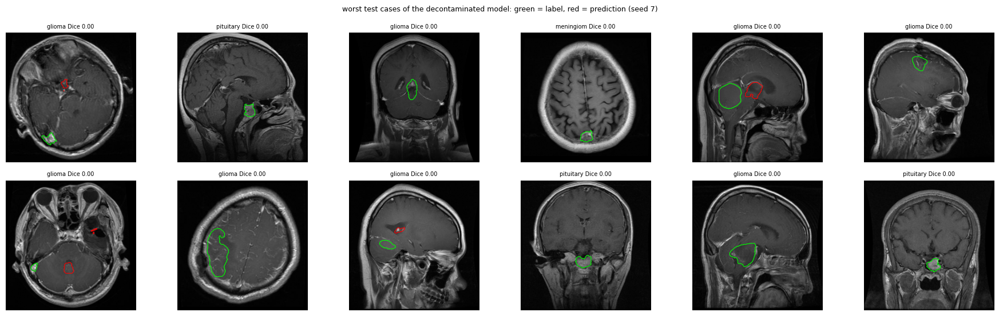

saved cell17_summary.json, cell17_low_dice.csv, cell17_worst.png

------------------------------------------------------------------------------
  [PASS]  B_flip available
------------------------------------------------------------------------------
CELL 17 CLEAN.


In [35]:
# =============================================================================
#  CELL 17  |  Error anatomy of the decontaminated model: what limits each class?
# =============================================================================
assert "PI" in globals() and "BAND" in globals(), "Run Cells 12 and 14 first."

ARM_E  = "B_flip"        # the honest baseline
N_WORST = 12
MIRROR_FLAG = 0.5        # a near-zero Dice whose prediction overlaps the MIRRORED mask this much is flagged

import matplotlib.pyplot as plt
checks, notes = {}, []
E = PI[(PI.arm == ARM_E) & PI.has_mask].copy()
if E.empty:
    print(f"{ARM_E} not run yet"); checks[f"{ARM_E} available"] = False
else:
    # ----- 17.1 where does the Dice shortfall come from? ---------------------------------------------------
    banner(f"17.1  DICE SHORTFALL BY CLASS  ({ARM_E}, seeds averaged per image; edge band = {BAND} px)")
    per_img = E.groupby(["row", "label"]).agg(dice=("dice", "mean"), dice_detfix=("dice_detfix", "mean"),
                                             dice_edgefix=("dice_edgefix", "mean"), dice_farfix=("dice_farfix", "mean"),
                                             err_det=("err_det", "mean"), err_band=("err_band", "mean"), err_far=("err_far", "mean"),
                                             gt_px=("gt_px", "first")).reset_index()
    def anat(g_):
        short = (1 - g_.dice).sum(); err = (g_.err_det + g_.err_band + g_.err_far).sum()
        return pd.Series({"images": len(g_), "mean_dice": g_.dice.mean(), "median_dice": g_.dice.median(),
                          "share_dice_lt_0.5": (g_.dice < 0.5).mean(),
                          "shortfall_from_dice_lt_0.5": (1 - g_.dice[g_.dice < 0.5]).sum() / max(short, 1e-9),
                          "dice_if_detection_fixed": g_.dice_detfix.mean(), "dice_if_edges_fixed": g_.dice_edgefix.mean(),
                          "dice_if_far_errors_fixed": g_.dice_farfix.mean(),
                          "error_px_detection_share": g_.err_det.sum() / max(err, 1e-9),
                          "error_px_edge_share": g_.err_band.sum() / max(err, 1e-9),
                          "median_tumour_px": g_.gt_px.median()})
    AN = per_img.groupby("label").apply(anat, include_groups=False)
    AN.loc["all"] = anat(per_img)
    print(AN.round(4).T.to_string())
    print("\nEach 'dice_if_..._fixed' is a ceiling: the Dice if only that kind of error were corrected. Detection errors =\n"
          "a tumour component missed entirely or a predicted component touching no tumour; edge errors = within the band\n"
          "around the true boundary in overlapping components; far errors = the rest. The largest ceiling names the limit.")

    # ----- 17.2 is a near-zero Dice sometimes a label problem? ------------------------------------------------
    sd_e = int(sorted(E.seed.unique())[0])               # a finished run that passed Cell 12's configuration check
    banner(f"17.2  NEAR-ZERO DICE: does the prediction match the MIRRORED label?  (masks of seed {sd_e})")
    z = np.load(run_dir(f"{ARM_E}_s{sd_e}") / "pred_test.npz")
    masks = np.unpackbits(z["mask_bits"], axis=-1)[..., :SIZE].astype(bool); prow = {int(r): k for k, r in enumerate(z["row"])}
    low = per_img[per_img.dice < 0.1]
    fl = []
    for _, r in low.iterrows():
        pm = masks[prow[int(r.row)]]; gm = np.asarray(MKc[int(r.row)]) > 0
        dm = dice_of(pm, gm[:, ::-1]) if pm.any() else 0.0
        fl.append({"row": int(r.row), "image_id": df.image_id[int(r.row)], "label": r.label, "dice": r.dice,
                   "dice_vs_mirrored_label": dm, "pred_px": int(pm.sum()), "gt_px": int(gm.sum()),
                   "source_mask_dice": None})
    FLG = pd.DataFrame(fl, columns=["row", "image_id", "label", "dice", "dice_vs_mirrored_label", "pred_px", "gt_px", "source_mask_dice"])
    if (WORK / "cell05_mask_agreement.csv").exists() and len(FLG):
        MA = pd.read_csv(WORK / "cell05_mask_agreement.csv").set_index("row")
        FLG["source_mask_dice"] = [MA.mask_dice.get(r_, np.nan) for r_ in FLG.row]
    print(f"tumour images with mean Dice < 0.1: {len(FLG)}")
    if len(FLG):
        print(FLG.sort_values("dice").head(30).round(3).to_string(index=False) + ("\n..." if len(FLG) > 30 else ""))
        n_m = int((FLG.dice_vs_mirrored_label >= MIRROR_FLAG).sum())
        if n_m:
            notes.append(f"{n_m} near-zero-Dice images are predicted where the MIRRORED label would be: possible "
                         "left-right label errors (inspect cell17_worst.png and cell17_low_dice.csv).")
    FLG.to_csv(WORK / "cell17_low_dice.csv", index=False)

    # ----- 17.3 worst cases, drawn ------------------------------------------------------------------------------
    worst = per_img.sort_values("dice").head(N_WORST)
    fig, ax = plt.subplots(2, max(1, len(worst)) // 2 + len(worst) % 2, figsize=(2.6 * (len(worst) // 2 + 1), 5.6), squeeze=False)
    for a_ in ax.ravel():
        a_.axis("off")
    for k, (_, r) in enumerate(worst.iterrows()):
        a_ = ax[k % 2, k // 2]; i = int(r.row)
        a_.imshow(IMc[i], cmap="gray")
        a_.contour(np.asarray(MKc[i]) > 0, levels=[0.5], colors="lime", linewidths=0.8)
        pm = masks[prow[i]]
        if pm.any():
            a_.contour(pm, levels=[0.5], colors="red", linewidths=0.8)
        a_.set_title(f"{r.label[:9]} Dice {r.dice:.2f}", fontsize=7)
    plt.suptitle(f"worst test cases of the decontaminated model: green = label, red = prediction (seed {sd_e})", fontsize=9)
    plt.tight_layout(); plt.savefig(WORK / "cell17_worst.png", dpi=100, bbox_inches="tight"); plt.show()
    checks[f"{ARM_E} available"] = True
    save_json(WORK / "cell17_summary.json", {"anatomy": AN.reset_index().to_dict("records"), "low_dice": int(len(FLG)),
                                             "mirrored_label_flags": int((FLG.dice_vs_mirrored_label >= MIRROR_FLAG).sum()) if len(FLG) else 0})
    print("saved cell17_summary.json, cell17_low_dice.csv, cell17_worst.png")
finish(17, checks, notes)

# E. Round 2 and exploratory analyses (added 10 Oct 2026)

## Cell 18 | Exploratory: would the published duplicate screens find BRISC's twins?

**Purpose.** Apply, on BRISC, the two duplicate screens described in the concurrent literature, and count how many of this study's pixel-confirmed test-train twins (Cell 7) each one finds, separately for plain and mirror-only twins. (a) Huang et al. 2026: exact duplicates by SHA-256, then a 64-bit perceptual hash (ImageHash `phash`, hash size 8, high-frequency factor 4), Hamming distance <= 6, same label and same plane, merged transitively. (b) Vangala et al. 2026: grey image resized to 64 x 64, whole-image normalised cross-correlation >= 0.98 with any training image; no mirrored search is described. Each rule is also run with mirrored images added, to show what mirror-awareness alone changes. Test images that a published rule flags but this study calls *unlinked* are listed and drawn: they are possible misses of this study.

**Inputs.** Image files (Cell 2), `fh` (file hashes, Cell 2), strata and twin evidence `ev` (Cell 7). **Outputs.** `cell18_screens.csv` (one row per test image), `cell18_summary.json`, `cell18_missed_mirror_twins.png`, `cell18_discordant.png` (if any).

**Pass criteria.** Every image has a 64-bit pHash; the 64 x 64 NCCs are finite. *Exploratory: the rules are re-implemented from the published descriptions, which may differ in detail from the authors' code (for example the resize kernel).*


  18.1  EXACT DUPLICATES ACROSS THE OFFICIAL SPLIT  (SHA-256 of the files)
official test images byte-identical to an official training image: 7

  18.2  HUANG ET AL. RULE  (ImageHash pHash 64 bit, Hamming <= 6, same label and plane, transitive groups)
pHash of 6000 images, plain and mirrored, in 48s (64 bits each)
pairs within Hamming 6: 3253 plain; 7197 when one image may be mirrored

  18.3  VANGALA ET AL. RULE  (grey 64 x 64, whole-image NCC >= 0.98 to any training image; no mirrored search)
1000 x 5000 whole-image NCCs at 64x64, plain and mirrored, in 20s
whole-image NCC of every pixel twin pair of this study (Cell 7), by kind of twin:
                   pairs  median_as_stored  share_ge_thr_as_stored  median_mirrored
kind                                                                               
copy_mirror image    442             0.724                   0.000            1.000
copy_plain image     152             1.000                   0.901            0.702

  18.4  WHAT E

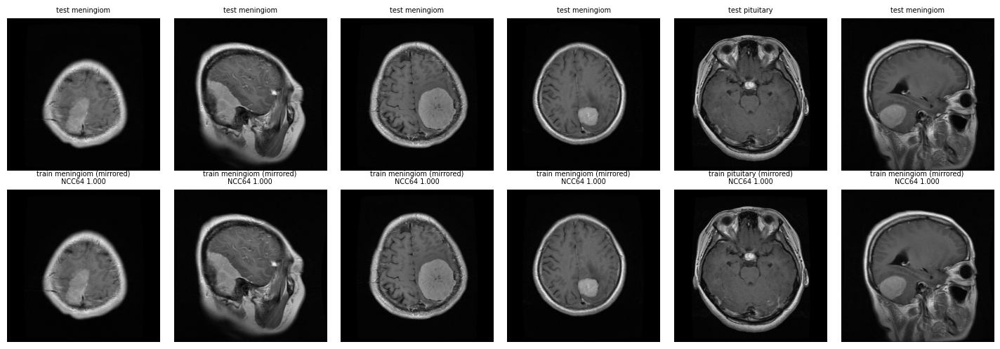


  18.6  EXAMPLES OF MIRROR-ONLY TWINS MISSED BY BOTH PUBLISHED RULES  (test | training twin as stored | twin mirrored)


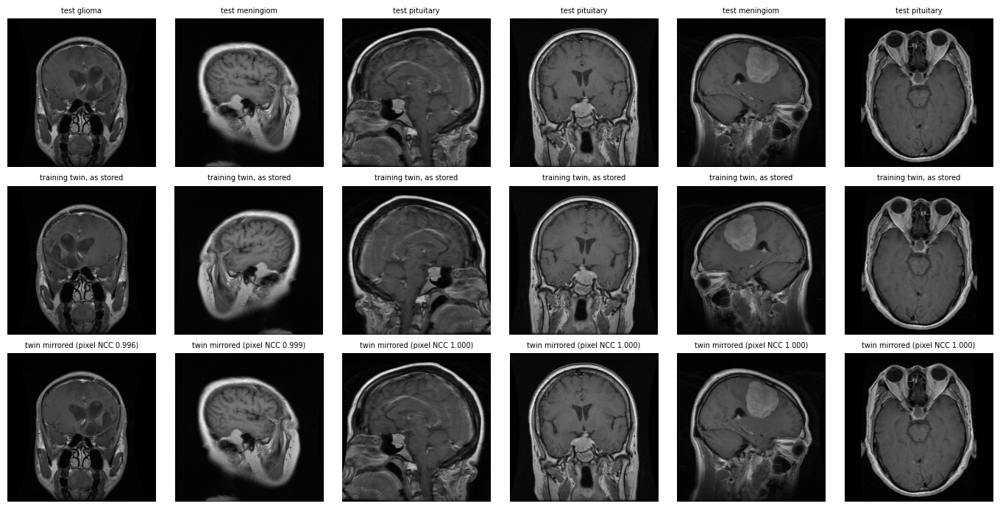


  18.7  SAVE
saved cell18_screens.csv (per test image), cell18_summary.json, figures

------------------------------------------------------------------------------
  [PASS]  every image has a 64-bit ImageHash pHash
  [PASS]  the 64x64 vectors and NCCs are finite
  [NOTE]  mirror-only twins (copy_mirror, 432 test images): 192 are missed by BOTH published rules as described; with mirrored hashes/images added they would flag 432.
  [NOTE]  54 test images that this study calls unlinked are flagged by a published rule (list above, figure cell18_discordant.png): inspect them; any true twin among them would move from 'unlinked' to a copy stratum.
------------------------------------------------------------------------------
CELL 18 CLEAN.


In [36]:
# =============================================================================
#  CELL 18  |  Exploratory: would the published duplicate screens find BRISC's twins?
#              Huang et al. 2026 (perceptual-hash rule) and Vangala et al. 2026 (64x64 NCC rule)
# =============================================================================
assert "ev" in globals() and "stratum" in df.columns and "fh" in globals(), "Run Cells 2-7 first."

PH_HASH, PH_HF, PH_TAU = 8, 4, 6    # Huang et al.: ImageHash pHash (hash_size 8, highfreq_factor 4), Hamming <= 6,
                                    # same label and same plane, merged transitively, plus exact (SHA-256) duplicates
V_SIZE, V_THR = 64, 0.98            # Vangala et al.: grey image at 64 x 64, whole-image NCC >= 0.98 (no mirrored search described)
N_SHOW = 6

try:
    import imagehash
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ImageHash"], check=True)
    import imagehash
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
checks, notes = {}, []
N = len(df)
is_te18, is_tr18 = (df.split == "test").to_numpy(), (df.split == "train").to_numpy()
lab18, pla18, st18 = df.label.to_numpy(), df.plane.to_numpy(), df.stratum.to_numpy()
te_rows18, tr_rows18 = np.where(is_te18)[0], np.where(is_tr18)[0]
ST = ["copy_plain", "copy_mirror", "patient_only", "related", "unlinked"]
ev_r, ev_t = ev.row.to_numpy().astype(int), ev.twin_row.to_numpy().astype(int)

def summary_row(rule, flagged, caught=None):
    """flagged: bool over all rows (test images the rule links to a training image). caught: set of test rows for which
    the rule links the test image to one of ITS pixel twins (ev)."""
    r_ = {"rule": rule, "test images flagged": int(flagged[is_te18].sum())}
    for s_ in ST:
        r_[s_] = f"{int((flagged & (st18 == s_)).sum())}/{int((st18 == s_).sum())}"
    copy_rows = set(np.where(np.isin(st18, ["copy_plain", "copy_mirror"]))[0])
    r_["own twin caught (copy images)"] = None if caught is None else f"{len(caught & copy_rows)}/{len(copy_rows)}"
    return r_
SUMM = []

# ----- 18.1 exact duplicates (SHA-256 of the files, Cell 2) ------------------------------------------------------
banner("18.1  EXACT DUPLICATES ACROSS THE OFFICIAL SPLIT  (SHA-256 of the files)")
sha = fh.image_sha256.to_numpy()
exact_flag = is_te18 & np.isin(sha, np.unique(sha[is_tr18]))
o_ = np.argsort(sha, kind="stable"); same_ = sha[o_][1:] == sha[o_][:-1]
ex_a, ex_b = o_[:-1][same_], o_[1:][same_]               # consecutive equal hashes: chains every exact-duplicate set
print(f"official test images byte-identical to an official training image: {int(exact_flag.sum())}")
SUMM.append(summary_row("SHA-256 exact duplicates", exact_flag))

# ----- 18.2 Huang et al.: perceptual hash ---------------------------------------------------------------------------
banner("18.2  HUANG ET AL. RULE  (ImageHash pHash 64 bit, Hamming <= 6, same label and plane, transitive groups)")
def ph_bits(path, mirror=False):
    with Image.open(path) as im:
        im = im.convert("L")
        im = ImageOps.mirror(im) if mirror else im
        return np.asarray(imagehash.phash(im, hash_size=PH_HASH, highfreq_factor=PH_HF).hash, bool).ravel()
t0 = time.time()
HB = np.stack([ph_bits(p_) for p_ in df.image_path]); HBm = np.stack([ph_bits(p_, True) for p_ in df.image_path])
print(f"pHash of {N} images, plain and mirrored, in {time.time()-t0:.0f}s ({HB.shape[1]} bits each)")
checks["every image has a 64-bit ImageHash pHash"] = HB.shape == (N, PH_HASH * PH_HASH)
pk, pkm = np.packbits(HB, axis=1), np.packbits(HBm, axis=1)
POP8 = np.unpackbits(np.arange(256, dtype=np.uint8)[:, None], axis=1).sum(1).astype(np.uint8)
hamm = lambda a, b: POP8[np.bitwise_xor(a[:, None, :], b[None, :, :])].sum(2)
pp_, pm_ = [], []
for i in range(0, N, 500):
    Dp = hamm(pk[i:i + 500], pk); Dm = np.minimum(Dp, hamm(pkm[i:i + 500], pk))
    r0 = np.arange(i, min(i + 500, N))
    for D_, out in ((Dp, pp_), (Dm, pm_)):
        rr, cc = np.nonzero(D_ <= PH_TAU); keep = r0[rr] < cc
        out.append(np.stack([r0[rr][keep], cc[keep]], 1))
pairs_plain, pairs_flip = np.concatenate(pp_), np.concatenate(pm_)
def rule_groups(pairs):
    a, b = pairs[:, 0], pairs[:, 1]
    keep = (lab18[a] == lab18[b]) & (pla18[a] == pla18[b])                    # same label and same plane
    ea, eb = np.concatenate([a[keep], ex_a]), np.concatenate([b[keep], ex_b])
    return connected_components(coo_matrix((np.ones(len(ea)), (ea, eb)), shape=(N, N)), directed=False)[1]
def flagged_by(groups):
    return is_te18 & np.isin(groups, np.unique(groups[is_tr18]))
def caught_by(groups):
    return set(ev_r[groups[ev_r] == groups[ev_t]])
G_h, G_hf = rule_groups(pairs_plain), rule_groups(pairs_flip)
huang_flag, huangf_flag = flagged_by(G_h), flagged_by(G_hf)
print(f"pairs within Hamming {PH_TAU}: {len(pairs_plain)} plain; {len(pairs_flip)} when one image may be mirrored")
SUMM.append(summary_row("Huang et al. rule, as described (plain pHash)", huang_flag, caught_by(G_h)))
SUMM.append(summary_row("  the same rule with mirrored hashes added", huangf_flag, caught_by(G_hf)))

# ----- 18.3 Vangala et al.: whole-image NCC at 64 x 64 ------------------------------------------------------------------
banner("18.3  VANGALA ET AL. RULE  (grey 64 x 64, whole-image NCC >= 0.98 to any training image; no mirrored search)")
def v_vec(path, mirror=False):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    v = cv2.resize(im, (V_SIZE, V_SIZE), interpolation=cv2.INTER_AREA).astype(np.float32)
    v = (v[:, ::-1] if mirror else v).ravel(); v = v - v.mean(); n_ = np.linalg.norm(v)
    return v / n_ if n_ > 1e-6 else v
t0 = time.time()
V64 = np.stack([v_vec(p_) for p_ in df.image_path]); V64m = np.stack([v_vec(p_, True) for p_ in df.image_path[is_te18]])
S_pl = V64[is_te18] @ V64[is_tr18].T; S_mi = V64m @ V64[is_tr18].T                  # test x official-train NCC
best_pl, best_mi = S_pl.max(1), S_mi.max(1)
print(f"{len(te_rows18)} x {len(tr_rows18)} whole-image NCCs at {V_SIZE}x{V_SIZE}, plain and mirrored, in {time.time()-t0:.0f}s")
checks["the 64x64 vectors and NCCs are finite"] = bool(np.isfinite(S_pl).all() and np.isfinite(S_mi).all())
v_flag, vf_flag = np.zeros(N, bool), np.zeros(N, bool)
v_flag[te_rows18] = best_pl >= V_THR; vf_flag[te_rows18] = np.maximum(best_pl, best_mi) >= V_THR
pos_te, pos_tr = {int(r): k for k, r in enumerate(te_rows18)}, {int(r): k for k, r in enumerate(tr_rows18)}
ev_ok = np.array([t_ in pos_tr for t_ in ev_t])
ev_pl = np.full(len(ev), np.nan); ev_mi = np.full(len(ev), np.nan)
ev_pl[ev_ok] = S_pl[[pos_te[r_] for r_ in ev_r[ev_ok]], [pos_tr[t_] for t_ in ev_t[ev_ok]]]
ev_mi[ev_ok] = S_mi[[pos_te[r_] for r_ in ev_r[ev_ok]], [pos_tr[t_] for t_ in ev_t[ev_ok]]]
SUMM.append(summary_row("Vangala et al. rule, as described (no mirror)", v_flag, set(ev_r[ev_pl >= V_THR])))
SUMM.append(summary_row("  the same rule with mirrored images added", vf_flag, set(ev_r[np.maximum(ev_pl, ev_mi) >= V_THR])))
print("whole-image NCC of every pixel twin pair of this study (Cell 7), by kind of twin:")
tw_kind = np.where(st18[ev_r] == "copy_mirror", "copy_mirror image", "copy_plain image")
print(pd.DataFrame({"kind": tw_kind, "NCC 64x64 as stored": ev_pl, "NCC 64x64 mirrored": ev_mi}).groupby("kind")
      .agg(pairs=("kind", "size"), median_as_stored=("NCC 64x64 as stored", "median"),
           share_ge_thr_as_stored=("NCC 64x64 as stored", lambda x: float((x >= V_THR).mean())),
           median_mirrored=("NCC 64x64 mirrored", "median")).round(3).to_string())

# ----- 18.4 this study, for comparison ------------------------------------------------------------------------------------
SUMM.append(summary_row("this study (Cells 5-7: mirror-aware pixel search + patients)", df.test_linked.to_numpy() & is_te18,
                        set(ev_r)))
banner("18.4  WHAT EACH SCREEN FINDS  (official test images; 'x/y' = flagged / images in that stratum of this study)")
SC = pd.DataFrame(SUMM)
with pd.option_context("display.max_colwidth", 60):
    print(SC.to_string(index=False))
print("\nflagged = the rule links the test image to at least one official training image. 'own twin caught' = the rule links\n"
      "the test image to one of ITS near-identical training images found in Cell 7. A rule that misses a twin leaves that\n"
      "test image in an apparently clean test set.")
mir_rows = np.where(st18 == "copy_mirror")[0]
miss_both = mir_rows[~huang_flag[mir_rows] & ~v_flag[mir_rows]]
notes.append(f"mirror-only twins (copy_mirror, {len(mir_rows)} test images): {len(miss_both)} are missed by BOTH published rules "
             f"as described; with mirrored hashes/images added they would flag {int((huangf_flag | vf_flag)[mir_rows].sum())}.")

# ----- 18.5 discordant images: flagged by a published rule, unlinked in this study ------------------------------------------
banner("18.5  FLAGGED BY A PUBLISHED RULE BUT 'UNLINKED' IN THIS STUDY  (possible misses of this study; inspect)")
disc = np.where(is_te18 & (st18 == "unlinked") & (huangf_flag | vf_flag))[0]
DISC = pd.DataFrame({"row": disc, "image_id": df.image_id.to_numpy()[disc], "label": lab18[disc],
                     "huang": huang_flag[disc], "huang_mirror": huangf_flag[disc], "vangala": v_flag[disc], "vangala_mirror": vf_flag[disc],
                     "best_ncc64": [float(max(best_pl[pos_te[r_]], best_mi[pos_te[r_]])) for r_ in disc]})
print(f"{len(DISC)} images" + ("" if not len(DISC) else ":\n" + DISC.head(40).round(3).to_string(index=False)))
if len(DISC):
    notes.append(f"{len(DISC)} test images that this study calls unlinked are flagged by a published rule (list above, figure "
                 "cell18_discordant.png): inspect them; any true twin among them would move from 'unlinked' to a copy stratum.")
    sh = DISC.sort_values("best_ncc64", ascending=False).head(N_SHOW)
    fig, ax = plt.subplots(2, len(sh), figsize=(2.4 * len(sh), 5), squeeze=False)
    for k, r_ in enumerate(sh.row):
        kk = pos_te[int(r_)]; mir_ = best_mi[kk] > best_pl[kk]
        j_ = tr_rows18[int(np.argmax(S_mi[kk] if mir_ else S_pl[kk]))]
        ax[0, k].imshow(cv2.imread(df.image_path[int(r_)], cv2.IMREAD_GRAYSCALE), cmap="gray"); ax[0, k].set_title(f"test {lab18[r_][:9]}", fontsize=7)
        tr_im = cv2.imread(df.image_path[j_], cv2.IMREAD_GRAYSCALE)
        ax[1, k].imshow(tr_im[:, ::-1] if mir_ else tr_im, cmap="gray")
        ax[1, k].set_title(f"train {lab18[j_][:9]}{' (mirrored)' if mir_ else ''}\nNCC64 {max(best_pl[kk], best_mi[kk]):.3f}", fontsize=7)
        ax[0, k].axis("off"); ax[1, k].axis("off")
    plt.tight_layout(); plt.savefig(WORK / "cell18_discordant.png", dpi=100, bbox_inches="tight"); plt.show()

# ----- 18.6 what the published rules miss, drawn ------------------------------------------------------------------------------
banner("18.6  EXAMPLES OF MIRROR-ONLY TWINS MISSED BY BOTH PUBLISHED RULES  (test | training twin as stored | twin mirrored)")
if len(miss_both):
    pick = np.random.default_rng(SEED).choice(miss_both, size=min(N_SHOW, len(miss_both)), replace=False)
    fig, ax = plt.subplots(3, len(pick), figsize=(2.3 * len(pick), 7), squeeze=False)
    for k, r_ in enumerate(pick):
        e_ = ev[ev.row == r_].sort_values("ncc", ascending=False).iloc[0]; j_ = int(e_.twin_row)
        tr_im = cv2.imread(df.image_path[j_], cv2.IMREAD_GRAYSCALE)
        ax[0, k].imshow(cv2.imread(df.image_path[int(r_)], cv2.IMREAD_GRAYSCALE), cmap="gray"); ax[0, k].set_title(f"test {lab18[r_][:9]}", fontsize=7)
        ax[1, k].imshow(tr_im, cmap="gray"); ax[1, k].set_title("training twin, as stored", fontsize=7)
        ax[2, k].imshow(tr_im[:, ::-1], cmap="gray"); ax[2, k].set_title(f"twin mirrored (pixel NCC {e_.ncc:.3f})", fontsize=7)
        for a_ in ax[:, k]:
            a_.axis("off")
    plt.tight_layout(); plt.savefig(WORK / "cell18_missed_mirror_twins.png", dpi=100, bbox_inches="tight"); plt.show()
else:
    print("none")

# ----- 18.7 save --------------------------------------------------------------------------------------------------------------
banner("18.7  SAVE")
scr = pd.DataFrame({"image_id": df.image_id.to_numpy()[te_rows18], "stratum": st18[te_rows18], "sha256_exact": exact_flag[te_rows18],
                    "huang": huang_flag[te_rows18], "huang_mirror": huangf_flag[te_rows18], "vangala": v_flag[te_rows18],
                    "vangala_mirror": vf_flag[te_rows18], "ncc64_best": best_pl, "ncc64_best_mirrored": best_mi})
scr.to_csv(WORK / "cell18_screens.csv", index=False)
save_json(WORK / "cell18_summary.json", {
    "exploratory": True, "huang_rule": {"hash_size": PH_HASH, "highfreq_factor": PH_HF, "tau": PH_TAU},
    "vangala_rule": {"size": V_SIZE, "ncc": V_THR}, "table": SC.to_dict("records"),
    "copy_mirror_images": int(len(mir_rows)), "copy_mirror_missed_by_both": int(len(miss_both)),
    "copy_mirror_flagged_with_mirror": int((huangf_flag | vf_flag)[mir_rows].sum()),
    "copy_plain_flagged_huang": int((huang_flag & (st18 == "copy_plain")).sum()),
    "copy_plain_flagged_vangala": int((v_flag & (st18 == "copy_plain")).sum()),
    "copy_mirror_flagged_huang": int((huang_flag & (st18 == "copy_mirror")).sum()),
    "copy_mirror_flagged_vangala": int((v_flag & (st18 == "copy_mirror")).sum()),
    "exact_test_duplicates": int(exact_flag.sum()), "discordant_unlinked": int(len(DISC))})
print("saved cell18_screens.csv (per test image), cell18_summary.json, figures")
finish(18, checks, notes)

## Cell 19 | Question 4 (round 2): does doing both tasks in one network help?

**Purpose.** The earlier study claimed a benefit from joint segmentation and classification. Test it under contamination control: multi-task `B_flip` vs segmentation-only `B_flip_seg` on Dice (and HD95, false positives on tumour-free images), and vs classification-only `B_flip_cls` on macro-F1 (and accuracy, recall by class, log-probability of the true class), with the paired group bootstrap and the seed rule (primary endpoints: Dice and macro-F1 on set B). The same contrasts on the Full set show whether contamination changes the answer; their difference is reported as a descriptive interaction. Two checks without test-set model selection: validation curves (best and last epoch of every run) and the test predictions of the last epoch for seed 1337.

**Inputs.** `PI` (Cell 12), statistics engine (Cell 14), `runs/*/history.csv`. **Outputs.** `cell19_summary.json`, `cell19_effects.csv`.

**Pass criteria.** The arms of the primary endpoints are available. Missing arms are named (Cell 11 priority 6).

In [37]:
# =============================================================================
#  CELL 19  |  Question 4 (round 2): does doing both tasks in one network help either task
#              once contamination is removed? (multi-task vs single-task, on set B and on Full)
# =============================================================================
assert "compare" in globals() and "summarise" in globals() and "show_cmp" in globals(), "Run Cells 12-14 first."

SEG_KEYS = ["dice", "hd95_median", "fp_rate_no_tumor"]
CLS_KEYS = ["macro_f1", "accuracy", "balanced_acc", "recall_glioma", "recall_meningioma", "recall_pituitary",
            "recall_no_tumor", "mean_logp_true"]
CONTRASTS4 = [  # multi-task arm, single-task arm, metrics, meaning, primary endpoints (fixed 10 Oct 2026)
    ("B_flip", "B_flip_seg", SEG_KEYS, "set B: multi-task minus segmentation-only", ["dice"]),
    ("B_flip", "B_flip_cls", CLS_KEYS, "set B: multi-task minus classification-only", ["macro_f1"]),
    ("full_flip", "full_flip_seg", SEG_KEYS, "Full: multi-task minus segmentation-only", []),
    ("full_flip", "full_flip_cls", CLS_KEYS, "Full: multi-task minus classification-only", []),
]
checks, notes = {}, []

# ----- 19.1 the arms -----------------------------------------------------------------------------------------------
banner("19.1  ARMS  (official test set; a single-task arm is judged on its own task only)")
S4 = {}
for arm, keys in [("B_flip", SEG_KEYS + CLS_KEYS), ("B_flip_seg", SEG_KEYS), ("B_flip_cls", CLS_KEYS),
                  ("full_flip", SEG_KEYS + CLS_KEYS), ("full_flip_seg", SEG_KEYS), ("full_flip_cls", CLS_KEYS)]:
    s_ = summarise(arm)
    if s_ is None:
        print(f"  {arm}: not run yet (priority {1 if arm in ('B_flip', 'full_flip') else 6} in Cell 11)"); continue
    S4[arm] = {k: v for k, v in s_.items() if k in keys or k == "_seeds"}
    show(s_, keys, arm); print()

# ----- 19.2 the effects --------------------------------------------------------------------------------------------
banner("19.2  EFFECTS  (paired by seed and by bootstrap replicate)")
print("positive = the multi-task network scores higher (for HD95 and the false-positive rate, lower is better)")
C4 = {}
for a, b, keys, meaning, prim in CONTRASTS4:
    r = compare(a, b, keys)
    if r is None:
        print(f"\n{a} - {b}: needs both arms"); continue
    for k in r:
        r[k]["primary"] = k in prim
    C4[f"{a} - {b}"] = r
    print(f"\n{a} - {b}   ({meaning}; {'PRIMARY endpoint: ' + ', '.join(prim) if prim else 'secondary'})")
    show_cmp(r)
for name_, key_ in (("B_flip - B_flip_seg", "dice"), ("B_flip - B_flip_cls", "macro_f1")):
    if name_ in C4:
        v = C4[name_][key_]
        notes.append(f"Q4 primary, {name_} on {key_}: {v['effect']:+.4f} [{v['lo']:+.4f}, {v['hi']:+.4f}], {v['verdict']}.")

# ----- 19.3 does contamination change the answer? -------------------------------------------------------------------
banner("19.3  DOES CONTAMINATION CHANGE THE ANSWER?  (multi-task gain on Full minus the gain on B; descriptive)")
def gain_interaction(key, suffix):
    arms_ = ["full_flip", f"full_flip_{suffix}", "B_flip", f"B_flip_{suffix}"]
    seeds_ = [set(arm_field(a_, "pred")[1]) for a_ in arms_]
    common = sorted(set.intersection(*seeds_)) if all(seeds_) else []
    if not common:
        return None
    pt = [arm_metrics(a_, W1, common) for a_ in arms_]; bt = [arm_metrics(a_, W, common)[0] for a_ in arms_]
    eff = float((pt[0][0][key][0] - pt[1][0][key][0]) - (pt[2][0][key][0] - pt[3][0][key][0]))
    per = [float((pt[0][2][i][key][0] - pt[1][2][i][key][0]) - (pt[2][2][i][key][0] - pt[3][2][i][key][0])) for i in range(len(common))]
    lo, hi = np.nanpercentile((bt[0][key] - bt[1][key]) - (bt[2][key] - bt[3][key]), [2.5, 97.5])
    return {"effect": eff, "lo": float(lo), "hi": float(hi), "per_seed": per, "seeds": common, "verdict": "descriptive"}
INT4 = {}
for key_, suf in (("dice", "seg"), ("macro_f1", "cls")):
    r = gain_interaction(key_, suf)
    if r is None:
        print(f"{key_}: needs full_flip, full_flip_{suf}, B_flip and B_flip_{suf}"); continue
    INT4[key_] = r
    print(f"{key_:9s}: (Full: multi - {suf}) - (B: multi - {suf}) = {r['effect']:+.4f}  95% CI [{r['lo']:+.4f}, {r['hi']:+.4f}]  "
          f"per seed {' '.join(f'{x:+.4f}' for x in r['per_seed'])}")
print("Read: a gain that exists only on Full would be a benefit measured on contaminated test images.")

# ----- 19.4 by class ----------------------------------------------------------------------------------------------------
banner("19.4  BY CLASS  (seed-averaged point values)")
s4 = PI[PI.arm.isin(["B_flip", "B_flip_seg", "B_flip_cls", "full_flip", "full_flip_seg", "full_flip_cls"])]
if len(s4):
    sg_ = s4[s4.task.isin(["both", "seg"]) & s4.has_mask]
    cl_ = s4[s4.task.isin(["both", "cls"])]
    if len(sg_):
        print("mean Dice by class (tumour images):")
        print(sg_.groupby(["arm", "label", "seed"]).dice.mean().groupby(["arm", "label"]).mean().unstack(0).round(4).to_string())
    if len(cl_):
        print("\nrecall by class:")
        print(cl_.groupby(["arm", "label", "seed"]).correct.mean().groupby(["arm", "label"]).mean().unstack(0).round(4).to_string())

# ----- 19.5 without test-set model selection ------------------------------------------------------------------------------
banner("19.5  WITHOUT MODEL SELECTION  (validation curves of every seed; test at the last epoch for seed 1337)")
def hist_of(tag):
    p_ = run_dir(tag) / "history.csv"
    return pd.read_csv(p_) if p_.exists() else None
vrows = []
for set_, mt in (("B", "B_flip"), ("Full", "full_flip")):
    for sd in SEEDS:
        hm, hs, hc = hist_of(f"{mt}_s{sd}"), hist_of(f"{mt}_seg_s{sd}"), hist_of(f"{mt}_cls_s{sd}")
        g_ = lambda h, c, f: None if h is None else float(getattr(h[c], f)() if f != "last" else h[c].iloc[-1])
        vrows.append({"set": set_, "seed": sd,
                      "Dice max multi": g_(hm, "va_dice", "max"), "Dice max seg": g_(hs, "va_dice", "max"),
                      "Dice last multi": g_(hm, "va_dice", "last"), "Dice last seg": g_(hs, "va_dice", "last"),
                      "F1 max multi": g_(hm, "va_f1", "max"), "F1 max cls": g_(hc, "va_f1", "max"),
                      "F1 last multi": g_(hm, "va_f1", "last"), "F1 last cls": g_(hc, "va_f1", "last")})
VR = pd.DataFrame(vrows)
print(VR.round(4).to_string(index=False))
print("validation fold: 'max' = the best epoch of each run (optimistic for every arm alike), 'last' = the final epoch.\n"
      "multi = multi-task arm (B_flip or full_flip); seg / cls = segmentation-only / classification-only arm of the same seed.")
L4 = {}
for a, b, keys in (("B_flip_rep@last", "B_flip_seg@last", SEG_KEYS[:1]), ("B_flip_rep@last", "B_flip_cls@last", CLS_KEYS[:1]),
                   ("full_flip_rep@last", "full_flip_seg@last", SEG_KEYS[:1]), ("full_flip_rep@last", "full_flip_cls@last", CLS_KEYS[:1])):
    r = compare(a, b, keys)
    if r is None:
        print(f"{a} - {b}: needs both (priorities 6 and 7)"); continue
    for k in r:
        r[k]["verdict"] = f"descriptive ({len(r[k]['seeds'])} seed)"
    L4[f"{a} - {b}"] = r
    print(f"\n{a} - {b}   (test, last epoch, same seed and initial weights)"); show_cmp(r)

# ----- 19.6 save --------------------------------------------------------------------------------------------------------
banner("19.6  SAVE")
checks["the arms of the Q4 primary endpoints are available (B_flip, B_flip_seg, B_flip_cls)"] = all(
    a in S4 for a in ("B_flip", "B_flip_seg", "B_flip_cls"))
def effects_csv(dicts, path):
    """Flatten {contrast: {metric: effect dict}} into one CSV row per contrast and metric."""
    out = [{"contrast": c_, "metric": k, "effect": v["effect"], "lo": v["lo"], "hi": v["hi"],
            "per_seed": " ".join(f"{x:+.4f}" for x in v["per_seed"]), "verdict": v["verdict"], "primary": v.get("primary", False)}
           for c_, r in dicts.items() for k, v in r.items()]
    pd.DataFrame(out).to_csv(path, index=False)
effects_csv({**C4, **L4}, WORK / "cell19_effects.csv")
save_json(WORK / "cell19_summary.json", {"arms": S4, "effects": C4, "interaction": INT4, "validation": vrows, "last_epoch": L4})
print("saved cell19_summary.json, cell19_effects.csv")
finish(19, checks, notes)


  19.1  ARMS  (official test set; a single-task arm is judged on its own task only)
B_flip  (seeds [7, 1337, 2024])
           metric   value             95% CI                per seed
         macro_f1  0.9344   [0.9150, 0.9517]    0.9233 0.9443 0.9355
         accuracy  0.9323   [0.9116, 0.9510]    0.9220 0.9420 0.9330
     balanced_acc  0.9425   [0.9249, 0.9578]    0.9337 0.9500 0.9439
  recall_no_tumor  1.0000   [1.0000, 1.0000]    1.0000 1.0000 1.0000
    recall_glioma  0.9528   [0.9194, 0.9816]    0.9449 0.9409 0.9724
recall_meningioma  0.8551   [0.8042, 0.8990]    0.8333 0.8856 0.8464
 recall_pituitary  0.9622   [0.9313, 0.9877]    0.9567 0.9733 0.9567
             dice  0.7855   [0.7625, 0.8071]    0.7868 0.7842 0.7855
      hd95_median  5.8094   [5.0180, 6.6125]    5.0941 6.0820 6.2523
 fp_rate_no_tumor  0.0048   [0.0000, 0.0123]    0.0000 0.0143 0.0000
   mean_logp_true -0.3478 [-0.4777, -0.2319] -0.3988 -0.2945 -0.3501

B_flip_seg  (seeds [7, 1337, 2024])
          metric  

## Cell 20 | Question 5 (round 2): contamination at a fixed quantity of training data

**Purpose.** Set B is smaller than Full (most pituitary training images are linked to test images), so Q1 mixes memorisation with data quantity. Set `Fm` (Cell 11) has the size and class counts of B but is drawn at random from Full, so it holds contaminated images in their natural share. `Fm_flip` minus `B_flip` is the effect of contamination at a fixed quantity and class mix (primary: macro-F1 and Dice). Reported with it: `full_flip` minus `Fm_flip` (more data at the natural share; descriptive), the share of the Q1 gap that already appears at a fixed quantity, and where the change happens (test images exposed in Fm vs not; descriptive, not randomised). This is the design of the concurrent size-matched study on BRISC (Huang et al. 2026 report +0.026 accuracy and +0.032 mean class Dice), here with patient-level links and the official test set.

**Inputs.** `PI` (Cell 12), engine (Cell 14), `in_Fm`, `exposed_Fm` (Cell 11). **Outputs.** `cell20_summary.json`, `cell20_effects.csv`.

**Pass criteria.** The arms of the primary endpoint are available (Cell 11 priority 5).

In [38]:
# =============================================================================
#  CELL 20  |  Question 5 (round 2): does contamination inflate the scores at a FIXED
#              quantity of training data? (Fm_flip vs B_flip; Fm = size and class counts of B,
#              drawn at random from the Full set)
# =============================================================================
assert "compare" in globals() and "in_Fm" in df.columns and "effects_csv" in globals(), "Run Cells 11-19 first."

KEYS5 = ["macro_f1", "accuracy", "balanced_acc", "dice", "hd95_median", "mean_logp_true",
         "recall_glioma", "recall_meningioma", "recall_pituitary", "recall_no_tumor"]
PRIMARY5 = ["macro_f1", "dice"]
import warnings
checks, notes = {}, []

# ----- 20.1 what Fm holds ---------------------------------------------------------------------------------------------
banner("20.1  SET Fm  (same size and class counts as B; contaminated images in their natural share)")
print(fm_tab.to_string())
exp_fm = df.loc[test_rows, "exposed_Fm"].to_numpy().astype(bool)
print(f"\nofficial test images with a relative in Fm: {int(exp_fm.sum())} of {n_test}")
print(pd.crosstab(df.loc[test_rows, "stratum"].to_numpy(), np.where(exp_fm, "exposed in Fm", "not exposed"),
                  rownames=["stratum"], colnames=["test images"]).to_string())

# ----- 20.2 the arms --------------------------------------------------------------------------------------------------------
banner("20.2  ARMS  (official test set)")
S5 = {}
for arm in ("B_flip", "Fm_flip", "full_flip"):
    s_ = summarise(arm)
    if s_ is None:
        print(f"  {arm}: not run yet"); continue
    S5[arm] = s_; show(s_, KEYS5, arm); print()

# ----- 20.3 the effects --------------------------------------------------------------------------------------------------
banner("20.3  EFFECTS  (paired by seed and by bootstrap replicate)")
C5 = {}
for a, b, meaning in (("Fm_flip", "B_flip", "PRIMARY (Q5): contamination at a fixed quantity and class mix"),
                      ("full_flip", "Fm_flip", "descriptive: more data at the natural contamination share"),
                      ("full_flip", "B_flip", "Q1, for reference (quantity and contamination together)")):
    r = compare(a, b, KEYS5)
    if r is None:
        print(f"\n{a} - {b}: needs both arms"); continue
    for k in r:
        r[k]["primary"] = (a, b) == ("Fm_flip", "B_flip") and k in PRIMARY5
        if (a, b) == ("full_flip", "Fm_flip"):
            r[k]["verdict"] = "descriptive (" + r[k]["verdict"] + " by the rule)"
    C5[f"{a} - {b}"] = r
    print(f"\n{a} - {b}   ({meaning})"); show_cmp(r)
SHARE5 = {}
if {"Fm_flip", "B_flip", "full_flip"} <= set(S5):
    banner("20.4  SHARE OF THE Q1 GAP REPRODUCED AT A FIXED QUANTITY  ((Fm - B) / (Full - B); descriptive)")
    com = sorted(set(S5["Fm_flip"]["_seeds"]) & set(S5["B_flip"]["_seeds"]) & set(S5["full_flip"]["_seeds"]))
    pf, pb, pu = (arm_metrics(a_, W1, com)[0] for a_ in ("Fm_flip", "B_flip", "full_flip"))
    bf, bb, bu = (arm_metrics(a_, W, com)[0] for a_ in ("Fm_flip", "B_flip", "full_flip"))
    for k in PRIMARY5 + ["accuracy", "mean_logp_true"]:
        est = float((pf[k][0] - pb[k][0]) / (pu[k][0] - pb[k][0])) if pu[k][0] != pb[k][0] else float("nan")
        with np.errstate(divide="ignore", invalid="ignore"), warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            rb = (bf[k] - bb[k]) / (bu[k] - bb[k]); lo, hi = np.nanpercentile(rb, [2.5, 97.5])
        SHARE5[k] = {"share": est, "lo": float(lo), "hi": float(hi)}
        print(f"{k:15s}: {est:6.3f}  95% CI [{lo:.3f}, {hi:.3f}]")
    print("1 = all of the Q1 gap appears at a fixed quantity of data (contamination alone); 0 = none of it.")

# ----- 20.5 inside Fm: images exposed vs not exposed --------------------------------------------------------------------------
banner("20.5  WHERE THE Fm - B CHANGE HAPPENS  (per image, paired by seed; test images exposed in Fm vs not; descriptive)")
EXP5 = []
for field, mask_all in (("dice", tum), ("logp_true", np.ones(n_test, bool)), ("correct", np.ones(n_test, bool))):
    Ma, sa = arm_field("Fm_flip", field); Mb, sb = arm_field("B_flip", field)
    if Ma is None or Mb is None:
        print("needs Fm_flip and B_flip"); break
    com = sorted(set(sa) & set(sb))
    D = np.stack([Ma[sa.index(s_)] - Mb[sb.index(s_)] for s_ in com]); Dm = nanmean0(D)
    for name_, m_ in (("exposed in Fm", exp_fm), ("not exposed", ~exp_fm)):
        m_ = m_ & mask_all & np.isfinite(Dm)
        if m_.sum() == 0:
            continue
        est = float(wmean(Dm, W1, m_)[0]); lo, hi = np.nanpercentile(wmean(Dm, W, m_), [2.5, 97.5])
        per = [float(wmean(np.nan_to_num(D[k]), W1, m_)[0]) for k in range(len(com))]
        EXP5.append({"metric": field, "test images": name_, "n": int(m_.sum()), "Fm - B": est, "lo": float(lo), "hi": float(hi),
                     "per_seed": " ".join(f"{v:+.4f}" for v in per)})
if EXP5:
    print(pd.DataFrame(EXP5).round(4).to_string(index=False))
    print("Not randomised: exposed and unexposed test images differ in other ways (source, class). The crossover (Q2) is the\n"
          "causal estimate; this table only shows where the Fm - B difference is located.")

# ----- 20.6 save --------------------------------------------------------------------------------------------------------------
banner("20.6  SAVE")
checks["the arms of the Q5 primary endpoint are available (Fm_flip, B_flip)"] = {"Fm_flip", "B_flip"} <= set(S5)
if "Fm_flip - B_flip" in C5:
    for k in PRIMARY5:
        v = C5["Fm_flip - B_flip"][k]
        notes.append(f"Q5 primary, Fm_flip - B_flip on {k}: {v['effect']:+.4f} [{v['lo']:+.4f}, {v['hi']:+.4f}], {v['verdict']}.")
effects_csv(C5, WORK / "cell20_effects.csv")
save_json(WORK / "cell20_summary.json", {"set_Fm": fm_tab.reset_index().rename(columns={"index": "label"}).to_dict("records"),
                                         "exposed_in_Fm": int(exp_fm.sum()), "arms": {a: {k: v for k, v in s_.items() if k in KEYS5 or k == "_seeds"}
                                                                                      for a, s_ in S5.items()},
                                         "effects": C5, "share_of_Q1_gap": SHARE5, "by_exposure": EXP5})
print("saved cell20_summary.json, cell20_effects.csv")
finish(20, checks, notes)


  20.1  SET Fm  (same size and class counts as B; contaminated images in their natural share)
               B    Fm  Fm contaminated  Full  Fm contaminated %
label                                                           
glioma       203   203              170  1090               83.7
meningioma   165   165              141  1309               85.5
pituitary     49    49               48  1451               98.0
no_tumor     915   915                2   917                0.2
all         1332  1332              361  4767               27.1

official test images with a relative in Fm: 522 of 1000
test images   exposed in Fm  not exposed
stratum                                 
copy_mirror             305          127
copy_plain               11           94
patient_only            197           50
related                   9            9
unlinked                  0          198

  20.2  ARMS  (official test set)
B_flip  (seeds [7, 1337, 2024])
           metric   value             9

## Cell 21 | Robustness: model selection, run-to-run variation, thresholds, sensitivity of the control

**Purpose.** (1) Re-estimate Q1 and Q2 without validation-based model selection, from the replicate runs (seed 1337) at their last epoch, next to the same runs at their best epoch and the round-1 three-seed estimates (descriptive: one seed). (2) Measure run-to-run variation at a fixed seed: the round-1 run vs its retrained replicate (same seed, data order and initial weights), against the spread over the three round-1 seeds. (3) Exploratory: vary the "near-identical" threshold from 0.95 to 0.99, re-derive the strata and re-estimate the Q2 effects of plain and mirrored copies. (4) Exploratory: the minimal detectable effect (80% power, two-sided 5%) of the negative control (unlinked test images), so its null result can be read correctly.

**Inputs.** `PI`, engine and crossover functions (Cells 12-15), twin evidence `ev` and hash candidates `P` (Cell 7). **Outputs.** `cell21_summary.json`, `cell21_q1_selection.csv`, `cell21_thresholds.csv`.

**Pass criteria.** The four replicate runs exist with best- and last-epoch predictions (Cell 11 priority 7).

In [39]:
# =============================================================================
#  CELL 21  |  Robustness (round 2): Q1 and Q2 without model selection (last epoch),
#              run-to-run variation at a fixed seed; exploratory: threshold sensitivity of
#              the strata and the minimal detectable effect of the negative control
# =============================================================================
assert "crossover_delta" in globals() and "ev" in globals() and "effects_csv" in globals(), "Run Cells 7 and 12-19 first."

THETAS = (0.95, 0.96, 0.97, 0.98, 0.99)     # copy thresholds tried (Cell 7 uses COPY_NCC = 0.95)
LOWER_THETA = 0.90                          # below 0.95 only the hash candidates were scored: a lower bound
Z_MDE = 1.959964 + 0.841621                 # two-sided 5% test, 80% power
from scipy.stats import spearmanr
import warnings
def rho(a, b):
    """Spearman correlation; NaN (no warning) when one side is constant."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(spearmanr(a, b).correlation)
checks, notes = {}, []

def q2_effects(arm1, arm2, strata_vec=None, fields=None, strata=("copy_plain", "copy_mirror", "patient_only", "related", "unlinked")):
    """Cell 15's exposure-effect table for any pair of crossover arms and any strata (test order). With one seed the
    verdict is 'descriptive'. Adds the bootstrap standard error."""
    strata_vec = strat_t if strata_vec is None else strata_vec
    rows_ = []
    for field, mask_all in (FIELDS if fields is None else fields):
        D, seeds = crossover_delta(arm1, arm2, field)
        if D is None:
            return None
        Dm = nanmean0(D)
        for st in strata:
            m_ = (strata_vec == st) & mask_all & np.isfinite(Dm)
            if m_.sum() == 0:
                continue
            (est, both), bt = half_balanced(Dm, W1, m_), half_balanced(Dm, W, m_)[0]
            lo, hi = np.nanpercentile(bt, [2.5, 97.5]); eff = float(est[0])
            per = [float(half_balanced(np.nan_to_num(D[k]), W1, m_)[0][0]) for k in range(len(seeds))]
            verdict = ("negative control" if st == "unlinked" else
                       f"descriptive ({len(seeds)} seed)" if len(seeds) < 2 else verdict_of(lo, hi, eff, per, both))
            rows_.append({"metric": field, "stratum": st, "images": int(m_.sum()), "both_halves": both, "effect": eff,
                          "lo": float(lo), "hi": float(hi), "se_boot": float(np.nanstd(bt)),
                          "per_seed": " ".join(f"{v:+.4f}" for v in per), "seeds": len(seeds), "verdict": verdict})
    return pd.DataFrame(rows_)

# ----- 21.1 Q1 without model selection -----------------------------------------------------------------------------------
banner("21.1  Q1 WITHOUT MODEL SELECTION  (full minus B; replicate seed 1337 at its best and at its LAST epoch)")
R1 = {}
for label_, a, b in (("round 1, best epoch, 3 seeds", "full_flip", "B_flip"),
                     ("replicate, best epoch, seed 1337", "full_flip_rep", "B_flip_rep"),
                     ("replicate, last epoch, seed 1337", "full_flip_rep@last", "B_flip_rep@last")):
    r = compare(a, b, ["macro_f1", "accuracy", "dice", "mean_logp_true"])
    if r is None:
        print(f"\n{label_}: needs {a} and {b}"); continue
    for k in r:
        if len(r[k]["seeds"]) < 2:
            r[k]["verdict"] = "descriptive (1 seed)"
    R1[label_] = r; print(f"\n{label_}:   {a} - {b}"); show_cmp(r)

# ----- 21.2 Q2 without model selection -----------------------------------------------------------------------------------
banner("21.2  Q2 WITHOUT MODEL SELECTION  (exposure effect; replicate seed 1337, best and LAST epoch)")
Q2R = {}
for label_, a1, a2 in (("replicate, best epoch, seed 1337", "X1_flip_rep", "X2_flip_rep"),
                       ("replicate, last epoch, seed 1337", "X1_flip_rep@last", "X2_flip_rep@last")):
    T_ = q2_effects(a1, a2)
    if T_ is None:
        print(f"\n{label_}: needs {a1} and {a2}"); continue
    Q2R[label_] = T_; print(f"\n{label_}:"); print(T_.drop(columns=["se_boot", "seeds"]).round(4).to_string(index=False))
if T2 is not None:
    print("\nround 1 (3 seeds, best epoch; Cell 15), for reference:")
    print(T2[["metric", "stratum", "images", "effect", "lo", "hi", "verdict"]].round(4).to_string(index=False))

# ----- 21.3 run-to-run variation at a fixed seed ---------------------------------------------------------------------------
banner("21.3  RUN-TO-RUN VARIATION AT A FIXED SEED  (round-1 run vs its retrained replicate; seed 1337, best epochs)")
rr = []
for arm in ("full_flip", "B_flip", "X1_flip", "X2_flip"):
    a_ = PI[(PI.arm == arm) & (PI.seed == REP_SEED)]; b_ = PI[(PI.arm == f"{arm}_rep") & (PI.seed == REP_SEED)]
    if a_.empty or b_.empty:
        rr.append({"arm": arm, "status": "needs both runs"}); continue
    a_, b_ = a_.set_index("row").loc[test_rows], b_.set_index("row").loc[test_rows]
    tm = a_.has_mask.to_numpy().astype(bool)
    da, db = (json.loads((run_dir(t_) / "done.json").read_text()) for t_ in (f"{arm}_s{REP_SEED}", f"{arm}_rep_s{REP_SEED}"))
    sd_acc = PI[PI.arm == arm].groupby("seed").correct.mean().std()
    sd_dice = PI[(PI.arm == arm) & PI.has_mask].groupby("seed").dice.mean().std()
    rr.append({"arm": arm, "best epoch r1/rep": f"{da['best_epoch']}/{db['best_epoch']}",
               "acc r1": a_.correct.mean(), "acc rep": b_.correct.mean(), "SD acc over r1 seeds": sd_acc,
               "Dice r1": a_.dice[tm].mean(), "Dice rep": b_.dice[tm].mean(), "SD Dice over r1 seeds": sd_dice,
               "same class": float((a_.pred.to_numpy() == b_.pred.to_numpy()).mean()),
               "mean |dDice|": float(np.abs(a_.dice[tm].to_numpy() - b_.dice[tm].to_numpy()).mean()),
               "rho Dice": rho(a_.dice[tm], b_.dice[tm])})
RR = pd.DataFrame(rr)
print(RR.round(4).to_string(index=False))
print("Same seed, same data order and same initial weights: what remains is GPU non-determinism (cuDNN) amplified by\n"
      "training, plus a possibly different best epoch. Compare with the spread over the three round-1 seeds.")

# ----- 21.4 threshold sensitivity of the strata (exploratory) ------------------------------------------------------------
banner("21.4  THRESHOLD SENSITIVITY OF THE STRATA  (exploratory; round-1 crossover X1_flip / X2_flip, 3 seeds)")
is_te21 = (df.split == "test").to_numpy()
fallback = np.full(len(df), "", object); fallback[is_te21] = "unlinked"
fallback[is_te21 & df.test_linked.to_numpy()] = "related"; fallback[is_te21 & df.link_patient.to_numpy()] = "patient_only"
def strata_at(theta):
    """Strata if 'near-identical' meant pixel NCC >= theta (instead of COPY_NCC). Images that stop being copies fall back
    to patient_only / related as in Cell 7 (their groups, built at COPY_NCC, are unchanged)."""
    st = fallback.copy(); e_ = ev[ev.ncc >= theta]
    plain_ = set(e_.row[e_.ncc_plain >= theta].astype(int))
    for r_ in set(e_.row.astype(int)):
        st[r_] = "copy_plain" if r_ in plain_ else "copy_mirror"
    return st
agree = float((strata_at(COPY_NCC)[test_rows] == df.stratum.to_numpy()[test_rows]).mean())
print(f"re-derived strata at NCC {COPY_NCC} agree with Cell 7 for {agree:.2%} of test images")
if agree < 1:
    notes.append(f"at NCC {COPY_NCC} the threshold rule and Cell 7 disagree for {(1 - agree) * n_test:.0f} test images "
                 "(Cell 7 also counts a pair as plain when its plain NCC is the larger one below the threshold).")
TH = []
for th in THETAS:
    st_t = strata_at(th)[test_rows]
    cnt = {s_: int((st_t == s_).sum()) for s_ in ["copy_plain", "copy_mirror", "patient_only", "related", "unlinked"]}
    T_ = q2_effects("X1_flip", "X2_flip", strata_vec=st_t, fields=FIELDS[:2], strata=("copy_plain", "copy_mirror"))
    row_ = {"theta": th, **cnt}
    if T_ is not None:
        for _, r_ in T_.iterrows():
            row_[f"{r_.metric}: {r_.stratum}"] = f"{r_.effect:+.4f} [{r_.lo:+.4f}, {r_.hi:+.4f}] {'S' if r_.verdict == 'supported' else 'ns'}"
    TH.append(row_)
THR = pd.DataFrame(TH)
with pd.option_context("display.max_colwidth", 40):
    print(THR.to_string(index=False))
print("S = supported by the decision rule, ns = not supported. Counts are test images per stratum at each threshold.")
lower_rows = set(P.test[P.ncc >= LOWER_THETA].astype(int)) | set(ev.row.astype(int))
print(f"at NCC >= {LOWER_THETA}: at least {len(lower_rows)} test images have a training image this similar "
      f"(below {COPY_NCC} only the hash candidates of Cell 6 were scored, so this is a lower bound)")

# ----- 21.5 minimal detectable effect of the negative control (exploratory) ------------------------------------------------
banner("21.5  MINIMAL DETECTABLE EFFECT OF THE NEGATIVE CONTROL  (unlinked test images; 80% power, two-sided 5%)")
MDE = None
Tb = q2_effects("X1_flip", "X2_flip", strata=("unlinked", "copy_plain", "copy_mirror"))
if Tb is not None:
    MDE = Tb[["metric", "stratum", "images", "effect", "lo", "hi", "se_boot"]].copy()
    MDE["MDE_80"] = Z_MDE * MDE.se_boot
    print(MDE.round(4).to_string(index=False))
    print("MDE_80 = 2.80 x bootstrap SE: the smallest true effect this many images would detect 80% of the time. Read the\n"
          "control's null result against it: effects smaller than its MDE are not excluded.")
else:
    print("needs X1_flip and X2_flip")

# ----- 21.6 save --------------------------------------------------------------------------------------------------------------
banner("21.6  SAVE")
checks["the fixed-epoch replicate is available (full/B/X1/X2 _rep, best and last epoch)"] = len(R1) == 3 and len(Q2R) == 2
effects_csv(R1, WORK / "cell21_q1_selection.csv")
THR.to_csv(WORK / "cell21_thresholds.csv", index=False)
save_json(WORK / "cell21_summary.json", {"q1_selection": R1, "q2_selection": {k: v.to_dict("records") for k, v in Q2R.items()},
                                         "run_to_run": RR.to_dict("records"), "thresholds": TH, "strata_agreement_at_copy_ncc": agree,
                                         "lower_bound_090": len(lower_rows), "mde": None if MDE is None else MDE.to_dict("records")})
print("saved cell21_summary.json, cell21_q1_selection.csv, cell21_thresholds.csv")
finish(21, checks, notes)


  21.1  Q1 WITHOUT MODEL SELECTION  (full minus B; replicate seed 1337 at its best and at its LAST epoch)

round 1, best epoch, 3 seeds:   full_flip - B_flip
        metric  effect             95% CI                per seed   verdict
      macro_f1  0.0574 [+0.0403, +0.0766] +0.0658 +0.0504 +0.0560 supported
      accuracy  0.0587 [+0.0405, +0.0786] +0.0660 +0.0520 +0.0580 supported
          dice  0.0927 [+0.0779, +0.1085] +0.0889 +0.0948 +0.0944 supported
mean_logp_true  0.3113 [+0.1998, +0.4363] +0.3537 +0.2669 +0.3134 supported

replicate, best epoch, seed 1337:   full_flip_rep - B_flip_rep
        metric  effect             95% CI per seed              verdict
      macro_f1  0.0504 [+0.0335, +0.0690]  +0.0504 descriptive (1 seed)
      accuracy  0.0520 [+0.0340, +0.0717]  +0.0520 descriptive (1 seed)
          dice  0.0948 [+0.0768, +0.1149]  +0.0948 descriptive (1 seed)
mean_logp_true  0.2669 [+0.1616, +0.3820]  +0.2669 descriptive (1 seed)

replicate, last epoch, seed 1337:   

## Cell 22 | Exploratory: how far can the predictions be trusted?

**Purpose.** Replace untested claims (saliency maps, Monte-Carlo dropout) with measured, falsifiable checks on the saved predictions, without new training. (1) Calibration of the classifier: ECE (15 bins), Brier score, confidence minus accuracy, share of errors made with confidence > 0.9, with group-bootstrap intervals. (2) Temperature scaling fitted on the validation fold, applied to the test set. (3) Does contamination hide overconfidence? The crossover models on the same linked test images, exposed vs unexposed. (4) The size shortcut: no-tumour recall by size family (Clopper-Pearson bounds), tumours called no tumour, accuracy inside the largest size family that holds all four classes. (5) Uncertainty from the 3-seed ensemble: does it rank the errors and the bad masks first? (6) Can uncertainty tell a memorised answer from a generalised one? (7) Patient-level diagnosis and cross-plane consistency on traced test patients. (8) Tumour-area error.

**Inputs.** `PI` (Cell 12), engine (Cells 14-15), `runs/*/pred_val.npz`, `runs/*/pred_test.npz`. **Outputs.** `cell22_summary.json`, `cell22_temperature.csv`.

**Pass criteria.** Calibration is computed for `full_flip` and `B_flip`; temperature scaling never changes a predicted class. *Not pre-specified: every number here is exploratory.*

In [40]:
# =============================================================================
#  CELL 22  |  Exploratory: how far can the predictions be trusted? Calibration, temperature
#              scaling, contamination and overconfidence, the size shortcut, 3-seed ensemble
#              uncertainty, patient-level and cross-plane consistency, tumour-area error
# =============================================================================
assert "half_balanced" in globals() and "conf" in PI.columns and "done_g" in globals(), "Run Cells 12-15 first."

N_BINS   = 15                                        # equal-width confidence bins of the ECE
ARMS_CAL = ["full_flip", "B_flip", "Fm_flip", "full_flip_cls", "B_flip_cls"]
ARMS_ENS = ["full_flip", "B_flip", "Fm_flip"]
REFER    = (0.05, 0.10)                              # shares of the least confident images referred to a reader
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr, beta as beta_dist
from scipy.optimize import minimize_scalar
import warnings
checks, notes = {}, []
lab_te = df.label_idx.to_numpy()[test_rows]
bins_ = np.linspace(0.0, 1.0, N_BINS + 1)

def ece_w(conf, correct, Wm):
    """Expected calibration error under bootstrap weights: sum over bins of |weighted (accuracy - confidence)| / total weight."""
    b_ = np.clip(np.digitize(conf, bins_[1:-1]), 0, N_BINS - 1); tot = Wm.sum(1); out = np.zeros(Wm.shape[0])
    for k in range(N_BINS):
        m_ = (b_ == k)
        if m_.any():
            out += np.abs(Wm[:, m_] @ (correct[m_] - conf[m_])) / tot
    return out

def cal_block(conf, correct, brier, Wm):
    err = 1.0 - correct; tot = Wm.sum(1)
    return {"accuracy": (Wm @ correct) / tot, "mean_conf": (Wm @ conf) / tot, "ece": ece_w(conf, correct, Wm),
            "brier": (Wm @ brier) / tot, "conf_minus_acc": (Wm @ (conf - correct)) / tot,
            "errors_with_conf_gt_0.9": (Wm @ (err * (conf > 0.9))) / np.maximum(Wm @ err, 1e-9)}

def arm_cal(arm, Wm):
    C_, seeds = arm_field(arm, "conf")
    if C_ is None:
        return None, [], []
    K_, _ = arm_field(arm, "correct"); B_, _ = arm_field(arm, "brier")
    per = [cal_block(C_[k], K_[k], B_[k], Wm) for k in range(len(seeds))]
    return {m: np.mean([p[m] for p in per], 0) for m in per[0]}, seeds, per

# ----- 22.1 calibration ---------------------------------------------------------------------------------------------------
banner("22.1  CALIBRATION OF THE CLASSIFIER  (official test set; ECE with 15 bins; 95% group-bootstrap intervals)")
CAL = {}
for arm in ARMS_CAL:
    pt_, seeds, per = arm_cal(arm, W1)
    if pt_ is None:
        print(f"  {arm}: not run yet"); continue
    bt_ = arm_cal(arm, W)[0]
    CAL[arm] = {m: {"value": float(pt_[m][0]), "lo": float(np.nanpercentile(bt_[m], 2.5)), "hi": float(np.nanpercentile(bt_[m], 97.5)),
                    "per_seed": [float(p[m][0]) for p in per]} for m in pt_}
    print(f"{arm}  (seeds {seeds})")
    print(pd.DataFrame([{"metric": m, "value": v["value"], "95% CI": f"[{v['lo']:.4f}, {v['hi']:.4f}]",
                         "per seed": " ".join(f"{x:.4f}" for x in v["per_seed"])} for m, v in CAL[arm].items()]).round(4).to_string(index=False))
if {"B_flip", "full_flip"} <= set(CAL):
    for m in ("ece", "brier"):
        d_ = arm_cal("B_flip", W)[0][m] - arm_cal("full_flip", W)[0][m]
        print(f"B_flip - full_flip, {m}: {CAL['B_flip'][m]['value'] - CAL['full_flip'][m]['value']:+.4f}  "
              f"95% CI [{np.nanpercentile(d_, 2.5):+.4f}, {np.nanpercentile(d_, 97.5):+.4f}]")

# ----- 22.2 temperature scaling fitted on the validation fold ----------------------------------------------------------------
banner("22.2  TEMPERATURE SCALING  (one temperature per run, fitted on the validation fold; applied to the test set)")
def load_pred(tag, split):
    z = np.load(run_dir(tag) / f"pred_{split}.npz")
    return z["row"].astype(int), z["prob"].astype(np.float64)
def scaled(prob, T):
    z_ = np.log(np.clip(prob, 1e-12, 1.0)) / T; z_ = z_ - z_.max(1, keepdims=True); e_ = np.exp(z_)
    return e_ / e_.sum(1, keepdims=True)
def fit_T(prob, y):
    nll = lambda lt: -np.log(np.clip(scaled(prob, np.exp(lt))[np.arange(len(y)), y], 1e-300, None)).mean()
    return float(np.exp(minimize_scalar(nll, bounds=(np.log(0.05), np.log(20.0)), method="bounded").x))
def ece_plain(prob, y):
    c_ = prob.max(1); ok = (prob.argmax(1) == y).astype(float)
    return float(ece_w(c_, ok, np.ones((1, len(y))))[0])
def brier_plain(prob, y):
    return float(((prob - np.eye(NUM_CLASSES)[y]) ** 2).sum(1).mean())
TS = []
for arm in ARMS_CAL:
    for g in [g_ for g_ in done_g if g_["arm"] == arm]:
        rv, pv = load_pred(g["tag"], "val"); rt, ptt = load_pred(g["tag"], "test")
        yv, yt = df.label_idx.to_numpy()[rv], df.label_idx.to_numpy()[rt]
        T_ = fit_T(pv, yv); ps = scaled(ptt, T_)
        TS.append({"arm": arm, "seed": g["seed"], "T": T_, "val NLL before": float(-np.log(np.clip(pv[np.arange(len(yv)), yv], 1e-12, 1)).mean()),
                   "ECE before": ece_plain(ptt, yt), "ECE after": ece_plain(ps, yt),
                   "Brier before": brier_plain(ptt, yt), "Brier after": brier_plain(ps, yt),
                   "accuracy unchanged": bool((ps.argmax(1) == ptt.argmax(1)).all())})
TSd = pd.DataFrame(TS)
if len(TSd):
    print(TSd.round(4).to_string(index=False))
    print("\nmean over seeds:")
    print(TSd.groupby("arm")[["T", "ECE before", "ECE after", "Brier before", "Brier after"]].mean().round(4).to_string())
    print("T > 1 softens overconfident probabilities. The validation fold is small (and clean), so T is itself uncertain.")

# ----- 22.3 does contamination hide overconfidence? ------------------------------------------------------------------------
banner("22.3  DOES CONTAMINATION HIDE OVERCONFIDENCE?  (crossover: the same linked test images, exposed vs unexposed model)")
m_lk = np.isin(half_t, [1, 2])
XO = []; XO_D = {}
def exposed_unexposed(field):
    M1, s1 = arm_field("X1_flip", field); M2, s2 = arm_field("X2_flip", field)
    if M1 is None or M2 is None:
        return None, None, []
    sd_ = sorted(set(s1) & set(s2))
    E_ = np.stack([np.where(half_t == 1, M1[s1.index(s)], M2[s2.index(s)]) for s in sd_])
    U_ = np.stack([np.where(half_t == 1, M2[s2.index(s)], M1[s1.index(s)]) for s in sd_])
    return E_, U_, sd_
Ec, Uc, sdx = exposed_unexposed("conf")
if Ec is not None:
    Ek, Uk, _ = exposed_unexposed("correct"); Eb, Ub, _ = exposed_unexposed("brier")
    one = np.ones((1, int(m_lk.sum())))
    for k, sd in enumerate(sdx):
        for name_, c_, k_, b_ in (("exposed", Ec[k], Ek[k], Eb[k]), ("unexposed", Uc[k], Uk[k], Ub[k])):
            XO.append({"seed": sd, "model": name_, "images": int(m_lk.sum()), "accuracy": k_[m_lk].mean(), "mean_conf": c_[m_lk].mean(),
                       "conf_minus_acc": (c_ - k_)[m_lk].mean(), "ECE": float(ece_w(c_[m_lk], k_[m_lk], one)[0]), "Brier": b_[m_lk].mean()})
    XOd = pd.DataFrame(XO)
    print(XOd.round(4).to_string(index=False))
    print("\nmean over seeds:"); print(XOd.groupby("model")[["accuracy", "mean_conf", "conf_minus_acc", "ECE", "Brier"]].mean().round(4).to_string())
    for field in ("brier", "conf", "correct"):
        D, sd_ = crossover_delta("X1_flip", "X2_flip", field); Dm = nanmean0(D)
        (est, both), bt = half_balanced(Dm, W1, m_lk), half_balanced(Dm, W, m_lk)[0]
        lo, hi = np.nanpercentile(bt, [2.5, 97.5])
        per = [float(half_balanced(D[k], W1, m_lk)[0][0]) for k in range(len(sd_))]
        XO_D[field] = {"effect": float(est[0]), "lo": float(lo), "hi": float(hi), "per_seed": per,
                       "verdict": "descriptive (" + verdict_of(lo, hi, float(est[0]), per, both) + " by the rule)"}
        print(f"exposed - unexposed, {field:7s}: {est[0]:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  per seed {' '.join(f'{v:+.4f}' for v in per)}")
else:
    print("needs X1_flip and X2_flip")

# ----- 22.4 the size shortcut ----------------------------------------------------------------------------------------------------
banner("22.4  THE SIZE SHORTCUT  (does image size explain the classifier?)")
SH = {}
t_te = df.loc[test_rows]
fam_n = t_te.size_family.value_counts(); fam_c = t_te.groupby("size_family").label.nunique()
mixed = [f for f in fam_n.index if fam_c.get(f, 0) == len(CLASSES)]
print("official test images by size family and class:")
print(pd.crosstab(t_te.size_family, t_te.label).to_string())
for arm in ("B_flip", "full_flip", "Fm_flip"):
    s_ = PI[PI.arm == arm]
    if s_.empty:
        continue
    nt = s_[s_.label == "no_tumor"]
    rec = nt.groupby(["size_family", "seed"]).correct.agg(["sum", "size"])
    out_ = {}
    for fam in sorted(nt.size_family.unique()):
        r_ = rec.loc[fam]; x_min = int(r_["sum"].min()); n_ = int(r_["size"].iloc[0])
        lo_ = float(beta_dist.ppf(0.025, x_min, n_ - x_min + 1)) if x_min > 0 else 0.0
        out_[fam] = {"recall_mean": float((r_["sum"] / r_["size"]).mean()), "n": n_, "worst_seed_correct": x_min, "cp_lower_95": lo_}
    miss_ = s_[s_.has_mask & (s_.pred == LABEL_IDX["no_tumor"])].groupby("seed").row.nunique().reindex(sorted(s_.seed.unique()), fill_value=0)
    fam_res = {}
    for fam in mixed[:1]:
        f_ = s_[s_.size_family == fam]
        fam_res = {"family": fam, "n": int(f_.row.nunique()), "accuracy": float(f_.groupby("seed").correct.mean().mean()),
                   "macro_f1": float(np.mean([macro_f1(q_.pred, q_.label_idx) for _, q_ in f_.groupby("seed")]))}
    SH[arm] = {"no_tumor_recall_by_family": out_, "tumours_called_no_tumor_per_seed": miss_.tolist(), "mixed_family": fam_res}
    print(f"\n{arm}: no-tumour recall by size family (mean over seeds; Clopper-Pearson 95% lower bound for the worst seed):")
    print(pd.DataFrame(out_).T.round(4).to_string())
    print(f"  tumour images classified as no tumour, per seed: {miss_.tolist()} of {int(t_te.has_mask.sum())}")
    if fam_res:
        print(f"  inside the largest family that holds all four classes ({fam_res['family']}, {fam_res['n']} images): "
              f"accuracy {fam_res['accuracy']:.4f}, macro-F1 {fam_res['macro_f1']:.4f}")

# ----- 22.5 3-seed ensemble uncertainty --------------------------------------------------------------------------------------------
banner("22.5  UNCERTAINTY FROM THE 3-SEED ENSEMBLE  (does it flag the errors and the bad masks?)")
H_ = lambda p: -(p * np.log(np.clip(p, 1e-12, 1.0))).sum(-1)
def ens_load(arm, masks=True):
    """Probabilities, masks and Dice of every finished seed of one arm, rows in ascending test-row order."""
    tags = sorted(g_["tag"] for g_ in done_g if g_["arm"] == arm)
    if len(tags) < 2:
        return None
    P_, M_, D_ = [], [], []
    for t_ in tags:
        z = np.load(run_dir(t_) / "pred_test.npz"); o_ = np.argsort(z["row"])
        assert np.array_equal(z["row"][o_], np.sort(test_rows)), t_
        P_.append(z["prob"][o_].astype(np.float64)); D_.append(z["dice"][o_].astype(np.float64))
        if masks:
            M_.append(np.unpackbits(z["mask_bits"][o_], axis=-1)[..., :SIZE].astype(bool))
    return np.stack(P_), (np.stack(M_) if masks else None), np.stack(D_)
def auroc(y_, s_):
    y_ = np.asarray(y_, bool)
    return float(roc_auc_score(y_, s_)) if 0 < y_.sum() < len(y_) else float("nan")
ENS = {}; ENS_P = {}
y_sorted = df.label_idx.to_numpy()[np.sort(test_rows)]; tm_sorted = df.has_mask.to_numpy()[np.sort(test_rows)].astype(bool)
for arm in ARMS_ENS:
    L_ = ens_load(arm)
    if L_ is None:
        print(f"  {arm}: needs 2+ finished seeds"); continue
    P_, M_, D_ = L_; pm = P_.mean(0); ENS_P[arm] = pm
    err = pm.argmax(1) != y_sorted
    mi = H_(pm) - H_(P_).mean(0)
    res_ = {"seeds": int(len(P_)), "single_model_accuracy": float(np.mean([(p_.argmax(1) == y_sorted).mean() for p_ in P_])),
            "ensemble_accuracy": float(1 - err.mean()), "ensemble_errors": int(err.sum()),
            "auroc_error_1_minus_maxp": auroc(err, 1 - pm.max(1)), "auroc_error_entropy": auroc(err, H_(pm)),
            "auroc_error_seed_disagreement": auroc(err, mi),
            "auroc_error_single_model_mean": float(np.nanmean([auroc(p_.argmax(1) != y_sorted, 1 - p_.max(1)) for p_ in P_]))}
    order_ = np.argsort(-(1 - pm.max(1)))
    for fr in REFER:
        keep = np.ones(len(err), bool); keep[order_[:int(round(fr * len(err)))]] = False
        res_[f"refer_{int(fr * 100)}pct_accuracy_rest"] = float(1 - err[keep].mean()); res_[f"refer_{int(fr * 100)}pct_errors_caught"] = int(err[~keep].sum())
    Mt = M_[:, tm_sorted]; Dt = D_[:, tm_sorted].mean(0)
    pair_ = []
    for i_ in range(len(Mt)):
        for j_ in range(i_ + 1, len(Mt)):
            inter = (Mt[i_] & Mt[j_]).reshape(len(Dt), -1).sum(1); den = Mt[i_].reshape(len(Dt), -1).sum(1) + Mt[j_].reshape(len(Dt), -1).sum(1)
            pair_.append(np.where(den > 0, 2 * inter / np.maximum(den, 1), 1.0))
    disagree = 1 - np.mean(pair_, 0); q90 = np.quantile(disagree, 0.9)
    with warnings.catch_warnings():                          # undefined (NaN) when every mask agrees or every Dice is equal
        warnings.simplefilter("ignore")
        res_.update({"seg_spearman_disagreement_vs_dice": float(spearmanr(disagree, Dt).correlation),
                     "seg_auroc_dice_lt_0.5": auroc(Dt < 0.5, disagree), "seg_masks_dice_lt_0.5": int((Dt < 0.5).sum()),
                     "seg_mean_dice_top10pct_disagreement": float(Dt[disagree >= q90].mean()),
                     "seg_mean_dice_rest": float(Dt[disagree < q90].mean()) if (disagree < q90).any() else float("nan")})
    ENS[arm] = res_
    del M_, Mt
print(pd.DataFrame(ENS).round(4).to_string())
print("auroc_error_* : how well each uncertainty score ranks the ensemble's misclassified images above the correct ones\n"
      "(0.5 = no better than chance). seed disagreement = mutual information between the seeds. seg_* : disagreement =\n"
      "1 - mean pairwise Dice between the seeds' masks (tumour images).")

# ----- 22.6 does uncertainty reveal memorisation? ---------------------------------------------------------------------------------
banner("22.6  DOES UNCERTAINTY REVEAL WHICH PREDICTIONS RELY ON MEMORY?  (crossover ensembles, linked test images)")
UNC = {}
L1, L2 = ens_load("X1_flip", masks=False), ens_load("X2_flip", masks=False)
if L1 is not None and L2 is not None:
    half_s = df.half.to_numpy()[np.sort(test_rows)]; lk = np.isin(half_s, [1, 2])
    p1, p2 = L1[0].mean(0), L2[0].mean(0)
    mi1, mi2 = H_(p1) - H_(L1[0]).mean(0), H_(p2) - H_(L2[0]).mean(0)
    e_unc = np.where(half_s == 1, 1 - p1.max(1), 1 - p2.max(1)); u_unc = np.where(half_s == 1, 1 - p2.max(1), 1 - p1.max(1))
    e_mi, u_mi = np.where(half_s == 1, mi1, mi2), np.where(half_s == 1, mi2, mi1)
    lab01 = np.r_[np.zeros(lk.sum()), np.ones(lk.sum())]
    UNC = {"images": int(lk.sum()), "mean_1_minus_maxp_exposed": float(e_unc[lk].mean()), "mean_1_minus_maxp_unexposed": float(u_unc[lk].mean()),
           "auroc_unexposed_vs_exposed_1_minus_maxp": auroc(lab01, np.r_[e_unc[lk], u_unc[lk]]),
           "auroc_unexposed_vs_exposed_seed_disagreement": auroc(lab01, np.r_[e_mi[lk], u_mi[lk]])}
    for k, v in UNC.items():
        print(f"  {k:46s}: {v:.4f}" if isinstance(v, float) else f"  {k:46s}: {v}")
    print("An AUROC near 0.5 means the model's own uncertainty cannot tell a memorised answer from a generalised one.")
    del L1, L2
else:
    print("needs X1_flip and X2_flip")

# ----- 22.7 patient-level diagnosis and cross-plane consistency ---------------------------------------------------------------------
banner("22.7  PATIENTS  (traced official test images; ensemble probabilities averaged over each patient's slices)")
PAT = {}; PAT_ROWS = []
srt = np.sort(test_rows); meta_ = df.loc[srt, ["fig_pid", "traced", "plane", "label_idx", "image_id"]].reset_index(drop=True)
trc = meta_.traced.astype(bool).to_numpy()
for arm, pm in ENS_P.items():
    d_ = meta_[trc].copy(); pp_ = pm[trc]; d_["pred"] = pp_.argmax(1)
    rows_p = []
    for pid, g_ in d_.groupby("fig_pid"):
        ix = g_.index.to_numpy(); labs = g_.label_idx.unique()
        vote = pm[ix].mean(0).argmax()
        rows_p.append({"pid": pid, "slices": len(g_), "planes": g_.plane.nunique(), "labels": len(labs),
                       "patient_correct": bool(len(labs) == 1 and vote == labs[0]), "slice_acc": float((g_.pred == g_.label_idx).mean()),
                       "consistent": bool(g_.pred.nunique() == 1)})
    rp = pd.DataFrame(rows_p); one_lab = rp[rp.labels == 1]; mp = rp[(rp.planes >= 2) & (rp.labels == 1)]
    PAT[arm] = {"traced_test_slices": int(trc.sum()), "patients": int(len(rp)), "patients_mixed_labels": int((rp.labels > 1).sum()),
                "slice_accuracy": float((d_.pred == d_.label_idx).mean()),
                "patient_accuracy": float(one_lab.patient_correct.mean()), "patients_correct": int(one_lab.patient_correct.sum()),
                "patients_scored": int(len(one_lab)), "multi_plane_patients": int(len(mp)),
                "multi_plane_consistent": int(mp.consistent.sum()), "multi_plane_consistent_share": float(mp.consistent.mean()) if len(mp) else float("nan")}
    print(f"{arm}: " + ", ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in PAT[arm].items()))
mixed_pids = sorted(set(meta_[trc].groupby("fig_pid").label_idx.nunique().pipe(lambda s_: s_[s_ > 1]).index))
if mixed_pids:
    notes.append(f"{len(mixed_pids)} traced test patient(s) carry more than one BRISC label across their slices "
                 f"(figshare PID {', '.join(map(str, mixed_pids[:5]))}): listed in Cell 23; excluded from patient-level accuracy.")

# ----- 22.8 tumour-area error -------------------------------------------------------------------------------------------------
banner(f"22.8  TUMOUR AREA  (predicted vs labelled area in pixels of the {SIZE} grid; tumour images, pooled over seeds)")
AREA = {}
for arm in ("B_flip", "B_flip_seg", "Fm_flip", "full_flip"):
    s_ = PI[(PI.arm == arm) & PI.has_mask]
    if s_.empty:
        continue
    rel = (s_.pred_px - s_.gt_px) / s_.gt_px.clip(lower=1)
    a_ = pd.DataFrame({"label": s_.label, "rel": rel, "abs": rel.abs(), "missed": s_.pred_px == 0})
    tab_ = a_.groupby("label").agg(median_signed=("rel", "median"), median_abs=("abs", "median"),
                                   within_10pct=("abs", lambda x: float((x <= 0.10).mean())), missed=("missed", "mean"))
    tab_.loc["all"] = [a_.rel.median(), a_["abs"].median(), float((a_["abs"] <= 0.10).mean()), a_.missed.mean()]
    AREA[arm] = tab_.reset_index().to_dict("records")
    print(f"\n{arm}:"); print(tab_.round(3).to_string())
print("\nBRISC has no pixel spacing: areas are relative. Two annotations of the same slice differ too (Cell 5).")

# ----- 22.9 save ------------------------------------------------------------------------------------------------------------------
banner("22.9  SAVE")
checks["calibration computed for the round-1 primary arms (full_flip, B_flip)"] = {"full_flip", "B_flip"} <= set(CAL)
if len(TSd):
    TSd.to_csv(WORK / "cell22_temperature.csv", index=False)
    checks["temperature scaling never changes a predicted class"] = bool(TSd["accuracy unchanged"].all())
save_json(WORK / "cell22_summary.json", {"exploratory": True, "calibration": CAL, "temperature": TS,
                                         "crossover_calibration": XO, "crossover_differences": XO_D, "size_shortcut": SH,
                                         "ensemble": ENS, "memorisation_uncertainty": UNC, "patients": PAT,
                                         "mixed_label_patients": [str(p_) for p_ in mixed_pids], "area": AREA})
print("saved cell22_summary.json, cell22_temperature.csv")
finish(22, checks, notes)


  22.1  CALIBRATION OF THE CLASSIFIER  (official test set; ECE with 15 bins; 95% group-bootstrap intervals)
full_flip  (seeds [7, 1337, 2024])
                 metric  value           95% CI             per seed
               accuracy 0.9910 [0.9852, 0.9957] 0.9880 0.9940 0.9910
              mean_conf 0.9985 [0.9975, 0.9993] 0.9981 0.9994 0.9981
                    ece 0.0077 [0.0035, 0.0130] 0.0101 0.0056 0.0074
                  brier 0.0149 [0.0066, 0.0248] 0.0207 0.0105 0.0136
         conf_minus_acc 0.0075 [0.0031, 0.0128] 0.0101 0.0054 0.0071
errors_with_conf_gt_0.9 0.5926 [0.2832, 0.8333] 0.6667 0.6667 0.4444
B_flip  (seeds [7, 1337, 2024])
                 metric  value           95% CI             per seed
               accuracy 0.9323 [0.9116, 0.9510] 0.9220 0.9420 0.9330
              mean_conf 0.9839 [0.9800, 0.9876] 0.9825 0.9852 0.9839
                    ece 0.0534 [0.0371, 0.0735] 0.0631 0.0461 0.0509
                  brier 0.1183 [0.0847, 0.1564] 0.1364 0.1037 0.1

## Cell 23 | Exploratory: dataset errata for expert review

**Purpose.** One table of every image whose label, mask or plane is contradicted by independent evidence, for a neuroradiologist to review (nothing is corrected automatically): BRISC label different from the figshare source label of the same slice; near-identical images with different labels; one source patient with several BRISC labels; BRISC masks that disagree with the source mask of the same slice (Dice < 0.5), marked "possibly mirrored left-right" when the mirrored source mask agrees much better; near-zero-Dice predictions that match the mirrored BRISC mask (Cell 17); file-name planes disputed by a confident plane classifier (Cell 13).

**Inputs.** Cells 5, 6, 7, 13, 17. **Outputs.** `cell23_errata.csv`, `cell23_summary.json`, `cell23_errata_masks.png`.

**Pass criteria.** Every row names an existing image.


  23.1  BRISC LABEL DIFFERS FROM THE FIGSHARE SOURCE LABEL OF THE SAME SLICE
3 images:
                            image_id  split      label   fig_label fig_pid  fig_ncc
825    brisc2025_test_00826_pi_co_t1   test  pituitary  meningioma  101127    0.988
4594  brisc2025_train_03595_pi_ax_t1  train  pituitary  meningioma  102985    0.978
5179  brisc2025_train_04180_pi_co_t1  train  pituitary  meningioma  101127    0.986

  23.2  NEAR-IDENTICAL IMAGES (NCC >= 0.95) WITH DIFFERENT CLASS LABELS
1 pairs:
                       image a    label a                        image b   label b  ncc  mirrored
brisc2025_train_01447_me_ax_t1 meningioma brisc2025_train_03595_pi_ax_t1 pituitary  1.0      True

  23.3  ONE SOURCE PATIENT, SEVERAL BRISC LABELS  (traced images, all splits)
2 patients:
fig_pid                       image_id split    plane      label  fig_label
 101127  brisc2025_test_00500_me_sa_t1  test sagittal meningioma meningioma
 101127  brisc2025_test_00826_pi_co_t1  test  coronal  

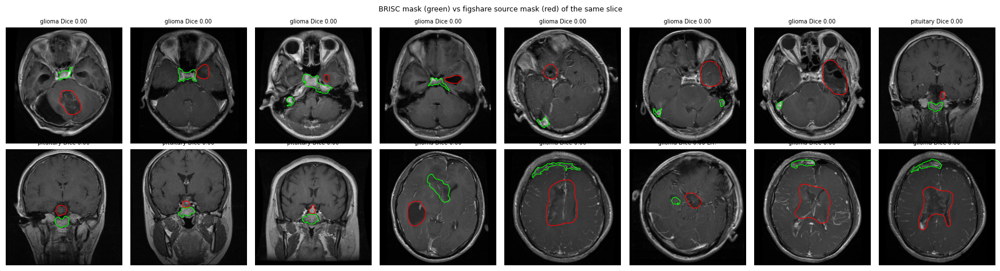


  23.8  SAVE
saved cell23_errata.csv (327 rows, 322 images), cell23_summary.json

------------------------------------------------------------------------------
  [PASS]  every errata row names an existing image
------------------------------------------------------------------------------
CELL 23 CLEAN.


In [41]:
# =============================================================================
#  CELL 23  |  Exploratory: dataset errata for expert review (labels, masks, planes)
# =============================================================================
assert "MD" in globals() and "TWA" in globals() and "ALLTW" in globals() and "stratum" in df.columns, "Run Cells 5-7 first."

MASK_LOW = 0.5          # BRISC vs source mask Dice below this is listed
LR_GAIN  = 0.3          # ... and marked "possibly mirrored left-right" when the mirrored source mask agrees this much better
N_SHOW   = 16
import matplotlib.pyplot as plt
checks, notes = {}, []
ERR = []
def add_err(row, issue, evidence):
    ERR.append({"row": int(row), "image_id": df.image_id[int(row)], "split": df.split[int(row)], "label": df.label[int(row)],
                "plane": df.plane[int(row)], "issue": issue, "evidence": evidence})

# ----- 23.1 labels that differ from the source ---------------------------------------------------------------------------
banner("23.1  BRISC LABEL DIFFERS FROM THE FIGSHARE SOURCE LABEL OF THE SAME SLICE")
tr_ = df[df.traced.astype(bool)]
lb = tr_[tr_.label != tr_.fig_label]
for i, r in lb.iterrows():
    add_err(i, "label differs from the source label", f"source label {r.fig_label}, patient {r.fig_pid}, NCC {r.fig_ncc:.3f}")
print(f"{len(lb)} images" + ("" if lb.empty else ":\n" + lb[["image_id", "split", "label", "fig_label", "fig_pid", "fig_ncc"]].round(3).to_string()))

# ----- 23.2 near-identical images with different labels ----------------------------------------------------------------------
banner("23.2  NEAR-IDENTICAL IMAGES (NCC >= 0.95) WITH DIFFERENT CLASS LABELS")
lab_ = df.label.to_numpy()
tw_all = pd.concat([TWA[["row", "twin_row", "ncc", "mirrored"]], ALLTW[["row", "twin_row", "ncc", "mirrored"]]], ignore_index=True)
tw_all = tw_all[lab_[tw_all.row.to_numpy().astype(int)] != lab_[tw_all.twin_row.to_numpy().astype(int)]].copy()
tw_all["a"], tw_all["b"] = tw_all[["row", "twin_row"]].min(1).astype(int), tw_all[["row", "twin_row"]].max(1).astype(int)
tw_all = tw_all.sort_values("ncc", ascending=False).drop_duplicates(["a", "b"])
for _, r in tw_all.iterrows():
    for x_, y_ in ((r.a, r.b), (r.b, r.a)):
        add_err(x_, "near-identical image carries a different label",
                f"twin {df.image_id[int(y_)]} ({df.split[int(y_)]}, {df.label[int(y_)]}), NCC {r.ncc:.3f}{', mirrored' if r.mirrored else ''}")
print(f"{len(tw_all)} pairs" + ("" if tw_all.empty else ":\n" + pd.DataFrame(
    {"image a": df.image_id.to_numpy()[tw_all.a], "label a": lab_[tw_all.a], "image b": df.image_id.to_numpy()[tw_all.b],
     "label b": lab_[tw_all.b], "ncc": tw_all.ncc.round(3).to_numpy(), "mirrored": tw_all.mirrored.to_numpy()}).to_string(index=False)))

# ----- 23.3 one patient, several labels ----------------------------------------------------------------------------------------
banner("23.3  ONE SOURCE PATIENT, SEVERAL BRISC LABELS  (traced images, all splits)")
nl = tr_.groupby("fig_pid").label.nunique(); mp_ = nl[nl > 1].index
for i, r in tr_[tr_.fig_pid.isin(mp_)].iterrows():
    add_err(i, "patient's slices carry different BRISC labels", f"patient {r.fig_pid}: BRISC labels "
            f"{sorted(tr_[tr_.fig_pid == r.fig_pid].label.unique())}, source label {r.fig_label}")
print(f"{len(mp_)} patients" + ("" if not len(mp_) else ":\n" + tr_[tr_.fig_pid.isin(mp_)].sort_values(["fig_pid", "split"])
      [["fig_pid", "image_id", "split", "plane", "label", "fig_label"]].to_string(index=False)))

# ----- 23.4 masks that disagree with the source mask of the same slice --------------------------------------------------------
banner(f"23.4  BRISC MASK vs SOURCE MASK OF THE SAME SLICE: Dice < {MASK_LOW}  (and is the mirrored source mask closer?)")
res5 = globals().get("res"); MSK = []
if res5 is not None and "FIG_MSK" in globals() and len(MD):
    for _, r in MD[MD.mask_dice < MASK_LOW].iterrows():
        i = int(r.row); j = int(res5[i, 1]); v = int(res5[i, 2]); dx, dy = int(res5[i, 3]), int(res5[i, 4])
        al = align(d4(FIG_MSK[j], v), dx, dy) > 0; b_ = MKc[i] > 0
        d_m = float(dice_of(b_, al[:, ::-1]))
        lr = d_m - float(r.mask_dice) >= LR_GAIN
        MSK.append({"row": i, "image_id": df.image_id[i], "label": df.label[i], "mask_dice": float(r.mask_dice),
                    "dice_vs_mirrored_source": d_m, "possibly_mirrored_left_right": bool(lr), "brisc_px": int(b_.sum()), "source_px": int(al.sum())})
        add_err(i, "mask disagrees with the source mask" + (" (possibly mirrored left-right)" if lr else ""),
                f"Dice {r.mask_dice:.3f}; vs mirrored source mask {d_m:.3f}")
MSKd = pd.DataFrame(MSK, columns=["row", "image_id", "label", "mask_dice", "dice_vs_mirrored_source", "possibly_mirrored_left_right",
                                  "brisc_px", "source_px"])
print(f"{len(MSKd)} of {len(MD)} compared slices; possibly mirrored left-right: {int(MSKd.possibly_mirrored_left_right.sum()) if len(MSKd) else 0}")
if len(MSKd):
    print(MSKd.sort_values("mask_dice").head(40).round(3).to_string(index=False))

# ----- 23.5 near-zero Dice where the model matches the MIRRORED BRISC mask (Cell 17) ----------------------------------------------
banner("23.5  MODEL PREDICTION MATCHES THE MIRRORED BRISC MASK  (Cell 17, decontaminated model)")
p17 = WORK / "cell17_low_dice.csv"; n17 = 0
if p17.exists():
    L17 = pd.read_csv(p17)
    L17 = L17[L17.dice_vs_mirrored_label >= 0.5] if len(L17) else L17
    for _, r in L17.iterrows():
        add_err(r.row, "prediction matches the mirrored BRISC mask", f"Dice {r.dice:.3f}; vs mirrored mask {r.dice_vs_mirrored_label:.3f}")
    n17 = len(L17); print(f"{n17} images" + ("" if not n17 else ":\n" + L17.round(3).to_string(index=False)))
else:
    print("cell17_low_dice.csv not found (Cell 17 needs B_flip)")

# ----- 23.6 disputed plane labels (Cell 13) ----------------------------------------------------------------------------------------
banner("23.6  FILE-NAME PLANE DISPUTED BY A CONFIDENT PLANE CLASSIFIER  (Cell 13)")
p13 = WORK / "cell13_plane_flags.csv"; n13 = 0
if p13.exists():
    L13 = pd.read_csv(p13); id2row = {v: k for k, v in df.image_id.items()}
    for _, r in L13.iterrows():
        add_err(id2row[r.image_id], "plane label disputed", f"file name {r.plane}, classifier {r.predicted} (p = {r.p:.2f})")
    n13 = len(L13); print(f"{n13} images (listed in cell13_plane_flags.csv; drawn in cell13_plane_flags.png)")

# ----- 23.7 the errata table and a figure for the reader --------------------------------------------------------------------------
banner("23.7  ERRATA TABLE  (for review by a neuroradiologist; nothing here is corrected automatically)")
ERRd = pd.DataFrame(ERR, columns=["row", "image_id", "split", "label", "plane", "issue", "evidence"])
print(ERRd.groupby("issue").agg(images=("image_id", "nunique"), test=("split", lambda s_: int((s_ == "test").sum()))).to_string())
with pd.option_context("display.max_colwidth", 70, "display.max_rows", 200):
    print(ERRd.drop(columns=["row"]).head(120).to_string(index=False) + ("\n..." if len(ERRd) > 120 else ""))
ERRd.to_csv(WORK / "cell23_errata.csv", index=False)
if len(MSKd):
    sh = MSKd.sort_values("mask_dice").head(N_SHOW); cols = min(8, len(sh)); rws = int(np.ceil(len(sh) / cols))
    fig, ax = plt.subplots(rws, cols, figsize=(2.2 * cols, 2.4 * rws), squeeze=False)
    for a_ in ax.ravel():
        a_.axis("off")
    for k, (_, r) in enumerate(sh.iterrows()):
        i = int(r.row); j = int(res5[i, 1]); v = int(res5[i, 2])
        al = align(d4(FIG_MSK[j], v), int(res5[i, 3]), int(res5[i, 4])) > 0
        a_ = ax[k // cols, k % cols]; a_.imshow(IMc[i], cmap="gray")
        a_.contour(MKc[i] > 0, levels=[0.5], colors="lime", linewidths=0.8)
        if al.any():
            a_.contour(al, levels=[0.5], colors="red", linewidths=0.8)
        a_.set_title(f"{r.label[:9]} Dice {r.mask_dice:.2f}{' LR?' if r.possibly_mirrored_left_right else ''}", fontsize=7)
    plt.suptitle("BRISC mask (green) vs figshare source mask (red) of the same slice", fontsize=9)
    plt.tight_layout(); plt.savefig(WORK / "cell23_errata_masks.png", dpi=100, bbox_inches="tight"); plt.show()

# ----- 23.8 save ------------------------------------------------------------------------------------------------------------------------
banner("23.8  SAVE")
counts = ERRd.groupby("issue").image_id.nunique().to_dict()
checks["every errata row names an existing image"] = bool(ERRd.image_id.isin(set(df.image_id)).all())
save_json(WORK / "cell23_summary.json", {"exploratory": True, "counts": counts, "images_with_any_issue": int(ERRd.image_id.nunique()),
                                         "test_images_with_any_issue": int(ERRd[ERRd.split == "test"].image_id.nunique()),
                                         "label_vs_source": int(len(lb)), "cross_label_twin_pairs": int(len(tw_all)),
                                         "mixed_label_patients": int(len(mp_)), "mask_low": int(len(MSKd)),
                                         "mask_possibly_mirrored": int(MSKd.possibly_mirrored_left_right.sum()) if len(MSKd) else 0,
                                         "model_matches_mirrored_mask": int(n17), "plane_disputed": int(n13)})
print(f"saved cell23_errata.csv ({len(ERRd)} rows, {ERRd.image_id.nunique()} images), cell23_summary.json")
finish(23, checks, notes)

# F. Conclusions and package

## Cell 24 | The answers, read from the outputs

**Purpose.** One table with every pre-specified quantity (data findings D1-D5, round 1: Q1, Q2, Q2b, Q3, error anatomy E; round 2: Q4, Q5), the robustness checks (R) and the exploratory analyses (X): estimate, 95% interval, per-seed values, verdict by the fixed rule, and the cell it comes from; a check that the round-1 headline numbers reproduce the 9 Oct 2026 analysis exactly (same runs); and the reproducibility record (data fingerprint, split fingerprints, seeds, environment). Nothing here is typed by hand.

**Inputs.** `cellNN_summary.json` of Cells 2-23. **Outputs.** `paper_results.csv`, `paper_results.json`.

**Pass criteria.** (1) No smoke-test numbers (in SMOKE mode the cell fails on purpose and does not write `paper_results.*`). (2) Every summary comes from one pass through Cells 2-23 (none older than the one of the cell before it). (3) Round-1 headline numbers equal those of 9 Oct 2026 to four decimals. Questions without finished runs are named as NOTES.

In [42]:
# =============================================================================
#  CELL 24  |  Conclusions: every number below is read from the saved outputs of
#              Cells 2-23. Nothing is typed by hand.
# =============================================================================
assert (WORK / "cell14_summary.json").exists(), "Run Cells 12-23 first."

REF_R1 = {  # round-1 values of the 9 Oct 2026 analysis (same runs): this version must reproduce them to 4 decimals
    ("D1", "official test images with a near-identical training image (NCC >= 0.95)"): 537,
    ("D1", "  of which mirrored"): 432,
    ("D2", "BRISC images traced to the figshare source"): 4028,
    ("Q1", "usual recipe minus decontaminated: macro_f1"): 0.0574,
    ("Q1", "usual recipe minus decontaminated: dice"): 0.0927,
    ("Q2", "exposure effect on dice: copy_plain (105 images)"): 0.0457,
    ("Q2", "exposure effect on dice: copy_mirror (432 images)"): 0.0190,
    ("Q3", "B_flip_film - B_flip_placebo: macro_f1"): 0.0110,
}
CELLS = (2, 3, 5, 6, 7, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23)

def load(n):
    p_ = WORK / f"cell{n:02d}_summary.json"
    return json.loads(p_.read_text()) if p_.exists() else {}
S = {n: load(n) for n in CELLS}
env = json.loads((WORK / "env.json").read_text())
checks, notes, table = {}, [], []
# every summary must come from the same pass through the cells: none older than the one of the cell before it
order_ = [n for n in CELLS if (WORK / f"cell{n:02d}_summary.json").exists()]
mt_ = {n: (WORK / f"cell{n:02d}_summary.json").stat().st_mtime for n in order_}
stale = [b for a, b in zip(order_, order_[1:]) if mt_[b] < mt_[a]]
checks["every summary is newer than the one of the cell before it (one pass through Cells 2-23)"] = not stale
if stale:
    notes.append(f"stale summaries (older than the cell before them): Cells {stale}. Re-run Cells {stale[0]}-23, then this cell.")

def add(q, what, est, lo=None, hi=None, per=None, verdict="", cell=""):
    table.append({"question": q, "quantity": what, "estimate": est, "95% CI": None if lo is None else f"[{lo:+.4f}, {hi:+.4f}]",
                  "per seed": None if per is None else " ".join(f"{x:+.4f}" for x in per), "verdict": verdict, "cell": cell})
def add_eff(q, what, v, cell, verdict=None):
    add(q, what, v["effect"], v["lo"], v["hi"], v.get("per_seed"), v["verdict"] if verdict is None else verdict, cell)

# ----- 24.1 the data ------------------------------------------------------------------------------------------
st7 = S[7].get("strata", {})
n_copy = st7.get("copy_plain", 0) + st7.get("copy_mirror", 0)
add("D1", "official test images with a near-identical training image (NCC >= 0.95)", n_copy, cell="7")
add("D1", "  of which mirrored", st7.get("copy_mirror", 0), cell="7")
add("D1", "official test images sharing a source patient with training (no pixel twin)", st7.get("patient_only", 0), cell="7")
add("D1", "official test images with no link of any kind to training", st7.get("unlinked", 0), cell="7")
if S[5]:
    add("D2", "BRISC images traced to the figshare source", S[5].get("traced"), cell="5")
    add("D2", "  stored mirrored relative to their source slice", S[5].get("mirrored_vs_source"), cell="5")
    add("D2", "median Dice, BRISC mask vs the source mask of the same slice", S[5].get("mask_dice_median"), cell="5")
if S[13]:
    add("D3", "accuracy of a geometry-only classifier (no pixels) on the official test", S[13]["geometry_only"]["acc"], cell="13")
    add("D3", "accuracy of always predicting the majority class", S[13]["majority"]["acc"], cell="13")
    add("D3", "plane predictable from frozen generic features (out-of-fold accuracy)", S[13]["plane_oof_accuracy"], cell="13")
if S[18]:
    s18 = S[18]
    add("D4", "copy_plain test images flagged by the Huang et al. rule / the Vangala et al. rule (exploratory)",
        f"{s18['copy_plain_flagged_huang']} / {s18['copy_plain_flagged_vangala']} of {st7.get('copy_plain', 0)}", cell="18")
    add("D4", "copy_mirror test images flagged by the Huang et al. rule / the Vangala et al. rule (exploratory)",
        f"{s18['copy_mirror_flagged_huang']} / {s18['copy_mirror_flagged_vangala']} of {s18['copy_mirror_images']}", cell="18")
    add("D4", "copy_mirror test images missed by both published rules as described (exploratory)", s18["copy_mirror_missed_by_both"], cell="18")
    add("D4", "test images unlinked here but flagged by a published rule (inspect)", s18["discordant_unlinked"], cell="18")
if S[23]:
    for k, v in S[23].get("counts", {}).items():
        add("D5", f"errata for expert review: {k} (images; exploratory)", v, cell="23")

# ----- 24.2 round 1: the pre-specified questions Q1-Q3 ------------------------------------------------------------
q1 = S[14].get("Q1", {})
for arm in ("full_flip", "B_flip", "cross_unexposed"):
    if arm in q1:
        for k in ("macro_f1", "dice"):
            v = q1[arm][k]; add("Q1", f"{arm}: {k}", v["value"], v["lo"], v["hi"], v["per_seed"], cell="14")
for k, v in (S[14].get("full_minus_B") or {}).items():
    if k in ("macro_f1", "dice", "mean_logp_true"):
        add("Q1", f"usual recipe minus decontaminated: {k}", v["effect"], v["lo"], v["hi"], v["per_seed"], v["verdict"], "14")
for r in (S[15].get("Q2") or []):
    if r["metric"] in ("dice", "logp_true"):
        add("Q2", f"exposure effect on {r['metric']}: {r['stratum']} ({r['images']} images)", r["effect"], r["lo"], r["hi"],
            [float(x) for x in r["per_seed"].split()], r["verdict"], "15")
for r in (S[15].get("Q2b_interaction") or []):
    if r["contrast"].startswith("INTERACTION"):
        add("Q2b", f"flip x mirror interaction on {r['metric']} (mirror minus plain)", r["estimate"], r["lo"], r["hi"],
            [float(x) for x in r["per_seed"].split()], r["verdict"], "15")
for name, eff in (S[16].get("effects") or {}).items():
    for k in ("macro_f1", "dice"):
        if k in eff:
            v = eff[k]; add("Q3", f"{name}: {k}", v["effect"], v["lo"], v["hi"], v["per_seed"], v["verdict"], "16")
for r in (S[17].get("anatomy") or []):
    add("E", f"{r['label']}: mean Dice / if detection fixed / if edges fixed / if far errors fixed",
        f"{r['mean_dice']:.4f} / {r['dice_if_detection_fixed']:.4f} / {r['dice_if_edges_fixed']:.4f} / "
        f"{r['dice_if_far_errors_fixed']:.4f}", cell="17")

# ----- 24.3 round 2: Q4 and Q5 ----------------------------------------------------------------------------------------
for arm, keys in (("B_flip_seg", ("dice",)), ("B_flip_cls", ("macro_f1",)), ("full_flip_seg", ("dice",)), ("full_flip_cls", ("macro_f1",))):
    for k in keys:
        v = (S[19].get("arms") or {}).get(arm, {}).get(k)
        if v:
            add("Q4", f"{arm}: {k}", v["value"], v["lo"], v["hi"], v["per_seed"], cell="19")
for name, eff in (S[19].get("effects") or {}).items():
    for k in ("dice", "macro_f1"):
        if k in eff:
            add_eff("Q4", f"{name}: {k}{'  (PRIMARY)' if eff[k].get('primary') else ''}", eff[k], "19")
for k, v in (S[19].get("interaction") or {}).items():
    add_eff("Q4", f"multi-task gain on Full minus gain on B: {k} (descriptive)", v, "19")
for k in ("macro_f1", "dice"):
    v = (S[20].get("arms") or {}).get("Fm_flip", {}).get(k)
    if v:
        add("Q5", f"Fm_flip: {k}", v["value"], v["lo"], v["hi"], v["per_seed"], cell="20")
for name, eff in (S[20].get("effects") or {}).items():
    if name == "full_flip - B_flip":
        continue
    for k in ("macro_f1", "dice"):
        if k in eff:
            add_eff("Q5", f"{name}: {k}{'  (PRIMARY)' if eff[k].get('primary') else ''}", eff[k], "20")
for k, v in (S[20].get("share_of_Q1_gap") or {}).items():
    add("Q5", f"share of the Q1 gap reproduced at a fixed quantity: {k} (descriptive)", v["share"], v["lo"], v["hi"], cell="20")

# ----- 24.4 robustness (round 2, descriptive) -------------------------------------------------------------------------------
for label_, eff in (S[21].get("q1_selection") or {}).items():
    if label_.startswith("replicate"):
        for k in ("macro_f1", "dice"):
            add_eff("R", f"Q1 ({label_}): full minus B, {k}", eff[k], "21")
for label_, rows_ in (S[21].get("q2_selection") or {}).items():
    for r in rows_:
        if r["metric"] in ("dice", "logp_true") and r["stratum"] in ("copy_plain", "copy_mirror", "unlinked"):
            add("R", f"Q2 ({label_}): exposure effect on {r['metric']}, {r['stratum']}", r["effect"], r["lo"], r["hi"],
                [float(x) for x in r["per_seed"].split()], r["verdict"], "21")
for r in (S[21].get("run_to_run") or []):
    if "same class" in r:
        add("R", f"run-to-run, {r['arm']} seed 1337: share of test images with the same predicted class / mean |dDice|",
            f"{r['same class']:.4f} / {r['mean |dDice|']:.4f}", cell="21")
for r in (S[21].get("mde") or []):
    if r["stratum"] == "unlinked":
        add("R", f"negative control (unlinked, {r['images']} images): minimal detectable effect on {r['metric']} (exploratory)",
            r["MDE_80"], cell="21")
for r in (S[21].get("thresholds") or []):
    if r.get("theta") in (0.95, 0.98):
        add("R", f"strata at NCC >= {r['theta']}: copy_plain / copy_mirror / patient_only / related / unlinked (exploratory)",
            f"{r['copy_plain']} / {r['copy_mirror']} / {r['patient_only']} / {r['related']} / {r['unlinked']}", cell="21")

# ----- 24.5 exploratory trust analyses --------------------------------------------------------------------------------------
cal = S[22].get("calibration") or {}
for arm in ("B_flip", "full_flip", "Fm_flip"):
    for k in ("ece", "brier"):
        if arm in cal:
            v = cal[arm][k]; add("X", f"{arm}: {k} (exploratory)", v["value"], v["lo"], v["hi"], v["per_seed"], cell="22")
for k, v in (S[22].get("crossover_differences") or {}).items():
    add_eff("X", f"exposed minus unexposed model, linked test images: {k} (exploratory)", v, "22")
for arm, v in (S[22].get("ensemble") or {}).items():
    add("X", f"{arm}: 3-seed ensemble accuracy / AUROC flagging its errors (exploratory)",
        f"{v['ensemble_accuracy']:.4f} / {v['auroc_error_1_minus_maxp']:.4f}", cell="22")
    add("X", f"{arm}: Spearman(seed disagreement of masks, Dice) (exploratory)", v["seg_spearman_disagreement_vs_dice"], cell="22")
for arm, v in (S[22].get("patients") or {}).items():
    add("X", f"{arm}: slice-level / patient-level accuracy on traced test patients (exploratory)",
        f"{v['slice_accuracy']:.4f} / {v['patient_accuracy']:.4f} ({v['patients_correct']}/{v['patients_scored']})", cell="22")
u_ = S[22].get("memorisation_uncertainty") or {}
if u_:
    add("X", "AUROC separating unexposed from exposed predictions by uncertainty (exploratory)",
        u_["auroc_unexposed_vs_exposed_1_minus_maxp"], cell="22")

# ----- 24.6 print -------------------------------------------------------------------------------------------------------------
banner("24.1  DATA (D1-D5), ROUND 1 (Q1-Q3), ERROR ANATOMY (E), ROUND 2 (Q4, Q5), ROBUSTNESS (R), EXPLORATORY (X)")
T = pd.DataFrame(table)
T["estimate"] = [round(v, 4) if isinstance(v, float) else v for v in T.estimate]
T = T.fillna("")
with pd.option_context("display.max_colwidth", 100, "display.max_rows", 500):
    print(T[T.question.str.startswith("D")].drop(columns=["95% CI", "per seed", "verdict"]).to_string(index=False))
    for grp_, title in ((("Q1", "Q2", "Q2b", "Q3", "E"), "ROUND 1"), (("Q4", "Q5"), "ROUND 2"), (("R",), "ROBUSTNESS"), (("X",), "EXPLORATORY")):
        sub_ = T[T.question.isin(grp_)]
        if len(sub_):
            print(f"\n--- {title} ---"); print(sub_.to_string(index=False))
answered = {q: any(t["question"] == q and t["verdict"] for t in table) for q in ("Q1", "Q2", "Q3", "Q4", "Q5")}
for q, ok in answered.items():
    if not ok:
        notes.append(f"{q} has no verdict yet: its runs are not finished (Cell 11).")
print("\nVerdict rule (fixed before the runs): 'supported' = the 95% group-bootstrap interval excludes 0 AND every seed")
print("agrees in sign. Otherwise 'not supported'; the estimate and interval are reported either way. 'descriptive' rows have")
print("one seed or were not pre-specified; 'exploratory' rows were not pre-specified (labelled so in the manuscript).")

# ----- 24.7 reproduction of round 1 ----------------------------------------------------------------------------------------------
banner("24.2  ROUND 1 REPRODUCED?  (same 24 runs; values of the 9 Oct 2026 analysis)")
if not SMOKE:
    got = {(t["question"], t["quantity"]): t["estimate"] for t in table}
    rep = [{"question": q, "quantity": w, "9 Oct 2026": ref, "now": got.get((q, w)),
            "same": got.get((q, w)) is not None and round(float(got[(q, w)]), 4) == round(float(ref), 4)} for (q, w), ref in REF_R1.items()]
    print(pd.DataFrame(rep).to_string(index=False))
    checks["round-1 headline numbers reproduce the 9 Oct 2026 analysis (4 decimals)"] = all(r["same"] for r in rep)
else:
    print("smoke test: not applicable")

# ----- 24.8 reproducibility ---------------------------------------------------------------------------------------------------------
banner("24.3  REPRODUCIBILITY")
rd = S[12].get("runs_done", [])
repro = {"kaggle_version": env.get("kaggle_version"), "data_fingerprint": env.get("data_fingerprint"), "torch": env.get("torch"),
         "gpu": env.get("gpu"), "scikit_learn": env.get("scikit_learn"), "split_sig": S[6].get("split_sig"), "seeds": list(SEEDS),
         "epochs": EPOCHS, "runs_done": len(rd), "runs_planned": len(GRID),
         "round1_done": sum(1 for g in GRID if g["ext"] is None and g["tag"] in rd), "round2_done": sum(1 for g in GRID if g["ext"] and g["tag"] in rd),
         "last_epoch_sets": len(S[12].get("last_epoch_sets", [])), "fm_sig": FM_SIG, "smoke_test": SMOKE}
for k, v in repro.items():
    print(f"{k:16s}: {v}")
checks["no smoke-test numbers in the conclusions"] = not SMOKE
out_ = "paper_results" if not SMOKE else "SMOKE_TEST_not_results"
T.to_csv(WORK / f"{out_}.csv", index=False)
save_json(WORK / f"{out_}.json", {"table": table, "reproducibility": repro})
print(f"\nsaved {out_}.csv / {out_}.json" + (": the ONLY source of numbers for the manuscript." if not SMOKE else
      " (smoke test: paper_results.csv is NOT written)"))
finish(24, checks, notes)


  24.1  DATA (D1-D5), ROUND 1 (Q1-Q3), ERROR ANATOMY (E), ROUND 2 (Q4, Q5), ROBUSTNESS (R), EXPLORATORY (X)
question                                                                                                           quantity         estimate cell
      D1                                            official test images with a near-identical training image (NCC >= 0.95)              537    7
      D1                                                                                                  of which mirrored              432    7
      D1                                        official test images sharing a source patient with training (no pixel twin)              247    7
      D1                                                          official test images with no link of any kind to training              198    7
      D2                                                                         BRISC images traced to the figshare source             4028    5
      D2       

## Cell 25 | The manuscript package

**Purpose.** Pack into one zip everything the manuscript needs, so nothing has to be re-run to write or check it: `paper_results.csv/json`, every cell summary, the per-image tables, the final manifest (groups, roles, sets, strata, patients), the figures, and every run's configuration, training history and predictions (best epoch; round 2 also last epoch). Checkpoints and pickles are left out. The zip is copied to Drive (when mounted) and downloaded.

**Inputs.** Everything above. **Outputs.** `BRISC_manuscript_package_<date>.zip`, `manifest_final.csv`, `cell07_nulls.npz`.

**Pass criteria.** The zip opens and passes its CRC check; it holds `paper_results` and the predictions of every finished run; it holds no checkpoint or pickle.

*Send back two files: the executed notebook (File > Download > Download .ipynb), which keeps every printed result, and this zip.*

In [43]:
# =============================================================================
#  CELL 25  |  The manuscript package: one zip with every number, table, figure and run
#              prediction the manuscript needs (checkpoints and pickles excluded)
# =============================================================================
OUT_JSON = WORK / ("paper_results.json" if not SMOKE else "SMOKE_TEST_not_results.json")
assert OUT_JSON.exists(), "Run Cell 24 first."

PKG = WORK / f"BRISC_manuscript_package_{time.strftime('%Y%m%d')}{'_SMOKE' if SMOKE else ''}.zip"
checks, notes = {}, []

# ----- 25.1 small extras that exist only in memory ----------------------------------------------------------------------
banner("25.1  EXTRAS")
np.savez_compressed(WORK / "cell07_nulls.npz", null1_random_pairs=np.asarray(null, float),
                    null2_other_patient=np.asarray(null2, float))
df.drop(columns=[c for c in ("image_path", "mask_path") if c in df.columns]).to_csv(WORK / "manifest_final.csv", index=False)
print("saved cell07_nulls.npz (the two null distributions of Cell 7) and manifest_final.csv (every column, no local paths)")

# ----- 25.2 what goes in --------------------------------------------------------------------------------------------------
banner("25.2  CONTENTS")
groups_ = {
    "results": [OUT_JSON, OUT_JSON.with_suffix(".csv"), WORK / "env.json", WORK / "cell04_cache.json"]
               + sorted(WORK.glob("cell*_summary.json")),
    "tables": [p_ for p_ in sorted(WORK.glob("cell*.csv"))] + [WORK / "per_image.csv.gz", RUNS / "index.csv"],
    "data": [WORK / "manifest_final.csv", WORK / "manifest_cell07.csv", WORK / "cell07_nulls.npz", WORK / "cell03_phash.npz"],
    "figures": sorted(WORK.glob("cell*.png")),
}
README = f"""BRISC 2025 contamination-controlled multi-task study: manuscript package
Built {time.strftime('%Y-%m-%d %H:%M')} by Cell 25 of the notebook (version 2). Smoke test: {SMOKE}.

results/   paper_results.csv/json (Cell 24): the ONLY source of numbers for the manuscript; cellNN_summary.json of
           every cell (inputs of Cell 24); env.json (software, GPU, data fingerprint); cell04_cache.json.
tables/    per-image and per-pair tables written by the cells (file names carry the cell number); per_image.csv.gz
           (one row per run x test image, Cell 12; arms ending in '@last' = last epoch); index.csv (run status).
data/      manifest_final.csv (every image: split, class, plane, size family, groups, roles, sets, stratum, figshare
           patient and orientation); manifest_cell07.csv; the null distributions of Cell 7; perceptual hashes (Cell 3).
figures/   every figure the notebook drew (cellNN_*.png).
runs/      for every run: done.json (configuration, signature, best epoch, minutes, GPU), history.csv (per epoch),
           pred_val.npz / pred_test.npz (best epoch: probabilities, per-image Dice/IoU, packed masks), and for round-2
           runs pred_val_last.npz / pred_test_last.npz (last epoch). Checkpoints (.pt) are not included.

Rounds: round 1 = 24 runs (Q1-Q3, fixed 8 Oct 2026); round 2 = 19 runs (Q4, Q5, fixed-epoch replicate, fixed 10 Oct 2026).
Exploratory analyses (not pre-specified) are labelled 'exploratory' or 'descriptive' in every table.
Data fingerprint: {json.loads((WORK / 'env.json').read_text()).get('data_fingerprint')}   split: {SPLIT_SIG}   set Fm: {FM_SIG}
"""
(WORK / "README_package.txt").write_text(README)
n_files, missing = 0, []
tmp_ = PKG.with_name(PKG.name + ".tmp")
with zipfile.ZipFile(tmp_, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(WORK / "README_package.txt", "README.txt"); n_files += 1
    for folder, paths in groups_.items():
        for p_ in dict.fromkeys(paths):                     # keep order, drop duplicates
            if p_.exists():
                z.write(p_, f"{folder}/{p_.name}"); n_files += 1
            else:
                missing.append(f"{folder}/{p_.name}")
    for g in GRID:
        for n in RUN_FILES:
            p_ = run_dir(g["tag"]) / n
            if p_.exists():
                z.write(p_, f"runs/{g['tag']}/{n}"); n_files += 1
os.replace(tmp_, PKG)
with zipfile.ZipFile(PKG) as z:
    names = z.namelist(); bad = z.testzip()
    sizes = pd.DataFrame([{"folder": n.split("/")[0] if "/" in n else "(top)", "bytes": z.getinfo(n).file_size} for n in names])
print(sizes.groupby("folder").agg(files=("bytes", "size"), MB=("bytes", lambda b: round(b.sum() / 1e6, 2))).to_string())
print(f"\n{PKG.name}: {n_files} files, {PKG.stat().st_size / 1e6:.1f} MB compressed")
if missing:
    print("not found (skipped):", ", ".join(missing))
runs_in = sorted({n.split("/")[1] for n in names if n.startswith("runs/")})
print(f"runs included: {len(runs_in)} of {len(GRID)}")
checks["the zip opens and every member passes its CRC check"] = bad is None
checks["paper_results and every run's predictions are in the zip"] = (
    f"results/{OUT_JSON.name}" in names and all(f"runs/{g['tag']}/pred_test.npz" in names for g in GRID if is_done(g["tag"])))
checks["no checkpoint or pickle in the zip"] = not any(n.endswith((".pt", ".pkl")) for n in names)

# ----- 25.3 deliver ---------------------------------------------------------------------------------------------------------
banner("25.3  DELIVER")
if DRIVE_RUNS is not None:
    try:
        shutil.copy2(PKG, DRIVE_RUNS.parent / PKG.name); print(f"copied to Drive: {DRIVE_RUNS.parent / PKG.name}")
    except OSError as e:
        print(f"Drive copy failed ({e})")
try:
    from google.colab import files as colab_files
    colab_files.download(str(PKG)); print("download started in the browser")
except Exception as e:
    print(f"not in Colab or the download was blocked ({type(e).__name__}): take {PKG} from the Files panel")
notes.append("send back two files: this notebook with its outputs (File > Download > Download .ipynb) and "
             f"{PKG.name}. Keep results_bundle.zip as well: it restores every run in a new session.")
finish(25, checks, notes)


  25.1  EXTRAS
saved cell07_nulls.npz (the two null distributions of Cell 7) and manifest_final.csv (every column, no local paths)

  25.2  CONTENTS
         files     MB
folder               
(top)        1   0.00
data         4   4.82
figures     14  10.43
results     23   0.24
runs       210   7.40
tables      26   9.22

BRISC_manuscript_package_20261012.zip: 278 files, 24.2 MB compressed
runs included: 43 of 43

  25.3  DELIVER
copied to Drive: /content/drive/MyDrive/BRISC_manuscript_package_20261012.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

download started in the browser

------------------------------------------------------------------------------
  [PASS]  the zip opens and every member passes its CRC check
  [PASS]  paper_results and every run's predictions are in the zip
  [PASS]  no checkpoint or pickle in the zip
  [NOTE]  send back two files: this notebook with its outputs (File > Download > Download .ipynb) and BRISC_manuscript_package_20261012.zip. Keep results_bundle.zip as well: it restores every run in a new session.
------------------------------------------------------------------------------
CELL 25 CLEAN.


# G. Follow-up checks

## Cell 26 | Follow-up checks after the first full run (added 11 Oct 2026; exploratory)

**Why.** The first full run (10 Oct 2026) raised two questions that need the images. (1) Cell 18 found test images that this study calls *unlinked* but that a published rule links to a training image; several are pixel-for-pixel **mirrored** copies that the brain-cropped search of Cells 6-7 missed. (2) Cell 23 found traced test images whose BRISC mask hardly overlaps the figshare mask of the same slice, with BRISC masks on normal structures in several of them.

**Purpose.** (a) Screen every official test image against every training image *without* the brain crop (whole-image NCC at 128 x 128, both orientations), list the twins the crop-based search missed, say which training sets hold them (B, X1, X2, Full, Fm) and why they were missed (crop geometry). (b) On the traced test images, compare each model's masks with the BRISC mask and with the figshare mask: on suspect slices, a model that agrees with the figshare mask points to an error in the BRISC mask. Draws every suspect test slice and writes a review sheet for a neuroradiologist. (c) Lists the byte-identical files. (d) Re-estimates Q1, Q2, Q4 and Q5 with the same estimators, leaving out the hidden twins, the screen-flagged unlinked images and the suspect masks, in turn. (e) Splits the Q1 gap into steps with the round-1 crossover composites (descriptive): more training data with the image's relatives absent, then exposure to them, then more data again.

**Threshold.** A whole-image twin needs NCC >= 0.98, stricter than the 0.95 used after the brain crop in Cells 6-7: with the black background included, two different slices of one head correlate more. The value was chosen after the first full run, where the 64 x 64 whole-image NCC of Cell 18 separated the copies from adjacent slices of the same patient. 26.1 prints the distribution at 128 x 128 so the choice can be checked; pairs between 0.95 and 0.98 are listed and drawn as *borderline* and never counted.

**Inputs.** Cells 1-25 (nothing is retrained: Cell 11 restores every run). **Outputs.** `paper_results_followup.csv/json` (the source of every follow-up number in the manuscript), `cell26_summary.json`, `cell26_whole_twins.csv`, `cell26_mask_model_agreement.csv`, `cell26_mask_review.csv` (with empty columns for the reader), `cell26_sensitivity.csv`, `cell26_missed_twins.png`, `cell26_borderline.png`, `cell26_mask_review.png`. All are added to the manuscript package of Cell 25 (files of an earlier Cell 26 run are replaced), which is copied to Drive and downloaded again.

**Pass criteria.** The figshare masks are aligned exactly as in Cell 5 (its Dice reproduced); the suspect-mask comparison ran; the package still opens, passes its CRC check and holds the Cell 26 files next to every run's predictions. *Not pre-specified: everything here is exploratory and is reported as a sensitivity analysis.*


  26.1  WHOLE-IMAGE TWINS  (no brain crop, both orientations; every official test image vs every training image)
845 candidate pairs (64x64 NCC >= 0.95) scored at 128x128 in 7s; 613 pairs are whole-image twins (NCC >= 0.98) for 566 test images

best whole-image NCC at 128x128 per candidate test image, by stratum (twin: >= 0.98; borderline: 0.95-0.98).
A threshold is safe where few images fall close to it on either side:
band          < 0.95  0.95-0.97  0.97-0.98  0.98-0.99  0.99-0.995  >= 0.995
stratum                                                                    
copy_mirror        0          0          0          0           0       432
copy_plain         0          0          0          1           0       103
patient_only      38          3          0          0           0        11
related            2          0          0          0           0        11
unlinked           3          0          0          0           0         8

test images with a whole-image twin, by st

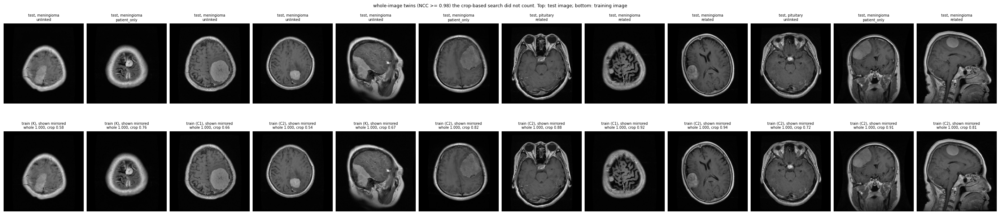


borderline: 3 test images outside the copy strata have a best whole-image NCC of 0.95-0.98 {'patient_only': 3}; not counted as twins. The closest are drawn below (adjacent slices, or twins?).


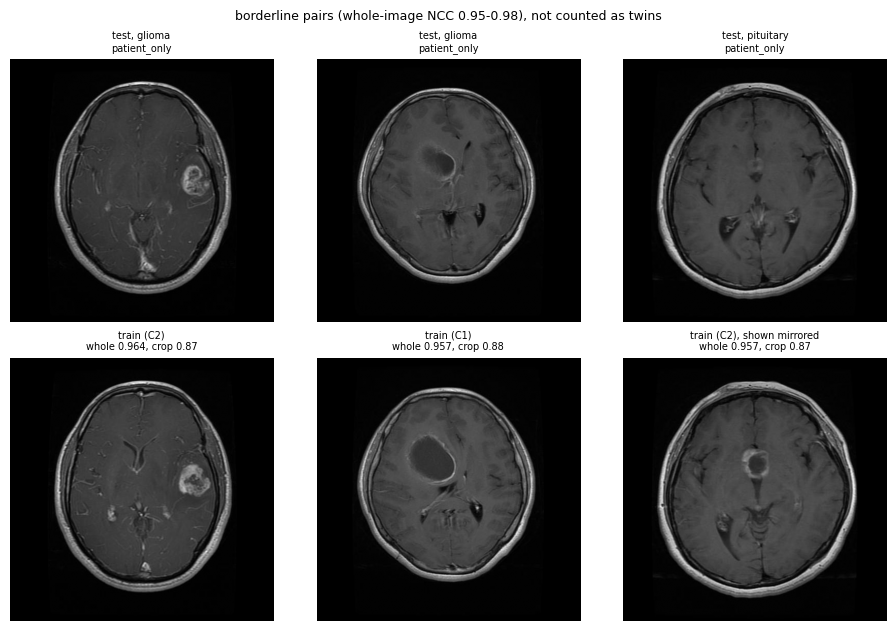


corrected counts: test images with a near-identical training image 567 (was 537); unlinked without a hidden twin 190 (was 198)

  26.3  SUSPECT MASKS  (traced test images whose BRISC mask has Dice < 0.5 with the figshare mask of the same slice)
traced test images with both masks compared (Cell 5): 589; suspect: 53
                              images  model_vs_brisc  model_vs_source  sides_with_figshare  sides_with_brisc
group             arm                                                                                       
agreeing (>= 0.9) B_flip         269           0.887            0.872                0.000             0.000
                  B_flip_seg     269           0.905            0.890                0.000             0.000
                  Fm_flip        269           0.897            0.884                0.000             0.000
                  full_flip      269           0.946            0.923                0.000             0.000
in between        B_flip     

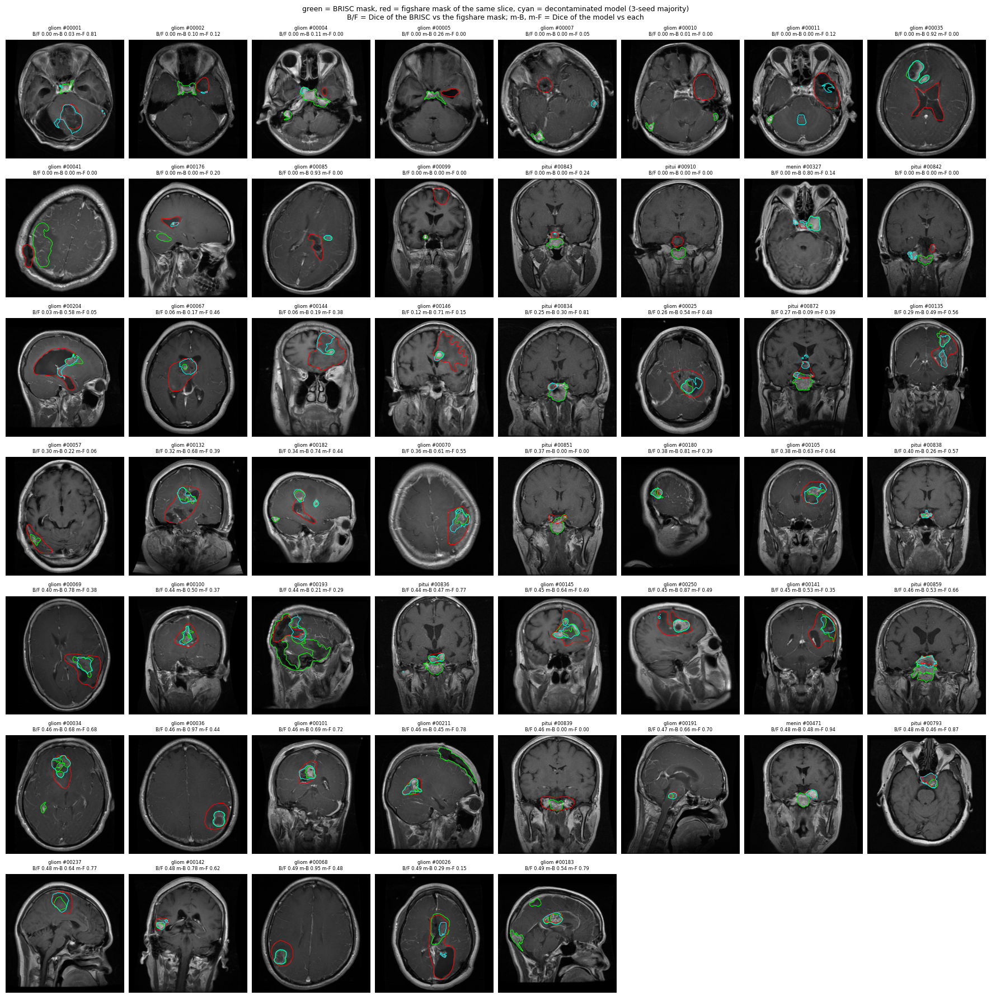


  26.4  EXACT DUPLICATES  (byte-identical files)
96 images in 46 sets of byte-identical files
splits                  labels    
test+test               glioma         1
                        meningioma     3
                        no_tumor       1
test+train              meningioma     2
                        pituitary      4
test+train+train+train  pituitary      1
train+train             meningioma    15
                        no_tumor       9
                        pituitary      8
train+train+train       meningioma     1
                        pituitary      1

  26.5  SENSITIVITY OF THE MAIN RESULTS  (the same estimators with some test images left out)
  all test images (as reported): 0 test images left out
  without hidden twins: 30 test images left out
  without hidden twins and screen-flagged unlinked: 76 test images left out
  without suspect masks: 53 test images left out
  without all of the above: 129 test images left out
                               all test im

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

download started in the browser

------------------------------------------------------------------------------
  [PASS]  the figshare masks are moved into the BRISC frame exactly as in Cell 5 (its Dice reproduced)
  [PASS]  the suspect-mask comparison ran
  [PASS]  the package still opens and passes its CRC check
  [PASS]  the package still holds paper_results and every run's predictions
  [PASS]  cell26 files are in the manuscript package
  [NOTE]  whole-image twin threshold 0.98 (set after the first full run): 0 candidate test images outside the copy strata have a best NCC within 0.97-0.99; 3 are borderline (0.95-0.98), listed and drawn (cell26_borderline.png) but never counted as twins.
  [NOTE]  53 test masks disagree with the figshare mask of the same slice; the decontaminated model sides with the figshare mask on 11 and with the BRISC mask on 13 (cell26_mask_review.png/.csv for a reader).
------------------------------------------------------------------------------
CELL 26 CLEA

In [44]:
# =============================================================================
#  CELL 26  |  Follow-up checks after the first full run (added 11 Oct 2026; exploratory):
#              (a) twins the crop-based search missed (whole-image NCC, both orientations),
#              (b) BRISC masks that disagree with the figshare mask of the same slice,
#              (c) exact duplicates, (d) how much (a)-(b) change the main results
# =============================================================================
assert "S_pl" in globals() and "q2_effects" in globals() and "PI" in globals() and "MD" in globals(), \
    "Run Cells 1-25 first (Cell 11 restores every run; nothing is retrained)."

WHOLE_SIZE  = 128      # whole-image NCC (no brain crop, background included) that confirms a twin
WHOLE_NCC   = 0.98     # twin threshold. Stricter than the 0.95 of Cells 6-7 (brain-cropped): the black background raises
                       # whole-image NCC between different slices of one head. Set after the first full run (Cell 18, 64x64);
                       # the distribution at 128x128 is printed in 26.1 so the choice can be checked
BORDER_NCC  = 0.95     # pairs from here up to WHOLE_NCC are borderline (adjacent slices?): listed and drawn, never counted
CAND_NCC64  = 0.95     # a training image is a candidate when its 64x64 whole-image NCC (Cell 18) reaches this
MASK_LOW    = 0.5      # BRISC vs figshare mask Dice below this = suspect mask (as in Cell 23)
SIDE_MARGIN = 0.2      # the model "sides with" a mask when its Dice against it is at least this much higher
ARMS_MASK   = ["B_flip", "B_flip_seg", "Fm_flip", "full_flip"]
N_SHOW_TW, N_SHOW_MK = 12, 64

import matplotlib.pyplot as plt
from contextlib import contextmanager
checks, notes = {}, []
COPY_ST = ["copy_plain", "copy_mirror"]
st_all = df.stratum.to_numpy()

# ----- 26.1 whole-image twins ---------------------------------------------------------------------------------------
banner("26.1  WHOLE-IMAGE TWINS  (no brain crop, both orientations; every official test image vs every training image)")
def whole_vec(path, mirror=False, size=WHOLE_SIZE):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    v = cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA).astype(np.float32)
    v = (v[:, ::-1] if mirror else v).ravel(); v = v - v.mean(); n_ = np.linalg.norm(v)
    return v / n_ if n_ > 1e-6 else v
vcache = {}
def wv(r, mir=False):
    if (r, mir) not in vcache:
        vcache[(r, mir)] = whole_vec(df.image_path[r], mir)
    return vcache[(r, mir)]
def crop_ncc(t, j, mir):
    """The notebook's own measure (cached, brain-cropped images; best over +-16 px and both directions)."""
    a, b = get_img(t, flip=mir), get_img(j)
    return max(ncc_best(a, b)[0], ncc_best(b, a)[0])
cand = []
for k, t in enumerate(te_rows18):
    for mir, Srow in ((False, S_pl[k]), (True, S_mi[k])):
        for jj in np.where(Srow >= CAND_NCC64)[0]:
            cand.append((int(t), int(tr_rows18[jj]), mir, float(Srow[jj])))
CW = pd.DataFrame(cand, columns=["row", "twin_row", "mirrored", "ncc64"])
t0 = time.time()
CW["ncc128"] = [float(wv(t, m) @ wv(j)) for t, j, m in zip(CW.row, CW.twin_row, CW.mirrored)]
CW["crop_ncc"] = [crop_ncc(int(t), int(j), bool(m)) for t, j, m in zip(CW.row, CW.twin_row, CW.mirrored)]
CW["stratum"] = st_all[CW.row.to_numpy()]
CW["twin_role"] = df.role.to_numpy()[CW.twin_row.to_numpy()]
TWW = CW[CW.ncc128 >= WHOLE_NCC].copy()
print(f"{len(CW)} candidate pairs (64x64 NCC >= {CAND_NCC64}) scored at {WHOLE_SIZE}x{WHOLE_SIZE} in {time.time()-t0:.0f}s; "
      f"{len(TWW)} pairs are whole-image twins (NCC >= {WHOLE_NCC}) for {TWW.row.nunique()} test images")
best_ = CW.groupby("row").agg(best128=("ncc128", "max"), stratum=("stratum", "first"))
edges = sorted({-1.0, BORDER_NCC, 0.97, WHOLE_NCC, 0.99, 0.995, 1.0001})
labs = [f"< {edges[1]:g}"] + [f"{a:g}-{b:g}" for a, b in zip(edges[1:-2], edges[2:-1])] + [f">= {edges[-2]:g}"]
best_["band"] = pd.cut(best_.best128, edges, right=False, labels=labs)
print(f"\nbest whole-image NCC at {WHOLE_SIZE}x{WHOLE_SIZE} per candidate test image, by stratum (twin: >= {WHOLE_NCC}; "
      f"borderline: {BORDER_NCC}-{WHOLE_NCC}).\nA threshold is safe where few images fall close to it on either side:")
print(pd.crosstab(best_.stratum, best_.band, dropna=False).to_string())
BRD = best_[(best_.best128 >= BORDER_NCC) & (best_.best128 < WHOLE_NCC) & ~best_.stratum.isin(COPY_ST)].copy()
near_ = int(((best_.best128 >= 0.97) & (best_.best128 < 0.99) & ~best_.stratum.isin(COPY_ST)).sum())
notes.append(f"whole-image twin threshold {WHOLE_NCC} (set after the first full run): {near_} candidate test images outside the "
             f"copy strata have a best NCC within 0.97-0.99; {len(BRD)} are borderline ({BORDER_NCC}-{WHOLE_NCC}), listed and drawn "
             "(cell26_borderline.png) but never counted as twins.")
by_img = TWW.groupby("row").agg(stratum=("stratum", "first"), any_plain=("mirrored", lambda m: bool((~m).any())),
                                best128=("ncc128", "max"), best_crop=("crop_ncc", "max"),
                                roles=("twin_role", lambda s: "+".join(sorted(set(s)))))
by_img["counted_as_copy"] = by_img.stratum.isin(COPY_ST)
print("\ntest images with a whole-image twin, by stratum of this study (Cell 7):")
print(by_img.groupby("stratum").agg(images=("best128", "size"), with_plain_twin=("any_plain", "sum")).to_string())
cp_rows = set(np.where(np.isin(st_all, COPY_ST))[0])
found_back = len(cp_rows & set(by_img.index))
print(f"copies of Cell 7 found again by the whole-image screen: {found_back} of {len(cp_rows)} "
      f"(the rest are twins only after the brain crop, e.g. a differently padded copy)")
HID = by_img[~by_img.counted_as_copy].copy()
HID["image_id"] = df.image_id.to_numpy()[HID.index]
HID["label"] = df.label.to_numpy()[HID.index]
HID["half"] = df.half.to_numpy()[HID.index]
tw_h = TWW[TWW.row.isin(HID.index)]
for set_, roles_ in (("B", {"K"}), ("X1", {"K", "C1"}), ("X2", {"K", "C2"}), ("Full", {"K", "C1", "C2"}), ("val", {"val"})):
    HID[f"twin_in_{set_}"] = [bool(set(tw_h[tw_h.row == r].twin_role) & roles_) for r in HID.index]
HID["twin_in_Fm"] = [bool(df.in_Fm.to_numpy()[tw_h[tw_h.row == r].twin_row.to_numpy()].any()) for r in HID.index]
banner("26.2  TWINS THE CROP-BASED SEARCH MISSED")
print(f"{len(HID)} test images have a whole-image twin but are not counted as copies "
      f"({int((~HID.any_plain).sum())} only mirrored):")
if len(HID):
    with pd.option_context("display.max_rows", 200, "display.width", 200):
        print(HID[["image_id", "label", "stratum", "half", "any_plain", "best128", "best_crop", "roles", "twin_in_B", "twin_in_X1",
                   "twin_in_X2", "twin_in_Full", "twin_in_Fm"]].round(3).to_string())
    print("\nexposure of these images: twin in set B = the decontaminated model saw it; twin in X1 or X2 only = the crossover\n"
          "treated an exposed image as unexposed (half 0) or its stratum label is wrong; best_crop = the NCC this notebook\n"
          "measures after the brain crop (why the search missed it).")
    g_ = df.loc[HID.index, ["orig_w", "orig_h", "crop_x0", "crop_y0", "crop_x1", "crop_y1"]]
    j_best = tw_h.sort_values("ncc128", ascending=False).drop_duplicates("row").set_index("row").twin_row
    gt_ = df.loc[j_best.loc[HID.index].to_numpy(), ["orig_w", "orig_h", "crop_x0", "crop_y0", "crop_x1", "crop_y1"]].to_numpy()
    geo_ = pd.DataFrame({"image_id": HID.image_id.to_numpy(),
                         "test size": [f"{w}x{h}" for w, h in g_[["orig_w", "orig_h"]].to_numpy()],
                         "twin size": [f"{w}x{h}" for w, h in gt_[:, :2]],
                         "test crop (share of width x height)": [f"{(r.crop_x1 - r.crop_x0) / r.orig_w:.2f} x {(r.crop_y1 - r.crop_y0) / r.orig_h:.2f}" for r in g_.itertuples()],
                         "twin crop": [f"{(x1 - x0) / w:.2f} x {(y1 - y0) / h:.2f}" for w, h, x0, y0, x1, y1 in gt_]})
    print("\nimage and brain-crop geometry of the missed pairs (a crop that differs between the copies defeats the search):")
    print(geo_.to_string(index=False))
def show_pairs(rows_, fname, title):
    """Top: the test image; bottom: its closest training image (mirrored back when the match is mirrored)."""
    if not len(rows_):
        return
    fig, ax = plt.subplots(2, len(rows_), figsize=(2.3 * max(len(rows_), 4), 6.2), squeeze=False, constrained_layout=True)
    for k, r_ in enumerate(rows_):
        e_ = CW[CW.row == r_].sort_values("ncc128", ascending=False).iloc[0]
        tr_im = cv2.imread(df.image_path[int(e_.twin_row)], cv2.IMREAD_GRAYSCALE)
        ax[0, k].imshow(cv2.imread(df.image_path[int(r_)], cv2.IMREAD_GRAYSCALE), cmap="gray")
        ax[0, k].set_title(f"test, {df.label[int(r_)]}\n{st_all[r_]}", fontsize=7)
        ax[1, k].imshow(tr_im[:, ::-1] if e_.mirrored else tr_im, cmap="gray")
        ax[1, k].set_title(f"train ({e_.twin_role}){', shown mirrored' if e_.mirrored else ''}\nwhole {e_.ncc128:.3f}, crop {e_.crop_ncc:.2f}", fontsize=7)
        ax[0, k].axis("off"); ax[1, k].axis("off")
    fig.suptitle(title, fontsize=9); fig.savefig(WORK / fname, dpi=90, bbox_inches="tight"); plt.show()
show_pairs(list(HID.sort_values("best128", ascending=False).head(N_SHOW_TW).index), "cell26_missed_twins.png",
           f"whole-image twins (NCC >= {WHOLE_NCC}) the crop-based search did not count. Top: test image; bottom: training image")
print(f"\nborderline: {len(BRD)} test images outside the copy strata have a best whole-image NCC of {BORDER_NCC}-{WHOLE_NCC} "
      f"{BRD.stratum.value_counts().to_dict()}; not counted as twins. The closest are drawn below (adjacent slices, or twins?).")
show_pairs(list(BRD.sort_values("best128", ascending=False).head(8).index), "cell26_borderline.png",
           f"borderline pairs (whole-image NCC {BORDER_NCC}-{WHOLE_NCC}), not counted as twins")
hid_rows = np.asarray(HID.index, int)
corr_counts = {"copies": int(len(cp_rows | set(hid_rows.tolist()))),
               "copies_mirror_only": int((st_all == "copy_mirror").sum() + (~HID.any_plain.astype(bool)).sum()),
               "unlinked_without_hidden_twin": int(((st_all == "unlinked") & ~np.isin(np.arange(len(df)), hid_rows)).sum())}
print(f"\ncorrected counts: test images with a near-identical training image {corr_counts['copies']} (was {len(cp_rows)}); "
      f"unlinked without a hidden twin {corr_counts['unlinked_without_hidden_twin']} (was {int((st_all == 'unlinked').sum())})")
CW.assign(image_id=df.image_id.to_numpy()[CW.row.to_numpy()], twin_id=df.image_id.to_numpy()[CW.twin_row.to_numpy()]).to_csv(
    WORK / "cell26_whole_twins.csv", index=False)

# ----- 26.3 BRISC masks vs the figshare masks: which one does the model agree with? ---------------------------------------
banner(f"26.3  SUSPECT MASKS  (traced test images whose BRISC mask has Dice < {MASK_LOW} with the figshare mask of the same slice)")
res5 = globals().get("res")
te_md = MD[MD.row.isin(set(test_rows.tolist()))].copy()
MM = pd.DataFrame(columns=["arm", "row", "label", "brisc_vs_source", "model_vs_brisc", "model_vs_source"])
SUS = np.array([], int); ens_mask = {}
if res5 is not None and "FIG_MSK" in globals() and len(te_md):
    def src_mask(i):
        j, v, dx, dy = int(res5[i, 1]), int(res5[i, 2]), int(res5[i, 3]), int(res5[i, 4])
        return align(d4(FIG_MSK[j], v), dx, dy) > 0
    SRC = {int(i): src_mask(int(i)) for i in te_md.row}
    bvs = te_md.set_index("row").mask_dice
    rep_ = np.array([abs(dice_of(MKc[int(i)] > 0, SRC[int(i)]) - float(bvs[i])) for i in te_md.row])
    checks["the figshare masks are moved into the BRISC frame exactly as in Cell 5 (its Dice reproduced)"] = (
        len(rep_) > 0 and float(rep_.max()) < 1e-9)
    recs = []
    for arm in ARMS_MASK:
        tags = sorted(g["tag"] for g in done_g if g["arm"] == arm)
        if not tags:
            print(f"  {arm}: not available"); continue
        loaded = []
        for t_ in tags:
            z = np.load(run_dir(t_) / "pred_test.npz")
            loaded.append(({int(r): k for k, r in enumerate(z["row"])}, np.unpackbits(z["mask_bits"], axis=-1)[..., :SIZE].astype(bool)))
        for i in te_md.row.astype(int):
            gb, gs = MKc[i] > 0, SRC[i]
            pms = [M[pos[i]] for pos, M in loaded]
            recs.append({"arm": arm, "row": i, "label": df.label[i], "brisc_vs_source": float(bvs[i]),
                         "model_vs_brisc": float(np.mean([dice_of(p, gb) for p in pms])),
                         "model_vs_source": float(np.mean([dice_of(p, gs) for p in pms]))})
            if arm == "B_flip":
                ens_mask[i] = np.mean(pms, 0) >= 0.5
        del loaded
    MM = pd.DataFrame(recs)
    SUS = np.sort(te_md.row[te_md.mask_dice < MASK_LOW].astype(int).unique())
    MM["group"] = np.where(MM.brisc_vs_source < MASK_LOW, f"suspect (< {MASK_LOW})",
                           np.where(MM.brisc_vs_source >= 0.9, "agreeing (>= 0.9)", "in between"))
    MM["sides"] = np.where(MM.model_vs_source - MM.model_vs_brisc >= SIDE_MARGIN, "with figshare",
                           np.where(MM.model_vs_brisc - MM.model_vs_source >= SIDE_MARGIN, "with BRISC", "neither"))
    summ_ = MM.groupby(["group", "arm"]).agg(images=("row", "size"), model_vs_brisc=("model_vs_brisc", "mean"),
                                             model_vs_source=("model_vs_source", "mean"),
                                             sides_with_figshare=("sides", lambda s: float((s == "with figshare").mean())),
                                             sides_with_brisc=("sides", lambda s: float((s == "with BRISC").mean())))
    print(f"traced test images with both masks compared (Cell 5): {len(te_md)}; suspect: {len(SUS)}")
    print(summ_.round(3).to_string())
    print(f"\nmodel_vs_* = mean Dice of the model's mask (each seed, then averaged) against each annotation; 'sides with' = Dice\n"
          f"against that annotation higher by >= {SIDE_MARGIN}. On agreeing slices the two columns should be close; on suspect\n"
          "slices a model that sides with the figshare mask points to an error in the BRISC mask (to be confirmed by a reader).")
    sb = MM[(MM.arm == "B_flip") & (MM.row.isin(SUS))]
    if len(sb):
        print("\nsuspect test masks by class (decontaminated model B_flip):")
        print(sb.groupby("label").agg(images=("row", "size"), brisc_vs_source=("brisc_vs_source", "median"),
                                      model_vs_brisc=("model_vs_brisc", "mean"), model_vs_source=("model_vs_source", "mean"),
                                      sides_with_figshare=("sides", lambda s: int((s == "with figshare").sum()))).round(3).to_string())
        rv = sb.merge(df[["image_id", "split", "plane"]], left_on="row", right_index=True)
        rv = rv[["image_id", "split", "label", "plane", "brisc_vs_source", "model_vs_brisc", "model_vs_source", "sides"]].sort_values("brisc_vs_source")
        rv = rv.assign(reader_brisc_mask_correct="", reader_figshare_mask_correct="", reader_comment="")
        rv.to_csv(WORK / "cell26_mask_review.csv", index=False)
        sh = rv.head(N_SHOW_MK); cols = 8; rws = int(np.ceil(len(sh) / cols))
        fig, ax = plt.subplots(rws, cols, figsize=(2.2 * cols, 2.45 * rws + 0.6), squeeze=False, constrained_layout=True)
        for a_ in ax.ravel():
            a_.axis("off")
        id2r = {v: k for k, v in df.image_id.items()}
        for k, r in enumerate(sh.itertuples()):
            i = id2r[r.image_id]; a_ = ax[k // cols, k % cols]; a_.imshow(IMc[i], cmap="gray")
            for m_, col in ((MKc[i] > 0, "lime"), (SRC[i], "red"), (ens_mask.get(i), "cyan")):
                if m_ is not None and m_.any():
                    a_.contour(m_, levels=[0.5], colors=col, linewidths=0.7)
            a_.set_title(f"{r.label[:5]} #{r.image_id.split('_')[2]}\nB/F {r.brisc_vs_source:.2f} m-B {r.model_vs_brisc:.2f} m-F {r.model_vs_source:.2f}", fontsize=6)
        plt.suptitle("green = BRISC mask, red = figshare mask of the same slice, cyan = decontaminated model (3-seed majority)\n"
                     "B/F = Dice of the BRISC vs the figshare mask; m-B, m-F = Dice of the model vs each", fontsize=9)
        plt.savefig(WORK / "cell26_mask_review.png", dpi=85, bbox_inches="tight"); plt.show()
        notes.append(f"{len(SUS)} test masks disagree with the figshare mask of the same slice; the decontaminated model sides with the "
                     f"figshare mask on {int((sb.sides == 'with figshare').sum())} and with the BRISC mask on {int((sb.sides == 'with BRISC').sum())} "
                     "(cell26_mask_review.png/.csv for a reader).")
else:
    print("figshare tracing not available in this session: run Cell 5 first")
checks["the suspect-mask comparison ran"] = len(MM) > 0

# ----- 26.4 exact duplicates (SHA-256, Cell 2) -------------------------------------------------------------------------------
banner("26.4  EXACT DUPLICATES  (byte-identical files)")
dup = fh[fh.image_sha256.duplicated(keep=False)].copy()
dup["row"] = dup.image_id.map(dict(zip(df.image_id, range(len(df))))).astype(int)
dup["split"] = df.split.to_numpy()[dup.row]; dup["label"] = df.label.to_numpy()[dup.row]
grp_d = dup.groupby("image_sha256").agg(n=("row", "size"), splits=("split", lambda s: "+".join(sorted(s))),
                                        labels=("label", lambda s: "+".join(sorted(set(s)))))
print(f"{len(dup)} images in {len(grp_d)} sets of byte-identical files")
print(grp_d.groupby(["splits", "labels"]).size().rename("sets").to_string())

# ----- 26.5 sensitivity of the main results ----------------------------------------------------------------------------------
banner("26.5  SENSITIVITY OF THE MAIN RESULTS  (the same estimators with some test images left out)")
@contextmanager
def without(rows_out):
    """Give the listed test images zero weight in every estimate and bootstrap replicate (Cells 14-15 engine)."""
    global W, W1
    keep = (~np.isin(test_rows, np.asarray(sorted(rows_out), int))).astype(np.float32)
    W_, W1_ = W, W1
    W, W1 = W_ * keep, W1_ * keep
    try:
        yield int((keep == 0).sum())
    finally:
        W, W1 = W_, W1_
def endpoints():
    out = {}
    for a, b, keys, lab in (("full_flip", "B_flip", ["macro_f1", "dice"], "Q1 full - B"),
                            ("B_flip", "B_flip_seg", ["dice"], "Q4 B: multi - seg"), ("B_flip", "B_flip_cls", ["macro_f1"], "Q4 B: multi - cls"),
                            ("Fm_flip", "B_flip", ["macro_f1", "dice"], "Q5 Fm - B")):
        r = compare(a, b, keys)
        for k in (r or {}):
            out[f"{lab}: {k}"] = r[k]
    T_ = q2_effects("X1_flip", "X2_flip", fields=FIELDS[:2], strata=("copy_plain", "copy_mirror", "patient_only", "unlinked"))
    if T_ is not None:
        for _, r in T_.iterrows():
            out[f"Q2 {r.metric}: {r.stratum}"] = {"effect": r.effect, "lo": r.lo, "hi": r.hi, "verdict": r.verdict, "images": r.images}
    return out
E1 = set(HID.index.tolist())
E2 = E1 | set(DISC.row.astype(int).tolist()) if "DISC" in globals() else E1
E3 = set(SUS.tolist())
SCEN = [("all test images (as reported)", set()), ("without hidden twins", E1), ("without hidden twins and screen-flagged unlinked", E2),
        ("without suspect masks", E3), ("without all of the above", E2 | E3)]
SENS = {}
for name_, out_ in SCEN:
    with without(out_) as n_out:
        SENS[name_] = endpoints(); print(f"  {name_}: {n_out} test images left out")
tab_ = pd.DataFrame({name_: {k: f"{v['effect']:+.4f} [{v['lo']:+.4f}, {v['hi']:+.4f}] {'S' if v['verdict'] == 'supported' else ('ctrl' if v['verdict'] == 'negative control' else 'ns')}"
                             for k, v in res_.items()} for name_, res_ in SENS.items()})
with pd.option_context("display.max_colwidth", 40, "display.width", 250):
    print(tab_.to_string())
print("S = supported by the pre-specified rule, ns = not supported, ctrl = negative control (no verdict).")
if "anat" in globals() and len(E3):
    Eb = PI[(PI.arm == "B_flip") & PI.has_mask & ~PI.row.isin(E3)]
    pi_ = Eb.groupby(["row", "label"]).agg(dice=("dice", "mean"), dice_detfix=("dice_detfix", "mean"), dice_edgefix=("dice_edgefix", "mean"),
                                           dice_farfix=("dice_farfix", "mean"), err_det=("err_det", "mean"), err_band=("err_band", "mean"),
                                           err_far=("err_far", "mean"), gt_px=("gt_px", "first")).reset_index()
    AN2 = pi_.groupby("label").apply(anat, include_groups=False); AN2.loc["all"] = anat(pi_)
    print("\nerror anatomy of B_flip without the suspect masks (compare with Cell 17):")
    print(AN2[["images", "mean_dice", "dice_if_detection_fixed", "dice_if_edges_fixed", "dice_if_far_errors_fixed"]].round(4).to_string())

# ----- 26.6 where the Q1 gap comes from (descriptive) ------------------------------------------------------------------------
banner("26.6  WHERE THE Q1 GAP COMES FROM  (descriptive: B -> crossover, relatives absent -> crossover, relatives present -> Full)")
DEC = {}
for a, b, lab in (("cross_unexposed", "B_flip", "more training data, the image's relatives absent (X sets vs B)"),
                  ("cross_exposed", "cross_unexposed", "exposure to the image's relatives (same models, same images)"),
                  ("full_flip", "cross_exposed", "more training data again (Full vs X sets)"),
                  ("full_flip", "B_flip", "Q1, the total")):
    r = compare(a, b, ["macro_f1", "accuracy", "dice", "mean_logp_true"])
    if r is None:
        print(f"{a} - {b}: needs the crossover composites of Cell 14"); continue
    for k in r:
        r[k]["verdict"] = "descriptive"
    DEC[f"{a} - {b}"] = r
    print(f"\n{a} - {b}   ({lab})"); show_cmp(r)
print("\nThe three steps add up to Q1. For unlinked images both crossover composites use the same model, so the exposure\n"
      "step is the mean over all test images of an effect that only linked images can have.")

# ----- 26.7 follow-up results table: the source of every follow-up number in the manuscript --------------------------------------
banner("26.7  FOLLOW-UP RESULTS  (exploratory; written to paper_results_followup.csv/json)")
FU = []
def fu(group, what, est, lo=None, hi=None, verdict=""):
    FU.append({"group": group, "quantity": what, "estimate": est, "95% CI": None if lo is None else f"[{lo:+.4f}, {hi:+.4f}]",
               "verdict": verdict, "cell": "26"})
fu("F1", f"test images with a whole-image twin (NCC >= {WHOLE_NCC} at {WHOLE_SIZE}x{WHOLE_SIZE}) the crop-based search did not count", int(len(HID)))
fu("F1", "  of which only mirrored", int((~HID.any_plain.astype(bool)).sum()) if len(HID) else 0)
fu("F1", "  of which the twin is in set B (the decontaminated model saw it)", int(HID.twin_in_B.sum()) if len(HID) else 0)
fu("F1", "corrected: test images with a near-identical training image", corr_counts["copies"])
fu("F1", "corrected: of which only mirrored", corr_counts["copies_mirror_only"])
fu("F1", "Cell 7 copies found again without the brain crop", int(found_back))
fu("F1", f"borderline (whole-image NCC {BORDER_NCC}-{WHOLE_NCC}, outside the copy strata; not counted)", int(len(BRD)))
fu("F2", "suspect test masks (BRISC vs figshare Dice < 0.5)", int(len(SUS)))
if len(MM):
    for (grp_, arm), r_ in MM.groupby(["group", "arm"]):
        if arm in ("B_flip", "full_flip"):
            fu("F2", f"{arm}, {grp_} slices: mean Dice vs BRISC / vs figshare / share siding with figshare",
               f"{r_.model_vs_brisc.mean():.4f} / {r_.model_vs_source.mean():.4f} / {(r_.sides == 'with figshare').mean():.3f}")
fu("F3", "byte-identical files in BRISC (images / sets)", f"{len(dup)} / {len(grp_d)}")
for n_, r_ in SENS.items():
    if n_ == "all test images (as reported)":
        continue
    for k in ("Q1 full - B: macro_f1", "Q1 full - B: dice", "Q4 B: multi - seg: dice", "Q5 Fm - B: dice", "Q2 dice: copy_mirror", "Q2 dice: unlinked"):
        if k in r_:
            v = r_[k]; fu("F4", f"{n_}: {k}", float(v["effect"]), float(v["lo"]), float(v["hi"]), v["verdict"])
for name_, r_ in DEC.items():
    for k in ("macro_f1", "dice"):
        v = r_[k]; fu("F5", f"decomposition {name_}: {k}", v["effect"], v["lo"], v["hi"], "descriptive")
FUd = pd.DataFrame(FU)
with pd.option_context("display.max_colwidth", 95, "display.max_rows", 200):
    print(FUd.assign(estimate=[round(v, 4) if isinstance(v, float) else v for v in FUd.estimate]).fillna("").to_string(index=False))
fu_name = "paper_results_followup" if not SMOKE else "SMOKE_TEST_followup"
FUd.to_csv(WORK / f"{fu_name}.csv", index=False); save_json(WORK / f"{fu_name}.json", {"table": FU})
print(f"saved {fu_name}.csv / {fu_name}.json")

# ----- 26.8 save, and add to the manuscript package -----------------------------------------------------------------------------
banner("26.8  SAVE")
summary26 = {"exploratory": True, "whole_ncc": WHOLE_NCC, "whole_size": WHOLE_SIZE, "border_ncc": BORDER_NCC,
             "decomposition": DEC, "whole_twin_pairs": int(len(TWW)), "test_images_with_whole_twin": int(TWW.row.nunique()),
             "best128_by_stratum_and_band": {f"{s_} | {b_}": int(n_) for (s_, b_), n_ in best_.groupby(["stratum", "band"], observed=True).size().items()},
             "borderline_test_images": int(len(BRD)), "borderline_by_stratum": BRD.stratum.value_counts().to_dict(),
             "copies_found_again": int(found_back), "hidden_twins": int(len(HID)),
             "hidden_twins_mirror_only": int((~HID.any_plain).sum()) if len(HID) else 0,
             "hidden_by_stratum": HID.stratum.value_counts().to_dict() if len(HID) else {},
             "hidden_twin_in_B": int(HID.twin_in_B.sum()) if len(HID) else 0, "corrected_counts": corr_counts,
             "suspect_test_masks": int(len(SUS)),
             "mask_summary": MM.groupby(["group", "arm"])[["model_vs_brisc", "model_vs_source"]].mean().reset_index().to_dict("records") if len(MM) else [],
             "exact_duplicate_images": int(len(dup)), "exact_duplicate_sets": int(len(grp_d)),
             "sensitivity": {n_: {k: {kk: (float(vv) if isinstance(vv, (int, float, np.floating)) else vv) for kk, vv in v.items() if kk in ("effect", "lo", "hi", "verdict")}
                                  for k, v in r_.items()} for n_, r_ in SENS.items()}}
save_json(WORK / "cell26_summary.json", summary26)
if len(MM):
    MM.to_csv(WORK / "cell26_mask_model_agreement.csv", index=False)
tab_.to_csv(WORK / "cell26_sensitivity.csv")
added = []
if "PKG" in globals() and PKG.exists():
    def arc_of(p_):
        if p_.suffix == ".png":
            return f"figures/{p_.name}"
        return f"results/{p_.name}" if (p_.name.startswith(fu_name) or p_.suffix == ".json") else f"tables/{p_.name}"
    arcs = {arc_of(p_): p_ for p_ in sorted(WORK.glob("cell26_*")) + sorted(WORK.glob(f"{fu_name}.*"))}
    readme_add = (f"\nCell 26 (follow-up checks added 11 Oct 2026, exploratory; written {time.strftime('%Y-%m-%d %H:%M')}): "
                  f"results/{fu_name}.csv/json = the only source of follow-up numbers; results/cell26_summary.json; "
                  "tables/cell26_*.csv (whole-image twins, model-mask agreement, mask review sheet for a reader, sensitivity); "
                  "figures/cell26_*.png.\n")
    tmp_ = PKG.with_name(PKG.name + ".tmp")
    with zipfile.ZipFile(PKG) as zin, zipfile.ZipFile(tmp_, "w", zipfile.ZIP_DEFLATED) as zout:
        for it_ in zin.infolist():                       # copy the package, minus the files of an earlier Cell 26 run
            nm = it_.filename
            if nm in arcs or nm.split("/")[-1].startswith(("cell26_", fu_name)):
                continue
            data_ = zin.read(nm)
            if nm == "README.txt":
                data_ = (data_.decode().split("\nCell 26 (follow-up")[0].rstrip("\n") + "\n" + readme_add).encode()
            zout.writestr(it_, data_)
        for arc, p_ in arcs.items():
            zout.write(p_, arc); added.append(arc)
    os.replace(tmp_, PKG)
    with zipfile.ZipFile(PKG) as z:
        names26, bad26 = z.namelist(), z.testzip()
    print(f"{PKG.name}: {len(added)} Cell 26 files added (files of an earlier Cell 26 run replaced); "
          f"{len(names26)} files, {PKG.stat().st_size / 1e6:.1f} MB")
    checks["the package still opens and passes its CRC check"] = bad26 is None
    checks["the package still holds paper_results and every run's predictions"] = (
        any(n.startswith("results/paper_results") or n.startswith("results/SMOKE_TEST_not_results") for n in names26)
        and all(f"runs/{g['tag']}/pred_test.npz" in names26 for g in done_g))
    if DRIVE_RUNS is not None:
        try:
            shutil.copy2(PKG, DRIVE_RUNS.parent / PKG.name); print(f"copied to Drive: {DRIVE_RUNS.parent / PKG.name}")
        except OSError as e:
            print(f"Drive copy failed ({e})")
    try:
        from google.colab import files as colab_files
        colab_files.download(str(PKG)); print("download started in the browser")
    except Exception as e:
        print(f"not in Colab or the download was blocked ({type(e).__name__})")
checks["cell26 files are in the manuscript package"] = bool(added) or not ("PKG" in globals() and PKG.exists())
finish(26, checks, notes)

## Cell 27 | Every Dice result against a second annotation: the figshare mask of the same slice (added 11 Oct 2026; exploratory)

**Purpose.** For the official test slices that also exist in the figshare source (Cell 5), the figshare `tumorMask` is a second expert annotation of the same slice. (1) How far do the two annotations agree (Dice between them, by class)? (2) Every stored prediction set is scored against both. (3) The Dice endpoints of Q1, Q2, Q4, Q5 and the steps of the Q1 gap are re-estimated against each reference, with the estimators of Cells 14-15. (4) Is each gain larger against the annotation the models were trained on (BRISC minus figshare, same slices)? Nothing is retrained.

**Inputs.** `PI` (Cell 12), the engine of Cells 14-15, `q2_effects` (Cell 21), the figshare masks and alignment (Cell 5), `MD` (Cell 5), the package `PKG` (Cell 25). **Outputs.** `SRC` (the figshare masks in the BRISC frame, used again by Cells 32-34), `paper_results_cell27.csv/json`, `cell27_*.csv`, `cell27_summary.json`, added to the manuscript package.

**Pass criteria.** Dice against the BRISC mask recomputed from the stored masks equals Cell 12's; every prediction set has a figshare Dice for every slice with both annotations; the Dice of Cell 26's four arms is reproduced; the package still opens and holds every run's predictions. *Exploratory: not pre-specified.*


In [49]:
# =============================================================================
#  CELL 27  |  Every Dice result against a second, independent annotation: the figshare
#              mask of the same slice (added 11 Oct 2026; exploratory; nothing is retrained)
# =============================================================================
assert "q2_effects" in globals() and "MD" in globals() and "PKG" in globals() and "res" in globals(), \
    "Run Cells 1-26 first (Cell 11 restores every run; nothing is retrained)."

AGREE    = 0.9      # the two annotations agree on a slice when their Dice reaches this (as in Cell 26)
ARMS27   = ["B_flip", "B_flip_seg", "Fm_flip", "full_flip", "cross_unexposed", "cross_exposed"]
STRATA27 = ("copy_plain", "copy_mirror", "patient_only")       # the strata with slices that have both annotations
CONTR27  = [("Q1 full - B", "full_flip", "B_flip"), ("Q4 multi - seg (set B)", "B_flip", "B_flip_seg"),
            ("Q5 Fm - B", "Fm_flip", "B_flip"), ("step 1: more data, relatives absent", "cross_unexposed", "B_flip"),
            ("step 2: exposure to the relatives", "cross_exposed", "cross_unexposed"),
            ("step 3: more data again", "full_flip", "cross_exposed")]
REFS27   = [("BRISC, all", "dice"), ("BRISC, both", "dice_brisc_fig"), ("figshare, both", "dice_fig"),
            ("BRISC, agree", "dice_brisc_agree"), ("figshare, agree", "dice_fig_agree")]

from contextlib import contextmanager
checks, notes = {}, []

# ----- 27.1 the second reference -------------------------------------------------------------------------------------
banner("27.1  THE SECOND REFERENCE  (figshare tumorMask of the same slice, moved into the BRISC frame as in Cell 5)")
te27 = MD[MD.row.isin(set(int(r) for r in test_rows))].copy()
fig_rows = np.sort(te27.row.astype(int).to_numpy())
if "SRC" not in globals() or any(int(i) not in SRC for i in fig_rows):
    def src_mask27(i):
        j, v, dx, dy = int(res[i, 1]), int(res[i, 2]), int(res[i, 3]), int(res[i, 4])
        return align(d4(FIG_MSK[j], v), dx, dy) > 0
    SRC = {int(i): src_mask27(int(i)) for i in fig_rows}
bvf_t = np.full(n_test, np.nan)
bvf_t[[pos_of[int(r)] for r in fig_rows]] = te27.set_index("row").mask_dice.loc[fig_rows].to_numpy()
fig_t = np.isfinite(bvf_t); agree_t = fig_t & (bvf_t >= AGREE)
part_t = fig_t & (bvf_t >= 0.5) & (bvf_t < AGREE); dis_t = fig_t & (bvf_t < 0.5)
lab_tt = TEST.label.to_numpy()
print(f"official test images with both annotations: {int(fig_t.sum())}. The annotations agree (Dice >= {AGREE}) on "
      f"{int(agree_t.sum())}, partly (0.5-{AGREE}) on {int(part_t.sum())} and disagree (< 0.5) on {int(dis_t.sum())}.")
print("by stratum:", pd.Series(strat_t[fig_t]).value_counts().to_dict())
ia_pt = float(wmean(bvf_t, W1, fig_t)[0]); ia_lo, ia_hi = (float(x) for x in np.nanpercentile(wmean(bvf_t, W, fig_t), [2.5, 97.5]))
print(f"mean Dice between the two expert annotations: {ia_pt:.4f} [{ia_lo:.4f}, {ia_hi:.4f}] (group bootstrap); median "
      f"{np.nanmedian(bvf_t):.4f}")
IA_CLASS = {c: float(np.nanmean(bvf_t[fig_t & (lab_tt == c)])) for c in ["glioma", "meningioma", "pituitary"] if (fig_t & (lab_tt == c)).any()}
print("mean by class:", {k: round(v, 4) for k, v in IA_CLASS.items()})

# ----- 27.2 every prediction set scored against both annotations ------------------------------------------------------
banner("27.2  EVERY PREDICTION SET SCORED AGAINST BOTH ANNOTATIONS  (the stored masks, Dice as in Cell 12)")
t0 = time.time(); val_fig, gap = {}, []
PIu = PI[~PI.arm.isin(["cross_unexposed", "cross_exposed"])]
pi_dice = dict(zip(zip(PIu.tag, PIu.row.astype(int)), PIu.dice.astype(float)))
assert len(pi_dice) == len(PIu), "PI has duplicate (tag, row) pairs"
for g in done_g:
    for fname, tag_name in (("pred_test.npz", g["tag"]), ("pred_test_last.npz", g["tag"] + "@last")):
        p_ = run_dir(g["tag"]) / fname
        if not p_.exists():
            continue
        z = np.load(p_); pk = {int(r): k for k, r in enumerate(z["row"])}; bits = z["mask_bits"]
        for i in fig_rows:
            pm = np.unpackbits(bits[pk[int(i)]], axis=-1)[:, :SIZE].astype(bool)
            val_fig[(tag_name, int(i))] = dice_of(pm, SRC[int(i)])
            gap.append(abs(dice_of(pm, MKc[int(i)] > 0) - pi_dice[(tag_name, int(i))]))
PI["dice_fig"] = [val_fig.get((t_, int(r_)), np.nan) for t_, r_ in zip(PI.tag, PI.row)]
on_fig = PI.row.isin(set(fig_rows.tolist())).to_numpy(); on_agree = PI.row.isin(set(test_rows[agree_t].tolist())).to_numpy()
PI["dice_brisc_fig"] = np.where(on_fig, PI.dice, np.nan)                 # the BRISC Dice on the same slices
PI["dice_brisc_agree"] = np.where(on_agree, PI.dice, np.nan)
PI["dice_fig_agree"] = np.where(on_agree, PI.dice_fig, np.nan)
n_sets = len({k[0] for k in val_fig})
print(f"{n_sets} prediction sets x {len(fig_rows)} slices scored in {time.time() - t0:.0f}s")
checks["Dice against the BRISC mask recomputed from the stored masks equals Cell 12's"] = len(gap) > 0 and max(gap) < 1e-9
checks["every prediction set has a figshare Dice for every slice with both annotations"] = bool(PI.loc[on_fig, "dice_fig"].notna().all())
if "MM" in globals() and len(MM):
    cc = []
    for arm in sorted(set(MM.arm)):
        s_ = PI[PI.arm == arm].groupby("row").dice_fig.mean(); m_ = MM[MM.arm == arm].set_index("row").model_vs_source
        cc.append(float(np.max(np.abs(s_.loc[m_.index].to_numpy() - m_.to_numpy()))))
    checks["Dice against the figshare mask equals Cell 26's for the four arms it scored"] = max(cc) < 1e-9

@contextmanager
def dice_ref(col):
    """Make the engine of Cells 14-15 read another per-image Dice column as 'dice' for the duration of the block."""
    global PI
    PI_ = PI; alt = PI_.copy(); alt["dice"] = PI_[col].to_numpy(dtype=float); PI = alt
    try:
        yield
    finally:
        PI = PI_
N_REF = {"dice": int(tum.sum()), "dice_brisc_fig": int(fig_t.sum()), "dice_fig": int(fig_t.sum()),
         "dice_brisc_agree": int(agree_t.sum()), "dice_fig_agree": int(agree_t.sum())}
LEGEND = (f"all = every tumour test image ({N_REF['dice']}, as reported); both = the test slices with both annotations "
          f"({N_REF['dice_fig']}); agree = the slices where they agree, Dice >= {AGREE} ({N_REF['dice_fig_agree']})")

# ----- 27.3 each model against each reference -----------------------------------------------------------------------------
banner("27.3  MEAN DICE OF EACH MODEL AGAINST EACH REFERENCE  (3-seed mean, group-bootstrap 95% CI)")
AT = {}
for name_, col in REFS27:
    with dice_ref(col):
        for arm in ARMS27:
            s_ = summarise(arm)
            if s_ is not None:
                AT[(name_, arm)] = s_["dice"]
tabA = pd.DataFrame({name_: {arm: f"{AT[(name_, arm)]['value']:.4f} [{AT[(name_, arm)]['lo']:.4f}, {AT[(name_, arm)]['hi']:.4f}]"
                             for arm in ARMS27 if (name_, arm) in AT} for name_, _ in REFS27})
with pd.option_context("display.width", 250):
    print(tabA.to_string())
print(LEGEND)

# ----- 27.4 the Dice endpoints against each reference ----------------------------------------------------------------------
banner("27.4  THE DICE ENDPOINTS AGAINST EACH REFERENCE  (estimators of Cells 14-15; S = supported, ns = not supported)")
ET = {}
for name_, col in REFS27:
    with dice_ref(col):
        for lab, a, b in CONTR27:
            r = compare(a, b, ["dice"])
            if r:
                v = dict(r["dice"]); v["images"] = N_REF[col]
                if lab.startswith("step"):
                    v["verdict"] = "descriptive"
                ET[(name_, lab)] = v
        T_ = q2_effects("X1_flip", "X2_flip", fields=[("dice", tum)], strata=STRATA27)
        if T_ is not None:
            for _, r in T_.iterrows():
                ET[(name_, f"Q2 exposure: {r.stratum}")] = {"effect": float(r.effect), "lo": float(r.lo), "hi": float(r.hi),
                                                            "verdict": r.verdict, "images": int(r.images), "per_seed": r.per_seed}
def short_v(v):
    return {"supported": "S", "not supported": "ns", "descriptive": "desc"}.get(v, v[:12])
labs27 = [l for l, _, _ in CONTR27] + [f"Q2 exposure: {s}" for s in STRATA27]
tabE = pd.DataFrame({name_: {l: (f"{ET[(name_, l)]['effect']:+.4f} [{ET[(name_, l)]['lo']:+.4f}, {ET[(name_, l)]['hi']:+.4f}] "
                                 f"{short_v(ET[(name_, l)]['verdict'])} n={ET[(name_, l)]['images']}") for l in labs27 if (name_, l) in ET}
                     for name_, _ in REFS27})
with pd.option_context("display.width", 300, "display.max_colwidth", 48):
    print(tabE.to_string())
print(LEGEND + "\nQ2 rows: n = images of that stratum; the steps of the Q1 gap are descriptive.")

# ----- 27.5 is the gain specific to the annotation the models learned? --------------------------------------------------------
banner("27.5  IS EACH GAIN LARGER AGAINST THE ANNOTATION THE MODELS LEARNED?  (BRISC minus figshare, same slices; exploratory)")
def arm_dice27(arm, col, common):
    with dice_ref(col):
        pt = arm_metrics(arm, W1, common); bt = arm_metrics(arm, W, common)[0]["dice"]
    return float(pt[0]["dice"][0]), np.array([p_["dice"][0] for p_ in pt[2]]), bt
DID = []
for lab, a, b in CONTR27:
    common = sorted(set(arm_field(a, "pred")[1]) & set(arm_field(b, "pred")[1]))
    if not common:
        continue
    eff_, per_, bt_ = {}, {}, {}
    for col in ("dice_brisc_fig", "dice_fig"):
        (ap, aps, abt), (bp, bps, bbt) = arm_dice27(a, col, common), arm_dice27(b, col, common)
        eff_[col], per_[col], bt_[col] = ap - bp, aps - bps, abt - bbt
    d_ = eff_["dice_brisc_fig"] - eff_["dice_fig"]; per = (per_["dice_brisc_fig"] - per_["dice_fig"]).tolist()
    lo, hi = np.nanpercentile(bt_["dice_brisc_fig"] - bt_["dice_fig"], [2.5, 97.5])
    DID.append({"contrast": lab, "images": int(fig_t.sum()), "gain vs BRISC": eff_["dice_brisc_fig"], "gain vs figshare": eff_["dice_fig"],
                "difference": float(d_), "lo": float(lo), "hi": float(hi), "per_seed": " ".join(f"{v:+.4f}" for v in per),
                "verdict": verdict_of(lo, hi, d_, per) + " (exploratory)"})
for st in ("copy_mirror", "patient_only"):
    DD = {}
    for col in ("dice_brisc_fig", "dice_fig"):
        with dice_ref(col):
            DD[col] = crossover_delta("X1_flip", "X2_flip", "dice")
    (DB, sB), (DF, sF) = DD["dice_brisc_fig"], DD["dice_fig"]
    if DB is None or DF is None or sB != sF:
        continue
    diff_ = DB - DF; dm = nanmean0(diff_)
    m_ = (strat_t == st) & fig_t & np.isfinite(dm)
    if m_.sum() == 0:
        continue
    (est, both), bt = half_balanced(dm, W1, m_), half_balanced(dm, W, m_)[0]
    lo, hi = np.nanpercentile(bt, [2.5, 97.5]); d_ = float(est[0])
    per = [float(half_balanced(np.nan_to_num(diff_[k]), W1, m_)[0][0]) for k in range(len(sB))]
    DID.append({"contrast": f"Q2 exposure: {st}", "images": int(m_.sum()),
                "gain vs BRISC": float(half_balanced(nanmean0(DB), W1, m_)[0][0]),
                "gain vs figshare": float(half_balanced(nanmean0(DF), W1, m_)[0][0]), "difference": d_, "lo": float(lo), "hi": float(hi),
                "per_seed": " ".join(f"{v:+.4f}" for v in per), "verdict": verdict_of(lo, hi, d_, per, both) + " (exploratory)"})
DIDd = pd.DataFrame(DID)
if len(DIDd):
    with pd.option_context("display.width", 250):
        print(DIDd.round(4).to_string(index=False))
print("Read: 'difference' = the gain measured against the BRISC mask minus the same gain against the figshare mask, on the\n"
      "same slices. Positive = the gain is partly agreement with the annotation the models were trained on, not better\n"
      "delineation of the tumour. Paired group bootstrap; the verdict also needs every seed to agree in sign.")
q1d = DIDd[DIDd.contrast == "Q1 full - B"] if len(DIDd) else DIDd
if len(q1d):
    notes.append(f"Q1 Dice gain on the slices with both annotations: {q1d['gain vs BRISC'].iloc[0]:+.4f} against BRISC, "
                 f"{q1d['gain vs figshare'].iloc[0]:+.4f} against figshare (difference {q1d.difference.iloc[0]:+.4f} "
                 f"[{q1d.lo.iloc[0]:+.4f}, {q1d.hi.iloc[0]:+.4f}], {q1d.verdict.iloc[0]}).")
notes.append(f"mean Dice between the two expert annotations of the same test slices: {ia_pt:.4f} [{ia_lo:.4f}, {ia_hi:.4f}].")

# ----- 27.6 results table: the source of every Cell 27 number in the manuscript ---------------------------------------------
banner("27.6  RESULTS  (exploratory; written to paper_results_cell27.csv/json)")
R27 = []
def r27(group, what, est, lo=None, hi=None, verdict="", n=None, signed=True):
    ci = None if lo is None else (f"[{lo:+.4f}, {hi:+.4f}]" if signed else f"[{lo:.4f}, {hi:.4f}]")
    R27.append({"group": group, "quantity": what, "estimate": est, "95% CI": ci, "verdict": verdict, "images": n, "cell": "27"})
r27("G1", "test images with both annotations (BRISC and figshare)", int(fig_t.sum()))
r27("G1", f"  the annotations agree (Dice >= {AGREE})", int(agree_t.sum()))
r27("G1", f"  partly (0.5 to {AGREE})", int(part_t.sum()))
r27("G1", "  disagree (< 0.5)", int(dis_t.sum()))
r27("G1", "mean Dice between the two annotations", ia_pt, ia_lo, ia_hi, "descriptive", int(fig_t.sum()), signed=False)
for c_, v_ in IA_CLASS.items():
    r27("G1", f"  mean Dice between the two annotations, {c_}", v_, n=int((fig_t & (lab_tt == c_)).sum()))
for (name_, arm), v in AT.items():
    col_ = dict(REFS27)[name_]
    r27("G2", f"{arm}: mean Dice vs {name_}", float(v["value"]), float(v["lo"]), float(v["hi"]), "descriptive", N_REF[col_], signed=False)
for (name_, lab), v in ET.items():
    r27("G3", f"{lab}: Dice vs {name_}", float(v["effect"]), float(v["lo"]), float(v["hi"]), v["verdict"], v["images"])
for d in DID:
    r27("G4", f"{d['contrast']}: gain vs BRISC minus gain vs figshare (same slices)", d["difference"], d["lo"], d["hi"], d["verdict"], d["images"])
R27d = pd.DataFrame(R27)
with pd.option_context("display.max_colwidth", 80, "display.max_rows", 300, "display.width", 250):
    print(R27d.assign(estimate=[round(v, 4) if isinstance(v, float) else v for v in R27d.estimate]).fillna("").to_string(index=False))
print(LEGEND)
r27_name = "paper_results_cell27" if not SMOKE else "SMOKE_TEST_cell27"
R27d.to_csv(WORK / f"{r27_name}.csv", index=False); save_json(WORK / f"{r27_name}.json", {"table": R27})
pd.DataFrame([{"reference": n_, "arm": a_, **{k: v[k] for k in ("value", "lo", "hi")}, "per_seed": v["per_seed"]} for (n_, a_), v in AT.items()]
             ).to_csv(WORK / "cell27_model_dice.csv", index=False)
pd.DataFrame([{"reference": n_, "contrast": l_, **{k: v.get(k) for k in ("effect", "lo", "hi", "verdict", "images", "per_seed")}}
              for (n_, l_), v in ET.items()]).to_csv(WORK / "cell27_endpoints.csv", index=False)
DIDd.to_csv(WORK / "cell27_annotation_specificity.csv", index=False)
save_json(WORK / "cell27_summary.json", {"exploratory": True, "agree_threshold": AGREE, "images_both": int(fig_t.sum()),
                                         "images_agree": int(agree_t.sum()), "images_partly": int(part_t.sum()), "images_disagree": int(dis_t.sum()),
                                         "inter_annotation_dice": {"mean": ia_pt, "lo": ia_lo, "hi": ia_hi, "by_class": IA_CLASS},
                                         "model_dice": {f"{n_} | {a_}": v for (n_, a_), v in AT.items()},
                                         "endpoints": {f"{n_} | {l_}": v for (n_, l_), v in ET.items()}, "annotation_specificity": DID})
print(f"saved {r27_name}.csv/.json, cell27_model_dice.csv, cell27_endpoints.csv, cell27_annotation_specificity.csv, cell27_summary.json")

# ----- 27.7 add to the manuscript package ----------------------------------------------------------------------------------
banner("27.7  SAVE  (added to the manuscript package)")
added = []
if PKG.exists():
    def arc27(p_):
        if p_.suffix == ".png":
            return f"figures/{p_.name}"
        return f"results/{p_.name}" if (p_.name.startswith(r27_name) or p_.suffix == ".json") else f"tables/{p_.name}"
    arcs = {arc27(p_): p_ for p_ in sorted(WORK.glob("cell27_*")) + sorted(WORK.glob(f"{r27_name}.*"))}
    readme_add = (f"\nCell 27 (every Dice result against the figshare annotation too, added 11 Oct 2026, exploratory; written "
                  f"{time.strftime('%Y-%m-%d %H:%M')}): results/{r27_name}.csv/json = the only source of Cell 27 numbers; "
                  "results/cell27_summary.json; tables/cell27_*.csv.\n")
    tmp_ = PKG.with_name(PKG.name + ".tmp")
    with zipfile.ZipFile(PKG) as zin, zipfile.ZipFile(tmp_, "w", zipfile.ZIP_DEFLATED) as zout:
        for it_ in zin.infolist():                       # copy the package, minus the files of an earlier Cell 27 run
            nm = it_.filename
            if nm in arcs or nm.split("/")[-1].startswith(("cell27_", r27_name)):
                continue
            data_ = zin.read(nm)
            if nm == "README.txt":
                data_ = (data_.decode().split("\nCell 27 (every Dice")[0].rstrip("\n") + "\n" + readme_add).encode()
            zout.writestr(it_, data_)
        for arc, p_ in arcs.items():
            zout.write(p_, arc); added.append(arc)
    os.replace(tmp_, PKG)
    with zipfile.ZipFile(PKG) as z:
        names27, bad27 = z.namelist(), z.testzip()
    print(f"{PKG.name}: {len(added)} Cell 27 files added (files of an earlier Cell 27 run replaced); "
          f"{len(names27)} files, {PKG.stat().st_size / 1e6:.1f} MB")
    checks["the package still opens and passes its CRC check"] = bad27 is None
    checks["the package still holds every run's predictions and the Cell 27 results"] = (
        all(f"runs/{g['tag']}/pred_test.npz" in names27 for g in done_g) and f"results/{r27_name}.csv" in names27)
    if DRIVE_RUNS is not None:
        try:
            shutil.copy2(PKG, DRIVE_RUNS.parent / PKG.name); print(f"copied to Drive: {DRIVE_RUNS.parent / PKG.name}")
        except OSError as e:
            print(f"Drive copy failed ({e})")
    try:
        from google.colab import files as colab_files
        colab_files.download(str(PKG)); print("download started in the browser")
    except Exception as e:
        print(f"not in Colab or the download was blocked ({type(e).__name__})")
else:
    print(f"{PKG.name} not found: run Cell 25 first")
checks["cell27 files are in the manuscript package"] = bool(added)
finish(27, checks, notes)


  27.1  THE SECOND REFERENCE  (figshare tumorMask of the same slice, moved into the BRISC frame as in Cell 5)
official test images with both annotations: 589. The annotations agree (Dice >= 0.9) on 269, partly (0.5-0.9) on 267 and disagree (< 0.5) on 53.
by stratum: {'copy_mirror': 359, 'patient_only': 223, 'copy_plain': 5, 'unlinked': 2}
mean Dice between the two expert annotations: 0.8107 [0.7880, 0.8326] (group bootstrap); median 0.8926
mean by class: {'glioma': 0.7205, 'meningioma': 0.9097, 'pituitary': 0.8273}

  27.2  EVERY PREDICTION SET SCORED AGAINST BOTH ANNOTATIONS  (the stored masks, Dice as in Cell 12)
62 prediction sets x 589 slices scored in 12s

  27.3  MEAN DICE OF EACH MODEL AGAINST EACH REFERENCE  (3-seed mean, group-bootstrap 95% CI)
                              BRISC, all              BRISC, both           figshare, both             BRISC, agree          figshare, agree
B_flip           0.7855 [0.7625, 0.8071]  0.7678 [0.7362, 0.7970]  0.7468 [0.7172, 0.7740]  0.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

download started in the browser

------------------------------------------------------------------------------
  [PASS]  Dice against the BRISC mask recomputed from the stored masks equals Cell 12's
  [PASS]  every prediction set has a figshare Dice for every slice with both annotations
  [PASS]  Dice against the figshare mask equals Cell 26's for the four arms it scored
  [PASS]  the package still opens and passes its CRC check
  [PASS]  the package still holds every run's predictions and the Cell 27 results
  [PASS]  cell27 files are in the manuscript package
  [NOTE]  Q1 Dice gain on the slices with both annotations: +0.0996 against BRISC, +0.0727 against figshare (difference +0.0269 [+0.0154, +0.0396], supported (exploratory)).
  [NOTE]  mean Dice between the two expert annotations of the same test slices: 0.8107 [0.7880, 0.8326].
------------------------------------------------------------------------------
CELL 27 CLEAN.


# H. Round 3 (fixed 12 Oct 2026, before any round-3 run): explanations, baselines and the earlier design

Rounds 1-2 measured how much contamination inflates the scores. Round 3 asks three further questions with the same protocol (same split, sets, augmentation, budget, selection rule, group bootstrap and decision rule):

1. **Do the explanations of these models deserve trust?** Saliency maps are tested, not displayed: they must depend on the trained weights (H1), concentrate on the tumour (H2), match what the classifier actually uses (H3, H5), and their relation to contamination is measured with the round-1 crossover (H4).
2. **Does contamination change which method looks best?** Three standard baselines and the earlier multi-task design are trained on the contaminated (Full) and decontaminated (B) sets (Q6).
3. **Does the earlier multi-task design (CBAM, plane-FiLM MLP, contrastive loss, 512-channel full-resolution decoder) beat the plain multi-task network once contamination is removed?** (Q7)

### Arms (Cell 30; 3 seeds each, 30 epochs, the round-1 recipe)

| Arm | Set | Network | What it answers | Priority |
|---|---|---|---|---|
| `B_flip_w` | B | round-1 network, **re-trained to keep its weights** | H1, H2, H3, H5, H7 | 1 |
| `X1_flip_w`, `X2_flip_w` | X1, X2 | round-1 network, re-trained with weights | H4 | 2 |
| `B_flip_effb0`, `B_flip_swint`, `B_flip_unet` | B | EfficientNet-B0 (classification), Swin-T (classification), U-Net from scratch (segmentation) | Q6 | 3 |
| `full_flip_effb0`, `full_flip_swint`, `full_flip_unet` | Full | the same three | Q6 | 4 |
| `B_flip_p1` | B | the earlier design (re-implemented from its code, see Cell 29) | Q7, Q6 | 5 |
| `full_flip_w`, `B_flip_film_w` | Full, B | round-1 network (no FiLM / true-plane FiLM), re-trained with weights | explanations of the usual recipe (descriptive); H6 | 6 |
| `full_flip_p1` | Full | the earlier design (its full-resolution decoder makes it the most expensive arm) | Q6 for the earlier design | 7 |

`MAX_PRIORITY3` (Cell 30) is 6 by default: priority 7 is trained only when it is raised to 7 (best on a fast GPU).

*Replicates (`_w`)*: the round-1 configuration, seed and code path, re-trained only because round 1 did not keep its checkpoints. Cell 21 showed that a re-trained run reproduces its round-1 predictions exactly on the same GPU type (T4); Cell 30 measures the agreement again for every replicate. On another GPU they are close replicates, not copies, and Cell 30 says so.

*New arms* use the same data pipeline, epochs, optimiser, learning-rate schedule, batch and selection rule as rounds 1-2; only the network and its loss differ. No method is tuned separately (a stated limitation). Single-task arms are selected on their own task (macro-F1 or Dice), multi-task arms on the mean of the two.

### Pre-specified endpoints (decision rule of rounds 1-2: 95% group-bootstrap interval excludes 0 **and** all three seeds agree in sign)

| | Question | Primary endpoint | Cell |
|---|---|---|---|
| **Q6** | Contamination inflation by method | For each new method, Full minus B on its own task (macro-F1 for EfficientNet-B0 and Swin-T; Dice for U-Net; both for the earlier design) | 31 |
| **Q7** | Earlier design vs plain multi-task network on clean data | `B_flip_p1` minus `B_flip` on macro-F1 and on Dice | 31 |
| **H1** | Explanations depend on the learned weights (sanity check, Adebayo et al. 2018) | For each saliency method on `B_flip_w`, on every tumour test image: Spearman correlation over the head's pixels between the map of the trained network and the map after re-drawing the classification head and the coarsest (stride-32) stage from their initial distribution. The method passes when the seed-averaged mean is below 0.5, its upper 95% bound is below 0.5, and every seed's mean is below 0.5. **A method that fails H1 is not used for H2-H5.** | 33 |
| **H2** | Explanations concentrate on the tumour | Excess attribution mass inside the BRISC tumour mask (share of the map's mass in the head that lies inside the mask, minus the mask's share of the head), Grad-CAM at the last encoder stage, true-class target, all tumour test images, `B_flip_w`: greater than 0 (95% interval above 0, every seed above 0) | 34 |
| **H3** | The classifier uses the tumour | Change in log-probability of the true class when the tumour region (BRISC mask dilated by 3 px) is removed by inpainting (Telea, radius 5 px) minus the change when a region of the same shape, placed at random inside the head eroded by 8 px and at least 3 px from the tumour region, is removed the same way; `B_flip_w`, tumour test images with room for such a region: below 0 (95% interval below 0, every seed below 0) | 35 |
| **H4** | Does contamination change what the model relies on? (randomised crossover, within image) | Exposure effect (exposed minus unexposed model, same image) on the H2 excess mass and on the H3 contrast, for `copy_plain` and `copy_mirror` test images; unlinked images are the negative control. Two-sided. | 36 |

**Descriptive or exploratory, labelled so in every output:** the same H2/H3 quantities for other saliency methods (Grad-CAM++, Grad-CAM at the third stage, occlusion), against the figshare annotation of the same slices, by class, for the usual recipe and for the baselines; the tissue-scrambled test (can the classifier name the class when every tissue pixel is shuffled?); H5 deletion faithfulness; H6 plane swap on the FiLM network; H7 Monte-Carlo dropout vs the 3-seed ensemble; the attention-gate and CBAM maps; and a demonstration of the post-processing used by the earlier visualisation code (fixed blobs blended into every map, contrast stretched by confidence) against the H1 test. Q6 rankings of methods on Full vs B and method-by-contamination differences are descriptive.

**Definitions used by every explanation cell (Cell 32).** *Head*: the pixels of the cached frame above the background threshold, holes filled (BRISC is not skull-stripped, so this includes skull and scalp). *Maps*: Grad-CAM and Grad-CAM++ of the true class at the feature map the classifier pools, Grad-CAM at the stride-16 stage, and occlusion (32-px windows, stride 16, head pixels set to the tissue mean; drop in log-probability, negative drops set to 0). Perturbed images are normalised with the statistics of the intact image. *Constant maps*: a trained map that is constant over the head has no ranking and is left out of H1; a re-initialised map that is constant counts as a correlation of 0. Every interval is the group bootstrap of Cell 14 and every verdict also needs all three seeds to agree.

### How to run round 3 (Colab GPU; a faster GPU than a T4 shortens it, see below)

1. Run Cells 1-27 as before (nothing is retrained: Cell 11 restores rounds 1-2). With Drive mounted, everything round 3 trains is kept in `MyDrive/brisc_runs` **with its checkpoint**, so later sessions reuse it.
2. **Cell 28** (data, no training): checks the files against the dataset's own manifest and puts its claims next to this study's measurements.
3. **Cell 29** builds and tests the round-3 networks and measures their speed on your GPU; **Cell 30** trains what is pending in priority order and stops starting runs before `TIME_BUDGET_H3`. Re-run Cells 1-11, then 29-30, in new sessions until Cell 30 prints `ALL ROUND-3 RUNS DONE` (or lower `MAX_PRIORITY3`). Cell 30 prints the expected hours for your GPU before it starts.
4. **Cell 31** adds the round-3 runs to the per-image table and answers Q6-Q7. **Cell 32** runs every explanation on the GPU, one pass per trained model (about 1 h on a T4 for all models; every pass is saved and found again on Drive, so a re-run takes minutes). **Cells 33-37** analyse the passes and name what is missing; **Cell 38** prints the round-3 results table, the only source of round-3 numbers.
5. Send back **only this notebook** with its outputs (File > Download > .ipynb). Every number, check and figure is printed in the cell outputs.

**Speed.** Replicates must follow the round-1 code path exactly (same loader workers, no other kernels), so they run at round-1 speed. New arms use channels-last memory, cuDNN autotuning and all CPU cores for the data loader; this changes nothing in the method but makes them not bit-reproducible. One run at a time uses the whole GPU; the explanation cells batch every image and perturbation on the GPU and run the CPU image operations in parallel threads.


## Cell 28 | The official manifest and the dataset's own claims (data; nothing is trained)

**Purpose.** BRISC ships its own `manifest.csv` (one row per file, with SHA-256, size and labels) and a README that calls the splits "clean, stratified" and the masks "binary". (a) Check every file this study used against the official manifest (bytes, labels, planes, sizes), so all results are tied to the exact files other studies use. (b) Count byte-identical files from the manifest alone, which is what a checksum-based audit sees (a community audit on Kaggle reported 7 train-test pairs this way). (c) Reproduce the size shortcut from the manifest's width and height alone. (d) Put each claim of the README next to what this notebook measured, citing the cell that measured it.

**Inputs.** `manifest.csv` in the dataset folder (Cell 2's `ROOT`); `fh`, `pl`, `hist` (Cell 2), `acc_size`, `acc_major` (Cell 3), the mask-threshold table `th` (Cell 4), the trace (Cell 5), strata (Cell 7), Cell 13's geometry-only classifier, the screens table `SC` (Cell 18), the hidden twins `HID` (Cell 26). **Outputs.** `cell28_claims.csv`, `cell28_summary.json`.

**Pass criteria.** (1) The manifest is found and holds 6,000 classification images, 4,793 segmentation images and 4,793 masks. (2) Every image and mask used here has the manifest's SHA-256, label, plane and size. (3) The size shortcut computed from the manifest equals Cell 3's. Findings about the dataset are `[NOTE]` lines, never pass/fail.


In [57]:
# =============================================================================
#  CELL 28  |  The official manifest and the dataset's own claims (data only;
#              nothing is trained). Added 12 Oct 2026 (round 3).
# =============================================================================
assert "fh" in globals() and "ROOT" in globals() and "stratum" in df.columns, "Run Cells 1-27 first."

MANIFEST_NAMES = ("manifest.csv",)      # shipped by BRISC next to classification_task/ and segmentation_task/
README_CLAIMS = [                        # wording of the dataset's README (Kaggle version 6), quoted
    ("splits", "Clean, stratified train/test splits"),
    ("masks", "Segmentation folders contain paired MRI images/ and corresponding binary masks/"),
    ("planes", "Planes: Axial / Coronal / Sagittal (balanced representation)"),
    ("sources", "drew design and organizational inspiration from widely used brain tumor imaging datasets "
                "(e.g., BraTS, Figshare datasets, Kaggle collections)"),
]
checks, notes = {}, []

def load_summary(n):
    p_ = WORK / f"cell{n:02d}_summary.json"
    return json.loads(p_.read_text()) if p_.exists() else {}

# ----- 28.1 the official manifest -------------------------------------------------------------------------
banner("28.1  THE OFFICIAL MANIFEST  (manifest.csv shipped with the dataset)")
man_path = next((p_ for n_ in MANIFEST_NAMES for p_ in [ROOT / n_, ROOT.parent / n_] if p_.exists()), None)
if man_path is None:
    found_ = sorted(str(p_) for p_ in ROOT.parent.rglob("manifest*"))[:5]
    print(f"manifest.csv not found next to {ROOT} (found: {found_ or 'nothing'})")
    MAN = None
else:
    MAN = pd.read_csv(man_path)
    MAN["relative_path"] = MAN.relative_path.astype(str).str.replace("\\", "/", regex=False)
    MAN["stem"] = MAN.filename.astype(str).str.rsplit(".", n=1).str[0]
    MAN["is_mask"] = MAN.is_mask.astype(str).str.lower().isin(["true", "1"])
    print(f"{man_path}: {len(MAN)} rows, columns {list(MAN.columns)}")
    print(MAN.groupby(["task", "split", "is_mask"]).size().rename("files").to_string())
    print("tumour codes in the manifest:", sorted(MAN.tumor_code.astype(str).unique()),
          "  plane codes:", sorted(MAN.plane_code.astype(str).unique()))
checks["the official manifest is found"] = MAN is not None

if MAN is not None:
    cls_m = MAN[(MAN.task == "classification") & ~MAN.is_mask]
    seg_m = MAN[(MAN.task == "segmentation") & ~MAN.is_mask]
    msk_m = MAN[MAN.is_mask]
    counts_ok = (len(cls_m), len(seg_m), len(msk_m)) == (6000, 4793, 4793)
    print(f"\nclassification images {len(cls_m)}  segmentation images {len(seg_m)}  masks {len(msk_m)}  (expect 6000 / 4793 / 4793)")
    checks["the manifest lists 6,000 classification images, 4,793 segmentation images and 4,793 masks"] = counts_ok

    # ----- 28.2 every file used here against the manifest ---------------------------------------------------
    banner("28.2  THE FILES USED HERE AGAINST THE MANIFEST  (bytes, labels, planes, sizes)")
    ours = df[["image_id", "label", "plane", "split", "w", "h", "has_mask"]].merge(fh, on="image_id", how="left")
    cm_ = cls_m.drop_duplicates("stem").set_index("stem")
    mm_ = msk_m.drop_duplicates("stem").set_index("stem")
    sm_ = seg_m.drop_duplicates("stem").set_index("stem")
    have = ours.image_id.isin(cm_.index)
    o_ = ours[have].set_index("image_id")
    tmap = {"gl": "glioma", "me": "meningioma", "pi": "pituitary", "no": "no_tumor", "nt": "no_tumor"}
    bad_sha = int((o_.image_sha256 != cm_.loc[o_.index, "sha256"]).sum())
    bad_lab = int((o_.label != cm_.loc[o_.index, "tumor_code"].map(tmap)).sum())
    bad_pl = int((o_.plane != cm_.loc[o_.index, "plane_label"].astype(str).str.lower()).sum())
    bad_split = int((o_.split != cm_.loc[o_.index, "split"]).sum())
    bad_wh = int(((o_.w != cm_.loc[o_.index, "width"]) | (o_.h != cm_.loc[o_.index, "height"])).sum())
    mk_ids = o_.index[o_.has_mask.astype(bool)]
    have_m = mk_ids.isin(mm_.index)
    bad_msha = int((o_.loc[mk_ids[have_m], "mask_sha256"] != mm_.loc[mk_ids[have_m], "sha256"]).sum())
    seg_same = int((sm_.loc[sm_.index.intersection(cm_.index), "sha256"]
                    == cm_.loc[sm_.index.intersection(cm_.index), "sha256"]).sum())
    tab28 = pd.DataFrame([
        ("images of this study found in the manifest", f"{int(have.sum())} / {len(ours)}"),
        ("  with a different SHA-256", bad_sha), ("  with a different class", bad_lab),
        ("  with a different plane", bad_pl), ("  with a different split", bad_split), ("  with a different width or height", bad_wh),
        ("masks of this study found in the manifest", f"{int(have_m.sum())} / {len(mk_ids)}"),
        ("  with a different SHA-256", bad_msha),
        ("segmentation images byte-identical to their classification image (manifest)", f"{seg_same} / {len(sm_)}")],
        columns=["check", "result"])
    print(tab28.to_string(index=False))
    checks["every image and mask used here has the manifest's SHA-256"] = (have.all() and bad_sha == 0 and have_m.all() and bad_msha == 0)
    checks["classes, planes, splits and sizes agree with the manifest"] = (bad_lab == 0 and bad_pl == 0 and bad_split == 0 and bad_wh == 0)
    if seg_same == len(sm_):
        notes.append(f"the manifest confirms that all {len(sm_)} segmentation images are byte copies of classification images: "
                     "6,000 unique images, not 10,793. A pipeline that lists both folders counts every tumour image twice.")

    # ----- 28.3 what a checksum audit sees ---------------------------------------------------------------------
    banner("28.3  WHAT A CHECKSUM AUDIT SEES  (byte-identical files, from the manifest's SHA-256 alone)")
    def sha_groups(t_):
        g_ = t_.groupby("sha256").agg(n=("stem", "size"), splits=("split", lambda s: "+".join(sorted(set(s)))))
        return g_[g_.n > 1]
    gc_ = sha_groups(cls_m); gs_ = sha_groups(seg_m)
    cross_c = gc_[gc_.splits == "test+train"]; cross_s = gs_[gs_.splits == "test+train"]
    seg_test_twin = int(seg_m[(seg_m.split == "test") & seg_m.sha256.isin(set(seg_m.sha256[seg_m.split == "train"]))].stem.nunique())
    rows28 = [("classification images in a byte-identical set", int(gc_.n.sum())),
              ("  sets spanning train and test", len(cross_c)),
              ("segmentation pairs: test images with a byte-identical training image", seg_test_twin),
              ("  redundant copies inside train (segmentation)", int((gs_[gs_.splits == "train"].n - 1).sum())),
              ("  redundant copies inside test (segmentation)", int((gs_[gs_.splits == "test"].n - 1).sum()))]
    print(pd.DataFrame(rows28, columns=["count", "files"]).to_string(index=False))
    c2_ = load_summary(2)
    checks["byte-identical images from the manifest equal Cell 2's count from the files"] = (
        int(gc_.n.sum()) == int(c2_.get("byte_identical_images", -1)))

    # ----- 28.4 the size shortcut from the manifest alone ------------------------------------------------------
    banner("28.4  THE SIZE SHORTCUT FROM THE MANIFEST ALONE  (width x height, no pixel read)")
    sz_m = cls_m.width.astype(str) + "x" + cls_m.height.astype(str)
    cnt_m = sz_m.value_counts()
    fam_m = np.where(sz_m.isin(set(cnt_m[cnt_m >= 100].index)), sz_m, "other")
    lab_m = cls_m.tumor_code.map(tmap).to_numpy()
    acc_m = pd.DataFrame({"f": fam_m, "y": lab_m}).groupby("f").y.agg(lambda s: s.value_counts().iat[0]).sum() / len(cls_m)
    acc_maj_m = pd.Series(lab_m).value_counts().iat[0] / len(cls_m)
    c3_ = load_summary(3)
    print(f"predicting the class from the size family alone: {acc_m:.4f} (majority class {acc_maj_m:.4f}); Cell 3 from the files: "
          f"{c3_.get('acc_class_from_size', float('nan')):.4f}")
    checks["the size shortcut from the manifest equals Cell 3's"] = abs(acc_m - c3_.get("acc_class_from_size", -1)) < 1e-9

# ----- 28.5 the README's claims next to this study's measurements ----------------------------------------------
banner("28.5  THE DATASET'S CLAIMS AND WHAT THIS NOTEBOOK MEASURED")
c2_, c3_, c5_, c7_, c13_, c18_, c26_ = (load_summary(n) for n in (2, 3, 5, 7, 13, 18, 26))
st7_ = c7_.get("strata", {})
n_cp = st7_.get("copy_plain", 0) + st7_.get("copy_mirror", 0)
sc18 = {r["rule"]: r for r in c18_.get("table", [])} if c18_ else {}
sha_rule = next((v for k, v in sc18.items() if k.lower().startswith("sha-256")), {})
# mask threshold sensitivity, recomputed here: the global `th` of Cell 4 is overwritten by later cells
thr_ = None
try:
    sub_ = df[df.has_mask.astype(bool)].sample(min(500, int(df.has_mask.astype(bool).sum())), random_state=SEED)
    rows_t = []
    for mp_ in sub_.mask_path:
        raw_ = cv2.imread(str(mp_), cv2.IMREAD_GRAYSCALE)
        if raw_ is None:
            continue
        a0_, a127_, a255_ = raw_ > 0, raw_ > 127, raw_ >= 255
        rows_t.append({"f0": a0_.mean(), "f127": a127_.mean(), "f255": a255_.mean(),
                       "dice_0_127": 2 * (a0_ & a127_).sum() / max(1, a0_.sum() + a127_.sum()),
                       "levels": int(np.unique(raw_).size)})
    thr_ = pd.DataFrame(rows_t)
except Exception as e:
    print(f"mask sensitivity not recomputed ({type(e).__name__}: {e})")
CL = []
def claim(topic, quote, measured, cell):
    CL.append({"topic": topic, "README says": quote, "measured here": measured, "cell": cell})
q_ = dict(README_CLAIMS)
claim("splits", q_["splits"], f"byte-identical train-test files: {sha_rule.get('test images flagged', 'n/a')} test images "
      f"(what a checksum audit finds)", "18, 28")
claim("splits", q_["splits"], f"test images with a near-identical training image (pixel NCC >= 0.95): {n_cp}, of which mirrored "
      f"{st7_.get('copy_mirror', 'n/a')}; whole-image twins missed by the brain-cropped search: {c26_.get('hidden_twins', 'n/a')}", "7, 26")
claim("splits", q_["splits"], f"test images sharing a source patient with training (no pixel twin): {st7_.get('patient_only', 'n/a')}; "
      f"test images with no link of any kind: {st7_.get('unlinked', 'n/a')}", "6, 7")
if isinstance(thr_, pd.DataFrame) and len(thr_) and thr_.f0.mean() > 0:
    h_ = np.asarray(hist).ravel() if "hist" in globals() else np.array([])
    n_lv = int((h_ > 0).sum()) if h_.size == 256 else int(thr_.levels.max())
    claim("masks", q_["masks"], f"masks have {n_lv} grey levels (anti-aliased edges); tumour area at >127 vs >0: "
          f"{thr_.f127.mean() / thr_.f0.mean() - 1:+.1%}; Dice between the two binarisations of the same mask: mean "
          f"{thr_.dice_0_127.mean():.3f}, min {thr_.dice_0_127.min():.3f}", "2, 4")
claim("planes", q_["planes"], f"file-name planes differ from Table 2 of the data paper in {c2_.get('plane_cells_differing', 'n/a')} of 24 "
      f"cells (at least {int(c2_.get('plane_abs_diff', 0)) // 2} images); plane labels disputed by a confident classifier: "
      f"{c13_.get('plane_flags', 'n/a')}", "2, 13")
claim("sources", q_["sources"], f"BRISC images that ARE figshare slices (pixel match, 8 orientations): {c5_.get('traced', 'n/a')} of 6,000; "
      f"stored mirrored relative to the source: {c5_.get('mirrored_vs_source', 'n/a')}", "5")
geo_ = (c13_.get("geometry_only") or {}).get("acc")
claim("shortcuts", "(not addressed)", f"class from image size family alone: {c3_.get('acc_class_from_size', float('nan')):.3f} "
      f"(majority {c3_.get('acc_majority', float('nan')):.3f}); geometry-only classifier on the official test: "
      f"{geo_ if geo_ is None else round(geo_, 3)}", "3, 13")
CLd = pd.DataFrame(CL)
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    print(CLd.to_string(index=False))
contra_ = ([f"'clean' splits ({n_cp} test images have a near-identical training image)"] if n_cp > 0 else []) + \
          (["'binary' masks (Cell 2 found more than two grey levels)"] if c2_.get("masks_binary") is False else [])
if contra_:
    notes.append("the files contradict the README's " + " and ".join(contra_) + "; every number in the table comes from the "
                 "cell named next to it.")

# ----- 28.6 save ---------------------------------------------------------------------------------------------------
banner("28.6  SAVE")
CLd.to_csv(WORK / "cell28_claims.csv", index=False)
save_json(WORK / "cell28_summary.json", {
    "manifest_found": MAN is not None, "manifest_path": None if MAN is None else str(man_path),
    "manifest_rows": None if MAN is None else int(len(MAN)),
    "sha_mismatch_images": None if MAN is None else bad_sha, "sha_mismatch_masks": None if MAN is None else bad_msha,
    "byte_identical_classification_images": None if MAN is None else int(gc_.n.sum()),
    "segmentation_test_images_with_byte_identical_train": None if MAN is None else seg_test_twin,
    "size_shortcut_from_manifest": None if MAN is None else float(acc_m),
    "mask_threshold_sample": None if not isinstance(thr_, pd.DataFrame) or not len(thr_) else {
        "n": int(len(thr_)), "area_ratio_127_vs_0": float(thr_.f127.mean() / thr_.f0.mean()),
        "dice_mean": float(thr_.dice_0_127.mean()), "dice_min": float(thr_.dice_0_127.min())},
    "claims": CL})
print("saved cell28_claims.csv, cell28_summary.json")
finish(28, checks, notes)


  28.1  THE OFFICIAL MANIFEST  (manifest.csv shipped with the dataset)
/kaggle/input/brisc2025/brisc2025/manifest.csv: 15586 rows, columns ['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256', 'stem']
task            split  is_mask
classification  test   False      1000
                train  False      5000
segmentation    test   False       860
                       True        860
                train  False      3933
                       True       3933
tumour codes in the manifest: ['gl', 'me', 'no', 'pi']   plane codes: ['ax', 'co', 'sa']

classification images 6000  segmentation images 4793  masks 4793  (expect 6000 / 4793 / 4793)

  28.2  THE FILES USED HERE AGAINST THE MANIFEST  (bytes, labels, planes, sizes)
                                                                      check      result
                                

## Cell 29 | Round 3: the networks (the earlier design, EfficientNet-B0, Swin-T, U-Net), their tests and speed

**Purpose.** Build every network that round 3 trains besides the round-1 network, test it, and time it on this GPU.

- **The earlier design (`p1`)**, re-implemented from its code, component by component: ImageNet ResNet-50 (V1 weights, stem and first stage frozen), CBAM after each of the four stages, a plane-FiLM produced by an MLP (embedding 128 -> 4096 -> 4096, dropout 0.1) applied to the deepest feature **after** the skip connections are taken (so, as in that code, it reaches the classifier only), an attention-gated U-Net decoder with channels 256-256-256-256-512 up to full resolution, and a 2048-512-256-4 classification head (batch norm, dropout 0.5). Its loss, as it ran: 0.5 x batch Dice + 0.3 x BCE + 0.2 x focal (gamma 2; the code passed the validity mask as alpha, so alpha = 1) on tumour images only, cross-entropy with label smoothing 0.1, and a supervised contrastive loss (temperature 0.07) on the pooled feature; for the first 5 epochs the segmentation weight falls from 2 to 1 and the contrastive weight rises from 0 to 0.5. Its own data pipeline (duplicated manifest, entry-level split) is **not** reproduced: round 3 trains it on the protocol of rounds 1-2. Components that only existed to handle the duplicated manifest (NaN masks, task-balanced sampling) have nothing to do once every image appears once with its mask. Its full-resolution decoder needs far more multiply-adds than its encoder (29.6 prints both), which makes it by far the slowest arm; to fit a 16 GB GPU it trains in two micro-batches of 16 (gradient accumulation: the effective batch stays 32, batch-norm statistics come from 16 images).
- **EfficientNet-B0** and **Swin-T** (torchvision, ImageNet weights): classification only, cross-entropy.
- **U-Net** (Ronneberger et al. 2015, channels 32-512, trained from scratch): segmentation only, with the round-1 segmentation loss (Dice + BCE on tumour images, BCE against an empty target on tumour-free images).

**Inputs.** Cells 8-10. **Outputs.** `build3`, `KIND_TASK`, `KIND_ACCUM`, `loss3`, `run_epoch3`, `predict3`, `SPEED3` (seconds per optimiser step on this GPU).

**Pass criteria.** (1) Output shapes. (2) Every trainable parameter receives a finite gradient; the frozen stages of `p1` receive none. (3) `p1`'s plane reaches the classifier and not the decoder (its documented wiring). (4) Every network memorises one batch of 16 images (accuracy > 0.95 for classifiers, Dice > 0.80 for segmenters). Measured and reported, not judged: parameters, speed, peak memory, and the Monte-Carlo-dropout spread of `p1`'s segmentation (structurally 0: no dropout on the path to its mask).


In [58]:
# =============================================================================
#  CELL 29  |  Round 3: the networks. The earlier multi-task design (re-implemented
#              from its code), EfficientNet-B0, Swin-T and U-Net; tests and speed
# =============================================================================
assert "build_model" in globals() and "seg_loss_fn" in globals() and "BriscDataset" in globals(), "Run Cells 8-10 first."

# ----- the earlier design, as its code ran ------------------------------------------------------------------
P1_DEC_CH       = (256, 256, 256, 256, 512)   # FixedUNetDecoder channels
P1_FILM_EMB     = 128                         # plane embedding -> MLP 128 -> 4096 -> 4096 (dropout 0.1)
P1_CLS_HIDDEN   = (512, 256)                  # classification head 2048 -> 512 -> 256 -> 4
P1_CLS_DROP     = 0.5
P1_W_DICE, P1_W_BCE, P1_W_FOCAL, P1_FOCAL_GAMMA = 0.5, 0.3, 0.2, 2.0
P1_LABEL_SMOOTH = 0.1
P1_CONTRAST_W, P1_CONTRAST_T, P1_LOSS_WARMUP = 0.5, 0.07, 5
# ----- baselines ------------------------------------------------------------------------------------------------
UNET_CH         = (32, 64, 128, 256, 512)
KIND_TASK       = {"p1": "both", "effb0": "cls", "swint": "cls", "unet": "seg"}
KIND_ACCUM      = {"p1": 2, "effb0": 1, "swint": 1, "unet": 1}     # micro-batches per optimiser step (effective batch 32)
KIND_WEIGHTS    = {"p1": "ResNet-50 IMAGENET1K_V1 (as in the earlier code)", "effb0": "EfficientNet-B0 IMAGENET1K_V1",
                   "swint": "Swin-T IMAGENET1K_V1", "unet": "none (trained from scratch)"}
FAST3           = True     # new arms only: channels-last + cuDNN autotuning + every CPU core in the loader
WORKERS3        = max(WORKERS, min(8, os.cpu_count() or WORKERS)) if FAST3 else WORKERS
SPEED_STEPS     = 6 if not SMOKE else 3
OVERFIT3_STEPS  = 150 if not SMOKE else 20
OVERFIT3_LR     = 5e-4
R3_RECIPE = {"p1": [list(P1_DEC_CH), P1_FILM_EMB, list(P1_CLS_HIDDEN), P1_CLS_DROP, P1_W_DICE, P1_W_BCE, P1_W_FOCAL, P1_FOCAL_GAMMA,
                    P1_LABEL_SMOOTH, P1_CONTRAST_W, P1_CONTRAST_T, P1_LOSS_WARMUP], "unet": list(UNET_CH),
             "accum": KIND_ACCUM, "fast": FAST3}

from contextlib import contextmanager
from torch.utils.data import DataLoader
checks, notes = {}, []

@contextmanager
def fast_ctx(on=True):
    """cuDNN autotuning for the duration of a new-arm block only (replicates must never run with it)."""
    old = torch.backends.cudnn.benchmark
    torch.backends.cudnn.benchmark = bool(on and FAST3 and DEV == "cuda")
    try:
        yield
    finally:
        torch.backends.cudnn.benchmark = old

def to_fast(t):
    return t.contiguous(memory_format=torch.channels_last) if (FAST3 and DEV == "cuda" and t.dim() == 4) else t

# ----- 29.1 the earlier design ----------------------------------------------------------------------------------------
class P1ChannelAttention(nn.Module):
    def __init__(self, ch, reduction=16):
        super().__init__()
        self.avg, self.max = nn.AdaptiveAvgPool2d(1), nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(nn.Conv2d(ch, ch // reduction, 1, bias=False), nn.ReLU(inplace=True), nn.Conv2d(ch // reduction, ch, 1, bias=False))
    def forward(self, x):
        return torch.sigmoid(self.fc(self.avg(x)) + self.fc(self.max(x)))

class P1SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        return torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))

class P1CBAM(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.ca, self.sa = P1ChannelAttention(ch), P1SpatialAttention()
    def forward(self, x):
        x = x * self.ca(x)
        return x * self.sa(x)

class P1PlaneFiLM(nn.Module):
    """The earlier FiLM: an MLP on a learned plane embedding. With 3 planes it can only ever output 3 (gamma, beta)."""
    def __init__(self, num_planes=NUM_PLANES, emb=P1_FILM_EMB, ch=2048):
        super().__init__()
        self.embedding = nn.Embedding(num_planes, emb)
        self.mlp = nn.Sequential(nn.Linear(emb, 2 * ch), nn.ReLU(inplace=True), nn.Dropout(0.1), nn.Linear(2 * ch, 2 * ch))
        nn.init.normal_(self.embedding.weight, 0, 0.01)
        for l_ in self.mlp:
            if isinstance(l_, nn.Linear):
                nn.init.xavier_uniform_(l_.weight, gain=0.1); nn.init.constant_(l_.bias, 0)
    def forward(self, plane, feat):
        g, b = self.mlp(self.embedding(plane)).chunk(2, dim=1)
        return feat * (1 + g[:, :, None, None]) + b[:, :, None, None]

class P1ConvBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                   nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
        for m_ in self.block.modules():
            if isinstance(m_, nn.Conv2d):
                nn.init.kaiming_normal_(m_.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        return self.block(x)

class P1AttentionGate(nn.Module):
    def __init__(self, gate_ch, skip_ch, inter_ch):
        super().__init__()
        self.W_g = nn.Conv2d(gate_ch, inter_ch, 1, bias=False); self.W_x = nn.Conv2d(skip_ch, inter_ch, 1, bias=False)
        self.psi = nn.Conv2d(inter_ch, 1, 1, bias=True)
        nn.init.normal_(self.W_g.weight, 0, 0.01); nn.init.normal_(self.W_x.weight, 0, 0.01)
        nn.init.constant_(self.psi.weight, 0); nn.init.constant_(self.psi.bias, 0)
    def forward(self, gate, skip):
        return skip * torch.sigmoid(self.psi(F.relu(self.W_g(gate) + self.W_x(skip))))

class P1Net(nn.Module):
    """forward(x, plane) -> (seg logits, class logits, pooled feature for the contrastive loss)."""
    def __init__(self, pretrained=PRETRAINED):
        super().__init__()
        base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
        self.stem = nn.Sequential(base.conv1, base.bn1, base.relu); self.pool = base.maxpool
        self.l1, self.l2, self.l3, self.l4 = base.layer1, base.layer2, base.layer3, base.layer4
        self.cbam = nn.ModuleList([P1CBAM(256), P1CBAM(512), P1CBAM(1024), P1CBAM(2048)])
        self.film = P1PlaneFiLM()
        d = P1_DEC_CH; sk = (64, 256, 512, 1024, 2048)
        self.up4, self.att4, self.conv4 = nn.ConvTranspose2d(sk[4], d[0], 2, stride=2), P1AttentionGate(d[0], sk[3], d[0] // 2), P1ConvBlock(d[0] + sk[3], d[0])
        self.up3, self.att3, self.conv3 = nn.ConvTranspose2d(d[0], d[1], 2, stride=2), P1AttentionGate(d[1], sk[2], d[1] // 2), P1ConvBlock(d[1] + sk[2], d[1])
        self.up2, self.att2, self.conv2 = nn.ConvTranspose2d(d[1], d[2], 2, stride=2), P1AttentionGate(d[2], sk[1], d[2] // 2), P1ConvBlock(d[2] + sk[1], d[2])
        self.up1, self.att1, self.conv1 = nn.ConvTranspose2d(d[2], d[3], 2, stride=2), P1AttentionGate(d[3], sk[0], d[3] // 2), P1ConvBlock(d[3] + sk[0], d[3])
        self.up0, self.conv0 = nn.ConvTranspose2d(d[3], d[4], 2, stride=2), P1ConvBlock(d[4], d[4] // 2)
        self.final_conv = nn.Conv2d(d[4] // 2, 1, 1)
        nn.init.constant_(self.final_conv.weight, 0.01); nn.init.constant_(self.final_conv.bias, -4.0)
        layers, prev = [], 2048
        for h_ in P1_CLS_HIDDEN:
            layers += [nn.Linear(prev, h_), nn.BatchNorm1d(h_), nn.ReLU(inplace=True), nn.Dropout(P1_CLS_DROP)]; prev = h_
        layers.append(nn.Linear(prev, NUM_CLASSES))
        self.head = nn.Sequential(*layers)
        for m_ in self.head.modules():
            if isinstance(m_, nn.Linear):
                nn.init.xavier_uniform_(m_.weight, gain=0.1); nn.init.constant_(m_.bias, 0)
        if pretrained:                                   # the earlier code froze the stem and the first stage
            for p_ in list(self.stem.parameters()) + list(self.l1.parameters()):
                p_.requires_grad = False
    def encode(self, x):
        s0 = self.stem(x); s1 = self.cbam[0](self.l1(self.pool(s0))); s2 = self.cbam[1](self.l2(s1))
        s3 = self.cbam[2](self.l3(s2)); s4 = self.cbam[3](self.l4(s3))
        return s0, s1, s2, s3, s4
    def classify(self, s4, plane):
        emb = F.adaptive_avg_pool2d(self.film(plane, s4), 1).flatten(1)    # FiLM after the skips: classifier only
        return self.head(emb), emb
    def decode(self, s0, s1, s2, s3, s4):
        x = self.up4(s4); x = self.conv4(torch.cat([x, self.att4(x, s3)], 1))
        x = self.up3(x); x = self.conv3(torch.cat([x, self.att3(x, s2)], 1))
        x = self.up2(x); x = self.conv2(torch.cat([x, self.att2(x, s1)], 1))
        x = self.up1(x); x = self.conv1(torch.cat([x, self.att1(x, s0)], 1))
        return self.final_conv(self.conv0(self.up0(x)))
    def forward(self, x, plane):
        sk = self.encode(x); cls, emb = self.classify(sk[4], plane)
        return self.decode(*sk), cls, emb

# ----- 29.2 baselines --------------------------------------------------------------------------------------------------
class EffB0Cls(nn.Module):
    def __init__(self, pretrained=PRETRAINED):
        super().__init__()
        self.net = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        self.net.classifier[1] = nn.Linear(self.net.classifier[1].in_features, NUM_CLASSES)
    def forward(self, x, plane):
        return None, self.net(x), None

class SwinTCls(nn.Module):
    def __init__(self, pretrained=PRETRAINED):
        super().__init__()
        self.net = models.swin_t(weights=models.Swin_T_Weights.IMAGENET1K_V1 if pretrained else None)
        self.net.head = nn.Linear(self.net.head.in_features, NUM_CLASSES)
    def forward(self, x, plane):
        return None, self.net(x), None

def dconv(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNetSeg(nn.Module):
    """Classic U-Net (Ronneberger et al. 2015) with batch norm; the output bias starts at the tumour prior, as in Cell 9."""
    def __init__(self, ch=UNET_CH):
        super().__init__()
        self.downs = nn.ModuleList([dconv(3, ch[0])] + [dconv(ch[i], ch[i + 1]) for i in range(len(ch) - 1)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(len(ch) - 1))])
        self.decs = nn.ModuleList([dconv(2 * ch[i], ch[i]) for i in reversed(range(len(ch) - 1))])
        self.head = nn.Conv2d(ch[0], 1, 1); nn.init.constant_(self.head.bias, -4.0)
    def forward(self, x, plane):
        skips, h = [], x
        for k_, d_ in enumerate(self.downs):
            h = d_(h)
            if k_ < len(self.downs) - 1:
                skips.append(h); h = F.max_pool2d(h, 2)
        for up_, dec_, s_ in zip(self.ups, self.decs, reversed(skips)):
            h = dec_(torch.cat([up_(h), s_], 1))
        return self.head(h), None, None

def build3(kind, pretrained=PRETRAINED):
    return {"p1": P1Net, "effb0": EffB0Cls, "swint": SwinTCls}[kind](pretrained) if kind != "unet" else UNetSeg()

# ----- 29.3 losses, one epoch, prediction (the round-1 functions, generalised) ---------------------------------------------
def p1_weights(epoch):
    """The earlier warm-up of the loss weights: segmentation 2 -> 1 and contrastive 0 -> 0.5 over the first 5 epochs."""
    if epoch < P1_LOSS_WARMUP:
        prog = epoch / P1_LOSS_WARMUP
        return 1.0 + (1.0 - prog), P1_CONTRAST_W * prog
    return 1.0, P1_CONTRAST_W

def p1_seg_loss(logits, target):
    """The earlier RobustSegmentationLoss on tumour images (every pixel valid): batch Dice, BCE and focal (alpha = 1)."""
    p = torch.sigmoid(logits)
    dice = 1 - (2 * (p * target).sum() + 1e-6) / (p.sum() + target.sum() + 1e-6)
    bce_px = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    focal = ((1 - torch.exp(-bce_px)) ** P1_FOCAL_GAMMA * bce_px).mean()
    return P1_W_DICE * dice + P1_W_BCE * bce_px.mean() + P1_W_FOCAL * focal

def supcon_loss(emb, labels, T=P1_CONTRAST_T, eps=1e-8):
    """The earlier supervised contrastive loss, as written (the denominator includes the anchor itself)."""
    B_ = emb.size(0)
    if B_ < 2:
        return emb.sum() * 0.0
    z = F.normalize(emb, dim=1, eps=eps); sim = z @ z.T / T
    pos = (labels[:, None] == labels[None, :]).float() - torch.eye(B_, device=emb.device)
    log_prob = sim - torch.log(torch.exp(sim).sum(1, keepdim=True) + eps)
    return -((pos * log_prob).sum(1) / (pos.sum(1) + eps)).mean()

def loss3(kind, seg, cls, emb, mask, label, has_mask, epoch):
    """Loss of a round-3 arm, computed in float32 outside autocast. Returns (loss, parts)."""
    parts = {"seg": float("nan"), "cls": float("nan"), "con": float("nan")}
    if kind == "p1":
        w_seg, w_con = p1_weights(epoch)
        ls = p1_seg_loss(seg[has_mask], mask[has_mask]) if has_mask.any() else seg.sum() * 0.0
        lc = F.cross_entropy(cls, label, label_smoothing=P1_LABEL_SMOOTH); lk = supcon_loss(emb, label)
        parts.update(seg=float(ls.detach()), cls=float(lc.detach()), con=float(lk.detach()))
        return w_seg * ls + lc + w_con * lk, parts
    if KIND_TASK[kind] == "cls":
        lc = F.cross_entropy(cls, label); parts["cls"] = float(lc.detach())
        return lc, parts
    ls, sp = seg_loss_fn(seg, mask, has_mask); parts["seg"] = sp["seg_masked"]
    return ls, parts

def run_epoch3(model, kind, loader, optimizer=None, scaler=None, epoch=0, accum=1, max_batches=None):
    """One pass. optimizer=None -> evaluation. Same metrics as Cell 10's run_epoch, NaN where a task is absent."""
    train = optimizer is not None; model.train(train)
    sums = {"seg": [], "cls": [], "con": []}; dices, preds, trues, negpx = [], [], [], []; k_last = -1
    if train:
        optimizer.zero_grad(set_to_none=True)
    for k_, b in enumerate(loader):
        if max_batches is not None and k_ >= max_batches * accum:
            break
        x = to_fast(b["image"].to(DEV, non_blocking=True)); m = b["mask"].to(DEV, non_blocking=True)
        y, p, h = b["label"].to(DEV), b["plane"].to(DEV), b["has_mask"].to(DEV)
        with torch.set_grad_enabled(train):
            with amp_ctx():
                seg, cls, emb = model(x, p)
            seg, cls, emb = (None if t_ is None else t_.float() for t_ in (seg, cls, emb))
            loss, parts = loss3(kind, seg, cls, emb, m, y, h, epoch)
        if train:
            scaler.scale(loss / accum).backward(); k_last = k_
            if (k_ + 1) % accum == 0:
                scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
        for kk in sums:
            if not math.isnan(parts[kk]):
                sums[kk].append(parts[kk])
        with torch.no_grad():
            if seg is not None:
                d_, _ = seg_metrics(seg, m)
                if h.any():
                    dices.append(d_[h].cpu())
                if (~h).any():
                    negpx.append((torch.sigmoid(seg[~h]) > 0.5).flatten(1).sum(1).cpu())
            if cls is not None:
                preds.append(cls.argmax(1).cpu()); trues.append(y.cpu())
    if train and k_last >= 0 and (k_last + 1) % accum != 0:            # a trailing partial accumulation is dropped
        optimizer.zero_grad(set_to_none=True)
    pr = torch.cat(preds).numpy() if preds else None; tr = torch.cat(trues).numpy() if trues else None
    neg_ = torch.cat(negpx).numpy() if negpx else np.array([])
    return {"seg": float(np.mean(sums["seg"])) if sums["seg"] else float("nan"),
            "cls": float(np.mean(sums["cls"])) if sums["cls"] else float("nan"),
            "con": float(np.mean(sums["con"])) if sums["con"] else float("nan"),
            "acc": float((pr == tr).mean()) if pr is not None else float("nan"),
            "f1": macro_f1(pr, tr) if pr is not None else float("nan"),
            "dice": float(torch.cat(dices).mean()) if dices else float("nan"),
            "neg_fp": float((neg_ > 0).mean()) if len(neg_) else float("nan")}

@torch.no_grad()
def predict3(model, kind, loader):
    """Per-image outputs in the format of Cell 10's predict: classifiers get an empty mask, segmenters uniform probabilities."""
    model.eval(); out = {k_: [] for k_ in ("row", "prob", "mask", "dice", "iou", "pred_px", "gt_px")}
    for b in loader:
        x = to_fast(b["image"].to(DEV)); m = b["mask"].to(DEV)
        with amp_ctx():
            seg, cls, _ = model(x, b["plane"].to(DEV))
        if seg is None:
            pm = torch.zeros_like(m, dtype=torch.bool); d_ = i_ = torch.zeros(len(m), device=DEV)
        else:
            s_ = seg.float(); d_, i_ = seg_metrics(s_, m); pm = torch.sigmoid(s_) > 0.5
        prob = (torch.full((len(m), NUM_CLASSES), 1.0 / NUM_CLASSES) if cls is None else torch.softmax(cls.float(), 1).cpu())
        out["row"].append(b["row"].numpy()); out["prob"].append(prob.numpy()); out["mask"].append(pm[:, 0].cpu().numpy())
        out["dice"].append(d_.cpu().numpy()); out["iou"].append(i_.cpu().numpy())
        out["pred_px"].append(pm.flatten(1).sum(1).cpu().numpy()); out["gt_px"].append(m.flatten(1).sum(1).cpu().numpy())
    return {k_: np.concatenate(v) for k_, v in out.items()}

def count_macs(model, x, plane):
    """Multiply-adds of every Conv2d, ConvTranspose2d and Linear for one input (analytic, from the layer shapes)."""
    tot = {}
    def hook(name):
        def h(mod, inp, out):
            if isinstance(mod, nn.Linear):
                n_ = mod.in_features * mod.out_features * (out.numel() // out.shape[-1])
            elif isinstance(mod, nn.ConvTranspose2d):
                n_ = inp[0].numel() * mod.out_channels * mod.kernel_size[0] * mod.kernel_size[1] // mod.groups
            else:
                n_ = out.numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0] * mod.kernel_size[1]
            tot[name] = tot.get(name, 0) + n_
        return h
    hs = [m_.register_forward_hook(hook(n_)) for n_, m_ in model.named_modules() if isinstance(m_, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear))]
    with torch.no_grad():
        model.eval(); model(x, plane)
    for h_ in hs:
        h_.remove()
    return tot

# ----- 29.4 build and test every network ---------------------------------------------------------------------------------
banner("29.4  BUILD, SHAPES, GRADIENTS")
INFO3 = {}
for kind in ["p1", "effb0", "swint", "unet"]:
    seed_all(SEED)
    try:
        net = build3(kind).to(DEV)
    except Exception as e:
        raise RuntimeError(f"could not build {kind} ({type(e).__name__}: {e}). If ImageNet weights failed to download, check "
                           "the runtime's internet connection; do NOT train from scratch silently.")
    n_all = sum(p_.numel() for p_ in net.parameters()); n_tr = sum(p_.numel() for p_ in net.parameters() if p_.requires_grad)
    net.train(); xb = torch.randn(4, 3, SIZE, SIZE, device=DEV); pb = torch.tensor([0, 1, 2, 0], device=DEV)
    seg, cls, emb = net(xb, pb)
    (sum(t_.float().mean() for t_ in (seg, cls, emb) if t_ is not None)).backward()
    no_grad = [n_ for n_, q_ in net.named_parameters() if q_.requires_grad and (q_.grad is None or not torch.isfinite(q_.grad).all())]
    frozen_grad = [n_ for n_, q_ in net.named_parameters() if not q_.requires_grad and q_.grad is not None]
    shapes_ok = ((seg is None or tuple(seg.shape) == (4, 1, SIZE, SIZE)) and (cls is None or tuple(cls.shape) == (4, NUM_CLASSES)))
    INFO3[kind] = {"task": KIND_TASK[kind], "parameters": n_all, "trainable": n_tr, "weights": KIND_WEIGHTS[kind]}
    print(f"{kind:6s} task {KIND_TASK[kind]:4s}  parameters {n_all:12,}  trainable {n_tr:12,}  seg {None if seg is None else tuple(seg.shape)}  "
          f"cls {None if cls is None else tuple(cls.shape)}  no finite grad {len(no_grad)}  frozen with grad {len(frozen_grad)}")
    checks[f"{kind}: output shapes"] = shapes_ok
    checks[f"{kind}: every trainable parameter gets a finite gradient, frozen ones none"] = (not no_grad and not frozen_grad)
    if kind == "p1":
        grp = {"encoder (ResNet-50)": [net.stem, net.l1, net.l2, net.l3, net.l4], "CBAM": [net.cbam], "plane FiLM MLP": [net.film],
               "decoder": [net.up4, net.att4, net.conv4, net.up3, net.att3, net.conv3, net.up2, net.att2, net.conv2,
                           net.up1, net.att1, net.conv1, net.up0, net.conv0, net.final_conv], "classification head": [net.head]}
        gtab = {k_: sum(p_.numel() for m_ in v for p_ in m_.parameters()) for k_, v in grp.items()}
        print("  p1 parameters by part: " + ", ".join(f"{k_} {v:,} ({v / n_all:.1%})" for k_, v in gtab.items()))
        INFO3[kind]["by_part"] = gtab
        # wiring: the plane reaches the classifier, not the decoder (as in the earlier code)
        net.eval()
        with torch.no_grad():
            net.film.mlp[-1].weight.normal_(0, 0.5)                    # make the near-zero FiLM visible to the test
            s0_, c0_, _ = net(xb, torch.zeros(4, dtype=torch.long, device=DEV))
            s1_, c1_, _ = net(xb, torch.full((4,), 2, dtype=torch.long, device=DEV))
        ds_, dc_ = float((s1_ - s0_).abs().max()), float((c1_ - c0_).abs().max())
        print(f"  p1 wiring: changing the plane changes the segmentation by {ds_:.2e} and the class logits by {dc_:.2e}")
        checks["p1: the plane reaches the classifier and not the decoder (its documented wiring)"] = ds_ == 0.0 and dc_ > 0
        # Monte-Carlo dropout spread of its segmentation (structural: no dropout between the image and the mask)
        for m_ in net.modules():
            if isinstance(m_, (nn.Dropout, nn.Dropout2d)):
                m_.train()
        with torch.no_grad():
            outs_ = [net(xb, pb) for _ in range(5)]
        mc_seg = float(torch.stack([o_[0] for o_ in outs_]).std(0).max()); mc_cls = float(torch.stack([o_[1] for o_ in outs_]).std(0).max())
        print(f"  p1 Monte-Carlo dropout (5 passes): largest pixel spread of the segmentation logits {mc_seg:.2e}; "
              f"largest spread of the class logits {mc_cls:.2e}")
        INFO3[kind]["mc_dropout_seg_spread"] = mc_seg; INFO3[kind]["mc_dropout_cls_spread"] = mc_cls
        notes.append(f"the earlier design has no dropout on the path to its mask: Monte-Carlo dropout gives a segmentation spread of "
                     f"{mc_seg:.1e} (classification {mc_cls:.1e}). A segmentation 'uncertainty map' from it cannot come from dropout.")
    del net
    if DEV == "cuda":
        torch.cuda.empty_cache()

# ----- 29.5 one batch memorised? --------------------------------------------------------------------------------------------
banner(f"29.5  OVERFIT TEST  (one batch of 16, 4 per class, {OVERFIT3_STEPS} steps, lr {OVERFIT3_LR}, fresh network)")
pick3 = np.concatenate([np.random.default_rng(SEED).choice(df.index[df.in_B & (df.label_idx == c_)], 4, replace=False) for c_ in range(4)])
ob3 = next(iter(make_loader(BriscDataset(pick3, train=False), shuffle=False, workers=0)))
xo, mo, yo, po, ho = (ob3[k_].to(DEV) for k_ in ("image", "mask", "label", "plane", "has_mask"))
OVF3 = {}
for kind in ["p1", "effb0", "swint", "unet"]:
    seed_all(SEED); net = build3(kind).to(DEV)
    if FAST3 and DEV == "cuda":
        net = net.to(memory_format=torch.channels_last)
    opt_ = torch.optim.AdamW([p_ for p_ in net.parameters() if p_.requires_grad], lr=OVERFIT3_LR, weight_decay=0.0)
    sc_ = torch.amp.GradScaler("cuda", enabled=(AMP and DEV == "cuda")); t0 = time.time()
    with fast_ctx():
        for step in range(OVERFIT3_STEPS):
            net.train(); opt_.zero_grad(set_to_none=True)
            with amp_ctx():
                s_, c_, e_ = net(to_fast(xo), po)
            s_, c_, e_ = (None if t_ is None else t_.float() for t_ in (s_, c_, e_))
            l_, _ = loss3(kind, s_, c_, e_, mo, yo, ho, P1_LOSS_WARMUP)       # post-warm-up weights
            sc_.scale(l_).backward(); sc_.unscale_(opt_); torch.nn.utils.clip_grad_norm_(net.parameters(), GRAD_CLIP)
            sc_.step(opt_); sc_.update()
        net.eval()
        with torch.no_grad(), amp_ctx():
            s_, c_, _ = net(to_fast(xo), po)
    acc_o = float((c_.float().argmax(1) == yo).float().mean()) if c_ is not None else float("nan")
    dice_o = float(seg_metrics(s_.float(), mo)[0][ho].mean()) if s_ is not None else float("nan")
    OVF3[kind] = {"accuracy": acc_o, "dice": dice_o, "seconds": time.time() - t0}
    ok_ = (math.isnan(acc_o) or acc_o > 0.95) and (math.isnan(dice_o) or dice_o > 0.80)
    print(f"{kind:6s}: accuracy {acc_o:.3f}  Dice {dice_o:.3f}  ({time.time() - t0:.0f}s)")
    if SMOKE:
        notes.append(f"overfit test {kind} (smoke settings, not judged): accuracy {acc_o:.2f}, Dice {dice_o:.2f}")
    else:
        checks[f"{kind}: memorises one batch (accuracy > 0.95 for classifiers, Dice > 0.80 for segmenters)"] = ok_
    del net, opt_, sc_
    if DEV == "cuda":
        torch.cuda.empty_cache()

# ----- 29.6 multiply-adds and speed on this GPU ------------------------------------------------------------------------------
banner("29.6  MULTIPLY-ADDS AND SPEED  (one 256 x 256 image; training step at the arm's micro-batch, mixed precision)")
SPEED3 = {}
seed_all(SEED)
p1_ = build3("p1", pretrained=False)
mc_ = count_macs(p1_, torch.randn(1, 3, SIZE, SIZE), torch.zeros(1, dtype=torch.long))
enc_m = sum(v for k_, v in mc_.items() if k_.split(".")[0] in ("stem", "l1", "l2", "l3", "l4", "cbam"))
dec_m = sum(v for k_, v in mc_.items() if k_.split(".")[0] in ("up4", "att4", "conv4", "up3", "att3", "conv3", "up2", "att2", "conv2",
                                                                 "up1", "att1", "conv1", "up0", "conv0", "final_conv"))
r1_m = count_macs(build_model("off", pretrained=False), torch.randn(1, 3, SIZE, SIZE), torch.zeros(1, dtype=torch.long))
r1_enc = sum(v for k_, v in r1_m.items() if k_.split(".")[0] in ("stem", "l1", "l2", "l3", "l4"))
r1_dec = sum(v for k_, v in r1_m.items() if k_.split(".")[0].startswith("dec") or k_.startswith("seg_head"))
print(f"multiply-adds at {SIZE} px:  earlier design: encoder {enc_m / 1e9:.2f} G, decoder {dec_m / 1e9:.2f} G (x{dec_m / max(enc_m, 1):.1f})   "
      f"round-1 network: encoder {r1_enc / 1e9:.2f} G, decoder {r1_dec / 1e9:.2f} G")
INFO3["p1"]["gmacs_encoder"], INFO3["p1"]["gmacs_decoder"] = enc_m / 1e9, dec_m / 1e9
INFO3["round1_network"] = {"gmacs_encoder": r1_enc / 1e9, "gmacs_decoder": r1_dec / 1e9}
del p1_
if DEV == "cuda":
    for kind in ["p1", "effb0", "swint", "unet"]:
        seed_all(SEED); net = build3(kind).to(DEV)
        if FAST3:
            net = net.to(memory_format=torch.channels_last)
        acc_ = KIND_ACCUM[kind]; mb = BATCH // acc_
        opt_ = torch.optim.AdamW([p_ for p_ in net.parameters() if p_.requires_grad], lr=1e-5); sc_ = torch.amp.GradScaler("cuda")
        xb = to_fast(torch.randn(mb, 3, SIZE, SIZE, device=DEV)); pb = torch.randint(0, 3, (mb,), device=DEV)
        yb = torch.randint(0, 4, (mb,), device=DEV); hb = yb > 0; mb_ = torch.zeros(mb, 1, SIZE, SIZE, device=DEV)
        mb_[:, :, SIZE // 3:SIZE // 2, SIZE // 3:SIZE // 2] = 1.0; mb_[~hb] = 0
        torch.cuda.reset_peak_memory_stats()
        try:
            with fast_ctx():
                for k_ in range(SPEED_STEPS):
                    if k_ == 2:
                        torch.cuda.synchronize(); t0 = time.time()
                    for _ in range(acc_):
                        net.train()
                        with amp_ctx():
                            s_, c_, e_ = net(xb, pb)
                        s_, c_, e_ = (None if t_ is None else t_.float() for t_ in (s_, c_, e_))
                        l_, _ = loss3(kind, s_, c_, e_, mb_, yb, hb, P1_LOSS_WARMUP)
                        sc_.scale(l_ / acc_).backward()
                    sc_.step(opt_); sc_.update(); opt_.zero_grad(set_to_none=True)
                torch.cuda.synchronize()
            SPEED3[kind] = (time.time() - t0) / (SPEED_STEPS - 2)
            print(f"{kind:6s}: {SPEED3[kind] * 1000:6.0f} ms per optimiser step of {BATCH} ({acc_} x {mb})   peak memory "
                  f"{torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
        except torch.cuda.OutOfMemoryError:
            SPEED3[kind] = None
            print(f"{kind:6s}: OUT OF MEMORY at micro-batch {mb}: raise KIND_ACCUM['{kind}'] (it changes the run signature)")
        checks[f"{kind}: a training step fits in GPU memory"] = SPEED3[kind] is not None
        del net, opt_, sc_
        torch.cuda.empty_cache()
    if SEC_PER_STEP:
        print(f"round-1 network (Cell 9): {SEC_PER_STEP * 1000:.0f} ms per step of {BATCH}")
else:
    print("no GPU: speed not measured (Cell 30 prints no time estimate)")

finish(29, checks, notes)


  29.4  BUILD, SHAPES, GRADIENTS
p1     task both  parameters   57,246,033  trainable   57,020,689  seg (4, 1, 256, 256)  cls (4, 4)  no finite grad 0  frozen with grad 0
  p1 parameters by part: encoder (ResNet-50) 23,508,032 (41.1%), CBAM 696,712 (1.2%), plane FiLM MLP 17,310,080 (30.2%), decoder 14,548,229 (25.4%), classification head 1,182,980 (2.1%)
  p1 wiring: changing the plane changes the segmentation by 0.00e+00 and the class logits by 5.04e-06
  p1 Monte-Carlo dropout (5 passes): largest pixel spread of the segmentation logits 0.00e+00; largest spread of the class logits 8.84e-04
effb0  task cls   parameters    4,012,672  trainable    4,012,672  seg None  cls (4, 4)  no finite grad 0  frozen with grad 0
swint  task cls   parameters   27,522,430  trainable   27,522,430  seg None  cls (4, 4)  no finite grad 0  frozen with grad 0
unet   task seg   parameters    7,763,041  trainable    7,763,041  seg (4, 1, 256, 256)  cls None  no finite grad 0  frozen with grad 0

  29.5  OVER

## Cell 30 | Round 3: the run grid (replicates with weights, baselines, the earlier design)

**Purpose.** Train every pending round-3 run in priority order, with resume, keeping each run's best checkpoint (on Drive when mounted) because the explanation cells need the weights. Replicates (`_w`) go through Cell 11's `train_run` unchanged, with the round-1 configuration, seed, loader workers and kernels, so they reproduce the round-1 runs; 30.4 measures how closely, for every replicate. New arms go through `train_run3`, the same loop with the network, loss, micro-batching and speed settings of Cell 29. Selection, budget, schedule and predictions are those of rounds 1-2.

| Priority | Arms (3 seeds each) | Needed for |
|---|---|---|
| 1 | `B_flip_w` | H1, H2, H3, H5, H7 |
| 2 | `X1_flip_w`, `X2_flip_w` | H4 |
| 3 | `B_flip_effb0`, `B_flip_swint`, `B_flip_unet` | Q6 |
| 4 | `full_flip_effb0`, `full_flip_swint`, `full_flip_unet` | Q6 |
| 5 | `B_flip_p1` | Q7, Q6 |
| 6 | `full_flip_w`, `B_flip_film_w` | descriptive explanations of the usual recipe; H6 |
| 7 | `full_flip_p1` | Q6 for the earlier design (its decoder makes this the most expensive arm; best on a fast GPU) |

`MAX_PRIORITY3` (default 6) sets the scope; 30.2 prints the expected hours on this GPU from Cell 29's speed test before anything starts. Re-run Cells 1-11, 29 and 30 in new sessions until `ALL ROUND-3 RUNS DONE`.

**Inputs.** Cells 6-11 and 29. **Outputs.** `GRID3`, `runs/<tag>/` (as in Cell 11, plus `best.pt` kept), `R3_STATUS`, `REPRO3`.

**Pass criteria.** (1) Every finished round-3 run matches its configuration signature. (2) Every finished run has its checkpoint (locally or on Drive). (3) Replicates trained on the round-1 GPU type reproduce the round-1 predictions (same class for every test image, mean |dDice| < 1e-4); on another GPU type the agreement is reported, not judged.


In [59]:
# =============================================================================
#  CELL 30  |  Round 3: the run grid. Replicates with weights (Cell 11's train_run,
#              unchanged), baselines and the earlier design (train_run3). Resumable;
#              re-run in new sessions until it prints ALL ROUND-3 RUNS DONE.
# =============================================================================
assert "train_run" in globals() and "GRID" in globals() and "SPEED3" in globals() and "run_epoch3" in globals(), \
    "Run Cells 1-11 and 29 first."

MAX_PRIORITY3  = 6 if not SMOKE else 7   # 1-6 by default; 7 adds full_flip_p1 (the most expensive arm)
TIME_BUDGET_H3 = 11.0       # stop STARTING runs when the session is expected to run out
EVAL_BATCH3    = 64         # validation/test batch of the new arms (inference only)
COPY_BEST_TO_DRIVE = True   # round 3 keeps every checkpoint: the explanation cells need the weights (Cell 11's sync reads this)
REPLICATES3 = [  # name, set, flip, film, priority, replica of, needed for
    ("B_flip_w",      "B",    True, "off",  1, "B_flip",      "H1-H3, H5, H7"),
    ("X1_flip_w",     "X1",   True, "off",  2, "X1_flip",     "H4"),
    ("X2_flip_w",     "X2",   True, "off",  2, "X2_flip",     "H4"),
    ("full_flip_w",   "Full", True, "off",  6, "full_flip",   "explanations of the usual recipe (descriptive)"),
    ("B_flip_film_w", "B",    True, "true", 6, "B_flip_film", "H6 plane swap"),
]
NEW3 = [  # name, set, kind, priority, needed for
    ("B_flip_effb0", "B", "effb0", 3, "Q6"), ("B_flip_swint", "B", "swint", 3, "Q6"), ("B_flip_unet", "B", "unet", 3, "Q6"),
    ("full_flip_effb0", "Full", "effb0", 4, "Q6"), ("full_flip_swint", "Full", "swint", 4, "Q6"), ("full_flip_unet", "Full", "unet", 4, "Q6"),
    ("B_flip_p1", "B", "p1", 5, "Q7, Q6"), ("full_flip_p1", "Full", "p1", 7, "Q6"),
]
checks, notes = {}, []

GRID3 = []
for name, set_, flip, film, prio, rep, q in REPLICATES3:
    for s in SEEDS:
        GRID3.append({"tag": f"{name}_s{s}", "arm": name, "set": set_, "flip": flip, "film": film, "priority": prio, "question": q,
                      "seed": s, "task": "both", "kind": "brisc", "replica_of": rep, "ext": {"round": 3, "replica_of": rep}})
for name, set_, kind, prio, q in NEW3:
    for s in SEEDS:
        GRID3.append({"tag": f"{name}_s{s}", "arm": name, "set": set_, "flip": True, "film": "off", "priority": prio, "question": q,
                      "seed": s, "task": KIND_TASK[kind], "kind": kind, "replica_of": None, "ext": {"round": 3}})
ARM_ORDER3 = [a[0] for a in REPLICATES3] + [a[0] for a in NEW3]
GRID3.sort(key=lambda g: (g["priority"], SEEDS.index(g["seed"]), ARM_ORDER3.index(g["arm"])))
G3 = {g["tag"]: g for g in GRID3}

def run_cfg3(g):
    """Replicates keep Cell 11's signature (round-1 recipe + ext). New arms: the round-1 protocol + network, loss, micro-batching."""
    if g["kind"] == "brisc":
        return run_cfg(g)
    own = {"accum": KIND_ACCUM[g["kind"]], "fast": FAST3}
    if g["kind"] == "p1":
        own["p1"] = R3_RECIPE["p1"]
    if g["kind"] == "unet":
        own["unet"] = list(UNET_CH)
    return {"arm": g["arm"], "set": g["set"], "flip": g["flip"], "seed": g["seed"], "epochs": EPOCHS, "warmup": WARMUP, "lr": LR,
            "wd": WD, "batch": BATCH, "size": SIZE, "split_sig": SPLIT_SIG, "max_train_batches": MAX_TRAIN_BATCHES,
            "pretrained": PRETRAINED, "recipe": RECIPE, "kind": g["kind"], "task": g["task"], "r3": own, "round": 3}

def ckpt_path(tag):
    """best.pt of a round-3 run: the local copy, else the Drive copy, else None."""
    for p_ in [run_dir(tag) / "best.pt"] + ([DRIVE_RUNS / tag / "best.pt"] if DRIVE_RUNS is not None else []):
        if p_.exists():
            return p_
    return None

# ----- 30.1 restore what earlier sessions finished -----------------------------------------------------------------------
banner("30.1  RESTORE ROUND-3 RUNS FROM DRIVE")
restored3 = []
if DRIVE_RUNS is not None:
    for g in GRID3:
        src = DRIVE_RUNS / g["tag"]
        if src.exists():
            run_dir(g["tag"]).mkdir(exist_ok=True); fin_ = (src / "done.json").exists()
            for f in src.iterdir():
                if f.suffix == ".pt" and fin_:
                    continue                              # checkpoints of finished runs stay on Drive; read there when needed
                if not f.name.endswith(".tmp") and not (run_dir(g["tag"]) / f.name).exists():
                    shutil.copy2(f, run_dir(g["tag"]) / f.name); restored3.append(f"{g['tag']}/{f.name}")
    print(f"restored {len(restored3)} files" if restored3 else "nothing to restore")
else:
    print("Drive is not mounted: round-3 runs and their checkpoints live only on this VM.")
    notes.append("Drive is not mounted: round-3 checkpoints (needed by Cells 32-37) are lost when the VM recycles. Mount Drive "
                 "(Cell 1) before training round 3.")

# ----- 30.2 the plan --------------------------------------------------------------------------------------------------------
banner("30.2  THE ROUND-3 PLAN  (expected minutes on THIS GPU, from Cell 9's and Cell 29's speed tests; +25% for validation and I/O)")
gpu_now = torch.cuda.get_device_name(0) if DEV == "cuda" else "cpu"
ref_done = run_dir(f"B_flip_s{SEEDS[0]}") / "done.json"
REP_GPU = json.loads(ref_done.read_text()).get("gpu") if ref_done.exists() else None
n_tr3 = {k_: int(df[v].sum()) for k_, v in SET_COL.items()}
def est_minutes(g):
    sps = SEC_PER_STEP if g["kind"] == "brisc" else SPEED3.get(g["kind"])
    return None if not sps else EPOCHS * (n_tr3[g["set"]] // BATCH) * sps * 1.25 / 60
plan3 = pd.DataFrame([{"tag": g["tag"], "priority": g["priority"], "set": g["set"], "kind": g["kind"], "task": g["task"],
                       "for": g["question"], "status": "done" if is_done(g["tag"]) else ("pending" if g["priority"] <= MAX_PRIORITY3 else "skipped"),
                       "est_min": None if est_minutes(g) is None else round(est_minutes(g))} for g in GRID3])
with pd.option_context("display.max_rows", 200, "display.width", 200):
    print(plan3.to_string(index=False))
todo3 = [g for g in GRID3 if g["priority"] <= MAX_PRIORITY3 and not is_done(g["tag"])]
if todo3 and all(est_minutes(g) for g in todo3):
    by_p = pd.Series({g["tag"]: est_minutes(g) for g in todo3}).groupby([G3[t_]["priority"] for t_ in [g["tag"] for g in todo3]]).sum() / 60
    print(f"\npending: {len(todo3)} runs, about {by_p.sum():.1f} h on {gpu_now}; by priority (h): {by_p.round(2).to_dict()}")
    left_ = [g for g in GRID3 if g["priority"] > MAX_PRIORITY3 and not is_done(g["tag"])]
    if left_ and all(est_minutes(g) for g in left_):
        print(f"not in scope (MAX_PRIORITY3 = {MAX_PRIORITY3}): {len(left_)} runs, about {sum(est_minutes(g) for g in left_) / 60:.1f} h more")
print(f"GPU now: {gpu_now}   GPU of rounds 1-2: {REP_GPU}")
if any(g["kind"] == "brisc" for g in todo3) and REP_GPU and gpu_now != REP_GPU:
    notes.append(f"replicates will run on {gpu_now}, not on {REP_GPU} (rounds 1-2): they are close replicates of the round-1 "
                 "runs, not exact copies; 30.4 measures the agreement and every explanation result is about the replicate.")

# ----- 30.3 one new-arm run ------------------------------------------------------------------------------------------------
def train_run3(g):
    """Cell 11's train_run with the round-3 network, loss and micro-batching; same seeds, data order, schedule, selection."""
    tag, RUN = g["tag"], run_dir(g["tag"]); RUN.mkdir(exist_ok=True)
    cfg = run_cfg3(g); sig = cfg_sig(cfg); kind = g["kind"]; acc_ = KIND_ACCUM[kind]
    seed = g["seed"]; seed_all(seed)
    model = build3(kind).to(DEV)
    if FAST3 and DEV == "cuda":
        model = model.to(memory_format=torch.channels_last)
    planes = make_planes("true", seed); gen = torch.Generator(); pin = DEV == "cuda"
    dl_tr = DataLoader(BriscDataset(df.index[df[SET_COL[g["set"]]]], train=True, flip=g["flip"], planes=planes), batch_size=BATCH // acc_,
                       shuffle=True, num_workers=WORKERS3, pin_memory=pin, drop_last=True, worker_init_fn=seed_worker, generator=gen,
                       persistent_workers=False)
    ev_kw = dict(batch_size=EVAL_BATCH3, shuffle=False, num_workers=WORKERS3, pin_memory=pin, worker_init_fn=seed_worker)
    dl_va = DataLoader(BriscDataset(df.index[df.role == "val"], planes=planes), persistent_workers=WORKERS3 > 0, **ev_kw)
    dl_te = DataLoader(BriscDataset(df.index[df.split == "test"], planes=planes), **ev_kw)
    opt = torch.optim.AdamW([p_ for p_ in model.parameters() if p_.requires_grad], lr=LR, weight_decay=WD)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP and DEV == "cuda"))
    sched = WarmupCosine(opt, WARMUP, EPOCHS, LR, MIN_LR)
    start, best, history = 0, -1.0, []; last = RUN / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location=DEV, weights_only=False)
        if ck.get("cfg_sig") != sig:
            raise RuntimeError(f"{tag}: last.pt was made with a different configuration ({ck.get('cfg_sig')} vs {sig}). Delete {RUN}.")
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        sched.e, start, best, history = ck["sched_e"], ck["epoch"] + 1, ck["best"], ck["history"]
        if not (RUN / "best.pt").exists():
            best = -1.0; print("  NOTE: best.pt was missing; selection restarts from the next epoch")
        print(f"  resumed after epoch {ck['epoch']}")
    t_run = time.time()
    with fast_ctx():
        for ep in range(start, EPOCHS):
            ep_seed = seed * 1000 + ep; seed_all(ep_seed); gen.manual_seed(ep_seed)
            lr = sched.step(); t0 = time.time()
            tr = run_epoch3(model, kind, dl_tr, opt, scaler, ep, acc_, MAX_TRAIN_BATCHES)
            va = run_epoch3(model, kind, dl_va, epoch=ep)
            sc = select_score(g, va)
            history.append({"epoch": ep, "lr": lr, "secs": time.time() - t0, "score": sc,
                            **{f"tr_{k_}": v for k_, v in tr.items()}, **{f"va_{k_}": v for k_, v in va.items()}})
            pd.DataFrame(history).to_csv(RUN / "history.csv", index=False)
            star = sc > best + 1e-5
            if star:
                best = sc; save_atomic({"model": model.state_dict(), "epoch": ep, "cfg_sig": sig}, RUN / "best.pt")
            save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "sched_e": sched.e,
                         "epoch": ep, "best": best, "history": history, "cfg_sig": sig}, last)
            print(f"  ep {ep:2d}  lr {lr:.1e}  train seg {tr['seg']:.3f} cls {tr['cls']:.3f} con {tr['con']:.3f} | val Dice {va['dice']:.4f} "
                  f"F1 {va['f1']:.4f} acc {va['acc']:.4f} neg_fp {va['neg_fp']:.3f} | score {sc:.4f} {time.time()-t0:4.0f}s{'  *' if star else ''}")
            if (ep + 1) % SYNC_EVERY == 0:
                sync(g)
        if not (RUN / "best.pt").exists():
            save_atomic({"model": model.state_dict(), "epoch": EPOCHS - 1, "cfg_sig": sig}, RUN / "best.pt")
        ck = torch.load(RUN / "best.pt", map_location=DEV, weights_only=False); model.load_state_dict(ck["model"])
        save_pred(predict3(model, kind, dl_va), predict3(model, kind, dl_te), RUN)
    H_ = pd.DataFrame(history); bi = int(H_.score.idxmax())
    save_json(RUN / "done.json", {**cfg, "cfg_sig": sig, "tag": tag, "task": g["task"], "kind": kind, "best_epoch": int(H_.epoch[bi]),
                                  "val_score": float(H_.score[bi]), "val_dice": float(H_.va_dice[bi]), "val_f1": float(H_.va_f1[bi]),
                                  "val_acc": float(H_.va_acc[bi]), "train_images": int(df[SET_COL[g["set"]]].sum()),
                                  "minutes": float(H_.secs.sum() / 60), "cache_md5": CACHE_MD5, "workers": WORKERS3,
                                  "gpu": torch.cuda.get_device_name(0) if DEV == "cuda" else "cpu", "torch": torch.__version__})
    if last.exists():
        last.unlink()
    sync(g, final=True)
    del model, opt, scaler
    if DEV == "cuda":
        torch.cuda.empty_cache()
    return (time.time() - t_run) / 60

def fidelity(g):
    """A replicate against its round-1 run (same seed): predicted class, probabilities, Dice, selected epoch."""
    o_ = run_dir(f"{g['replica_of']}_s{g['seed']}"); r_ = run_dir(g["tag"])
    if not ((o_ / "pred_test.npz").exists() and (r_ / "pred_test.npz").exists()):
        return None
    a, b = np.load(o_ / "pred_test.npz"), np.load(r_ / "pred_test.npz")
    ia, ib = np.argsort(a["row"]), np.argsort(b["row"])
    if not np.array_equal(a["row"][ia], b["row"][ib]):
        return None
    tm = a["gt_px"][ia] > 0
    return {"replicate": g["tag"], "round-1 run": o_.name, "same class": float((a["prob"][ia].argmax(1) == b["prob"][ib].argmax(1)).mean()),
            "max |dprob|": float(np.abs(a["prob"][ia] - b["prob"][ib]).max()),
            "mean |dDice|": float(np.abs(a["dice"][ia][tm] - b["dice"][ib][tm]).mean()),
            "best epoch r1/r3": f"{json.loads((o_ / 'done.json').read_text())['best_epoch']}/{json.loads((r_ / 'done.json').read_text())['best_epoch']}",
            "gpu r1": json.loads((o_ / "done.json").read_text()).get("gpu"), "gpu r3": json.loads((r_ / "done.json").read_text()).get("gpu")}

# ----- 30.4 run what is pending --------------------------------------------------------------------------------------------
banner("30.4  TRAINING")
if todo3 and DEV != "cuda" and not SMOKE:
    raise RuntimeError("Cell 30 needs a GPU runtime (Runtime > Change runtime type > GPU).")
t_s3, durations3, done_now3 = time.time(), [], []
for g in todo3:
    spent_h = (time.time() - t_s3) / 3600
    need_h = (est_minutes(g) or (np.mean(durations3) if durations3 else 0)) / 60
    if spent_h + need_h > TIME_BUDGET_H3:
        print(f"time budget reached ({spent_h:.1f} h used): stopping before {g['tag']}"); break
    print(f"\n>>> {g['tag']}   ({g['question']}; set {g['set']}: {n_tr3[g['set']]} images; network {g['kind']}; task {g['task']})")
    durations3.append(train_run(g) if g["kind"] == "brisc" else train_run3(g)); done_now3.append(g["tag"])
    print(f"  finished in {durations3[-1]:.1f} min")
    if g["kind"] == "brisc":
        f_ = fidelity(g)
        if f_:
            print(f"  replicate vs round-1 run: same class {f_['same class']:.4f}, max |dprob| {f_['max |dprob|']:.2e}, "
                  f"mean |dDice| {f_['mean |dDice|']:.2e}, best epoch {f_['best epoch r1/r3']}")
if not todo3:
    print("nothing pending")

# ----- 30.5 status, signatures, checkpoints ---------------------------------------------------------------------------------
banner("30.5  STATUS")
rows3 = []
for g in GRID3:
    d_ = json.loads((run_dir(g["tag"]) / "done.json").read_text()) if is_done(g["tag"]) else {}
    rows3.append({"tag": g["tag"], "priority": g["priority"], "kind": g["kind"], "task": g["task"], "done": bool(d_),
                  "best_epoch": d_.get("best_epoch"), "val_dice": d_.get("val_dice"), "val_f1": d_.get("val_f1"),
                  "minutes": d_.get("minutes"), "gpu": d_.get("gpu"), "sig_ok": (d_.get("cfg_sig") == cfg_sig(run_cfg3(g))) if d_ else None,
                  "checkpoint": (ckpt_path(g["tag"]) is not None) if d_ else None})
R3_STATUS = pd.DataFrame(rows3)
with pd.option_context("display.max_rows", 200, "display.width", 220):
    print(R3_STATUS.round(4).to_string(index=False))
mism3 = R3_STATUS[R3_STATUS.done & (R3_STATUS.sig_ok == False)]
checks["every finished round-3 run matches its configuration signature"] = len(mism3) == 0
if len(mism3):
    notes.append(f"{len(mism3)} finished round-3 runs were made with another configuration: {list(mism3.tag)} (excluded from Cells 31-38)")
nock = R3_STATUS[R3_STATUS.done & (R3_STATUS.checkpoint == False)]
checks["every finished round-3 run has its checkpoint (locally or on Drive)"] = len(nock) == 0

banner("30.6  REPLICATES vs ROUND 1  (same configuration and seed)")
REPRO3 = pd.DataFrame([f_ for g in GRID3 if g["kind"] == "brisc" and is_done(g["tag"]) for f_ in [fidelity(g)] if f_])
if len(REPRO3):
    print(REPRO3.round(6).to_string(index=False))
    same_gpu = REPRO3[REPRO3["gpu r1"] == REPRO3["gpu r3"]]
    if len(same_gpu):
        checks["replicates on the round-1 GPU type reproduce round 1 (same class everywhere, mean |dDice| < 1e-4)"] = bool(
            (same_gpu["same class"] == 1.0).all() and (same_gpu["mean |dDice|"] < 1e-4).all())
    if len(same_gpu) < len(REPRO3):
        notes.append(f"{len(REPRO3) - len(same_gpu)} replicates ran on another GPU type: their agreement with round 1 is in the table "
                     "(close replicates, not copies); explanations describe the replicate itself.")
else:
    print("no finished replicate yet")
left3 = [g["tag"] for g in GRID3 if g["priority"] <= MAX_PRIORITY3 and not is_done(g["tag"])]
print("\nALL ROUND-3 RUNS DONE." if not left3 else f"\n{len(left3)} round-3 runs still pending: run Cells 1-11, 29 and 30 again "
      "(in a new session if needed).")
finish(30, checks, notes)


  30.1  RESTORE ROUND-3 RUNS FROM DRIVE
nothing to restore

  30.2  THE ROUND-3 PLAN  (expected minutes on THIS GPU, from Cell 9's and Cell 29's speed tests; +25% for validation and I/O)
                  tag  priority  set  kind task                                            for  status  est_min
       B_flip_w_s1337         1    B brisc both                                  H1-H3, H5, H7 pending        7
       B_flip_w_s2024         1    B brisc both                                  H1-H3, H5, H7 pending        7
          B_flip_w_s7         1    B brisc both                                  H1-H3, H5, H7 pending        7
      X1_flip_w_s1337         2   X1 brisc both                                             H4 pending       16
      X2_flip_w_s1337         2   X2 brisc both                                             H4 pending       16
      X1_flip_w_s2024         2   X1 brisc both                                             H4 pending       16
      X2_flip_w_s2024       

## Cell 31 | Q6 and Q7: contamination inflation by method; the earlier design vs the round-1 network

**Purpose.** (1) Add every finished round-3 run to the per-image table `PI` with Cell 12's metrics, so the statistics engine of Cells 14-15 applies unchanged. (2) **Q6**: for EfficientNet-B0, Swin-T, U-Net and the earlier design, Full minus B on each method's own task (macro-F1 for classifiers, Dice for U-Net, both for the earlier design), next to the same quantity for the round-1 network with the same task (rounds 1-2), and the difference of the two inflations (descriptive). (3) Do the replicates `full_flip_w` - `B_flip_w` reproduce Q1? (4) Rankings of the methods on Full and on B (Kendall tau; descriptive). (5) **Q7**: `B_flip_p1` minus `B_flip` on macro-F1 and Dice (primary), and on accuracy, recall by class, log-probability of the true class, HD95 and false positives on tumour-free images (descriptive).

**Inputs.** `R3_STATUS`, `GRID3` (Cell 30), the engine of Cells 12-15. **Outputs.** round-3 rows in `PI`, `R3ROWS` (the round-3 results table, filled by Cells 31-37), `cell31_summary.json`.

**Pass criteria.** Every finished round-3 run predicted all 1,000 test images, its probabilities sum to 1 and its stored Dice is reproduced; every primary-endpoint arm within `MAX_PRIORITY3` is available (arms not yet trained are named).


In [60]:
# =============================================================================
#  CELL 31  |  Round 3, Q6 and Q7: every finished round-3 run into the per-image
#              table; contamination inflation by method; the earlier design vs
#              the plain multi-task network on decontaminated data
# =============================================================================
assert "R3_STATUS" in globals() and "summarise" in globals() and "seg_extras" in globals() and "GT" in globals(), \
    "Run Cells 1-30 first (Cell 30 can be re-run with nothing pending)."

Q6_FAMILIES = [  # method, kind, task, arm on Full, arm on B, the round-1 network's arms with the same task (rounds 1-2)
    ("EfficientNet-B0", "effb0", "cls",  "full_flip_effb0", "B_flip_effb0", "full_flip_cls", "B_flip_cls"),
    ("Swin-T",          "swint", "cls",  "full_flip_swint", "B_flip_swint", "full_flip_cls", "B_flip_cls"),
    ("U-Net",           "unet",  "seg",  "full_flip_unet",  "B_flip_unet",  "full_flip_seg", "B_flip_seg"),
    ("earlier design",  "p1",    "both", "full_flip_p1",    "B_flip_p1",    "full_flip",     "B_flip"),
]
TASK_KEYS = {"cls": ["macro_f1"], "seg": ["dice"], "both": ["macro_f1", "dice"]}          # pre-specified endpoints
TASK_DESC = {"cls": ["accuracy", "balanced_acc", "mean_logp_true"], "seg": ["hd95_median", "fp_rate_no_tumor"],
             "both": ["accuracy", "mean_logp_true", "hd95_median", "fp_rate_no_tumor"]}     # reported, descriptive
Q7_KEYS  = ["macro_f1", "dice"]
Q7_DESC  = ["accuracy", "balanced_acc", "recall_glioma", "recall_meningioma", "recall_pituitary", "recall_no_tumor",
            "mean_logp_true", "hd95_median", "fp_rate_no_tumor"]
CLS_METHODS = [("round-1 network, multi-task", "full_flip", "B_flip"), ("round-1 network, classification only", "full_flip_cls", "B_flip_cls"),
               ("EfficientNet-B0", "full_flip_effb0", "B_flip_effb0"), ("Swin-T", "full_flip_swint", "B_flip_swint"),
               ("earlier design", "full_flip_p1", "B_flip_p1")]
SEG_METHODS = [("round-1 network, multi-task", "full_flip", "B_flip"), ("round-1 network, segmentation only", "full_flip_seg", "B_flip_seg"),
               ("U-Net", "full_flip_unet", "B_flip_unet"), ("earlier design", "full_flip_p1", "B_flip_p1")]

from scipy.stats import kendalltau
checks, notes = {}, []

# ----- the round-3 results table (filled by Cells 31-37, printed by Cell 38) --------------------------------------------
R3ROWS = globals().get("R3ROWS", {})
def r3(cell, group, quantity, est, lo=None, hi=None, verdict="", n=None, per_seed=None, status="pre-specified"):
    """One row of the round-3 results table; re-running a cell replaces its rows."""
    R3ROWS[(cell, group, quantity)] = {"cell": cell, "group": group, "quantity": quantity,
                                       "estimate": None if est is None else float(est), "lo": None if lo is None else float(lo),
                                       "hi": None if hi is None else float(hi), "verdict": verdict, "images": n,
                                       "per_seed": per_seed, "status": status}
def r3_clear(cell):
    for k_ in [k_ for k_ in R3ROWS if k_[0] == cell]:
        del R3ROWS[k_]
def fmt_seeds(v):
    return " ".join(f"{x:+.4f}" for x in v) if v else ""
def n_of(k):
    """Images behind a metric of the engine: tumour images for mask metrics, tumour-free images for false positives."""
    return int(tum.sum()) if k in ("dice", "hd95_median") else (int(neg.sum()) if k == "fp_rate_no_tumor" else int(n_test))
r3_clear(31)

# ----- 31.1 the round-3 runs into the per-image table ---------------------------------------------------------------------
banner("31.1  ROUND-3 RUNS INTO THE PER-IMAGE TABLE  (the per-image metrics of Cell 12)")
ok3 = R3_STATUS[R3_STATUS.done & (R3_STATUS.sig_ok == True)].tag.tolist()
g3_done = [G3[t_] for t_ in ok3]
print(f"{len(g3_done)} of {len(GRID3)} round-3 runs finished with their own configuration; not finished: "
      f"{[g['tag'] for g in GRID3 if g['tag'] not in set(ok3)] or 'none'}")

def per_image3(g):
    """Cell 12's per-image metrics for one round-3 run (same code path, same masks, same conventions)."""
    z = np.load(run_dir(g["tag"]) / "pred_test.npz")
    rows_, prob = z["row"].astype(int), z["prob"]
    masks = np.unpackbits(z["mask_bits"], axis=-1)[..., :SIZE].astype(bool)
    assert np.array_equal(np.sort(rows_), np.sort(test_rows)), f"{g['tag']}: test rows differ"
    lab_i = df.label_idx.to_numpy()[rows_]
    pt = prob[np.arange(len(rows_)), lab_i]; p64 = prob.astype(np.float64)
    conf_v = p64.max(1); brier_v = ((p64 - np.eye(NUM_CLASSES)[lab_i]) ** 2).sum(1)
    ent_v = -(p64 * np.log(np.clip(p64, 1e-12, 1.0))).sum(1)
    out, gap = [], []
    for k, r in enumerate(rows_):
        gm = GT[int(r)]; pm = masks[k]
        d_re = dice_of(pm, gm) if gm.any() else np.nan
        if gm.any():
            gap.append(abs(d_re - float(z["dice"][k])))
        hd, edt_, eb, ef, ddf, dbf, dff = seg_extras(pm, gm)
        out.append({"tag": g["tag"], "arm": g["arm"], "set": g["set"], "flip": g["flip"], "film": g["film"], "seed": g["seed"],
                    "task": g["task"], "kind": g["kind"], "row": int(r), "pred": int(prob[k].argmax()), "p_true": float(pt[k]),
                    "logp_true": float(np.log(max(pt[k], 1e-12))), "prob_sum": float(prob[k].sum()),
                    "conf": float(conf_v[k]), "brier": float(brier_v[k]), "entropy": float(ent_v[k]),
                    "dice": d_re, "iou": float(z["iou"][k]) if gm.any() else np.nan, "pred_px": int(pm.sum()), "gt_px": int(gm.sum()),
                    "hd95": hd, "err_det": edt_, "err_band": eb, "err_far": ef,
                    "dice_detfix": ddf, "dice_edgefix": dbf, "dice_farfix": dff})
    return out, gap

t0 = time.time(); recs3, gap3 = [], []
for g in g3_done:
    r_, gp_ = per_image3(g); recs3 += r_; gap3 += gp_
PI = PI[~PI.tag.isin(set(G3))]                                   # re-running this cell replaces the round-3 rows
if recs3:
    new3 = pd.DataFrame(recs3).merge(df[meta_cols], left_on="row", right_index=True, how="left")
    new3["correct"] = (new3.pred == new3.label_idx).astype(int)
    new3["fp_any"] = np.where(new3.has_mask, np.nan, (new3.pred_px > 0).astype(float))
    new3["fp_big"] = np.where(new3.has_mask, np.nan, (new3.pred_px >= 100 * (SIZE / 256) ** 2).astype(float))
    PI = pd.concat([PI, new3], ignore_index=True)
    print(f"{len(new3)} image-run rows added in {time.time() - t0:.0f}s ({len(g3_done)} runs x {len(test_rows)} test images)")
    checks["every finished round-3 run predicted all 1,000 official test images"] = bool(
        (new3.groupby("tag").size() == len(test_rows)).all())
    checks["round-3 class probabilities sum to 1"] = bool((new3.prob_sum - 1).abs().max() < 1e-3)
    checks["round-3 Dice recomputed from the stored masks equals the Dice stored at prediction time"] = (max(gap3) if gap3 else 0) < 1e-4
else:
    print("no finished round-3 run yet: run Cell 30")
TAGS3 = [g["tag"] for g in g3_done]

# ----- 31.2 overview of every round-3 run ------------------------------------------------------------------------------------
banner("31.2  ROUND-3 RUNS: OVERVIEW  (official test set; each arm judged on its own task; intervals in 31.3-31.5)")
def overview3(s_):
    t_ = s_.task.iloc[0]; tum_ = s_[s_.has_mask]; neg_ = s_[~s_.has_mask]
    return pd.Series({"acc": s_.correct.mean() if t_ != "seg" else np.nan,
                      "macro_f1": macro_f1(s_.pred, s_.label_idx) if t_ != "seg" else np.nan,
                      "mean_logp_true": s_.logp_true.mean() if t_ != "seg" else np.nan,
                      "dice": tum_.dice.mean() if t_ != "cls" else np.nan,
                      "hd95_median": tum_.hd95.median() if t_ != "cls" else np.nan,
                      "fp_any_no_tumor": neg_.fp_any.mean() if t_ != "cls" else np.nan})
if TAGS3:
    OV3 = PI[PI.tag.isin(TAGS3)].groupby(["arm", "seed"]).apply(overview3, include_groups=False)
    with pd.option_context("display.max_rows", 200, "display.width", 200):
        print(OV3.round(4).to_string())
    print("NaN = the arm does not do that task (classification-only or segmentation-only network).")

# ----- 31.3 Q6: contamination inflation by method ------------------------------------------------------------------------------
banner("31.3  Q6: FULL minus B FOR EACH METHOD, ON ITS OWN TASK  (positive = the contaminated training set scores higher)")
Q6, Q6REF, Q6DID = {}, {}, {}
def did(a, b, c, d, keys):
    """(a - b) - (c - d) on the seeds all four arms have: paired group bootstrap, per-seed values (descriptive)."""
    sd_ = [set(arm_field(x_, "pred")[1]) for x_ in (a, b, c, d)]
    if any(not s_ for s_ in sd_):
        return None
    seeds_ = sorted(set.intersection(*sd_))
    if not seeds_:
        return None
    P_ = [arm_metrics(x_, W1, seeds_) for x_ in (a, b, c, d)]; B_ = [arm_metrics(x_, W, seeds_)[0] for x_ in (a, b, c, d)]
    out = {}
    for k in keys:
        eff = (P_[0][0][k][0] - P_[1][0][k][0]) - (P_[2][0][k][0] - P_[3][0][k][0])
        per = [float((P_[0][2][i][k][0] - P_[1][2][i][k][0]) - (P_[2][2][i][k][0] - P_[3][2][i][k][0])) for i in range(len(seeds_))]
        lo, hi = np.nanpercentile((B_[0][k] - B_[1][k]) - (B_[2][k] - B_[3][k]), [2.5, 97.5])
        out[k] = {"effect": float(eff), "lo": float(lo), "hi": float(hi), "per_seed": per, "seeds": seeds_, "verdict": "descriptive"}
    return out
for name_, kind, task, fa, ba, fr, br in Q6_FAMILIES:
    keys = TASK_KEYS[task] + TASK_DESC[task]
    c_ = compare(fa, ba, keys)
    if c_ is None:
        print(f"\n{name_}: needs {fa} and {ba} (Cell 30)"); continue
    for k in TASK_DESC[task]:
        c_[k]["verdict"] = "descriptive"
    Q6[name_] = c_
    print(f"\n{name_}  ({fa} - {ba}; task {task}; seeds {c_[keys[0]]['seeds']})"); show_cmp(c_)
    for k in keys:
        v = c_[k]
        r3(31, "Q6", f"{name_}: Full - B, {k}", v["effect"], v["lo"], v["hi"], v["verdict"], n_of(k),
           fmt_seeds(v["per_seed"]), "pre-specified" if k in TASK_KEYS[task] else "descriptive")
    ref_ = compare(fr, br, TASK_KEYS[task])
    if ref_:
        Q6REF[name_] = ref_
        print(f"  reference, the round-1 network with the same task ({fr} - {br}): " +
              "; ".join(f"{k} {v['effect']:+.4f} [{v['lo']:+.4f}, {v['hi']:+.4f}]" for k, v in ref_.items()))
    dd_ = did(fa, ba, fr, br, TASK_KEYS[task])
    if dd_:
        Q6DID[name_] = dd_
        print("  difference of the two inflations (descriptive): " +
              "; ".join(f"{k} {v['effect']:+.4f} [{v['lo']:+.4f}, {v['hi']:+.4f}] per seed {fmt_seeds(v['per_seed'])}" for k, v in dd_.items()))
        for k, v in dd_.items():
            r3(31, "Q6", f"{name_}: inflation minus the round-1 network's ({fr} - {br}), {k}", v["effect"], v["lo"], v["hi"],
               "descriptive", None, fmt_seeds(v["per_seed"]), "descriptive")
banner("31.3b  THE REPLICATES AGAINST ROUND 1  (full_flip_w - B_flip_w next to Q1; descriptive)")
rep_q1 = compare("full_flip_w", "B_flip_w", ["macro_f1", "dice"])
r1_q1 = compare("full_flip", "B_flip", ["macro_f1", "dice"])
if rep_q1 and r1_q1:
    print("replicates (round 3):"); show_cmp(rep_q1)
    print("round 1 (Cell 14):"); show_cmp(r1_q1)
    for k in ("macro_f1", "dice"):
        r3(31, "R", f"replicates full_flip_w - B_flip_w, {k} (round 1: {r1_q1[k]['effect']:+.4f})", rep_q1[k]["effect"], rep_q1[k]["lo"],
           rep_q1[k]["hi"], "descriptive", n_of(k), fmt_seeds(rep_q1[k]["per_seed"]), "descriptive")
else:
    print("needs full_flip_w and B_flip_w (Cell 30)")

# ----- 31.4 does contamination change which method looks best? (descriptive) ------------------------------------------------------
banner("31.4  RANKING OF THE METHODS ON FULL AND ON B  (descriptive; 3-seed means)")
RANK = {}
for metric, methods in (("macro_f1", CLS_METHODS), ("dice", SEG_METHODS)):
    rows_ = []
    for name_, fa, ba in methods:
        sf, sb = summarise(fa), summarise(ba)
        rows_.append({"method": name_, "Full": None if sf is None else sf[metric]["value"],
                      "B": None if sb is None else sb[metric]["value"]})
    rk = pd.DataFrame(rows_).set_index("method")
    both_ = rk.dropna()
    rk["inflation"] = rk.Full - rk.B
    rk["rank on Full"] = both_.Full.rank(ascending=False, method="min").reindex(rk.index)
    rk["rank on B"] = both_.B.rank(ascending=False, method="min").reindex(rk.index)
    print(f"\n{metric}:"); print(rk.round(4).to_string())
    if len(both_) >= 3:
        tau_ = float(kendalltau(both_.Full, both_.B)[0])
        top_f, top_b = both_.Full.idxmax(), both_.B.idxmax()
        print(f"Kendall tau between the two rankings: {tau_:+.3f} ({len(both_)} methods; descriptive). Best on Full: "
              f"{top_f}; best on B: {top_b}.")
        RANK[metric] = {"table": rk.reset_index().to_dict("records"), "kendall_tau": tau_, "methods": int(len(both_)),
                        "best_full": top_f, "best_B": top_b}
        r3(31, "Q6", f"ranking by {metric}: Kendall tau, Full vs B ({len(both_)} methods)", tau_, verdict="descriptive",
           status="descriptive")
        if top_f != top_b:
            notes.append(f"by {metric}, the best method on the contaminated set ({top_f}) is not the best on set B ({top_b}).")
    else:
        print("fewer than 3 methods have both arms: no ranking statistic")

# ----- 31.5 Q7: the earlier design vs the plain multi-task network on set B --------------------------------------------------------
banner("31.5  Q7: THE EARLIER DESIGN minus THE ROUND-1 NETWORK, BOTH ON SET B  (positive = the earlier design scores higher)")
Q7 = compare("B_flip_p1", "B_flip", Q7_KEYS + Q7_DESC)
if Q7:
    for k in Q7_DESC:
        Q7[k]["verdict"] = "descriptive"
    show_cmp(Q7)
    for k in Q7_KEYS + Q7_DESC:
        v = Q7[k]
        r3(31, "Q7", f"B_flip_p1 - B_flip, {k}", v["effect"], v["lo"], v["hi"], v["verdict"], n_of(k), fmt_seeds(v["per_seed"]),
           "pre-specified" if k in Q7_KEYS else "descriptive")
    print("Same protocol, data, budget and selection rule; the earlier design keeps its own loss, attention modules, plane MLP\n"
          "and decoder (Cell 29). Neither network was tuned separately for this comparison.")
else:
    print("needs B_flip_p1 (Cell 30, priority 5) and B_flip (round 1)")

# ----- 31.6 save ---------------------------------------------------------------------------------------------------------------
banner("31.6  SAVE")
in_scope = {g["arm"] for g in GRID3 if g["priority"] <= MAX_PRIORITY3}
need = {a_ for _, _, _, fa, ba, _, _ in Q6_FAMILIES for a_ in (fa, ba)} | {"B_flip_p1"}
missing = sorted((need & in_scope) - set(PI.arm))
checks["every primary-endpoint arm in scope (MAX_PRIORITY3) is available"] = not missing
if missing:
    notes.append(f"arms not finished yet: {missing} (Cell 30)")
out_of_scope = sorted(need - in_scope)
if out_of_scope:
    notes.append(f"out of scope at MAX_PRIORITY3 = {MAX_PRIORITY3}: {out_of_scope}; their endpoints are not estimated.")
def jsn(d_):
    return {k: {kk: vv for kk, vv in v.items()} for k, v in (d_ or {}).items()}
save_json(WORK / "cell31_summary.json", {"runs": TAGS3, "Q6": {k: jsn(v) for k, v in Q6.items()},
                                         "Q6_reference": {k: jsn(v) for k, v in Q6REF.items()},
                                         "Q6_inflation_difference": {k: jsn(v) for k, v in Q6DID.items()},
                                         "ranking": RANK, "Q7": jsn(Q7), "replicates_full_minus_B": jsn(rep_q1)})
print("saved cell31_summary.json")
finish(31, checks, notes)


  31.1  ROUND-3 RUNS INTO THE PER-IMAGE TABLE  (the per-image metrics of Cell 12)
36 of 39 round-3 runs finished with their own configuration; not finished: ['full_flip_p1_s1337', 'full_flip_p1_s2024', 'full_flip_p1_s7']
36000 image-run rows added in 225s (36 runs x 1000 test images)

  31.2  ROUND-3 RUNS: OVERVIEW  (official test set; each arm judged on its own task; intervals in 31.3-31.5)
                        acc  macro_f1  mean_logp_true    dice  hd95_median  fp_any_no_tumor
arm             seed                                                                       
B_flip_effb0    7     0.917    0.9208         -0.4031     NaN          NaN              NaN
                1337  0.888    0.8906         -0.4310     NaN          NaN              NaN
                2024  0.897    0.8978         -0.5014     NaN          NaN              NaN
B_flip_film_w   7     0.943    0.9446         -0.2905  0.7904       5.9569           0.0214
                1337  0.950    0.9528         -0.262

## Cell 32 | The explanation engine: tests, then one pass per trained model

**Purpose.** Compute, for every round-3 model with a classifier, everything Cells 33-37 analyse, with known-answer tests first.

- **Inputs of every test image** are rebuilt from the cache exactly as Cell 8 feeds the network (checked bit for bit). The *head* is every non-background component of at least 0.5% of the frame, holes filled. Perturbed images keep the statistics of the intact image.
- **Saliency maps** of the true class: Grad-CAM and Grad-CAM++ at the feature map the classifier pools (after FiLM where present), Grad-CAM at the stride-16 stage, occlusion (32-px windows, stride 16; the window's head pixels set to the tissue mean; negative drops in log-probability set to 0). Per map: excess mass in the BRISC mask and in the figshare mask (slices with both), pointing game, mass outside the head.
- **H1**: the same maps from a copy whose classification head and coarsest stage are re-drawn from their initial distribution; Spearman correlation over the head's pixels.
- **H3**: the tumour region (mask dilated by 3 px) and a control region of the same shape (random place inside the head eroded by 8 px, at least 3 px from the tumour region; 300 tries, else the image is left out of H3), both removed by inpainting (Telea).
- **Tissue scramble** (head pixels shuffled) and **silhouette** (head filled with its mean); **deletion** curves (head pixels removed in each map's order, at random, or BRISC mask first); the decoder's **attention gates** and the earlier design's **CBAM** maps; **Monte-Carlo dropout** (20 passes); **plane swap** (each wrong plane); the **earlier code's display chain** ported line by line (brain_tumor.ipynb, cell 17: its own gradient weighting at `layer4.0.conv1`, two fallbacks, contrast stretch chosen by confidence, 30% of a fixed five-blob pattern, blur).

Which model gets which analysis is fixed in `XAI_ARMS`. Gradient maps run in float32; all other passes in mixed precision on the GPU, in batches of up to 256 perturbed images; image operations and rank correlations run in parallel CPU threads. Each model's per-image table is saved under a key made of the run's signature, the settings and the code (`reuse`, Cell 1), so a later session reads it from Drive instead of recomputing.

**Inputs.** Cells 4, 8, 12, 14-15, 27 (`SRC`), 29-31, the round-3 checkpoints. **Outputs.** `x_*` columns of `PI` (NaN where not computed), `XT`, `S32`, helpers `field_stats`, `diff_stats`, `rule_of`, `figure_maps`, `cell32_summary.json`.

**Pass criteria.** (1) Every known-answer test (input rebuilt exactly; classification path equals the network's class output; maps of the right size, finite, >= 0; re-initialisation touches only the head and coarsest stage; Grad-CAM = CAM for a pooled linear model; occlusion and deletion on a model with a known decisive window; excess mass, Spearman and the constant-map rule; the earlier chain maps a constant map to its blob pattern; H3 control regions; Monte-Carlo dropout and attention hooks). (2) The reloaded weights reproduce each model's stored test predictions (same class for at least 99% of images).


In [67]:
import gc, sys
sys.last_traceback = sys.last_value = sys.last_type = None
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory held after cleanup: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

GPU memory held after cleanup: 3.07 GiB


In [68]:
# =============================================================================
#  CELL 32  |  Round 3: the explanation engine. Saliency maps (Grad-CAM, Grad-CAM++,
#              occlusion), perturbations (tumour removal, tissue scramble, deletion),
#              intrinsic attention, Monte-Carlo dropout, plane swap, and the earlier
#              code's map post-processing; known-answer tests; then ONE pass per
#              trained model (GPU, batched; cached on Drive), merged into PI.
# =============================================================================
assert "R3_STATUS" in globals() and "TAGS3" in globals() and "r3" in globals() and "SRC" in globals(), "Run Cells 1-31 first."

XAI_SUBSET  = None if not SMOKE else 60      # test images explained per model (None = all 1,000; the smoke test uses a few)
XAI_BATCH   = 32 if DEV == "cuda" else 8     # images per batch for gradient maps (float32)
FWD_BATCH   = 256 if DEV == "cuda" else 64   # perturbed images per forward pass (inference, mixed precision on a GPU)
OCC_PATCH   = SIZE // 8                      # occlusion window: 32 px at 256
OCC_STRIDE  = SIZE // 16 if not SMOKE else SIZE // 8     # 16 px at 256 (225 windows); the smoke test uses fewer
DEL_FRACS   = (0.0, 0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50)   # deletion: share of the head's pixels removed
H3_DILATE   = max(1, round(3 * SIZE / 256))  # H3: the tumour region removed = BRISC mask dilated by 3 px
H3_MARGIN   = max(1, round(8 * SIZE / 256))  # control region: inside the head eroded by 8 px ...
H3_RADIUS   = max(1, round(5 * SIZE / 256))  # inpainting radius (Telea)
H3_TRIES    = 300                            # random placements tried for the control region
MC_PASSES   = 20 if not SMOKE else 3         # Monte-Carlo dropout passes
RAND_SEED   = SEED + 31                      # H1: re-initialisation of the classification head and the coarsest stage
XAI_ARMS = {   # what each round-3 model is explained with (fixed with the hypotheses, Section H)
    "B_flip_w":        {"maps": ("gc", "gcpp", "gc3", "occ"), "rand": True, "h3": True, "scr": True, "del": True, "att": True,
                        "arr": True, "mc": True},
    "X1_flip_w":       {"maps": ("gc", "gcpp"), "h3": True, "scr": True},
    "X2_flip_w":       {"maps": ("gc", "gcpp"), "h3": True, "scr": True},
    "full_flip_w":     {"maps": ("gc", "gcpp", "gc3"), "h3": True, "scr": True, "att": True},
    "B_flip_film_w":   {"maps": ("gc",), "h3": True, "scr": True, "ps": True},
    "B_flip_p1":       {"maps": ("gc", "gcpp", "gc3"), "rand": True, "h3": True, "scr": True, "att": True, "arr": True, "ps": True,
                        "mc": True},
    "full_flip_p1":    {"maps": ("gc", "gcpp", "gc3"), "h3": True, "scr": True, "att": True},
    "B_flip_effb0":    {"maps": ("gc", "gcpp", "gc3"), "rand": True, "h3": True, "scr": True},
    "full_flip_effb0": {"maps": ("gc", "gcpp", "gc3"), "h3": True, "scr": True},
    "B_flip_swint":    {"maps": ("gc", "gcpp", "gc3"), "rand": True, "h3": True, "scr": True},
    "full_flip_swint": {"maps": ("gc", "gcpp", "gc3"), "h3": True, "scr": True},
}
METHODS = {"gc": "Grad-CAM, last stage", "gcpp": "Grad-CAM++, last stage", "gc3": "Grad-CAM, third stage", "occ": "occlusion"}

import copy, warnings
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from scipy import ndimage as ndi
checks, notes = {}, []
r3_clear(32)
N_THREADS = max(1, os.cpu_count() or 1)
POOL = ThreadPoolExecutor(N_THREADS)                          # CPU work (image operations, ranks) in parallel threads
NAN = float("nan")
TRAPZ = getattr(np, "trapezoid", None) or getattr(np, "trapz")

# ----- 32.1 the test images: inputs, head regions, perturbations (CPU, parallel threads) ----------------------------------
banner("32.1  TEST IMAGES: MODEL INPUTS, HEAD REGIONS, TUMOUR AND CONTROL REMOVAL, TISSUE SCRAMBLE")
TR = np.asarray(test_rows)                                   # test order of Cells 14-15 (row k of every per-image vector)
LAB_T = df.label_idx.to_numpy()[TR]; PL_T = PLANE_TRUE[TR]
ALL_K = (np.arange(n_test) if XAI_SUBSET is None else
         np.sort(np.random.default_rng(SEED).choice(n_test, min(XAI_SUBSET, n_test), replace=False)))
TUM_K = ALL_K[tum[ALL_K]]                                    # tumour test images with a BRISC mask
U8 = np.stack([np.asarray(IMc[int(r)]) for r in TR])          # the cached 256 x 256 frames (Cell 4)
TM = np.stack([GT[int(r)] for r in TR])                       # BRISC tumour masks (Cell 12)
HAS_FIG = np.array([int(r) in SRC for r in TR])               # test slices with the figshare annotation too (Cell 27)
FIGM = np.stack([SRC[int(r)] if int(r) in SRC else np.zeros((SIZE, SIZE), bool) for r in TR])
K3 = np.ones((3, 3), np.uint8)

def head_region(u8):
    """The head: every component above the background threshold (Cell 4's BG_THR = Cell 8's FG_THR) of at least 0.5% of
    the frame, holes filled. BRISC is not skull-stripped, so this includes skull and scalp."""
    t = (u8 > FG_THR).astype(np.uint8)
    n_, lab_, st_, _ = cv2.connectedComponentsWithStats(t, connectivity=8)
    keep = [i for i in range(1, n_) if st_[i, cv2.CC_STAT_AREA] >= max(MIN_FG, 0.005 * t.size)]
    return ndi.binary_fill_holes(np.isin(lab_, keep) if keep else t.astype(bool))

def h3_pair(k, u8, head, tm):
    """H3: the tumour region (mask dilated by H3_DILATE) and a control region of the same shape, moved at random inside the
    head eroded by H3_MARGIN and kept H3_DILATE px away from the tumour region; both removed by inpainting (Telea)."""
    rt = cv2.dilate(tm.astype(np.uint8), K3, iterations=H3_DILATE).astype(bool)
    inner = cv2.erode(head.astype(np.uint8), K3, iterations=H3_MARGIN).astype(bool)
    forbid = cv2.dilate(rt.astype(np.uint8), K3, iterations=H3_DILATE).astype(bool)
    ys, xs = np.nonzero(rt); rc = None
    if ys.max() - ys.min() < SIZE - 1 and xs.max() - xs.min() < SIZE - 1:
        rng_ = np.random.default_rng([SEED, int(TR[k]), 3])
        for _ in range(H3_TRIES):
            oy = int(rng_.integers(-ys.min(), SIZE - ys.max())); ox = int(rng_.integers(-xs.min(), SIZE - xs.max()))
            yy, xx = ys + oy, xs + ox
            if inner[yy, xx].all() and not forbid[yy, xx].any():
                rc = np.zeros_like(rt); rc[yy, xx] = True
                break
    tum_rm = cv2.inpaint(u8, rt.astype(np.uint8) * 255, H3_RADIUS, cv2.INPAINT_TELEA)
    ctl_rm = cv2.inpaint(u8, rc.astype(np.uint8) * 255, H3_RADIUS, cv2.INPAINT_TELEA) if rc is not None else u8.copy()
    return tum_rm, ctl_rm, rc

def scramble_pair(k, u8, head):
    """Tissue scramble: the head's pixel values in a random order (silhouette and histogram kept, anatomy destroyed).
    Silhouette: every head pixel set to the head's mean value."""
    rng_ = np.random.default_rng([SEED, int(TR[k]), 5])
    vals = u8[head]; scr = u8.copy(); sil = u8.copy()
    scr[head] = rng_.permutation(vals)
    sil[head] = np.uint8(min(255, int(round(float(vals.mean()))))) if vals.size else 0
    return scr, sil

def znorm_stats(u8):
    """Cell 8's fg_znorm statistics, so that (u8 - mu) / den reproduces the model input exactly."""
    x_ = u8.astype(np.float32); fg = u8 > FG_THR
    v = x_[fg] if int(fg.sum()) >= MIN_FG else x_.ravel()
    return v.mean(), v.std() + 1e-6

MU, DEN = np.zeros(n_test, np.float32), np.ones(n_test, np.float32)
HEAD = np.zeros((n_test, SIZE, SIZE), bool); SCR = np.zeros_like(U8); SIL = np.zeros_like(U8)
TUMRM = U8.copy(); CTLRM = U8.copy(); CTL_REG = np.zeros((n_test, SIZE, SIZE), bool); CTL_OK = np.zeros(n_test, bool)
def prep(k):
    u8 = U8[k]; mu, den = znorm_stats(u8); hd = head_region(u8); scr, sil = scramble_pair(k, u8, hd)
    h3_ = h3_pair(k, u8, hd, TM[k]) if TM[k].any() else None
    return k, mu, den, hd, scr, sil, h3_
t0 = time.time()
for k, mu, den, hd, scr, sil, h3_ in POOL.map(prep, ALL_K):
    MU[k], DEN[k], HEAD[k], SCR[k], SIL[k] = mu, den, hd, scr, sil
    if h3_ is not None:
        TUMRM[k], CTLRM[k] = h3_[0], h3_[1]
        if h3_[2] is not None:
            CTL_OK[k] = True; CTL_REG[k] = h3_[2]
share_t = np.array([(TM[k] & HEAD[k]).sum() / max(1, HEAD[k].sum()) for k in TUM_K])
print(f"{len(ALL_K)} test images ({len(TUM_K)} with a tumour mask) prepared in {time.time() - t0:.0f}s with {N_THREADS} threads")
print(f"tumour share of the head: median {np.median(share_t):.3f} (IQR {np.percentile(share_t, 25):.3f}-{np.percentile(share_t, 75):.3f}); "
      f"tumour pixels outside the head region: {int(sum((TM[k] & ~HEAD[k]).sum() for k in TUM_K))}")
cls_ok = pd.Series(CTL_OK[TUM_K]).groupby(LAB_T[TUM_K]).agg(["sum", "size"]).rename(index=IDX_LABEL)
cls_ok.columns = ["control region found", "tumour images"]
print("H3 control regions (same shape as the tumour region, inside the eroded head, away from the tumour):")
print(cls_ok.to_string())
print(f"test slices with the figshare annotation too: {int(HAS_FIG[TUM_K].sum())} of {len(TUM_K)} tumour images")

# ----- 32.2 the engine -------------------------------------------------------------------------------------------------------------
NHWC = {"swint"}                          # Swin-T keeps its features as (B, H, W, C)
TOP = {"brisc": lambda m: [m.l4, m.cls_head] + ([m.film] if m.film is not None else []),
       "p1": lambda m: [m.l4, m.cbam[3], m.film, m.head],
       "effb0": lambda m: [m.net.features[6], m.net.features[7], m.net.features[8], m.net.classifier],
       "swint": lambda m: [m.net.features[6], m.net.features[7], m.net.norm, m.net.head],
       "toy": lambda m: [m.head]}

class ToyNet(nn.Module):
    """Known-answer network for the tests: feature map = first input channel x a fixed window; global mean; linear head."""
    def __init__(self, win):
        super().__init__(); self.register_buffer("win", win.float()); self.head = nn.Linear(1, NUM_CLASSES)
    def feats(self, x):
        return x[:, :1] * self.win
    def forward(self, x, plane):
        return None, self.head(self.feats(x).mean((2, 3))), None

def cls_path(model, kind, x, plane):
    """Class logits through the classification path only (no decoder) and its activations: 'last' = the feature map the
    classifier pools (after FiLM where there is one), 'l3' = the stage before it (stride 16)."""
    if kind == "brisc":
        s3 = model.l3(model.l2(model.l1(model.pool(model.stem(x))))); f4 = model.l4(s3)
        if model.film is not None:
            f4 = model.film(plane, f4)
        return model.cls_head(F.adaptive_avg_pool2d(f4, 1).flatten(1)), {"last": f4, "l3": s3}
    if kind == "p1":
        s0, s1, s2, s3, s4 = model.encode(x); f4 = model.film(plane, s4)
        return model.head(F.adaptive_avg_pool2d(f4, 1).flatten(1)), {"last": f4, "l3": s3}
    if kind in ("effb0", "swint"):
        h, h3 = x, None
        for i_, m_ in enumerate(model.net.features):
            h = m_(h)
            if i_ == 5:
                h3 = h
        if kind == "effb0":
            return model.net.classifier(torch.flatten(model.net.avgpool(h), 1)), {"last": h, "l3": h3}
        h = model.net.norm(h)
        return model.net.head(model.net.flatten(model.net.avgpool(model.net.permute(h)))), {"last": h, "l3": h3}
    if kind == "toy":
        a_ = model.feats(x)
        return model.head(a_.mean((2, 3))), {"last": a_, "l3": a_}
    raise ValueError(kind)

@torch.no_grad()
def full_out(model, kind, x, plane):
    """(segmentation logits or None, class logits or None) of the whole network, mixed precision on a GPU."""
    with amp_ctx():
        o_ = model(x, plane)
    return (None if o_[0] is None else o_[0].float()), (None if o_[1] is None else o_[1].float())

def to_x(u8b, kb):
    """uint8 frames (B, S, S) -> network input (B, 3, S, S) on DEV, normalised with each image's ORIGINAL tissue statistics."""
    u_ = torch.as_tensor(np.ascontiguousarray(u8b), device=DEV).float()
    mu_ = torch.as_tensor(MU[kb], device=DEV)[:, None, None]; den_ = torch.as_tensor(DEN[kb], device=DEV)[:, None, None]
    return to_fast(((u_ - mu_) / den_)[:, None].expand(-1, 3, -1, -1).contiguous())

def load_r3(g):
    """The network of a finished round-3 run with its selected (best-epoch) weights, in evaluation mode."""
    p_ = ckpt_path(g["tag"])
    if p_ is None:
        return None, "no checkpoint (locally or on Drive)"
    ck = torch.load(p_, map_location="cpu", weights_only=False)
    d_ = json.loads((run_dir(g["tag"]) / "done.json").read_text())
    if ck.get("cfg_sig") != d_.get("cfg_sig"):
        return None, "the checkpoint's signature differs from done.json"
    m_ = (build_model("off" if g["film"] == "off" else "both", pretrained=False) if g["kind"] == "brisc"
          else build3(g["kind"], pretrained=False))
    m_.load_state_dict(ck["model"])
    m_ = m_.to(DEV).eval()
    if FAST3 and DEV == "cuda":
        m_ = m_.to(memory_format=torch.channels_last)
    return m_, f"epoch {ck.get('epoch')}"

def randomized_copy(model, kind, seed):
    """H1: a copy whose classification head and coarsest stage (stride 32; with its CBAM and FiLM where present) are re-drawn
    from PyTorch's default initialisation (a parameter without one: N(0, 0.02)); every other weight stays trained."""
    r_ = copy.deepcopy(model); torch.manual_seed(RAND_SEED + int(seed)); seen = set()
    for top in TOP[kind](r_):
        for m_ in top.modules():
            if hasattr(m_, "reset_parameters"):
                m_.reset_parameters(); seen |= {id(p_) for p_ in m_.parameters(recurse=False)}
        for p_ in top.parameters():
            if id(p_) not in seen:
                with torch.no_grad():
                    p_.normal_(0, 0.02)
    return r_.eval()

def cam_from(A, G, plus=False):
    """Grad-CAM: relu(sum_c mean(G_c) A_c). Grad-CAM++ (Chattopadhay et al. 2018, as in pytorch-grad-cam)."""
    if not plus:
        w_ = G.mean((2, 3), keepdim=True)
    else:
        g2 = G * G; g3 = g2 * G
        aij = g2 / (2 * g2 + A.sum((2, 3), keepdim=True) * g3 + 1e-6)
        aij = torch.where(G != 0, aij, torch.zeros_like(aij))
        w_ = (F.relu(G) * aij).sum((2, 3), keepdim=True)
    return F.relu((w_ * A).sum(1, keepdim=True))

def grad_maps(model, kind, x, plane, target, want):
    """Gradient maps of the TARGET class (float32), upsampled to the input: 'gc' and 'gcpp' at the last stage, 'gc3' at the
    third. One forward and one backward pass for all of them."""
    need = (["last"] if {"gc", "gcpp"} & set(want) else []) + (["l3"] if "gc3" in want else [])
    with torch.enable_grad():
        logits, acts = cls_path(model, kind, x, plane)
        Gs = torch.autograd.grad(logits.gather(1, target[:, None]).sum(), [acts[l_] for l_ in need])
    out = {}
    for l_, G in zip(need, Gs):
        A = acts[l_].detach()
        if kind in NHWC:
            A, G = A.permute(0, 3, 1, 2), G.permute(0, 3, 1, 2)
        A, G = A.float(), G.float()
        if l_ == "last":
            for m_ in ("gc", "gcpp"):
                if m_ in want:
                    out[m_] = cam_from(A, G, plus=(m_ == "gcpp"))
        else:
            out["gc3"] = cam_from(A, G)
    return ({k_: F.interpolate(v, size=(SIZE, SIZE), mode="bilinear", align_corners=False)[:, 0] for k_, v in out.items()},
            logits.detach().float())

@torch.no_grad()
def logp_of(model, kind, X, plane, target):
    """log-probability of the target class for a stack of inputs (chunks of FWD_BATCH; mixed precision on a GPU)."""
    out = []
    for s_ in range(0, len(X), FWD_BATCH):
        with amp_ctx():
            lg = cls_path(model, kind, X[s_:s_ + FWD_BATCH], plane[s_:s_ + FWD_BATCH])[0]
        out.append(torch.log_softmax(lg.float(), 1).gather(1, target[s_:s_ + FWD_BATCH, None])[:, 0])
    return torch.cat(out)

@torch.no_grad()
def logits_of(model, kind, X, plane):
    out = []
    for s_ in range(0, len(X), FWD_BATCH):
        with amp_ctx():
            out.append(cls_path(model, kind, X[s_:s_ + FWD_BATCH], plane[s_:s_ + FWD_BATCH])[0].float())
    return torch.cat(out)

PATCHES = None
def occ_patches():
    pos = [(i, j) for i in range(0, SIZE - OCC_PATCH + 1, OCC_STRIDE) for j in range(0, SIZE - OCC_PATCH + 1, OCC_STRIDE)]
    P_ = torch.zeros(len(pos), SIZE, SIZE, dtype=torch.bool)
    for k_, (i, j) in enumerate(pos):
        P_[k_, i:i + OCC_PATCH, j:j + OCC_PATCH] = True
    return P_.to(DEV)

@torch.no_grad()
def occlusion_maps(model, kind, x, plane, target, head):
    """Occlusion (Zeiler & Fergus 2014): every OCC_PATCH window (stride OCC_STRIDE) has its HEAD pixels set to the tissue
    mean (0 after normalisation); a pixel's value = mean over the windows covering it of the drop in the target's
    log-probability, negative drops set to 0 (positive evidence)."""
    global PATCHES
    if PATCHES is None:
        PATCHES = occ_patches()
    B_, nP = len(x), len(PATCHES)
    base = logp_of(model, kind, x, plane, target)
    D_ = torch.zeros(B_, nP, device=DEV)
    pairs = torch.cartesian_prod(torch.arange(B_, device=DEV), torch.arange(nP, device=DEV))
    for s_ in range(0, len(pairs), FWD_BATCH):
        b_, k_ = pairs[s_:s_ + FWD_BATCH, 0], pairs[s_:s_ + FWD_BATCH, 1]
        Xc = x[b_] * (~(PATCHES[k_] & head[b_]))[:, None].to(x.dtype)
        with amp_ctx():
            lg = cls_path(model, kind, to_fast(Xc), plane[b_])[0]
        D_[b_, k_] = (base[b_] - torch.log_softmax(lg.float(), 1).gather(1, target[b_, None])[:, 0]).clamp(min=0)
    PF = PATCHES.flatten(1).float()
    return ((D_ @ PF) / PF.sum(0).clamp(min=1)).view(B_, SIZE, SIZE)

@torch.no_grad()
def deletion_curves(model, kind, x, plane, target, head, keys):
    """keys: {name: (B, S, S) score, higher = removed first}. Head pixels are removed (set to the tissue mean) in that order;
    returns {name: (B, len(DEL_FRACS)) probability of the target class}."""
    B_ = len(x); nh = head.flatten(1).sum(1); out = {}
    ar = torch.arange(SIZE * SIZE, device=DEV).expand(B_, -1)
    for name_, sc in keys.items():
        order = sc.flatten(1).masked_fill(~head.flatten(1), float("-inf")).argsort(1, descending=True)
        rank = torch.empty_like(order); rank.scatter_(1, order, ar)
        Xs = [x * (~(rank < (f_ * nh).round().long()[:, None]).view(B_, SIZE, SIZE))[:, None].to(x.dtype) for f_ in DEL_FRACS]
        lp = logp_of(model, kind, torch.cat(Xs), plane.repeat(len(DEL_FRACS)), target.repeat(len(DEL_FRACS)))
        out[name_] = lp.view(len(DEL_FRACS), B_).T.exp()
    return out

def map_stats(S, head, T):
    """S (B, S, S) >= 0; head, T bool. Per image: excess mass in T (share of the head's map mass inside T minus T's share of
    the head), that mass share, pointing-game hit (head maximum inside T), share of the map's mass outside the head,
    constant-map flag. NaN where undefined (an empty or constant map)."""
    Sf, Hf = S.flatten(1).float(), head.flatten(1); Tf = (T & head).flatten(1)
    tot, toth, inT = Sf.sum(1), (Sf * Hf).sum(1), (Sf * Tf).sum(1)
    share = Tf.sum(1) / Hf.sum(1).clamp(min=1)
    mass = torch.where(toth > 0, inT / toth.clamp(min=1e-30), torch.full_like(toth, NAN))
    outh = torch.where(tot > 0, 1 - toth / tot.clamp(min=1e-30), torch.full_like(tot, NAN))
    Sm = Sf.masked_fill(~Hf, float("-inf")); mn = Sf.masked_fill(~Hf, float("inf")).min(1).values
    const = ~(Sm.max(1).values > mn)
    hit = Tf.gather(1, Sm.argmax(1, keepdim=True))[:, 0].float().masked_fill(const, NAN)
    return {"em": (mass - share).cpu().numpy(), "mass": mass.cpu().numpy(), "share": share.cpu().numpy(),
            "pt": hit.cpu().numpy(), "out": outh.cpu().numpy(), "const": const.float().cpu().numpy()}

def avg_rank(a):
    o_ = np.argsort(a, kind="mergesort"); s_ = a[o_]
    new = np.r_[True, s_[1:] != s_[:-1]]; first = np.flatnonzero(new); cnt = np.diff(np.r_[first, len(a)])
    r_ = np.empty(len(a)); r_[o_] = np.repeat(first + (cnt - 1) / 2.0, cnt)
    return r_

def spearman_head(a, b, h):
    """Spearman correlation of two maps over the head's pixels (average ranks for ties). Map a constant -> NaN (no ranking
    to compare); map b constant while a is not -> 0 (no rank agreement left)."""
    x_, y_ = a[h].astype(np.float64), b[h].astype(np.float64)
    if x_.size < 3 or x_.max() == x_.min():
        return NAN
    if y_.max() == y_.min():
        return 0.0
    rx, ry = avg_rank(x_), avg_rank(y_); rx -= rx.mean(); ry -= ry.mean()
    return float((rx * ry).sum() / np.sqrt((rx * rx).sum() * (ry * ry).sum()))

def rho_batch(A, B_, H):
    """Spearman per image for (B, S, S) numpy stacks, in parallel threads."""
    return np.array(list(POOL.map(lambda i: spearman_head(A[i], B_[i], H[i]), range(len(A)))))

# --- the earlier code's maps (brain_tumor.ipynb, cell 17: GradCAM generate_heatmap, _enhance_contrast, _add_variation) ---
def array_raw(model, kind, x, plane):
    """The earlier map: activations and gradients at encoder.layer4.0.conv1 (the first conv whose name holds 'layer4'),
    for the PREDICTED class, weights mean(G) * (1 + mean|G|); if a map's std < 1e-4: weights max|G|; if still: sum relu(G) A."""
    store = {}
    hk = model.l4[0].conv1.register_forward_hook(lambda m_, i_, o_: store.__setitem__("a", o_))
    try:
        with torch.enable_grad():
            logits = cls_path(model, kind, x, plane)[0]; tgt = logits.detach().argmax(1)
            G, = torch.autograd.grad(logits.gather(1, tgt[:, None]).sum(), store["a"])
    finally:
        hk.remove()
    A, G = store["a"].detach().float(), G.float()
    cam = ((G.mean((2, 3), keepdim=True) * (1 + G.abs().mean((2, 3), keepdim=True))) * A).sum(1)
    fb = torch.zeros(len(x), device=DEV)
    low = cam.flatten(1).std(1) < 1e-4
    if low.any():
        cam = torch.where(low[:, None, None], (G.abs().amax((2, 3), keepdim=True) * A).sum(1), cam); fb[low] = 1
        low2 = low & (cam.flatten(1).std(1) < 1e-4)
        if low2.any():
            cam = torch.where(low2[:, None, None], (F.relu(G) * A).sum(1), cam); fb[low2] = 2
    conf = torch.softmax(logits.detach().float(), 1).gather(1, tgt[:, None])[:, 0]
    return F.relu(cam).cpu().numpy(), conf.cpu().numpy(), fb.cpu().numpy()

def array_blobs(h, w):
    """_add_variation's pattern: five Gaussian blobs at fixed places (quadrant centres and the centre), distance-weighted."""
    centers = [(h // 4, w // 4), (h // 4, 3 * w // 4), (3 * h // 4, w // 4), (3 * h // 4, 3 * w // 4), (h // 2, w // 2)]
    yy, xx = np.ogrid[:h, :w]; v = np.zeros((h, w))
    for cy, cx in centers:
        gss = np.exp(-((xx - cx) ** 2 + (yy - cy) ** 2) / (2 * (min(h, w) / 6) ** 2))
        d_ = np.sqrt((cy - h / 2) ** 2 + (cx - w / 2) ** 2)
        v += (0.3 + 0.7 * (1 - d_ / np.sqrt((h / 2) ** 2 + (w / 2) ** 2))) * gss
    return v / v.max() if v.max() > 0 else v

def array_postprocess(cam, confidence):
    """The earlier display chain, ported line by line: 5-95th percentile clip, min-max, gamma chosen by the model's confidence
    (0.5 / 0.7 / 0.9), sigmoid (gain 8, centre 0.5), min-max, blend 30% of the fixed blobs, resize, Gaussian blur 1.5, min-max."""
    c_ = np.clip(cam, np.percentile(cam, 5), np.percentile(cam, 95)).astype(np.float64)
    c_ = (c_ - c_.min()) / (c_.max() - c_.min()) if c_.max() > c_.min() + 1e-8 else np.ones_like(c_) * 0.5
    if c_.std() >= 1e-6:
        c_ = np.power(c_, 0.5 if confidence > 0.9 else (0.7 if confidence > 0.7 else 0.9))
        c_ = 1 / (1 + np.exp(-8.0 * (c_ - 0.5)))
        if c_.max() > c_.min():
            c_ = (c_ - c_.min()) / (c_.max() - c_.min())
    c_ = 0.7 * c_ + 0.3 * array_blobs(*c_.shape)
    c_ = ndi.gaussian_filter(cv2.resize(c_, (SIZE, SIZE)), sigma=1.5)
    return (c_ - c_.min()) / (c_.max() - c_.min()) if c_.max() > c_.min() else c_

def array_template(h, w):
    """What the earlier chain shows when the network contributes nothing (a constant map)."""
    return array_postprocess(np.zeros((h, w)), 0.0)

# --- intrinsic attention, Monte-Carlo dropout, plane swap ---
def attention_maps(model, kind, x, plane):
    """Attention-gate maps (sigmoid of psi) of the decoder and, for the earlier design, CBAM spatial maps; upsampled."""
    if kind == "brisc":
        mods = {"gate_s16": model.dec4.att.psi, "gate_s8": model.dec3.att.psi, "gate_s4": model.dec2.att.psi, "gate_s2": model.dec1.att.psi}
    elif kind == "p1":
        mods = {"gate_s16": model.att4.psi, "gate_s8": model.att3.psi, "gate_s4": model.att2.psi, "gate_s2": model.att1.psi,
                "cbam_s4": model.cbam[0].sa, "cbam_s8": model.cbam[1].sa, "cbam_s16": model.cbam[2].sa, "cbam_s32": model.cbam[3].sa}
    else:
        return {}
    store = {}; hs = [m_.register_forward_hook((lambda n_: lambda mm, ii, oo: store.__setitem__(n_, oo))(n_)) for n_, m_ in mods.items()]
    try:
        full_out(model, kind, x, plane)
    finally:
        for h_ in hs:
            h_.remove()
    return {n_: F.interpolate((torch.sigmoid(v.float()) if n_.startswith("gate") else v.float()), size=(SIZE, SIZE),
                              mode="bilinear", align_corners=False)[:, 0] for n_, v in store.items()}

@torch.no_grad()
def mc_dropout(model, kind, x, plane, T_, tm):
    """Monte-Carlo dropout: dropout layers active (batch norm in evaluation mode), T_ passes. Per image: predictive entropy,
    mutual information, mean probability of every class, Dice of the mean mask, mean pixel SD of the mask probability
    over the predicted or true tumour."""
    drops = [m_ for m_ in model.modules() if isinstance(m_, (nn.Dropout, nn.Dropout2d))]
    for m_ in drops:
        m_.train()
    try:
        Ps, Ss = [], []
        for _ in range(T_):
            s_, c_ = full_out(model, kind, x, plane)
            Ps.append(torch.softmax(c_, 1))
            if s_ is not None:
                Ss.append(torch.sigmoid(s_[:, 0]))
    finally:
        for m_ in drops:
            m_.eval()
    P_ = torch.stack(Ps); pm = P_.mean(0)
    ent = -(pm * pm.clamp_min(1e-12).log()).sum(1); mi = ent + (P_ * P_.clamp_min(1e-12).log()).sum(2).mean(0)
    out = {"ent": ent.cpu().numpy(), "mi": mi.cpu().numpy(), "pm": pm.cpu().numpy()}
    if Ss:
        S_ = torch.stack(Ss); sm, sd = S_.mean(0), S_.std(0); pmk = sm > 0.5
        reg = pmk | tm
        out["segsd"] = torch.where(reg.flatten(1).any(1), (sd * reg).flatten(1).sum(1) / reg.flatten(1).sum(1).clamp(min=1),
                                   torch.full_like(ent, NAN)).cpu().numpy()
        inter = (pmk & tm).flatten(1).sum(1).float(); den_ = (pmk.flatten(1).sum(1) + tm.flatten(1).sum(1)).float()
        out["dice"] = torch.where(tm.flatten(1).any(1), 2 * inter / den_.clamp(min=1), torch.full_like(ent, NAN)).cpu().numpy()
    return out

def dice_t(pm, tm):
    inter = (pm & tm).flatten(1).sum(1).float(); den_ = (pm.flatten(1).sum(1) + tm.flatten(1).sum(1)).float()
    return torch.where(tm.flatten(1).any(1), 2 * inter / den_.clamp(min=1), torch.full_like(den_, NAN))

# ----- 32.3 known-answer tests -----------------------------------------------------------------------------------------------
banner("32.3  KNOWN-ANSWER TESTS OF THE ENGINE")
T_ = {}
kk_ = ALL_K[:4]
ds_ = BriscDataset(TR[kk_])
xr_ = torch.stack([ds_[i]["image"] for i in range(len(kk_))]).to(DEV)
T_["model input rebuilt from the cache equals Cell 8's (bit for bit)"] = float((to_x(U8[kk_], kk_).float() - xr_).abs().max()) == 0.0
seed_all(SEED)
xt_ = torch.randn(2, 3, SIZE, SIZE, device=DEV); pt_ = torch.tensor([0, 2], device=DEV)
for kind_, mk_ in [("brisc", lambda: build_model("off", pretrained=False)), ("brisc+film", lambda: build_model("both", pretrained=False)),
                   ("p1", lambda: build3("p1", pretrained=False)), ("effb0", lambda: build3("effb0", pretrained=False)),
                   ("swint", lambda: build3("swint", pretrained=False))]:
    k0 = kind_.split("+")[0]; m_ = mk_().to(DEV).eval()
    if kind_ == "brisc+film":
        with torch.no_grad():
            m_.film.table.weight.normal_(0, 0.5)
    with torch.no_grad():
        d_ = float((cls_path(m_, k0, xt_, pt_)[0] - m_(xt_, pt_)[1]).abs().max())
    gm_, _ = grad_maps(m_, k0, xt_, pt_, torch.tensor([1, 3], device=DEV), ("gc", "gcpp", "gc3"))
    rm_ = randomized_copy(m_, k0, SEED)
    sd0, sd1 = m_.state_dict(), rm_.state_dict()
    top_names = {n_ for top in TOP[k0](m_) for n_, mm in m_.named_modules() if mm is top}
    chg = {n_ for n_ in sd0 if sd0[n_].dtype.is_floating_point and sd0[n_].numel() > 1 and not torch.equal(sd0[n_], sd1[n_])}
    in_top = lambda n_: any(n_.startswith(t_ + ".") for t_ in top_names)
    T_[f"{kind_}: the classification path alone gives the network's class logits"] = d_ < 1e-4
    T_[f"{kind_}: gradient maps have the input's size and are finite and >= 0"] = all(
        v.shape == (2, SIZE, SIZE) and bool(torch.isfinite(v).all()) and float(v.min()) >= 0 for v in gm_.values())
    T_[f"{kind_}: H1 re-initialisation changes weights of the head and coarsest stage only"] = bool(chg) and all(in_top(n_) for n_ in chg)
    del m_, rm_
# known answers with the toy network: logit 0 = 10 x mean over a window W of the input; the other logits are 0
win = torch.zeros(SIZE, SIZE); w0 = SIZE // 3; win[w0:w0 + SIZE // 8, w0:w0 + SIZE // 8] = 1
toy = ToyNet(win).to(DEV).eval()
with torch.no_grad():
    toy.head.weight.zero_(); toy.head.bias.zero_(); toy.head.weight[0, 0] = 10.0
xo = torch.ones(2, 3, SIZE, SIZE, device=DEV, requires_grad=True); po = torch.zeros(2, dtype=torch.long, device=DEV); to_ = torch.zeros(2, dtype=torch.long, device=DEV)
hfull = torch.ones(2, SIZE, SIZE, dtype=torch.bool, device=DEV)
gm_, _ = grad_maps(toy, "toy", xo, po, to_, ("gc", "gcpp"))
wd = win.to(DEV).bool()
T_["Grad-CAM and Grad-CAM++ of a global-average-pooled linear model = its CAM (the window, nothing else)"] = all(
    bool((v[0][wd] > 0).all()) and float(v[0][~wd].abs().max()) == 0.0 and float(v[0][wd].std()) < 1e-6 for v in gm_.values())
om_ = occlusion_maps(toy, "toy", xo, po, to_, hfull)
near = F.max_pool2d(wd[None, None].float(), 2 * OCC_PATCH + 1, stride=1, padding=OCC_PATCH)[0, 0] > 0
T_["occlusion is positive on the window and 0 farther than one patch from it"] = bool((om_[0][wd] > 0).all()) and float(om_[0][~near].max()) == 0.0
gen_ = torch.Generator(device=DEV).manual_seed(0); U_ = torch.rand(2, SIZE, SIZE, generator=gen_, device=DEV)
cv_ = deletion_curves(toy, "toy", xo, po, to_, hfull, {"first": wd.float()[None].expand(2, -1, -1) + 1e-6 * U_,
                                                      "last": -wd.float()[None].expand(2, -1, -1) + 1e-6 * U_})
T_["deletion: removing the window first lowers the probability at least as fast as removing it last"] = bool(
    (cv_["first"] <= cv_["last"] + 1e-6).all()) and float((cv_["last"] - cv_["first"]).max()) > 0.01
Tm = torch.zeros(1, SIZE, SIZE, dtype=torch.bool, device=DEV); Tm[0, :SIZE // 4, :SIZE // 4] = True; Hm = torch.ones_like(Tm)
st_in, st_un, st_out = map_stats(Tm.float(), Hm, Tm), map_stats(torch.ones(1, SIZE, SIZE, device=DEV), Hm, Tm), map_stats((~Tm).float(), Hm, Tm)
T_["excess mass: map = mask -> 1 - share; uniform map -> 0; map outside the mask -> -share"] = (
    abs(st_in["em"][0] - (1 - 1 / 16)) < 1e-6 and abs(st_un["em"][0]) < 1e-6 and abs(st_out["em"][0] + 1 / 16) < 1e-6
    and st_in["pt"][0] == 1.0 and np.isnan(st_un["pt"][0]))
from scipy.stats import spearmanr
ra_ = np.random.default_rng(0); a1, a2 = ra_.random((SIZE, SIZE)), ra_.random((SIZE, SIZE)); a2[a2 < 0.5] = 0; hh_ = np.ones((SIZE, SIZE), bool)
T_["Spearman over the head equals scipy's (ties included); constant maps follow the stated rule"] = (
    abs(spearman_head(a1, a2, hh_) - spearmanr(a1.ravel(), a2.ravel()).correlation) < 1e-9 and
    spearman_head(a1, np.zeros_like(a1), hh_) == 0.0 and np.isnan(spearman_head(np.zeros_like(a1), a1, hh_)))
tpl16 = array_template(16, 16)
T_["the earlier chain turns a constant map into its fixed blob pattern"] = abs(
    spearman_head(array_postprocess(np.full((16, 16), 3.0), 0.95), tpl16, hh_) - 1) < 1e-9
yy_, xx_ = np.mgrid[:SIZE, :SIZE]
hd_ = (yy_ - SIZE / 2) ** 2 + (xx_ - SIZE / 2) ** 2 < (0.42 * SIZE) ** 2
tm_ = (yy_ - 0.35 * SIZE) ** 2 + (xx_ - 0.4 * SIZE) ** 2 < (0.07 * SIZE) ** 2
u_ = (ra_.random((SIZE, SIZE)) * 150 + 50).astype(np.uint8) * hd_
tr_, cr_, rc_ = h3_pair(int(ALL_K[0]), u_, hd_, tm_)
rt_ = cv2.dilate(tm_.astype(np.uint8), K3, iterations=H3_DILATE).astype(bool)
T_["H3: the control region has the tumour region's shape, lies inside the eroded head and away from the tumour; "
   "inpainting changes only the removed region"] = (
    rc_ is not None and rc_.sum() == rt_.sum()
    and bool(cv2.erode(hd_.astype(np.uint8), K3, iterations=H3_MARGIN).astype(bool)[rc_].all())
    and not bool((rc_ & cv2.dilate(rt_.astype(np.uint8), K3, iterations=H3_DILATE).astype(bool)).any())
    and bool((tr_[~rt_] == u_[~rt_]).all()) and bool((cr_[~rc_] == u_[~rc_]).all()))
mb_ = build_model("off", pretrained=False).to(DEV).eval(); mp_ = build3("p1", pretrained=False).to(DEV).eval()
tmz = torch.zeros(2, SIZE, SIZE, dtype=torch.bool, device=DEV); tmz[:, SIZE // 3:SIZE // 2, SIZE // 3:SIZE // 2] = True
with torch.no_grad():
    mb_.seg_head.weight.normal_(0, 0.5)
mcb, mcp = mc_dropout(mb_, "brisc", xt_, pt_, 4, tmz), mc_dropout(mp_, "p1", xt_, pt_, 4, tmz)
attb, attp = attention_maps(mb_, "brisc", xt_, pt_), attention_maps(mp_, "p1", xt_, pt_)
T_["Monte-Carlo dropout: the round-1 network's mask varies; the earlier design's cannot (no dropout before its mask)"] = (
    float(np.nanmax(mcb["segsd"])) > 0 and float(np.nanmax(np.abs(mcp["segsd"]))) == 0.0)
T_["attention hooks return 4 gate maps (round-1 network) and 4 gate + 4 CBAM maps (earlier design) in [0, 1]"] = (
    len(attb) == 4 and len(attp) == 8 and all(float(v.min()) >= 0 and float(v.max()) <= 1 for v in list(attb.values()) + list(attp.values())))
del mb_, mp_, toy
for n_, ok_ in T_.items():
    print(f"  {'PASS' if ok_ else 'FAIL'}  {n_}")
checks["explanation engine: every known-answer test"] = all(T_.values())
if DEV == "cuda":
    torch.cuda.empty_cache()

# ----- 32.4 one pass per model --------------------------------------------------------------------------------------------------
def explain_tumour(model, kind, plan, seed, ks, rmodel=None):
    """Everything computed from the maps, for the tumour test images ks. Returns {k: {field: value}}."""
    R_ = defaultdict(dict); want = [m_ for m_ in plan["maps"] if m_ != "occ"]
    for kb in (ks[s_:s_ + XAI_BATCH] for s_ in range(0, len(ks), XAI_BATCH)):
        x = to_x(U8[kb], kb); head = torch.as_tensor(HEAD[kb], device=DEV); T = torch.as_tensor(TM[kb], device=DEV)
        tgt = torch.as_tensor(LAB_T[kb], device=DEV); pl = torch.as_tensor(PL_T[kb], device=DEV)
        Tf = torch.as_tensor(FIGM[kb], device=DEV); hf = HAS_FIG[kb]
        put = lambda name_, arr: [R_[k_].__setitem__(name_, float(v_)) for k_, v_ in zip(kb, np.asarray(arr, dtype=np.float64))]
        maps, rmaps = {}, {}
        if want:
            maps.update(grad_maps(model, kind, x, pl, tgt, want)[0])
            if rmodel is not None:
                rmaps.update(grad_maps(rmodel, kind, x, pl, tgt, want)[0])
        if "occ" in plan["maps"]:
            maps["occ"] = occlusion_maps(model, kind, x, pl, tgt, head)
            if rmodel is not None:
                rmaps["occ"] = occlusion_maps(rmodel, kind, x, pl, tgt, head)
        Hn = HEAD[kb]
        for m_, S in maps.items():
            st_ = map_stats(S, head, T)
            for f_ in ("em", "mass", "pt", "out", "const"):
                put(f"x_{f_}_{m_}", st_[f_])
            put("x_share", st_["share"])
            sf_ = map_stats(S, head, Tf)
            put(f"x_emfig_{m_}", np.where(hf, sf_["em"], np.nan)); put("x_sharefig", np.where(hf, sf_["share"], np.nan))
            if m_ in rmaps:
                put(f"x_rho_{m_}", rho_batch(S.cpu().numpy(), rmaps[m_].cpu().numpy(), Hn))
                put(f"x_rconst_{m_}", map_stats(rmaps[m_], head, T)["const"])
        if plan.get("h3"):
            lp0 = logp_of(model, kind, x, pl, tgt)
            lgt = logits_of(model, kind, to_x(TUMRM[kb], kb), pl); lgc = logits_of(model, kind, to_x(CTLRM[kb], kb), pl)
            lpt = torch.log_softmax(lgt, 1).gather(1, tgt[:, None])[:, 0]; lpc = torch.log_softmax(lgc, 1).gather(1, tgt[:, None])[:, 0]
            ok_ = CTL_OK[kb]
            put("x_dlp_tum", (lpt - lp0).cpu().numpy()); put("x_dlp_ctl", np.where(ok_, (lpc - lp0).cpu().numpy(), np.nan))
            put("x_h3", np.where(ok_, (lpt - lpc).cpu().numpy(), np.nan)); put("x_ctl_ok", ok_.astype(float))
            put("x_pred_tum", lgt.argmax(1).cpu().numpy()); put("x_pred_ctl", np.where(ok_, lgc.argmax(1).cpu().numpy(), np.nan))
        if plan.get("del"):
            gen_ = torch.Generator(device=DEV).manual_seed(int(SEED + 7919 * int(TR[kb[0]]))); U_ = torch.rand(len(kb), SIZE, SIZE, generator=gen_, device=DEV)
            keys = {m_: S / S.flatten(1).amax(1).clamp(min=1e-12)[:, None, None] + 1e-6 * U_ for m_, S in maps.items()}
            keys["rand"] = U_; keys["mask"] = 2.0 * T.float() + U_
            for o_, cv in deletion_curves(model, kind, x, pl, tgt, head, keys).items():
                cv = cv.cpu().numpy()
                put(f"x_del_{o_}", TRAPZ(cv, DEL_FRACS, axis=1) / (DEL_FRACS[-1] - DEL_FRACS[0]))
                for j_, f_ in enumerate(DEL_FRACS):
                    put(f"x_delc_{o_}_{j_}", cv[:, j_])
        if plan.get("att"):
            for n_, S in attention_maps(model, kind, x, pl).items():
                put(f"x_em_{n_}", map_stats(S, head, T)["em"])
        if plan.get("arr") and kind in ("brisc", "p1"):
            tpl = None
            for which, mdl in (("", model), ("r", rmodel)):
                if mdl is None:
                    continue
                raw, conf, fb = array_raw(mdl, kind, x, pl)
                proc = np.stack(list(POOL.map(lambda i: array_postprocess(raw[i], conf[i]), range(len(kb)))))
                rawu = F.interpolate(torch.as_tensor(raw)[:, None], size=(SIZE, SIZE), mode="bilinear", align_corners=False)[:, 0].numpy()
                if which == "":
                    A_raw, A_proc = rawu, proc; tpl = array_template(*raw.shape[1:])
                    put("x_arr_fb", fb); put("x_em_arrraw", map_stats(torch.as_tensor(rawu, device=DEV), head, T)["em"])
                    put("x_em_arr", map_stats(torch.as_tensor(proc, device=DEV), head, T)["em"])
                    put("x_rho_arrtpl", rho_batch(proc, np.repeat(tpl[None], len(kb), 0), Hn))
                else:
                    put("x_rho_arrraw", rho_batch(A_raw, rawu, Hn)); put("x_rho_arr", rho_batch(A_proc, proc, Hn))
    return R_

def explain_all(model, kind, plan, seed, ks):
    """Per test image (all classes): the class output, tissue scramble, plane swap, Monte-Carlo dropout."""
    R_ = defaultdict(dict); bs_ = EVAL_BATCH3 if DEV == "cuda" else 16
    for kb in (ks[s_:s_ + bs_] for s_ in range(0, len(ks), bs_)):
        x = to_x(U8[kb], kb); tgt = torch.as_tensor(LAB_T[kb], device=DEV); pl = torch.as_tensor(PL_T[kb], device=DEV)
        T = torch.as_tensor(TM[kb], device=DEV)
        put = lambda name_, arr: [R_[k_].__setitem__(name_, float(v_)) for k_, v_ in zip(kb, np.asarray(arr, dtype=np.float64))]
        lg = logits_of(model, kind, x, pl); pr = torch.softmax(lg, 1)
        put("x_ptrue", pr.gather(1, tgt[:, None])[:, 0].cpu().numpy()); put("x_pred", lg.argmax(1).cpu().numpy())
        if plan.get("scr"):
            for n_, arr in (("scr", SCR), ("sil", SIL)):
                l2 = logits_of(model, kind, to_x(arr[kb], kb), pl)
                put(f"x_lp_{n_}", torch.log_softmax(l2, 1).gather(1, tgt[:, None])[:, 0].cpu().numpy()); put(f"x_pred_{n_}", l2.argmax(1).cpu().numpy())
        if plan.get("ps"):
            lps, preds, dices = [], [], []
            for q_ in range(NUM_PLANES):
                s_, c_ = full_out(model, kind, x, torch.full_like(pl, q_))
                lps.append(torch.log_softmax(c_, 1).gather(1, tgt[:, None])[:, 0]); preds.append(c_.argmax(1))
                dices.append(dice_t(s_[:, 0] > 0, T) if s_ is not None else torch.full_like(lps[-1], NAN))
            LP, PR, DI = torch.stack(lps, 1), torch.stack(preds, 1), torch.stack(dices, 1)
            own = pl[:, None]; wrong = torch.arange(NUM_PLANES, device=DEV)[None] != own
            lp0, pr0, di0 = LP.gather(1, own), PR.gather(1, own), DI.gather(1, own)
            put("x_ps_dlp", ((LP - lp0).abs() * wrong).sum(1).div(wrong.sum(1)).cpu().numpy())
            put("x_ps_flip", ((PR != pr0) & wrong).any(1).float().cpu().numpy())
            put("x_ps_ddice", ((DI - di0) * wrong).sum(1).div(wrong.sum(1)).cpu().numpy())
            put("x_ps_ddice_max", ((DI - di0).abs() * wrong).amax(1).cpu().numpy())
        if plan.get("mc"):
            torch.manual_seed(SEED + int(TR[kb[0]]))
            mc_ = mc_dropout(model, kind, x, pl, MC_PASSES, T)
            put("x_mc_ent", mc_["ent"]); put("x_mc_mi", mc_["mi"]); put("x_mc_pred", mc_["pm"].argmax(1))
            put("x_mc_ptrue", mc_["pm"][np.arange(len(kb)), LAB_T[kb]])
            if "segsd" in mc_:
                put("x_mc_segsd", mc_["segsd"]); put("x_mc_dice", mc_["dice"])
    return R_

def figure_maps(g, ks, methods=("gc", "gcpp", "gc3", "occ"), rand=False, arr=False):
    """Maps of one model for a few test images (positions ks), for the figures of Cells 33-35: {name: (len(ks), S, S)}."""
    model, _ = load_r3(g)
    if model is None:
        return None
    rm = randomized_copy(model, g["kind"], g["seed"]) if rand else None
    ks = np.asarray(ks); x = to_x(U8[ks], ks); pl = torch.as_tensor(PL_T[ks], device=DEV); tgt = torch.as_tensor(LAB_T[ks], device=DEV)
    head = torch.as_tensor(HEAD[ks], device=DEV); want = [m_ for m_ in methods if m_ != "occ"]; out = {}
    for pre, mdl in (("", model), ("r_", rm)):
        if mdl is None:
            continue
        if want:
            out.update({pre + k_: v.cpu().numpy() for k_, v in grad_maps(mdl, g["kind"], x, pl, tgt, want)[0].items()})
        if "occ" in methods:
            out[pre + "occ"] = occlusion_maps(mdl, g["kind"], x, pl, tgt, head).cpu().numpy()
        if arr and g["kind"] in ("brisc", "p1"):
            raw, conf, _ = array_raw(mdl, g["kind"], x, pl)
            out[pre + "arr"] = np.stack([array_postprocess(raw[i], conf[i]) for i in range(len(ks))])
            out["tpl"] = np.repeat(array_template(*raw.shape[1:])[None], len(ks), 0)
    del model, rm
    if DEV == "cuda":
        torch.cuda.empty_cache()
    return out

def pick_examples(arm, per_class=1):
    """Tumour test images the arm's first seed classifies correctly: per class, those closest to the class's median tumour share."""
    g_ = next((G3[t_] for t_ in TAGS3 if G3[t_]["arm"] == arm), None)
    if g_ is None or "x_pred" not in PI.columns:
        return None, []
    s_ = PI[(PI.tag == g_["tag"]) & PI.x_pred.notna()].set_index("row")
    out = []
    for c_ in (1, 2, 3):
        ks_ = [k for k in TUM_K if LAB_T[k] == c_ and int(TR[k]) in s_.index and s_.loc[int(TR[k]), "x_pred"] == c_]
        if not ks_:
            continue
        sh_ = np.array([(TM[k] & HEAD[k]).sum() / max(1, HEAD[k].sum()) for k in ks_])
        out += [ks_[i] for i in np.argsort(np.abs(sh_ - np.median(sh_)))[:per_class]]
    return g_, out

def show_on(ax, k, S=None, title="", fig_contour=True):
    """The cached frame of test image k in grey, a map (min-max over the head) in colour, the BRISC mask (red) and, where it
    exists, the figshare mask of the same slice (cyan)."""
    ax.imshow(U8[k], cmap="gray", vmin=0, vmax=255)
    if S is not None:
        h_ = HEAD[k]; v_ = S[h_]
        Sn = (S - v_.min()) / (v_.max() - v_.min()) if v_.size and v_.max() > v_.min() else np.zeros_like(S)
        ax.imshow(np.ma.masked_where(~h_, Sn), cmap="jet", alpha=0.45, vmin=0, vmax=1)
    if TM[k].any():
        ax.contour(TM[k].astype(float), levels=[0.5], colors="red", linewidths=0.7)
    if fig_contour and HAS_FIG[k] and FIGM[k].any():
        ax.contour(FIGM[k].astype(float), levels=[0.5], colors="cyan", linewidths=0.6, linestyles="dashed")
    ax.set_title(title, fontsize=7); ax.axis("off")

XAI_CODE = code_fp(head_region, h3_pair, scramble_pair, znorm_stats, cls_path, full_out, to_x, load_r3, randomized_copy, cam_from,
                   grad_maps, logp_of, logits_of, occ_patches, occlusion_maps, deletion_curves, map_stats, avg_rank, spearman_head,
                   array_raw, array_blobs, array_postprocess, attention_maps, mc_dropout, dice_t)
XAI_SET = {"subset": XAI_SUBSET, "occ": [OCC_PATCH, OCC_STRIDE], "del": list(DEL_FRACS), "h3": [H3_DILATE, H3_MARGIN, H3_RADIUS, H3_TRIES],
           "mc": MC_PASSES, "rand_seed": RAND_SEED, "size": SIZE, "cache": CACHE_MD5, "rows": ids_md5(TR[ALL_K]), "fig": int(HAS_FIG.sum())}

def xai_pass(g, plan):
    import gc as gc_
    model, how = load_r3(g)
    if model is None:
        return None
    rmodel = randomized_copy(model, g["kind"], g["seed"]) if plan.get("rand") else None

    def attempt(fn):
        """Run fn on the GPU; on a CUDA out-of-memory error free the memory, halve the three batch sizes and run it again."""
        global XAI_BATCH, FWD_BATCH, EVAL_BATCH3
        while True:
            oom = False
            try:
                with fast_ctx():
                    return fn()
            except torch.cuda.OutOfMemoryError:
                oom = True
            gc_.collect(); torch.cuda.empty_cache()          # outside the except block, so the failed frames are released
            if min(XAI_BATCH, FWD_BATCH, EVAL_BATCH3) <= 4:
                raise RuntimeError("out of GPU memory even at batch size 4")
            XAI_BATCH, FWD_BATCH, EVAL_BATCH3 = max(4, XAI_BATCH // 2), max(4, FWD_BATCH // 2), max(4, EVAL_BATCH3 // 2)
            print(f"    out of GPU memory for {g['tag']}: batch sizes now {XAI_BATCH} / {FWD_BATCH} / {EVAL_BATCH3}")

    Rt = attempt(lambda: explain_tumour(model, g["kind"], plan, g["seed"], TUM_K, rmodel))
    Ra = attempt(lambda: explain_all(model, g["kind"], plan, g["seed"], ALL_K))
    recs = [{"tag": g["tag"], "row": int(TR[k]), **Ra.get(k, {}), **Rt.get(k, {})} for k in ALL_K]
    del model, rmodel
    gc_.collect()
    if DEV == "cuda":
        torch.cuda.empty_cache()
    return pd.DataFrame(recs)

banner("32.4  ONE PASS PER TRAINED MODEL  (GPU, batched; each result is saved, and found again on Drive in later sessions)")
XT = {}; STAT32 = []
pi_true = PI.set_index(["tag", "row"])[["p_true", "pred"]]
for arm, plan in XAI_ARMS.items():
    for g in [g_ for g_ in GRID3 if g_["arm"] == arm]:
        if g["tag"] not in set(TAGS3):
            STAT32.append({"tag": g["tag"], "status": "not trained yet"}); continue
        if ckpt_path(g["tag"]) is None:
            STAT32.append({"tag": g["tag"], "status": "no checkpoint"}); notes.append(f"{g['tag']}: finished but its checkpoint is missing"); continue
        d_ = json.loads((run_dir(g["tag"]) / "done.json").read_text())
        key = {"what": "cell 32 explanations", "tag": g["tag"], "sig": d_.get("cfg_sig"), "best_epoch": d_.get("best_epoch"),
               "val_score": d_.get("val_score"), "plan": plan, "settings": XAI_SET, "code": XAI_CODE}
        t0 = time.time()
        res_ = reuse(f"cell32_{g['tag']}", key, lambda: xai_pass(g, plan))
        if res_ is None:
            STAT32.append({"tag": g["tag"], "status": "could not load"}); continue
        XT[g["tag"]] = res_
        st_ = pi_true.loc[g["tag"]].reindex(res_.row.to_numpy())
        same = float((st_.pred.to_numpy() == res_.x_pred.to_numpy()).mean()); dmax = float(np.abs(st_.p_true.to_numpy() - res_.x_ptrue.to_numpy()).max())
        STAT32.append({"tag": g["tag"], "status": "done", "images": len(res_), "minutes": round((time.time() - t0) / 60, 2),
                       "same class as stored": same, "max |dp_true|": dmax})
        print(f"  {g['tag']:24s} {len(res_)} images  {(time.time() - t0) / 60:5.1f} min   same class as the stored predictions {same:.4f}, "
              f"max |dp_true| {dmax:.2e}")
S32 = pd.DataFrame(STAT32)
with pd.option_context("display.max_rows", 100, "display.width", 200):
    print("\n" + S32.to_string(index=False))
done32 = S32[S32.status == "done"] if len(S32) else S32
if len(done32):
    checks["the reloaded weights reproduce every model's stored test predictions (same class for >= 99% of the images)"] = bool(
        (done32["same class as stored"] >= 0.99).all())

# ----- 32.5 into the per-image table -------------------------------------------------------------------------------------------------
banner("32.5  MERGE INTO THE PER-IMAGE TABLE  (columns x_*; NaN where a quantity was not computed)")
def put_xai(tabs):
    """Write the x_* columns of the per-model tables into PI (by tag and test row); every other value is NaN."""
    global PI
    PI = PI.drop(columns=[c_ for c_ in PI.columns if c_.startswith("x_")])
    if not tabs:
        return []
    X_ = pd.concat(tabs.values(), ignore_index=True)
    cols = [c_ for c_ in X_.columns if c_.startswith("x_")]
    PI = PI.merge(X_[["tag", "row"] + cols], on=["tag", "row"], how="left")
    return cols
XCOLS = put_xai(XT)
print(f"{len(XCOLS)} per-image quantities for {len(XT)} models; per-image table now {PI.shape[0]} rows x {PI.shape[1]} columns")

def field_stats(arm, field, mask=None, seeds=None):
    """Seed-averaged mean of a per-image field over the images in mask (group bootstrap 95% CI of Cell 14) and per-seed means."""
    M_, sd_ = arm_field(arm, field) if field in PI.columns else (None, [])
    if M_ is None or not np.isfinite(M_).any():
        return None
    keep = [i for i, s_ in enumerate(sd_) if seeds is None or s_ in seeds]
    M_, sd_ = M_[keep], [sd_[i] for i in keep]
    x_ = nanmean0(M_); m_ = np.isfinite(x_) & (np.ones(n_test, bool) if mask is None else mask)
    if not m_.any():
        return None
    lo, hi = np.nanpercentile(wmean(x_, W, m_), [2.5, 97.5])
    per = [float(wmean(M_[i], W1, m_)[0]) for i in range(len(sd_))]
    return {"value": float(wmean(x_, W1, m_)[0]), "lo": float(lo), "hi": float(hi), "per_seed": per, "seeds": sd_, "images": int(m_.sum())}

def diff_stats(arm_a, field_a, arm_b, field_b, mask=None):
    """(arm_a, field_a) minus (arm_b, field_b), image by image on the seeds both have; group bootstrap; per-seed values."""
    if field_a not in PI.columns or field_b not in PI.columns:
        return None
    Ma, sa = arm_field(arm_a, field_a); Mb, sb = arm_field(arm_b, field_b)
    if Ma is None or Mb is None:
        return None
    common = sorted(set(sa) & set(sb))
    if not common:
        return None
    D_ = Ma[[sa.index(s_) for s_ in common]] - Mb[[sb.index(s_) for s_ in common]]
    x_ = nanmean0(D_); m_ = np.isfinite(x_) & (np.ones(n_test, bool) if mask is None else mask)
    if not m_.any():
        return None
    lo, hi = np.nanpercentile(wmean(x_, W, m_), [2.5, 97.5])
    return {"value": float(wmean(x_, W1, m_)[0]), "lo": float(lo), "hi": float(hi),
            "per_seed": [float(wmean(D_[i], W1, m_)[0]) for i in range(len(common))], "seeds": common, "images": int(m_.sum())}

def rule_of(st_, direction, thr=0.0):
    """The decision rule for a one-sided pre-specified hypothesis: the 95% CI lies beyond thr and every seed agrees."""
    if st_ is None:
        return "not estimable"
    per = st_["per_seed"]
    if len(per) < 2:
        return "descriptive (1 seed)"
    if direction == "<":
        return "supported" if st_["hi"] < thr and all(v_ < thr for v_ in per) else "not supported"
    return "supported" if st_["lo"] > thr and all(v_ > thr for v_ in per) else "not supported"

def show_stats(rows_, title=None):
    if title:
        print(title)
    if not rows_:
        print("  (nothing available)"); return
    print(pd.DataFrame([{"quantity": q_, "value": round(s_["value"], 4), "95% CI": f"[{s_['lo']:+.4f}, {s_['hi']:+.4f}]",
                         "per seed": " ".join(f"{v_:+.4f}" for v_ in s_["per_seed"]), "images": s_["images"],
                         **({"verdict": v_} if v_ is not None else {})} for q_, s_, v_ in rows_ if s_ is not None]).to_string(index=False))

save_json(WORK / "cell32_summary.json", {"settings": XAI_SET, "plan": XAI_ARMS, "status": STAT32, "columns": XCOLS,
                                         "control_regions": {IDX_LABEL[int(c_)]: [int(a_), int(b_)] for c_, (a_, b_) in
                                                             pd.Series(CTL_OK[TUM_K]).groupby(LAB_T[TUM_K]).agg(["sum", "size"]).iterrows()}})
if XAI_SUBSET is not None:
    notes.append(f"explanations computed on {len(ALL_K)} of {n_test} test images (XAI_SUBSET): smoke test only.")
missing32 = sorted({s_["tag"] for s_ in STAT32 if s_["status"] != "done"})
if missing32:
    notes.append(f"not explained yet (not trained, or no checkpoint): {missing32}")
finish(32, checks, notes)


  32.1  TEST IMAGES: MODEL INPUTS, HEAD REGIONS, TUMOUR AND CONTROL REMOVAL, TISSUE SCRAMBLE
1000 test images (860 with a tumour mask) prepared in 5s with 8 threads
tumour share of the head: median 0.022 (IQR 0.011-0.046); tumour pixels outside the head region: 2
H3 control regions (same shape as the tumour region, inside the eroded head, away from the tumour):
            control region found  tumour images
glioma                       244            254
meningioma                   301            306
pituitary                    300            300
test slices with the figshare annotation too: 589 of 860 tumour images

  32.3  KNOWN-ANSWER TESTS OF THE ENGINE
  PASS  model input rebuilt from the cache equals Cell 8's (bit for bit)
  PASS  brisc: the classification path alone gives the network's class logits
  PASS  brisc: gradient maps have the input's size and are finite and >= 0
  PASS  brisc: H1 re-initialisation changes weights of the head and coarsest stage only
  PASS  brisc+fi

## Cell 33 | H1: do the explanations depend on what the network learned?

**Purpose.** The randomisation test of Adebayo et al. (2018) on `B_flip_w` (pre-specified, Section H): for each saliency method, the Spearman correlation between the map of the trained network and the map after re-drawing its classification head and coarsest stage. A method passes when the seed-averaged mean, its upper 95% bound and every seed's mean are below 0.5; a method that fails is not used for H2-H5. Descriptive: the same test on the other networks trained on B, and on the earlier code's display chain (how often its fallback replaced Grad-CAM; how much of the displayed map is its fixed blob pattern).

**Inputs.** Cell 32. **Outputs.** `H1_PASS` (used by Cells 34-37), `cell33_summary.json`, `cell33_randomisation.png`.

**Pass criteria.** H1 is evaluated for every method of `B_flip_w` (when it is trained).



  33.1  H1 ON B_flip_w: SPEARMAN CORRELATION (head pixels) BETWEEN THE MAP OF THE TRAINED NETWORK AND THE MAP AFTER RE-INITIALISING ITS CLASSIFICATION HEAD AND COARSEST STAGE  (pass: mean < 0.5, upper 95% bound < 0.5, every seed < 0.5)
                                                            quantity  value             95% CI                per seed  images   verdict
  Grad-CAM, last stage  (constant maps: trained 0, re-initialised 0) 0.0389 [+0.0295, +0.0485] -0.0340 +0.1202 +0.0304     860 passes H1
Grad-CAM++, last stage  (constant maps: trained 0, re-initialised 0) 0.3021 [+0.2883, +0.3155] +0.3292 +0.2767 +0.3003     860 passes H1
 Grad-CAM, third stage  (constant maps: trained 0, re-initialised 0) 0.0249 [+0.0116, +0.0384] +0.0195 +0.0585 -0.0034     860 passes H1
             occlusion  (constant maps: trained 0, re-initialised 0) 0.1016 [+0.0923, +0.1109] +0.0930 +0.0802 +0.1315     860 passes H1
A map that barely changes when the weights that make the decision are re-drawn

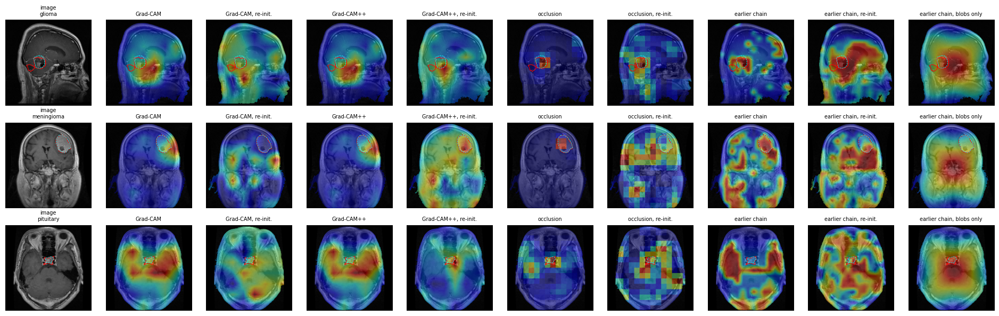


  33.5  SAVE
saved cell33_summary.json, cell33_randomisation.png

------------------------------------------------------------------------------
  [PASS]  H1 was evaluated for every saliency method of B_flip_w
------------------------------------------------------------------------------
CELL 33 CLEAN.


In [69]:
# =============================================================================
#  CELL 33  |  H1: do the explanations depend on what the network learned?
#              (randomisation test of Adebayo et al. 2018) and the earlier code's
#              display chain under the same test
# =============================================================================
assert "field_stats" in globals() and "XT" in globals() and "XAI_ARMS" in globals(), "Run Cells 1-32 first."

H1_ARM, H1_THR = "B_flip_w", 0.5
H1_DESC_ARMS = ["B_flip_p1", "B_flip_effb0", "B_flip_swint"]       # the same test, descriptive
ARR_ARMS = ["B_flip_w", "B_flip_p1"]                                 # the earlier display chain applied to these models
checks, notes = {}, []
r3_clear(33)

def const_counts(arm, m_):
    s_ = PI[(PI.arm == arm) & PI.has_mask]
    if f"x_const_{m_}" not in s_.columns:
        return 0, 0
    return int((s_[f"x_const_{m_}"] == 1).sum()), int((s_.get(f"x_rconst_{m_}", pd.Series(dtype=float)) == 1).sum())

# ----- 33.1 the pre-specified test --------------------------------------------------------------------------------------------
banner(f"33.1  H1 ON {H1_ARM}: SPEARMAN CORRELATION (head pixels) BETWEEN THE MAP OF THE TRAINED NETWORK AND THE MAP AFTER "
       "RE-INITIALISING ITS CLASSIFICATION HEAD AND COARSEST STAGE  (pass: mean < 0.5, upper 95% bound < 0.5, every seed < 0.5)")
H1_PASS, H1_RES, rows_ = {}, {}, []
for m_, name_ in METHODS.items():
    st_ = field_stats(H1_ARM, f"x_rho_{m_}", tum)
    if st_ is None:
        continue
    v_ = rule_of(st_, "<", H1_THR); H1_PASS[m_] = v_ == "supported"; H1_RES[m_] = {**st_, "verdict": v_}
    nt_, nr_ = const_counts(H1_ARM, m_)
    rows_.append((f"{name_}  (constant maps: trained {nt_}, re-initialised {nr_})", st_, "passes H1" if H1_PASS[m_] else f"fails H1 ({v_})"))
    r3(33, "H1", f"{name_}: Spearman, trained vs re-initialised network ({H1_ARM})", st_["value"], st_["lo"], st_["hi"],
       "passes" if H1_PASS[m_] else "fails", st_["images"], fmt_seeds(st_["per_seed"]))
show_stats(rows_)
if H1_RES:
    print("A map that barely changes when the weights that make the decision are re-drawn does not explain that decision.\n"
          "Constant maps: a trained map that is constant over the head has no ranking (left out); a re-initialised map that is\n"
          "constant counts as rho = 0. Methods that fail H1 are not used for H2-H5 (their numbers are still printed, flagged).")
    failed = [METHODS[m_] for m_, ok_ in H1_PASS.items() if not ok_]
    if failed:
        notes.append(f"H1: {', '.join(failed)} fail the randomisation test on {H1_ARM}: not used for H2-H5.")
else:
    print(f"needs {H1_ARM} with its checkpoint (Cells 30 and 32)")

# ----- 33.2 the same test on the other networks (descriptive) -------------------------------------------------------------------
banner("33.2  THE SAME TEST ON THE OTHER NETWORKS TRAINED ON SET B  (descriptive)")
H1_DESC = {}
for arm in H1_DESC_ARMS:
    rows_ = []
    for m_, name_ in METHODS.items():
        st_ = field_stats(arm, f"x_rho_{m_}", tum)
        if st_ is not None:
            H1_DESC[f"{arm} | {m_}"] = st_; rows_.append((name_, st_, "would pass" if rule_of(st_, "<", H1_THR) == "supported" else "would fail"))
            r3(33, "H1-d", f"{arm}, {name_}: Spearman, trained vs re-initialised", st_["value"], st_["lo"], st_["hi"], "descriptive",
               st_["images"], fmt_seeds(st_["per_seed"]), "descriptive")
    show_stats(rows_, f"\n{arm}:") if rows_ else print(f"\n{arm}: not available (Cells 30 and 32)")

# ----- 33.3 the earlier display chain under the same test -------------------------------------------------------------------------
banner("33.3  THE EARLIER CODE'S DISPLAY CHAIN UNDER THE SAME TEST  (descriptive; the chain of brain_tumor.ipynb cell 17)")
ARR = {}
for arm in ARR_ARMS:
    s_ = PI[(PI.arm == arm) & PI.has_mask]
    if "x_arr_fb" not in s_.columns or s_.x_arr_fb.notna().sum() == 0:
        print(f"\n{arm}: not available"); continue
    fb_ = s_.x_arr_fb.dropna()
    print(f"\n{arm}: the earlier code's fallback for maps of low variation was used on {int((fb_ > 0).sum())} of {len(fb_)} "
          f"image-model pairs ({(fb_ > 0).mean():.1%}); the second fallback on {int((fb_ > 1).sum())}")
    rows_ = []
    for f_, lab_ in (("x_rho_arrraw", "its raw map (layer4.0.conv1): trained vs re-initialised"),
                     ("x_rho_arr", "its DISPLAYED map: trained vs re-initialised"),
                     ("x_rho_arrtpl", "its displayed map vs the fixed blob pattern alone"),
                     ("x_em_arrraw", "excess mass in the tumour, raw map"), ("x_em_arr", "excess mass in the tumour, displayed map"),
                     ("x_em_gc", "excess mass in the tumour, Grad-CAM (Cell 32)")):
        st_ = field_stats(arm, f_, tum)
        if st_ is not None:
            ARR[f"{arm} | {f_}"] = st_; rows_.append((lab_, st_, None))
            r3(33, "D-array", f"{arm}: {lab_}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
               fmt_seeds(st_["per_seed"]), "descriptive")
    show_stats(rows_)
    fb_share = float((fb_ > 0).mean())
    r3(33, "D-array", f"{arm}: share of maps where the earlier code's low-variation fallback replaced Grad-CAM", fb_share,
       verdict="descriptive", n=int(len(fb_)), status="descriptive")
if ARR:
    print("\nThe displayed map blends 30% of a fixed pattern (five Gaussian blobs at fixed places) into every map after a\n"
          "confidence-dependent contrast stretch. Whatever the network does, part of what is displayed is the same pattern.")

# ----- 33.4 figure ---------------------------------------------------------------------------------------------------------------------
banner("33.4  FIGURE: TRAINED vs RE-INITIALISED MAPS  (B_flip_w, first seed; red = BRISC mask, dashed cyan = figshare mask)")
g33, ks33 = pick_examples(H1_ARM, 1)
if g33 is not None and ks33:
    fm = figure_maps(g33, ks33, methods=tuple(m_ for m_ in XAI_ARMS[H1_ARM]["maps"]), rand=True, arr=True) or {}
    cols = [("", None, "image")] + [(k_, k_, t_) for k_, t_ in
            (("gc", "Grad-CAM"), ("r_gc", "Grad-CAM, re-init."), ("gcpp", "Grad-CAM++"), ("r_gcpp", "Grad-CAM++, re-init."),
             ("occ", "occlusion"), ("r_occ", "occlusion, re-init."), ("arr", "earlier chain"), ("r_arr", "earlier chain, re-init."),
             ("tpl", "earlier chain, blobs only")) if k_ in fm]
    fig, ax = plt.subplots(len(ks33), len(cols), figsize=(1.9 * len(cols), 2.0 * len(ks33)), squeeze=False)
    for i, k in enumerate(ks33):
        for j, (key_, src_, t_) in enumerate(cols):
            show_on(ax[i, j], k, None if src_ is None else fm[src_][i], f"{t_}\n{IDX_LABEL[int(LAB_T[k])]}" if j == 0 else t_)
    plt.tight_layout(); plt.savefig(WORK / "cell33_randomisation.png", dpi=110, bbox_inches="tight"); plt.show()
else:
    print("needs B_flip_w (Cells 30 and 32)")

# ----- 33.5 save ------------------------------------------------------------------------------------------------------------------------
banner("33.5  SAVE")
if any(g_["arm"] == H1_ARM for g_ in (G3[t_] for t_ in TAGS3)):
    checks["H1 was evaluated for every saliency method of B_flip_w"] = set(H1_RES) == set(XAI_ARMS[H1_ARM]["maps"])
else:
    notes.append(f"{H1_ARM} is not trained yet: H1 is not evaluated (Cell 30, priority 1)")
save_json(WORK / "cell33_summary.json", {"threshold": H1_THR, "H1": H1_RES, "H1_pass": H1_PASS, "descriptive": H1_DESC, "earlier_chain": ARR})
print("saved cell33_summary.json, cell33_randomisation.png")
finish(33, checks, notes)

## Cell 34 | H2: do the explanations concentrate on the tumour?

**Purpose.** Pre-specified: the excess Grad-CAM mass inside the BRISC tumour mask on `B_flip_w` (true class, all tumour test images) is above 0 (95% interval above 0, every seed above 0); tested only if Grad-CAM passed H1. Descriptive: the other methods, the pointing game against its chance level, the map's mass outside the head, the same quantities against the figshare annotation of the same slices, by class and contamination stratum, the other networks on B and on Full (and Full minus B), the networks' own attention maps, and a figure of every network's maps on the same images.

**Inputs.** Cells 32-33. **Outputs.** `cell34_summary.json`, `cell34_maps.png`.

**Pass criteria.** H2 is estimated on `B_flip_w` (when it is trained).



  34.1  H2 ON B_flip_w: EXCESS GRAD-CAM MASS INSIDE THE BRISC TUMOUR MASK  (share of the map's mass in the head that lies in the mask, minus the mask's share of the head; true class; > 0 = concentrated on the tumour)
                          quantity  value             95% CI                per seed  images   verdict
excess mass, Grad-CAM (last stage) 0.0311 [+0.0265, +0.0361] +0.0402 +0.0284 +0.0247     860 supported
for scale: the mask covers 0.0333 of the head on average; Grad-CAM puts 0.0644 of its mass there

  34.2  OTHER METHODS, POINTING GAME, MASS OUTSIDE THE HEAD  (B_flip_w; descriptive)
                                                        quantity  value             95% CI                per seed  images
                               Grad-CAM, last stage: excess mass 0.0311 [+0.0265, +0.0361] +0.0402 +0.0284 +0.0247     860
   Grad-CAM, last stage: pointing game (maximum inside the mask) 0.0376 [+0.0275, +0.0486] +0.0581 +0.0256 +0.0291     860
  Grad-CAM, last stage: 

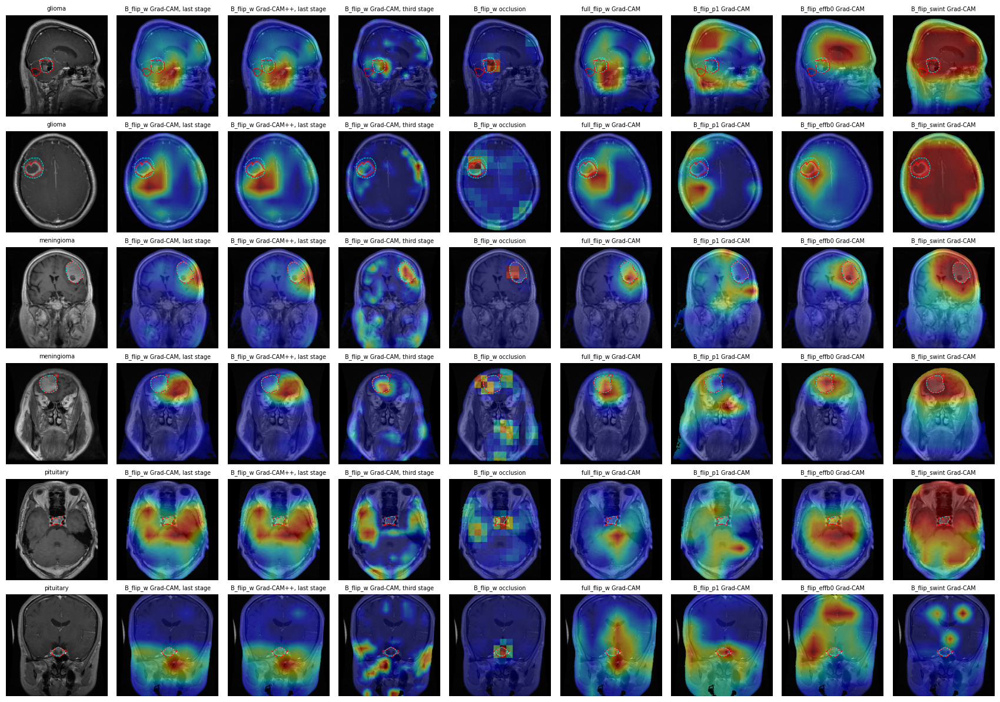


  34.8  SAVE
saved cell34_summary.json, cell34_maps.png

------------------------------------------------------------------------------
  [PASS]  H2 was estimated on B_flip_w
------------------------------------------------------------------------------
CELL 34 CLEAN.


In [70]:
# =============================================================================
#  CELL 34  |  H2: do the explanations concentrate on the tumour? (excess mass in
#              the BRISC mask), and descriptively: other methods, pointing game,
#              the figshare annotation, classes, strata, other networks, attention
# =============================================================================
assert "H1_PASS" in globals() and "field_stats" in globals(), "Run Cells 1-33 first."

H2_ARM = "B_flip_w"
FAMILIES = [("round-1 network (replicates)", "full_flip_w", "B_flip_w"), ("earlier design", "full_flip_p1", "B_flip_p1"),
            ("EfficientNet-B0", "full_flip_effb0", "B_flip_effb0"), ("Swin-T", "full_flip_swint", "B_flip_swint")]
ATT_ARMS = ["B_flip_w", "full_flip_w", "B_flip_p1", "full_flip_p1"]
ATT_MAPS = {"gate_s16": "attention gate, stride 16", "gate_s8": "attention gate, stride 8", "gate_s4": "attention gate, stride 4",
            "gate_s2": "attention gate, stride 2", "cbam_s4": "CBAM spatial, stage 1", "cbam_s8": "CBAM spatial, stage 2",
            "cbam_s16": "CBAM spatial, stage 3", "cbam_s32": "CBAM spatial, stage 4"}
checks, notes = {}, []
r3_clear(34)
fig_t34 = tum & HAS_FIG                                         # tumour test slices with the figshare annotation too
def h1_flag(m_):
    return "" if H1_PASS.get(m_) else (" [failed H1]" if m_ in H1_PASS else " [H1 not available]")

# ----- 34.1 the pre-specified test -------------------------------------------------------------------------------------------------
banner(f"34.1  H2 ON {H2_ARM}: EXCESS GRAD-CAM MASS INSIDE THE BRISC TUMOUR MASK  (share of the map's mass in the head that lies in "
       "the mask, minus the mask's share of the head; true class; > 0 = concentrated on the tumour)")
H2 = field_stats(H2_ARM, "x_em_gc", tum)
if H2 is None:
    print(f"needs {H2_ARM} (Cells 30 and 32)"); v2 = "not estimable"
else:
    v2 = (rule_of(H2, ">") if H1_PASS.get("gc") else
          ("not tested: Grad-CAM failed H1" if "gc" in H1_PASS else "not tested: H1 not available"))
    show_stats([("excess mass, Grad-CAM (last stage)", H2, v2)])
    sh_ = field_stats(H2_ARM, "x_share", tum); ms_ = field_stats(H2_ARM, "x_mass_gc", tum)
    if sh_ and ms_:
        print(f"for scale: the mask covers {sh_['value']:.4f} of the head on average; Grad-CAM puts {ms_['value']:.4f} of its mass there")
    r3(34, "H2", f"excess Grad-CAM mass in the BRISC mask ({H2_ARM}, true class)", H2["value"], H2["lo"], H2["hi"], v2, H2["images"],
       fmt_seeds(H2["per_seed"]))

# ----- 34.2 other methods; pointing game; mass outside the head (descriptive) --------------------------------------------------------
banner(f"34.2  OTHER METHODS, POINTING GAME, MASS OUTSIDE THE HEAD  ({H2_ARM}; descriptive)")
D342, rows_ = {}, []
for m_, name_ in METHODS.items():
    for f_, lab_ in ((f"x_em_{m_}", "excess mass"), (f"x_pt_{m_}", "pointing game (maximum inside the mask)"),
                     (f"x_out_{m_}", "share of the map's mass outside the head")):
        st_ = field_stats(H2_ARM, f_, tum)
        if st_ is not None:
            D342[f_] = st_; rows_.append((f"{name_}{h1_flag(m_)}: {lab_}", st_, None))
            r3(34, "H2-d", f"{H2_ARM}, {name_}{h1_flag(m_)}: {lab_}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
               fmt_seeds(st_["per_seed"]), "descriptive")
sh_ = field_stats(H2_ARM, "x_share", tum)
if sh_:
    rows_.append(("chance level of the pointing game (the mask's share of the head)", sh_, None))
show_stats(rows_)

# ----- 34.3 against the second annotation of the same slices (descriptive) -------------------------------------------------------------
banner(f"34.3  AGAINST THE FIGSHARE ANNOTATION OF THE SAME SLICES  ({int(fig_t34[ALL_K].sum())} test slices; descriptive)")
rows_ = []
for m_, name_ in METHODS.items():
    a_ = field_stats(H2_ARM, f"x_em_{m_}", fig_t34); b_ = field_stats(H2_ARM, f"x_emfig_{m_}", fig_t34)
    d_ = diff_stats(H2_ARM, f"x_em_{m_}", H2_ARM, f"x_emfig_{m_}", fig_t34)
    for st_, lab_ in ((a_, "excess mass vs BRISC mask"), (b_, "excess mass vs figshare mask"), (d_, "BRISC minus figshare")):
        if st_ is not None:
            rows_.append((f"{name_}{h1_flag(m_)}: {lab_}", st_, None))
            r3(34, "H2-d", f"{H2_ARM}, {name_}: {lab_} (slices with both annotations)", st_["value"], st_["lo"], st_["hi"], "descriptive",
               st_["images"], fmt_seeds(st_["per_seed"]), "descriptive")
show_stats(rows_)
print("Each mask is one expert reading (Cell 27 measured how often the two disagree). A map that follows the BRISC mask more\n"
      "than the figshare mask of the same slice follows the annotation, not necessarily the tumour.")

# ----- 34.4 by class and by contamination stratum (descriptive) ----------------------------------------------------------------------------
banner(f"34.4  GRAD-CAM EXCESS MASS BY CLASS AND BY CONTAMINATION STRATUM  ({H2_ARM}; descriptive)")
rows_ = []
for c_ in (1, 2, 3):
    st_ = field_stats(H2_ARM, "x_em_gc", tum & (LAB_T == c_))
    if st_ is not None:
        rows_.append((f"class {IDX_LABEL[c_]}", st_, None))
        r3(34, "H2-d", f"{H2_ARM}, Grad-CAM excess mass, {IDX_LABEL[c_]}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
           fmt_seeds(st_["per_seed"]), "descriptive")
for st in LINKED + ["unlinked"]:
    st_ = field_stats(H2_ARM, "x_em_gc", tum & (strat_t == st))
    if st_ is not None:
        rows_.append((f"stratum {st}", st_, None))
show_stats(rows_)

# ----- 34.5 the other networks; Full minus B (descriptive) ---------------------------------------------------------------------------------
banner("34.5  OTHER NETWORKS: GRAD-CAM EXCESS MASS ON SET B AND ON FULL, AND FULL minus B  (descriptive)")
rows_ = []
for fam, fa, ba in FAMILIES:
    for m_ in ("gc", "gcpp"):
        sb_, sf_ = field_stats(ba, f"x_em_{m_}", tum), field_stats(fa, f"x_em_{m_}", tum)
        dd_ = diff_stats(fa, f"x_em_{m_}", ba, f"x_em_{m_}", tum)
        for st_, lab_ in ((sb_, f"{ba}"), (sf_, f"{fa}"), (dd_, "Full minus B")):
            if st_ is not None:
                rows_.append((f"{fam}, {METHODS[m_]}: {lab_}", st_, None))
                r3(34, "H2-d", f"{fam}, {METHODS[m_]}: excess mass, {lab_}", st_["value"], st_["lo"], st_["hi"], "descriptive",
                   st_["images"], fmt_seeds(st_["per_seed"]), "descriptive")
st_ = field_stats("B_flip_film_w", "x_em_gc", tum)
if st_ is not None:
    rows_.append(("round-1 network with plane FiLM (B_flip_film_w), Grad-CAM", st_, None))
show_stats(rows_)
print("These networks were not all tested by H1 (only B_flip_w is pre-specified; 33.2 shows the same test on the others).")

# ----- 34.6 the networks' own attention maps (descriptive) ----------------------------------------------------------------------------------
banner("34.6  THE NETWORKS' OWN ATTENTION MAPS: EXCESS MASS IN THE BRISC MASK  (descriptive)")
rows_ = []
for arm in ATT_ARMS:
    for a_, lab_ in ATT_MAPS.items():
        st_ = field_stats(arm, f"x_em_{a_}", tum)
        if st_ is not None:
            rows_.append((f"{arm}: {lab_}", st_, None))
            r3(34, "H2-d", f"{arm}: {lab_}, excess mass", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
               fmt_seeds(st_["per_seed"]), "descriptive")
show_stats(rows_)
print("The attention gates sit on the decoder's skip connections: they weight the features used to draw the MASK, so their\n"
      "concentration on the tumour says nothing about how the CLASS was decided. CBAM maps sit on the encoder (both heads).")

# ----- 34.7 figure ---------------------------------------------------------------------------------------------------------------------------
banner("34.7  FIGURE: MAPS OF EVERY NETWORK ON THE SAME TEST IMAGES  (first seed; red = BRISC mask, dashed cyan = figshare mask)")
g34, ks34 = pick_examples(H2_ARM, 2)
if g34 is not None and ks34:
    panels = [("image", None, None)]
    fmB = figure_maps(g34, ks34, methods=XAI_ARMS[H2_ARM]["maps"]) or {}
    panels += [(f"B_flip_w {METHODS[m_]}", fmB, m_) for m_ in XAI_ARMS[H2_ARM]["maps"] if m_ in fmB]
    for arm in ("full_flip_w", "B_flip_p1", "B_flip_effb0", "B_flip_swint"):
        g_ = next((G3[t_] for t_ in TAGS3 if G3[t_]["arm"] == arm), None)
        if g_ is not None:
            fm_ = figure_maps(g_, ks34, methods=("gc",))
            if fm_:
                panels.append((f"{arm} Grad-CAM", fm_, "gc"))
    fig, ax = plt.subplots(len(ks34), len(panels), figsize=(1.9 * len(panels), 2.0 * len(ks34)), squeeze=False)
    for i, k in enumerate(ks34):
        for j, (t_, fm_, m_) in enumerate(panels):
            show_on(ax[i, j], k, None if fm_ is None else fm_[m_][i], f"{IDX_LABEL[int(LAB_T[k])]}" if j == 0 else t_)
    plt.tight_layout(); plt.savefig(WORK / "cell34_maps.png", dpi=110, bbox_inches="tight"); plt.show()
else:
    print(f"needs {H2_ARM} (Cells 30 and 32)")

# ----- 34.8 save ----------------------------------------------------------------------------------------------------------------------------
banner("34.8  SAVE")
if any(G3[t_]["arm"] == H2_ARM for t_ in TAGS3):
    checks["H2 was estimated on B_flip_w"] = H2 is not None
save_json(WORK / "cell34_summary.json", {"H2": H2, "verdict": v2, "methods": D342})
print("saved cell34_summary.json, cell34_maps.png")
finish(34, checks, notes)

## Cell 35 | H3: does the classifier use the tumour? Tissue scramble

**Purpose.** Pre-specified: on `B_flip_w`, the change in log-probability of the true class when the tumour region is removed minus the change when a same-shape control region is removed is below 0 (95% interval below 0, every seed below 0). A perturbation test: it does not depend on saliency maps. Descriptive: each removal alone, predictions of "no tumour" after removal, by class, every explained network and Full minus B, and accuracy when anatomy is destroyed (head pixels shuffled) or reduced to the silhouette, against chance.

**Inputs.** Cell 32. **Outputs.** `cell35_summary.json`, `cell35_perturbations.png`.

**Pass criteria.** H3 is estimated on `B_flip_w` (when it is trained). Images without room for a control region are counted by class and left out.



  35.1  H3 ON B_flip_w: CHANGE IN LOG-PROBABILITY OF THE TRUE CLASS WHEN THE TUMOUR IS REMOVED minus THE CHANGE WHEN A REGION OF THE SAME SHAPE IS REMOVED ELSEWHERE IN THE HEAD  (< 0 = the classifier uses the tumour)
tumour test images with a control region: 845 of 860 (by class: {'glioma': 0.961, 'meningioma': 0.984, 'pituitary': 1.0} found)
                                                         quantity   value             95% CI                per seed  images   verdict
tumour removal minus control removal, change in log p(true class) -1.5826 [-1.8984, -1.2914] -1.7138 -1.2979 -1.7361     845 supported

  35.2  THE TWO REMOVALS SEPARATELY, PREDICTIONS AFTER REMOVAL, BY CLASS  (B_flip_w; descriptive)
                              quantity   value             95% CI                per seed  images
 change in log p(true), tumour removed -1.5827 [-1.9004, -1.2915] -1.7200 -1.2887 -1.7395     845
change in log p(true), control removed -0.0001 [-0.0151, +0.0172] -0.0062 +0.0092 -0.0034

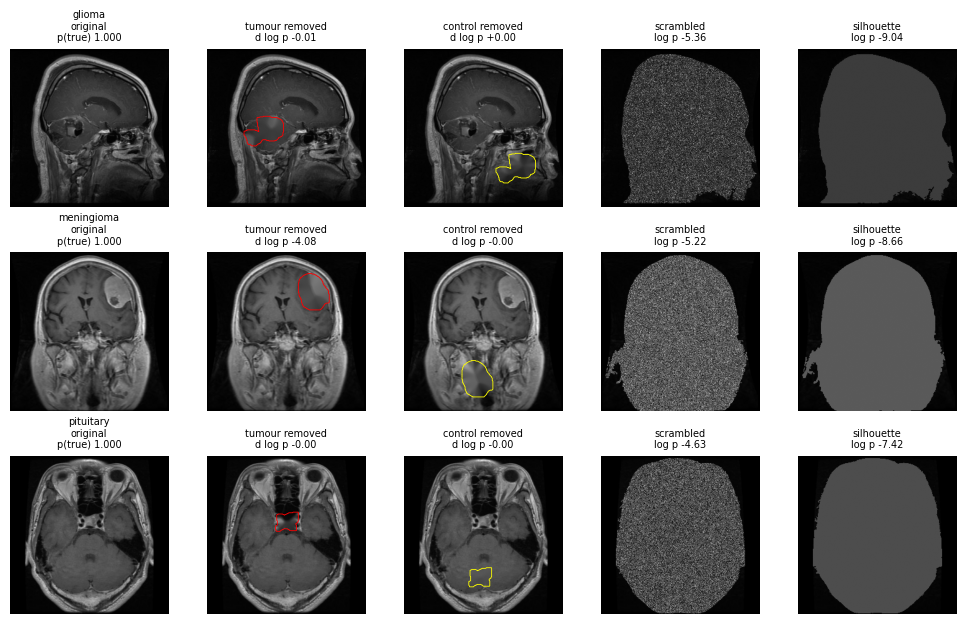


  35.6  SAVE
saved cell35_summary.json, cell35_perturbations.png

------------------------------------------------------------------------------
  [PASS]  H3 was estimated on B_flip_w
  [NOTE]  H3 leaves out 15 tumour images with no room for a control region of the same shape (large tumours; by class {'glioma': 10, 'meningioma': 5, 'pituitary': 0}): H3 describes the others.
------------------------------------------------------------------------------
CELL 35 CLEAN.


In [71]:
# =============================================================================
#  CELL 35  |  H3: does the classifier use the tumour? (tumour removed by inpainting
#              vs a region of the same shape removed elsewhere), and descriptively:
#              other networks, classes, and the tissue-scramble test
# =============================================================================
assert "field_stats" in globals() and "CTL_OK" in globals(), "Run Cells 1-34 first."

H3_ARM = "B_flip_w"
H3_FAMILIES = FAMILIES + [("round-1 network with plane FiLM", None, "B_flip_film_w"), ("crossover replicate X1", None, "X1_flip_w"),
                          ("crossover replicate X2", None, "X2_flip_w")]
SCR_ARMS = ["B_flip_w", "full_flip_w", "B_flip_film_w", "X1_flip_w", "X2_flip_w", "B_flip_p1", "full_flip_p1",
            "B_flip_effb0", "full_flip_effb0", "B_flip_swint", "full_flip_swint"]
checks, notes = {}, []
r3_clear(35)

def ind(col, val=None, ref=None):
    """1/0 indicator column (NaN where the source is NaN): col == val, or col == the column ref."""
    v_ = PI[col].to_numpy(dtype=float)
    hit = (v_ == val) if ref is None else (v_ == PI[ref].to_numpy(dtype=float))
    return np.where(np.isfinite(v_), hit.astype(float), np.nan)
for c_ in [c_ for c_ in PI.columns if c_.startswith("x35_")]:
    del PI[c_]
if "x_pred" in PI.columns:
    PI["x35_cor"] = ind("x_pred", ref="label_idx")
    for n_ in ("scr", "sil"):
        if f"x_pred_{n_}" in PI.columns:
            PI[f"x35_cor_{n_}"] = ind(f"x_pred_{n_}", ref="label_idx")
    if "x_pred_tum" in PI.columns:
        PI["x35_nt0"] = ind("x_pred", 0.0); PI["x35_nt_tum"] = ind("x_pred_tum", 0.0); PI["x35_nt_ctl"] = ind("x_pred_ctl", 0.0)

# ----- 35.1 the pre-specified test --------------------------------------------------------------------------------------------------
banner(f"35.1  H3 ON {H3_ARM}: CHANGE IN LOG-PROBABILITY OF THE TRUE CLASS WHEN THE TUMOUR IS REMOVED minus THE CHANGE WHEN A "
       "REGION OF THE SAME SHAPE IS REMOVED ELSEWHERE IN THE HEAD  (< 0 = the classifier uses the tumour)")
ok_k = CTL_OK & tum
print(f"tumour test images with a control region: {int(ok_k[ALL_K].sum())} of {int(tum[ALL_K].sum())} "
      f"(by class: {pd.Series(CTL_OK[TUM_K]).groupby(LAB_T[TUM_K]).mean().rename(index=IDX_LABEL).round(3).to_dict()} found)")
H3 = field_stats(H3_ARM, "x_h3", ok_k)
if H3 is None:
    v3 = "not estimable"; print(f"needs {H3_ARM} (Cells 30 and 32)")
else:
    v3 = rule_of(H3, "<")
    show_stats([("tumour removal minus control removal, change in log p(true class)", H3, v3)])
    r3(35, "H3", f"change in log p(true class): tumour removed minus control region removed ({H3_ARM})", H3["value"], H3["lo"], H3["hi"],
       v3, H3["images"], fmt_seeds(H3["per_seed"]))
    miss_ = pd.Series(~CTL_OK[TUM_K]).groupby(LAB_T[TUM_K]).sum().rename(index=IDX_LABEL)
    if int(miss_.sum()):
        notes.append(f"H3 leaves out {int(miss_.sum())} tumour images with no room for a control region of the same shape "
                     f"(large tumours; by class {miss_.to_dict()}): H3 describes the others.")

# ----- 35.2 the parts, predictions, classes (descriptive) ------------------------------------------------------------------------------
banner(f"35.2  THE TWO REMOVALS SEPARATELY, PREDICTIONS AFTER REMOVAL, BY CLASS  ({H3_ARM}; descriptive)")
rows_ = []
for f_, lab_ in (("x_dlp_tum", "change in log p(true), tumour removed"), ("x_dlp_ctl", "change in log p(true), control removed"),
                 ("x35_nt0", "predicted 'no tumour', original"), ("x35_nt_tum", "predicted 'no tumour', tumour removed"),
                 ("x35_nt_ctl", "predicted 'no tumour', control removed")):
    if f_ in PI.columns:
        st_ = field_stats(H3_ARM, f_, ok_k)
        if st_ is not None:
            rows_.append((lab_, st_, None))
            r3(35, "H3-d", f"{H3_ARM}: {lab_}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
               fmt_seeds(st_["per_seed"]), "descriptive")
for c_ in (1, 2, 3):
    st_ = field_stats(H3_ARM, "x_h3", ok_k & (LAB_T == c_))
    if st_ is not None:
        rows_.append((f"H3 contrast, {IDX_LABEL[c_]}", st_, None))
        r3(35, "H3-d", f"{H3_ARM}: H3 contrast, {IDX_LABEL[c_]}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
           fmt_seeds(st_["per_seed"]), "descriptive")
show_stats(rows_)

# ----- 35.3 the other networks (descriptive) ---------------------------------------------------------------------------------------------
banner("35.3  THE SAME CONTRAST FOR EVERY EXPLAINED NETWORK, AND FULL minus B  (descriptive)")
rows_ = []
for fam, fa, ba in H3_FAMILIES:
    for arm in [a_ for a_ in (ba, fa) if a_]:
        st_ = field_stats(arm, "x_h3", ok_k)
        if st_ is not None:
            rows_.append((f"{fam}: {arm}", st_, None))
            r3(35, "H3-d", f"{fam}: H3 contrast, {arm}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
               fmt_seeds(st_["per_seed"]), "descriptive")
    if fa:
        dd_ = diff_stats(fa, "x_h3", ba, "x_h3", ok_k)
        if dd_ is not None:
            rows_.append((f"{fam}: Full minus B", dd_, None))
            r3(35, "H3-d", f"{fam}: H3 contrast, Full minus B", dd_["value"], dd_["lo"], dd_["hi"], "descriptive", dd_["images"],
               fmt_seeds(dd_["per_seed"]), "descriptive")
show_stats(rows_)

# ----- 35.4 tissue scramble and silhouette (descriptive) ------------------------------------------------------------------------------------
banner("35.4  CAN THE NETWORKS NAME THE CLASS WITHOUT ANATOMY?  Accuracy on the original images, with every head pixel shuffled "
       "(silhouette and histogram kept), and with the head filled with its mean (silhouette kept); all explained test images")
rows_, SCR_RES = [], {}
for arm in SCR_ARMS:
    for f_, lab_ in (("x35_cor", "original"), ("x35_cor_scr", "tissue scrambled"), ("x35_cor_sil", "silhouette only")):
        if f_ in PI.columns:
            st_ = field_stats(arm, f_, None)
            if st_ is not None:
                SCR_RES[f"{arm} | {lab_}"] = st_; rows_.append((f"{arm}: accuracy, {lab_}", st_, None))
                r3(35, "D-scramble", f"{arm}: accuracy, {lab_}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"],
                   fmt_seeds(st_["per_seed"]), "descriptive")
show_stats(rows_)
maj_ = float(pd.Series(LAB_T[ALL_K]).value_counts(normalize=True).max()) if len(ALL_K) else float("nan")
print(f"chance levels: largest class share among these images {maj_:.4f}; uniform guess 0.25. Image size and padding predict\n"
      f"the class above chance (Cell 3): the silhouette keeps both.")

# ----- 35.5 figure ---------------------------------------------------------------------------------------------------------------------------
banner("35.5  FIGURE: THE PERTURBED INPUTS  (red = tumour region removed; yellow = control region)")
g35, ks35 = pick_examples(H3_ARM, 1)
if g35 is not None and ks35:
    s_ = PI[PI.tag == g35["tag"]].set_index("row")
    fig, ax = plt.subplots(len(ks35), 5, figsize=(10, 2.1 * len(ks35)), squeeze=False)
    for i, k in enumerate(ks35):
        r_ = int(TR[k]); q_ = s_.loc[r_]
        for j, (arr, t_) in enumerate(((U8, f"original\np(true) {q_.x_ptrue:.3f}"),
                                       (TUMRM, f"tumour removed\nd log p {q_.get('x_dlp_tum', np.nan):+.2f}"),
                                       (CTLRM, f"control removed\nd log p {q_.get('x_dlp_ctl', np.nan):+.2f}"),
                                       (SCR, f"scrambled\nlog p {q_.get('x_lp_scr', np.nan):+.2f}"),
                                       (SIL, f"silhouette\nlog p {q_.get('x_lp_sil', np.nan):+.2f}"))):
            ax[i, j].imshow(arr[k], cmap="gray", vmin=0, vmax=255); ax[i, j].axis("off"); ax[i, j].set_title(t_, fontsize=7)
        ax[i, 1].contour(cv2.dilate(TM[k].astype(np.uint8), K3, iterations=H3_DILATE).astype(float), levels=[0.5], colors="red", linewidths=0.6)
        if CTL_OK[k]:
            ax[i, 2].contour(CTL_REG[k].astype(float), levels=[0.5], colors="yellow", linewidths=0.6)
        ax[i, 0].set_title(f"{IDX_LABEL[int(LAB_T[k])]}\n" + ax[i, 0].get_title(), fontsize=7)
    plt.tight_layout(); plt.savefig(WORK / "cell35_perturbations.png", dpi=110, bbox_inches="tight"); plt.show()
else:
    print(f"needs {H3_ARM} (Cells 30 and 32)")

# ----- 35.6 save -----------------------------------------------------------------------------------------------------------------------------
banner("35.6  SAVE")
if any(G3[t_]["arm"] == H3_ARM for t_ in TAGS3):
    checks["H3 was estimated on B_flip_w"] = H3 is not None
save_json(WORK / "cell35_summary.json", {"H3": H3, "verdict": v3, "scramble": SCR_RES,
                                         "control_found": int(ok_k[ALL_K].sum()), "tumour_images": int(tum[ALL_K].sum())})
print("saved cell35_summary.json, cell35_perturbations.png")
finish(35, checks, notes)

## Cell 36 | H4: does contamination change what the model relies on?

**Purpose.** The round-1 randomised crossover applied to the explanations: for every test image, the H2 quantity (Grad-CAM excess mass) and the H3 quantity (tumour-removal contrast) of the model that saw the image's relatives minus the model that did not (`X1_flip_w`, `X2_flip_w`; same image, same seed, half-balanced as in Cell 15). Pre-specified, two-sided: `copy_plain` and `copy_mirror`; unlinked images are the negative control; other strata descriptive. The excess-mass rows are tested only if Grad-CAM passed H1. Descriptive: Grad-CAM++, the tumour-removal change alone, the scrambled image, and whether the replicates reproduce round 1's Q2 effects.

**Inputs.** Cells 15, 21 (`q2_effects`), 32-33. **Outputs.** `cell36_summary.json`.

**Pass criteria.** H4 is estimated (when `X1_flip_w` and `X2_flip_w` are trained).


In [72]:
# =============================================================================
#  CELL 36  |  H4: does contamination change what the model relies on? The round-1
#              randomised crossover applied to the explanations (same image, same
#              seed; exposed minus unexposed model)
# =============================================================================
assert "q2_effects" in globals() and "H1_PASS" in globals() and "field_stats" in globals(), "Run Cells 1-35 first."

H4_ARMS = ("X1_flip_w", "X2_flip_w")
H4_STRATA = ("copy_plain", "copy_mirror", "patient_only", "related", "unlinked")
checks, notes = {}, []
r3_clear(36)
avail36 = all(any(G3[t_]["arm"] == a_ for t_ in TAGS3) for a_ in H4_ARMS) and "x_em_gc" in PI.columns

def h4_table(fields, title):
    T_ = q2_effects(*H4_ARMS, fields=fields, strata=H4_STRATA)
    if T_ is None or not len(T_):
        print(f"{title}: not available"); return None
    print(title); print(T_.drop(columns=["seeds"]).round(4).to_string(index=False))
    return T_

# ----- 36.1 the pre-specified test ------------------------------------------------------------------------------------------------
banner("36.1  H4: EXPOSURE EFFECT ON THE EXPLANATIONS  (model that saw the image's relatives minus the model that did not; same "
       "image, same seed; half-balanced as in Cell 15; two-sided; unlinked = negative control)")
H4 = None
if avail36:
    H4 = h4_table([("x_em_gc", tum), ("x_h3", tum & CTL_OK)], "x_em_gc = Grad-CAM excess mass in the tumour (H2); x_h3 = tumour-removal "
                  "contrast (H3):")
    if H4 is not None:
        for _, r_ in H4.iterrows():
            ok_em = r_.metric != "x_em_gc" or H1_PASS.get("gc")
            prim = r_.stratum in ("copy_plain", "copy_mirror")
            verdict = r_.verdict if ok_em else "not tested: Grad-CAM failed H1 or H1 not available"
            if not prim and r_.stratum != "unlinked":
                verdict = "descriptive"
            lab_ = {"x_em_gc": "Grad-CAM excess mass", "x_h3": "tumour-removal contrast"}[r_.metric]
            r3(36, "H4", f"exposure effect on the {lab_}, {r_.stratum}", r_.effect, r_.lo, r_.hi, verdict, int(r_.images), r_.per_seed,
               "pre-specified" if prim else ("negative control" if r_.stratum == "unlinked" else "descriptive"))
        neg_ = H4[H4.stratum == "unlinked"]
        for _, r_ in neg_.iterrows():
            if not (r_.lo <= 0 <= r_.hi):
                notes.append(f"H4 negative control ({r_.metric}, unlinked images) is not centred on 0: the two crossover models differ "
                             "beyond exposure for this quantity.")
        print("\nRead: a positive effect on the excess mass means that, on the same image, the model that had seen the image's\n"
              "relatives concentrates its map more on the tumour; a positive effect on the contrast means removing the tumour costs\n"
              "it LESS (it relies less on the tumour). Primary rows: copy_plain and copy_mirror. Other strata are descriptive.")
else:
    print("needs X1_flip_w and X2_flip_w with their explanations (Cells 30 and 32; priority 2)")

# ----- 36.2 descriptive: other quantities --------------------------------------------------------------------------------------------
banner("36.2  THE SAME DESIGN ON OTHER QUANTITIES  (descriptive)")
H4D = None
if avail36:
    H4D = h4_table([(f_, m_) for f_, m_ in (("x_em_gcpp", tum), ("x_dlp_tum", tum), ("x_lp_scr", np.ones(n_test, bool)),
                                             ("x_ptrue", np.ones(n_test, bool))) if f_ in PI.columns],
                   "x_em_gcpp = Grad-CAM++ excess mass; x_dlp_tum = change in log p(true) when the tumour is removed; x_lp_scr = log "
                   "p(true) of the scrambled image; x_ptrue = p(true) of the intact image:")
    if H4D is not None:
        for _, r_ in H4D[H4D.stratum.isin(["copy_plain", "copy_mirror"])].iterrows():
            r3(36, "H4-d", f"exposure effect on {r_.metric}, {r_.stratum}", r_.effect, r_.lo, r_.hi, "descriptive", int(r_.images), r_.per_seed,
               "descriptive")

# ----- 36.3 do the replicates reproduce round 1's Q2? (descriptive) --------------------------------------------------------------------
banner("36.3  THE CROSSOVER REPLICATES AGAINST ROUND 1  (Q2 exposure effects on Dice and log p(true); descriptive)")
REPQ2 = {}
for a1, a2, lab_ in (("X1_flip_w", "X2_flip_w", "replicates (round 3)"), ("X1_flip", "X2_flip", "round 1 (Cell 15)")):
    T_ = q2_effects(a1, a2, fields=[("dice", tum), ("logp_true", np.ones(n_test, bool))], strata=("copy_plain", "copy_mirror", "unlinked"))
    if T_ is not None and len(T_):
        REPQ2[lab_] = T_.to_dict("records"); print(f"\n{lab_}:"); print(T_.drop(columns=["seeds"]).round(4).to_string(index=False))
if len(REPQ2) == 2:
    a_ = pd.DataFrame(REPQ2["replicates (round 3)"]).set_index(["metric", "stratum"]).effect
    b_ = pd.DataFrame(REPQ2["round 1 (Cell 15)"]).set_index(["metric", "stratum"]).effect
    print(f"\nlargest |replicate - round 1| over these rows: {float((a_ - b_).abs().max()):.2e} (0 when every replicate reproduced "
          "its round-1 run exactly; Cell 30.6)")

# ----- 36.4 save ----------------------------------------------------------------------------------------------------------------------
banner("36.4  SAVE")
if avail36:
    checks["H4 was estimated (X1_flip_w and X2_flip_w explained)"] = H4 is not None
else:
    notes.append("H4 needs X1_flip_w and X2_flip_w (Cell 30, priority 2) and their explanations (Cell 32)")
save_json(WORK / "cell36_summary.json", {"H4": None if H4 is None else H4.to_dict("records"),
                                         "descriptive": None if H4D is None else H4D.to_dict("records"), "replicates_q2": REPQ2})
print("saved cell36_summary.json")
finish(36, checks, notes)


  36.1  H4: EXPOSURE EFFECT ON THE EXPLANATIONS  (model that saw the image's relatives minus the model that did not; same image, same seed; half-balanced as in Cell 15; two-sided; unlinked = negative control)
x_em_gc = Grad-CAM excess mass in the tumour (H2); x_h3 = tumour-removal contrast (H3):
 metric      stratum  images  both_halves  effect      lo     hi  se_boot                per_seed          verdict
x_em_gc   copy_plain     105         True  0.0005 -0.0112 0.0141   0.0064 -0.0036 +0.0068 -0.0017    not supported
x_em_gc  copy_mirror     432         True  0.0019 -0.0009 0.0050   0.0015 +0.0012 +0.0015 +0.0030    not supported
x_em_gc patient_only     247         True  0.0031 -0.0018 0.0099   0.0029 +0.0025 -0.0004 +0.0070    not supported
x_em_gc      related      16         True -0.0058 -0.0122 0.0010   0.0033 -0.0027 -0.0051 -0.0097    not supported
x_em_gc     unlinked      60        False  0.0007 -0.0072 0.0088   0.0040 -0.0293 +0.0466 -0.0151 negative control
   x_h3   co

## Cell 37 | H5-H7 (descriptive): deletion, plane swap, Monte-Carlo dropout vs ensemble

**Purpose.** **H5**: on `B_flip_w`, head pixels removed in the order of each map, at random, or BRISC mask first; mean probability of the true class over 0-50% removed (lower = the map ranks the decisive pixels first), and each order minus random. **H6**: every test image re-run with each wrong plane, on the round-1 network with FiLM on the shared feature and on the earlier design (plane MLP on the classifier only: its masks must not change). **H7**: AUROC for telling misclassified images from correct ones: one network's confidence, Monte-Carlo dropout entropy and mutual information, and the 3-seed ensemble's entropy and disagreement (group-bootstrap intervals); and whether mask uncertainty is high where Dice is low.

**Inputs.** Cell 32, stored predictions. **Outputs.** `cell37_summary.json`, `cell37_deletion.png`.

**Pass criteria.** The earlier design's masks never change with the plane (its documented wiring), when it is explained. Everything else is descriptive.



  37.1  H5 (descriptive): DELETION  (B_flip_w; head pixels removed in the order of each map; mean p(true class) over 0%-50% removed: lower = the map ranks the decisive pixels first)
mean p(true class) after removing each share of the head's pixels (pooled over seeds and images):
                    order     0%     1%     2%     5%    10%    20%    30%    50%
                 Grad-CAM 0.9171 0.9112 0.9022 0.8714 0.8135 0.6502 0.5076 0.3502
               Grad-CAM++ 0.9171 0.9114 0.9053 0.8740 0.8100 0.6496 0.5032 0.3586
    Grad-CAM, third stage 0.9171 0.8680 0.8351 0.7539 0.6433 0.4803 0.3777 0.2724
                occlusion 0.9171 0.8132 0.7486 0.6352 0.5209 0.3786 0.3038 0.2329
             random order 0.9171 0.8983 0.8669 0.7772 0.6840 0.5475 0.4155 0.1444
BRISC mask first (oracle) 0.9171 0.7571 0.7152 0.6712 0.6220 0.5133 0.4103 0.2182
                                              quantity   value             95% CI                per seed  images
                 Grad-CAM: mean

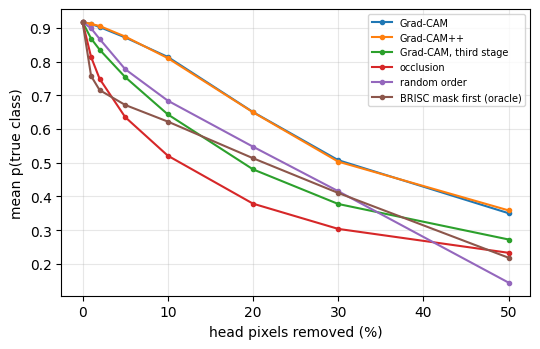

Removed pixels take the tissue mean, an input the network never saw in training; every order shares that bias, so the
differences between orders are what this test reads.

  37.2  H6 (descriptive): WHAT THE PLANE INPUT DOES  (every test image re-run with each of the two WRONG planes)

B_flip_film_w (round-1 network, FiLM on the shared feature (both heads)):
                                                        quantity   value             95% CI                per seed  images
share of images whose predicted class changes with a wrong plane  0.0040 [+0.0017, +0.0069] +0.0030 +0.0070 +0.0020    1000
                 mean |change in log p(true)| with a wrong plane  0.0181 [+0.0132, +0.0235] +0.0168 +0.0137 +0.0238    1000
          mean change in Dice with a wrong plane (tumour images) -0.0000 [-0.0001, +0.0000] -0.0000 -0.0000 +0.0000     860
     largest |change in Dice| with a wrong plane (tumour images)  0.0006 [+0.0005, +0.0007] +0.0004 +0.0005 +0.0008     860

B_flip_p1 (earlier 

In [73]:
# =============================================================================
#  CELL 37  |  Descriptive explanation analyses: H5 deletion faithfulness, H6 plane
#              swap on the FiLM networks, H7 Monte-Carlo dropout vs the 3-seed ensemble
# =============================================================================
assert "field_stats" in globals() and "H1_PASS" in globals() and "DEL_FRACS" in globals(), "Run Cells 1-36 first."

H5_ARM = "B_flip_w"
H6_ARMS = {"B_flip_film_w": "round-1 network, FiLM on the shared feature (both heads)",
           "B_flip_p1": "earlier design, plane MLP on the classifier only"}
H7_ARMS = ["B_flip_w", "B_flip_p1"]
DEL_ORDERS = {"gc": "Grad-CAM", "gcpp": "Grad-CAM++", "gc3": "Grad-CAM, third stage", "occ": "occlusion",
              "rand": "random order", "mask": "BRISC mask first (oracle)"}
checks, notes = {}, []
r3_clear(37)

# ----- 37.1 H5: deletion -------------------------------------------------------------------------------------------------------------
banner(f"37.1  H5 (descriptive): DELETION  ({H5_ARM}; head pixels removed in the order of each map; mean p(true class) over "
       f"{DEL_FRACS[0]:.0%}-{DEL_FRACS[-1]:.0%} removed: lower = the map ranks the decisive pixels first)")
H5 = {}
if "x_del_rand" in PI.columns and field_stats(H5_ARM, "x_del_rand", tum) is not None:
    curve_rows = []
    for o_, lab_ in DEL_ORDERS.items():
        cols_ = [f"x_delc_{o_}_{j}" for j in range(len(DEL_FRACS))]
        if not all(c_ in PI.columns for c_ in cols_):
            continue
        s_ = PI[(PI.arm == H5_ARM) & PI.has_mask][cols_].dropna()
        if len(s_):
            curve_rows.append({"order": lab_ + ("" if o_ in ("rand", "mask") else ("" if H1_PASS.get(o_) else " [failed H1]")),
                               **{f"{f_:.0%}": float(v_) for f_, v_ in zip(DEL_FRACS, s_.mean().to_numpy())}})
    if curve_rows:
        print("mean p(true class) after removing each share of the head's pixels (pooled over seeds and images):")
        print(pd.DataFrame(curve_rows).round(4).to_string(index=False))
    rows_ = []
    for o_, lab_ in DEL_ORDERS.items():
        st_ = field_stats(H5_ARM, f"x_del_{o_}", tum)
        if st_ is None:
            continue
        H5[o_] = st_; rows_.append((f"{lab_}: mean p(true) over the curve", st_, None))
        if o_ != "rand":
            d_ = diff_stats(H5_ARM, f"x_del_{o_}", H5_ARM, "x_del_rand", tum)
            if d_ is not None:
                flag = "" if o_ == "mask" or H1_PASS.get(o_) else " [failed H1]"
                rows_.append((f"{lab_} minus random order{flag}", d_, None)); H5[f"{o_}-rand"] = d_
                r3(37, "H5", f"deletion: {lab_} minus random order{flag} ({H5_ARM})", d_["value"], d_["lo"], d_["hi"], "descriptive",
                   d_["images"], fmt_seeds(d_["per_seed"]), "descriptive")
    show_stats(rows_)
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    for r_ in curve_rows:
        ax.plot([100 * f_ for f_ in DEL_FRACS], [r_[f"{f_:.0%}"] for f_ in DEL_FRACS], marker="o", ms=3, label=r_["order"])
    ax.set_xlabel("head pixels removed (%)"); ax.set_ylabel("mean p(true class)"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(WORK / "cell37_deletion.png", dpi=110, bbox_inches="tight"); plt.show()
    print("Removed pixels take the tissue mean, an input the network never saw in training; every order shares that bias, so the\n"
          "differences between orders are what this test reads.")
else:
    print(f"needs {H5_ARM} with its explanations (Cells 30 and 32)")

# ----- 37.2 H6: plane swap -----------------------------------------------------------------------------------------------------------
banner("37.2  H6 (descriptive): WHAT THE PLANE INPUT DOES  (every test image re-run with each of the two WRONG planes)")
H6 = {}
for arm, lab_ in H6_ARMS.items():
    rows_ = []
    for f_, what, m_ in (("x_ps_flip", "share of images whose predicted class changes with a wrong plane", None),
                         ("x_ps_dlp", "mean |change in log p(true)| with a wrong plane", None),
                         ("x_ps_ddice", "mean change in Dice with a wrong plane (tumour images)", tum),
                         ("x_ps_ddice_max", "largest |change in Dice| with a wrong plane (tumour images)", tum)):
        st_ = field_stats(arm, f_, m_)
        if st_ is not None:
            H6[f"{arm} | {f_}"] = st_; rows_.append((what, st_, None))
            r3(37, "H6", f"{arm}: {what}", st_["value"], st_["lo"], st_["hi"], "descriptive", st_["images"], fmt_seeds(st_["per_seed"]),
               "descriptive")
    show_stats(rows_, f"\n{arm} ({lab_}):") if rows_ else print(f"\n{arm}: not available (Cells 30 and 32)")
if "x_ps_ddice_max" in PI.columns:
    p1_dd = PI[(PI.arm == "B_flip_p1") & PI.has_mask].x_ps_ddice_max.dropna()
    if len(p1_dd):
        checks["earlier design: a wrong plane never changes the mask (its FiLM reaches the classifier only)"] = float(p1_dd.abs().max()) == 0.0

# ----- 37.3 H7: Monte-Carlo dropout vs the 3-seed ensemble -----------------------------------------------------------------------------
banner("37.3  H7 (descriptive): WHICH UNCERTAINTY FLAGS THE ERRORS?  AUROC for telling misclassified test images from correct ones "
       "(group-bootstrap 95% CI); Spearman between mask uncertainty and Dice")
def auroc_w(score, err, Wm):
    """Weighted AUROC (ties count one half) for every row of the weight matrix Wm (B x n): P(score of an error > score of a
    correct image). NaN scores are left out."""
    ok_ = np.isfinite(score) & np.isfinite(err)
    s_, e_, Wv = score[ok_], err[ok_].astype(bool), Wm[:, ok_]
    if e_.all() or (~e_).all():
        return np.full(len(Wm), np.nan)
    u_, inv = np.unique(s_, return_inverse=True); G_ = np.zeros((len(s_), len(u_)), np.float32); G_[np.arange(len(s_)), inv] = 1
    pos = (Wv * e_) @ G_; neg_w = (Wv * ~e_) @ G_
    below = np.cumsum(neg_w, 1) - neg_w
    num = (pos * (below + 0.5 * neg_w)).sum(1); den_ = pos.sum(1) * neg_w.sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den_ > 0, num / den_, np.nan)
def auc_row(name_, score, err):
    pt_ = auroc_w(score, err, W1)[0]; bt_ = auroc_w(score, err, W)
    lo, hi = np.nanpercentile(bt_, [2.5, 97.5])
    return {"score": name_, "AUROC": float(pt_), "95% CI": f"[{lo:.4f}, {hi:.4f}]", "errors": int(np.nansum(err)),
            "images": int(np.isfinite(score).sum()), "_v": (float(pt_), float(lo), float(hi))}
def stored_probs(tag):
    z_ = np.load(run_dir(tag) / "pred_test.npz"); P_ = np.full((n_test, NUM_CLASSES), np.nan); P_[[pos_of[int(r)] for r in z_["row"]]] = z_["prob"]
    Mk = np.zeros((n_test, SIZE, SIZE), bool); Mk[[pos_of[int(r)] for r in z_["row"]]] = np.unpackbits(z_["mask_bits"], axis=-1)[..., :SIZE].astype(bool)
    return P_, Mk
H7 = {}
ent_ = lambda P_: -(P_ * np.log(np.clip(P_, 1e-12, 1))).sum(1)
for arm in H7_ARMS:
    tags_ = [t_ for t_ in TAGS3 if G3[t_]["arm"] == arm]
    if not tags_ or "x_mc_ent" not in PI.columns or PI[PI.arm == arm].x_mc_ent.notna().sum() == 0:
        print(f"\n{arm}: not available (Cells 30 and 32)"); continue
    print(f"\n{arm}  ({len(tags_)} seeds; Monte-Carlo dropout with {MC_PASSES} passes per seed)")
    m_ = np.zeros(n_test, bool); m_[ALL_K] = True
    rows_ = []
    PS, MS = zip(*[stored_probs(t_) for t_ in tags_])
    for t_, P_ in zip(tags_, PS):
        sd_ = G3[t_]["seed"]; err_ = np.where(m_, (P_.argmax(1) != LAB_T).astype(float), np.nan)
        rows_.append(auc_row(f"seed {sd_}: 1 - max probability (one network)", np.where(m_, 1 - P_.max(1), np.nan), err_))
        q_ = PI[PI.tag == t_].set_index("row").reindex(TR)
        err_mc = np.where(m_ & q_.x_mc_pred.notna().to_numpy(), (q_.x_mc_pred.to_numpy() != LAB_T).astype(float), np.nan)
        rows_.append(auc_row(f"seed {sd_}: MC-dropout predictive entropy", q_.x_mc_ent.to_numpy(), err_mc))
        rows_.append(auc_row(f"seed {sd_}: MC-dropout mutual information", q_.x_mc_mi.to_numpy(), err_mc))
    if len(PS) > 1:
        Pm = np.mean(PS, 0); err_e = np.where(m_, (Pm.argmax(1) != LAB_T).astype(float), np.nan)
        rows_.append(auc_row(f"ensemble of {len(PS)} seeds: predictive entropy", np.where(m_, ent_(Pm), np.nan), err_e))
        rows_.append(auc_row(f"ensemble of {len(PS)} seeds: disagreement (mutual information)",
                             np.where(m_, ent_(Pm) - np.mean([ent_(P_) for P_ in PS], 0), np.nan), err_e))
    T7 = pd.DataFrame(rows_)
    print(T7.drop(columns=["_v"]).round(4).to_string(index=False))
    for r_ in rows_:
        r3(37, "H7", f"{arm}, {r_['score']}: AUROC for errors", *r_["_v"], "descriptive", r_["images"], status="descriptive")
    H7[arm] = T7.drop(columns=["_v"]).to_dict("records")
    # segmentation: does the uncertainty rank the bad masks?
    seg_rows = []
    for t_ in tags_:
        q_ = PI[(PI.tag == t_) & PI.has_mask & PI.x_mc_segsd.notna()]
        if len(q_) > 2:
            seg_rows.append({"seed": G3[t_]["seed"], "Spearman(MC mask SD, Dice of the MC mean mask)": rho(q_.x_mc_segsd, q_.x_mc_dice),
                             "images": len(q_)})
    if len(MS) > 1:
        dis_, dice_e = np.full(n_test, np.nan), np.full(n_test, np.nan)
        for k in TUM_K:
            ms_ = [M_[k] for M_ in MS]; pairs_ = [(a_, b_) for i_, a_ in enumerate(ms_) for b_ in ms_[i_ + 1:]]
            dis_[k] = 1 - np.mean([dice_of(a_, b_) for a_, b_ in pairs_]); dice_e[k] = dice_of(np.mean(ms_, 0) > 0.5, TM[k])
        ok_ = np.isfinite(dis_)
        if ok_.sum() > 2:
            seg_rows.append({"seed": f"ensemble ({len(MS)})", "Spearman(seed disagreement 1 - mean pairwise Dice, Dice of the majority mask)":
                             rho(dis_[ok_], dice_e[ok_]), "images": int(ok_.sum())})
    if seg_rows:
        print(pd.DataFrame(seg_rows).round(4).to_string(index=False))
        H7[f"{arm} | segmentation"] = seg_rows
print("\nA useful uncertainty ranks the errors first (AUROC > 0.5) and is high where the Dice is low (negative Spearman). The\n"
      "earlier design has no dropout on the path to its mask (Cell 29): its MC mask SD is 0 by construction.")

# ----- 37.4 save ---------------------------------------------------------------------------------------------------------------------
banner("37.4  SAVE")
save_json(WORK / "cell37_summary.json", {"H5": H5, "H6": H6, "H7": H7, "mc_passes": MC_PASSES, "deletion_fracs": list(DEL_FRACS)})
print("saved cell37_summary.json, cell37_deletion.png")
finish(37, checks, notes)

## Cell 38 | Round 3: the results table

**Purpose.** Print every round-3 quantity computed by Cells 31-37 in one table (pre-specified endpoints first, then negative controls and descriptive rows): estimate, 95% group-bootstrap interval, verdict by the fixed rule, number of images, per-seed values, and the cell it comes from; the run record (round-3 runs, replicate fidelity, explanation passes) and the environment. Nothing is typed by hand.

**Inputs.** `R3ROWS` (Cells 31-37), `R3_STATUS`, `REPRO3` (Cell 30), `S32` (Cell 32). **Outputs.** `paper_results_round3.csv/json` (copied to `MyDrive/brisc_round3` with the cell summaries).

**Pass criteria.** Every pre-specified row carries a verdict; no smoke-test numbers (in SMOKE mode this check fails on purpose). Rows that need runs not yet finished are missing, and the cell says so.


In [74]:
# =============================================================================
#  CELL 38  |  Round 3: the results table (the only source of round-3 numbers),
#              the run record, and the save
# =============================================================================
assert "R3ROWS" in globals() and "R3_STATUS" in globals(), "Run Cells 1-37 first."

GROUP_ORDER = ["Q6", "Q7", "H1", "H2", "H3", "H4", "R", "H1-d", "D-array", "H2-d", "H3-d", "D-scramble", "H4-d", "H5", "H6", "H7"]
checks, notes = {}, []

# ----- 38.1 the table ------------------------------------------------------------------------------------------------------------
banner("38.1  ROUND-3 RESULTS  (pre-specified rows first; every number below was computed in Cells 31-37 of this run)")
R3T = pd.DataFrame(list(R3ROWS.values()))
if len(R3T):
    R3T["order"] = R3T.group.map({g_: i for i, g_ in enumerate(GROUP_ORDER)}).fillna(len(GROUP_ORDER))
    R3T = R3T.sort_values(["order", "cell"], kind="stable").drop(columns="order").reset_index(drop=True)
    R3T["95% CI"] = [None if pd.isna(lo) else f"[{lo:+.4f}, {hi:+.4f}]" for lo, hi in zip(R3T.lo, R3T.hi)]
    show_ = R3T[["group", "quantity", "estimate", "95% CI", "verdict", "images", "per_seed", "status", "cell"]].copy()
    show_["estimate"] = show_.estimate.round(4)
    with pd.option_context("display.max_rows", 2000, "display.max_colwidth", 110, "display.width", 300):
        print(show_.fillna("").to_string(index=False))
    pre = R3T[R3T.status == "pre-specified"]
    print(f"\n{len(R3T)} rows: {len(pre)} pre-specified endpoints, {int((R3T.status == 'negative control').sum())} negative controls, "
          f"{int((R3T.status == 'descriptive').sum())} descriptive")
    print("\npre-specified endpoints by verdict:"); print(pre.groupby(["group", "verdict"]).size().rename("rows").to_string())
else:
    print("no round-3 result yet (Cells 30-37)")

# ----- 38.2 the run record --------------------------------------------------------------------------------------------------------
banner("38.2  THE RUN RECORD  (round-3 runs, replicate fidelity, explanation passes)")
with pd.option_context("display.max_rows", 200, "display.width", 220):
    print(R3_STATUS[["tag", "priority", "kind", "task", "done", "best_epoch", "minutes", "gpu", "sig_ok", "checkpoint"]].to_string(index=False))
    if len(REPRO3):
        print("\nreplicates vs round 1 (Cell 30.6):"); print(REPRO3.round(6).to_string(index=False))
    if "S32" in globals() and len(S32):
        print("\nexplanation passes (Cell 32):"); print(S32.to_string(index=False))
env3 = {"gpu": torch.cuda.get_device_name(0) if DEV == "cuda" else "cpu", "torch": torch.__version__, "data_fingerprint": DATA_FP,
        "split": SPLIT_SIG, "seeds": list(SEEDS), "max_priority3": MAX_PRIORITY3, "xai_settings": XAI_SET if "XAI_SET" in globals() else None}
print("\n" + json.dumps(env3, indent=1, default=str))

# ----- 38.3 save -----------------------------------------------------------------------------------------------------------------
banner("38.3  SAVE")
name38 = "paper_results_round3" if not SMOKE else "SMOKE_TEST_round3"
if len(R3T):
    R3T.to_csv(WORK / f"{name38}.csv", index=False)
save_json(WORK / f"{name38}.json", {"rows": list(R3ROWS.values()), "environment": env3,
                                    "runs": R3_STATUS.to_dict("records"), "replicates": REPRO3.to_dict("records") if len(REPRO3) else []})
saved = [f"{name38}.csv", f"{name38}.json"] + sorted(p_.name for p_ in WORK.glob("cell3[1-8]_*"))
if DRIVE_RUNS is not None:
    try:
        dst_ = DRIVE_RUNS.parent / "brisc_round3"; dst_.mkdir(exist_ok=True)
        for n_ in saved:
            if (WORK / n_).exists():
                shutil.copy2(WORK / n_, dst_ / n_)
        print(f"copied {len(saved)} files to {dst_}")
    except OSError as e:
        print(f"Drive copy failed ({e})")
print("saved: " + ", ".join(n_ for n_ in saved if (WORK / n_).exists()))
checks["no smoke-test numbers in the round-3 results"] = not SMOKE
checks["every pre-specified row carries a verdict"] = bool(len(R3T) == 0 or R3T[R3T.status == "pre-specified"].verdict.astype(str).str.len().gt(0).all())
left38 = [g["tag"] for g in GRID3 if g["priority"] <= MAX_PRIORITY3 and not is_done(g["tag"])]
if left38:
    notes.append(f"{len(left38)} round-3 runs in scope are not finished: the rows that need them are missing (Cell 30).")
if SMOKE:
    notes.append("SMOKE TEST: synthetic data; nothing in this table is a result.")
print("\nSend back this notebook with its outputs (File > Download > .ipynb): every number above is printed in it.")
finish(38, checks, notes)


  38.1  ROUND-3 RESULTS  (pre-specified rows first; every number below was computed in Cells 31-37 of this run)
     group                                                                                      quantity  estimate             95% CI          verdict  images                per_seed           status  cell
        Q6                                                           EfficientNet-B0: Full - B, macro_f1    0.0900 [+0.0715, +0.1108]        supported  1000.0 +0.0730 +0.1007 +0.0963    pre-specified    31
        Q6                                                           EfficientNet-B0: Full - B, accuracy    0.0917 [+0.0721, +0.1124]      descriptive  1000.0 +0.0760 +0.1020 +0.0970      descriptive    31
        Q6                                                       EfficientNet-B0: Full - B, balanced_acc    0.0770 [+0.0608, +0.0942]      descriptive  1000.0 +0.0625 +0.0862 +0.0822      descriptive    31
        Q6                                                     